In [ ]:
from collections import defaultdict
import random
from argparse import Namespace
from functools import partial
from multiprocessing import Pool
from pathlib import Path
from typing import Union

import json
import cv2
import numpy as np
import kornia
import torch
import matplotlib
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image
from tqdm.auto import tqdm
import pandas as pd
from SoccerNet.Evaluation.utils_calibration import SoccerPitch


from tvcalib.cam_modules import SNProjectiveCamera
from tvcalib.module import TVCalibModule
from tvcalib.cam_distr.tv_main_center import get_cam_distr, get_dist_distr
from sn_segmentation.src.custom_extremities import generate_class_synthesis, get_line_extremities
from tvcalib.sncalib_dataset import custom_list_collate, split_circle_central
from tvcalib.utils.io import detach_dict, tensor2list
from tvcalib.utils.objects_3d import SoccerPitchLineCircleSegments, SoccerPitchSNCircleCentralSplit
from tvcalib.inference import InferenceDatasetCalibration, InferenceDatasetSegmentation, InferenceSegmentationModel
from tvcalib.inference import get_camera_from_per_sample_output
from tvcalib.utils import visualization_mpl_min as viz


args = Namespace(
        images_path=Path("data/soccernet"),
        output_dir=Path("tmp"),
        checkpoint="data/segment_localization/train_59.pt",
        gpu=True,
        nworkers=8,
        batch_size_seg=8,
        batch_size_calib=256,
        image_width=1920,
        image_height=1080,
        optim_steps=2000,
        lens_dist=False,
        write_masks=False
    )
device = "cuda" if args.gpu and torch.cuda.is_available() else "cpu"

object3d = SoccerPitchLineCircleSegments(
    device=device, base_field=SoccerPitchSNCircleCentralSplit()
)
object3dcpu = SoccerPitchLineCircleSegments(
    device="cpu", base_field=SoccerPitchSNCircleCentralSplit()
)

lines_palette = [0, 0, 0]
for line_class in SoccerPitch.lines_classes:
    lines_palette.extend(SoccerPitch.palette[line_class])

fn_generate_class_synthesis = partial(generate_class_synthesis, radius=4)
fn_get_line_extremities = partial(get_line_extremities, maxdist=30, width=455, height=256, num_points_lines=4, num_points_circles=8)

In [ ]:
dataset_seg = InferenceDatasetSegmentation(
    args.images_path, args.image_width, args.image_height
)
print("number of images:", len(dataset_seg))
dataloader_seg = torch.utils.data.DataLoader(
    dataset_seg,
    batch_size=args.batch_size_seg,
    num_workers=args.nworkers,
    shuffle=False,
    collate_fn=custom_list_collate,
)

model_seg = InferenceSegmentationModel(args.checkpoint, device)

image_ids = []
keypoints_raw = []
(args.output_dir / "masks").mkdir(parents=True, exist_ok=True)
for batch_dict in tqdm(dataloader_seg):
    # semantic segmentation
    # image_raw: [B, 3, image_height, image_width]
    # image: [B, 3, 256, 455]
    with torch.no_grad():
        sem_lines = model_seg.inference(batch_dict["image"].to(device))
    sem_lines = sem_lines.cpu().numpy().astype(np.uint8)  # [B, 256, 455]

    # point selection
    with Pool(args.nworkers) as p:
        skeletons_batch = p.map(fn_generate_class_synthesis, sem_lines)
        keypoints_raw_batch = p.map(fn_get_line_extremities, skeletons_batch)

    # write to file
    if args.write_masks:
        print("Write masks to file")
        for image_id, mask in zip(batch_dict["image_id"], sem_lines):
            mask = Image.fromarray(mask.astype(np.uint8)).convert("P")
            mask.putpalette(lines_palette)
            mask.convert("RGB").save(args.output_dir / "masks" / image_id)

    image_ids.extend(batch_dict["image_id"])
    keypoints_raw.extend(keypoints_raw_batch)


In [ ]:
model_calib = TVCalibModule(
    object3d,
    get_cam_distr(1.96, args.batch_size_calib, 1),
    get_dist_distr(args.batch_size_calib, 1) if args.lens_dist else None,
    (args.image_height, args.image_width),
    args.optim_steps,
    device,
    log_per_step=False,
    tqdm_kwqargs=None,
)

dataset_calib = InferenceDatasetCalibration(keypoints_raw, args.image_width, args.image_height, object3d)
dataloader_calib = torch.utils.data.DataLoader(dataset_calib, args.batch_size_calib, collate_fn=custom_list_collate)

per_sample_output = defaultdict(list)
per_sample_output["image_id"] = [[x] for x in image_ids]
for x_dict in dataloader_calib:
    _batch_size = x_dict["lines__ndc_projected_selection_shuffled"].shape[0]

    points_line = x_dict["lines__px_projected_selection_shuffled"]
    points_circle = x_dict["circles__px_projected_selection_shuffled"]
    print(f"{points_line.shape=}, {points_circle.shape=}")

    per_sample_loss, cam, _ = model_calib.self_optim_batch(x_dict)
    output_dict = tensor2list(detach_dict({**cam.get_parameters(_batch_size), **per_sample_loss}))
    
    output_dict["points_line"] = points_line
    output_dict["points_circle"] =  points_circle
    for k in output_dict.keys():
        per_sample_output[k].extend(output_dict[k])

df = pd.DataFrame.from_dict(per_sample_output)
df = df.explode(column=[k for k, v in per_sample_output.items() if isinstance(v, list)])
df.set_index("image_id", inplace=True, drop=False)

dict_per_frame = [
    {key: value[0] for key, value in zip(per_sample_output.keys(), values)}
    for values in zip(*per_sample_output.values())
]

for image_dict in dict_per_frame:
    keys_to_delete = [key for key, value in image_dict.items() if isinstance(value, torch.Tensor)]
    for key in keys_to_delete:
        del image_dict[key]

output_dict = {
    dic["image_id"]: {k: v for k, v in dic.items() if k != "image_id"}
    for dic in dict_per_frame
}

with open('tmp/output/metadata.json', 'w') as json_file:
    json.dump(output_dict, json_file, indent=4, sort_keys=True)

## La siguiente celda intenta superponer una imagen.
Lo más probable es que el error esté en la matriz de homografía.

Iteration:   0%|          | 0/450 [00:00<?, ?it/s]

Normalized Homography matrix for frame 92:
[[ 9.9913366e-02  5.6426901e-02 -2.5807413e+01]
 [ 2.4945883e-02  3.7623495e-01 -3.3080228e+02]
 [ 1.7032963e-04  6.8862960e-03  1.0000000e+00]]


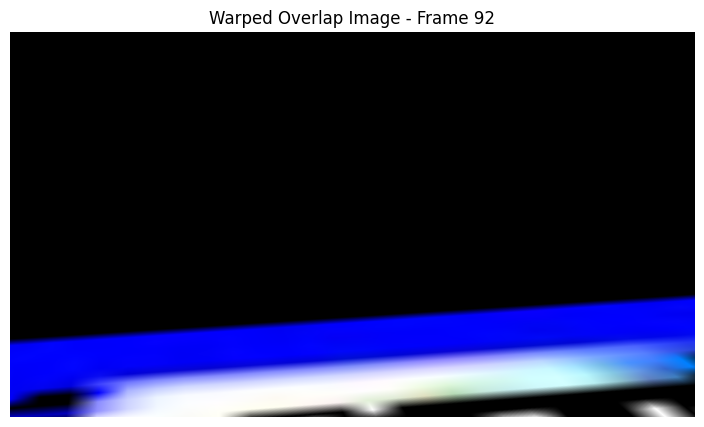

Iteration:   0%|          | 1/450 [00:00<01:19,  5.67it/s]

Normalized Homography matrix for frame 109:
[[ 1.2028625e-01  2.2265656e-02  4.7449337e+01]
 [ 3.8528923e-02  5.4613626e-01 -4.9554935e+02]
 [ 1.0463246e-05  1.0983277e-02  1.0000000e+00]]


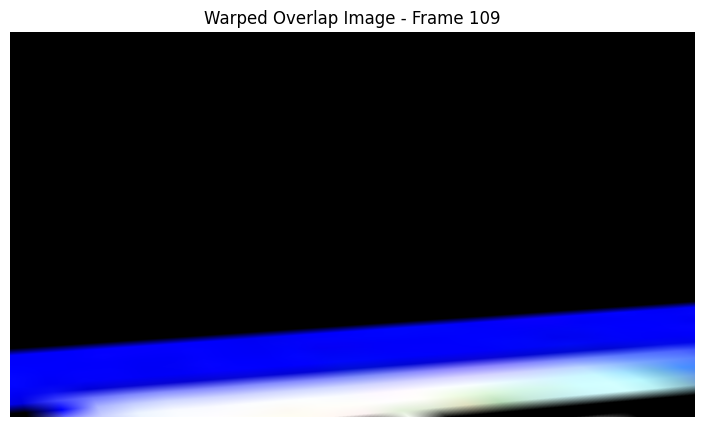

Iteration:   0%|          | 2/450 [00:00<01:19,  5.64it/s]

Normalized Homography matrix for frame 98:
[[ 9.4484232e-02  3.8833499e-02 -6.2022757e-02]
 [ 2.6251787e-02  3.8163733e-01 -3.3965610e+02]
 [ 9.6083815e-05  7.2730221e-03  1.0000000e+00]]


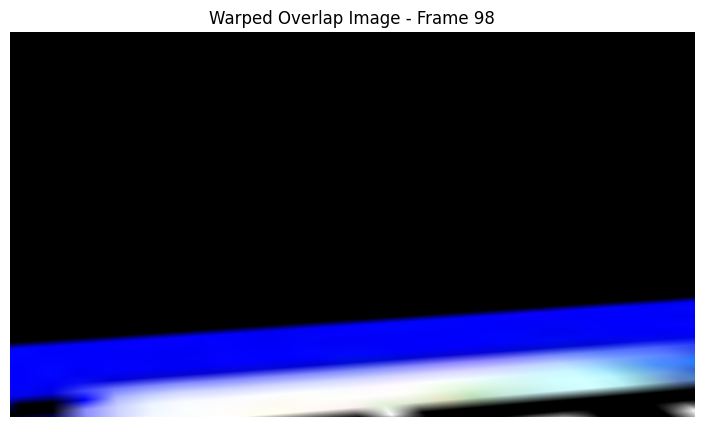

Iteration:   1%|          | 3/450 [00:00<01:18,  5.67it/s]

Normalized Homography matrix for frame 295:
[[ 3.6626246e-02  6.4759892e-03  9.1645233e+01]
 [ 2.5744103e-02  2.0473303e-01 -1.4028552e+02]
 [-3.0859610e-05  3.7919343e-03  1.0000000e+00]]


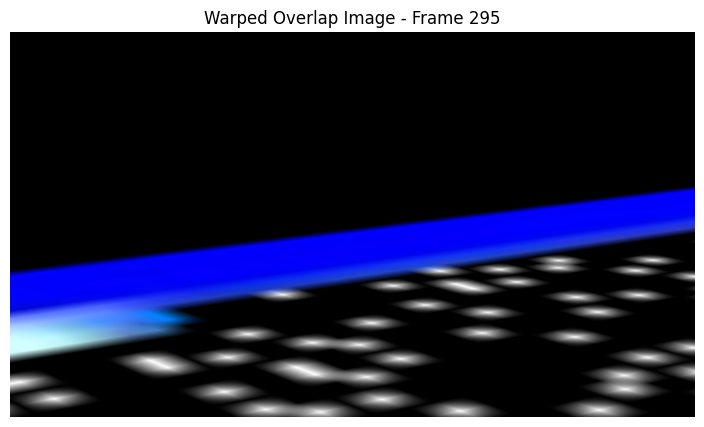

Iteration:   1%|          | 4/450 [00:00<01:20,  5.51it/s]

Normalized Homography matrix for frame 57:
[[ 1.0870103e-01 -1.7292642e-03 -1.5310305e+01]
 [ 2.2683639e-02  4.8073721e-01 -3.7151630e+02]
 [-3.2348002e-05  9.3622729e-03  1.0000000e+00]]


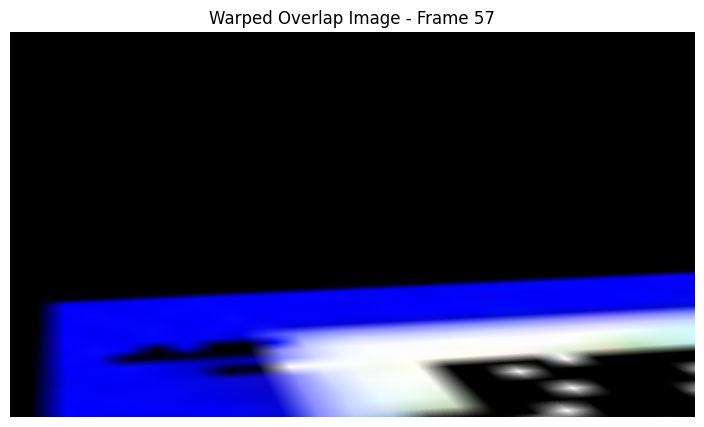

Iteration:   1%|          | 5/450 [00:00<01:19,  5.57it/s]

Normalized Homography matrix for frame 332:
[[ 5.4204646e-02  1.0640219e-02  8.8493843e+01]
 [ 3.4586281e-02  2.8245506e-01 -1.9268231e+02]
 [-2.3145381e-05  5.4183644e-03  1.0000000e+00]]


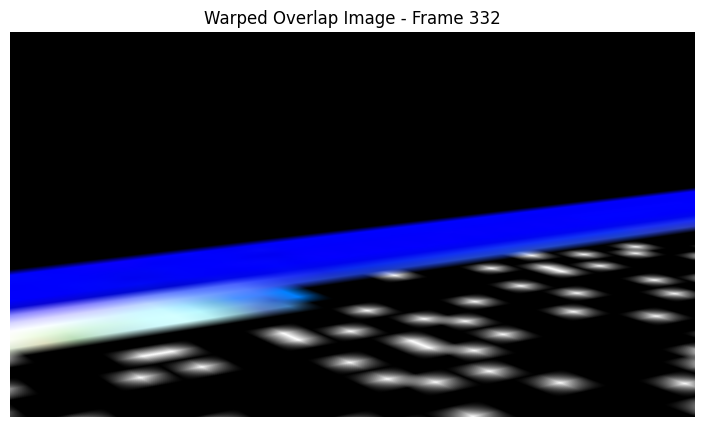

Iteration:   1%|▏         | 6/450 [00:01<01:19,  5.56it/s]

Normalized Homography matrix for frame 6:
[[-7.7039981e+00 -1.0349590e-01  6.0542827e+03]
 [-4.6246114e-01 -3.3815945e+01  2.3901635e+04]
 [-4.2061397e-04 -6.4226061e-01  1.0000000e+00]]


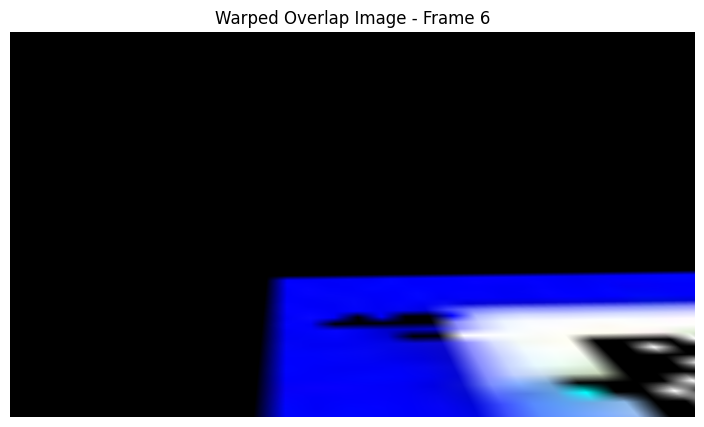

Iteration:   2%|▏         | 7/450 [00:01<01:19,  5.59it/s]

Normalized Homography matrix for frame 342:
[[ 5.0668437e-02  9.0857120e-03  8.5739769e+01]
 [ 3.1313442e-02  2.7178130e-01 -1.8236029e+02]
 [-2.8605762e-05  5.0041736e-03  1.0000000e+00]]


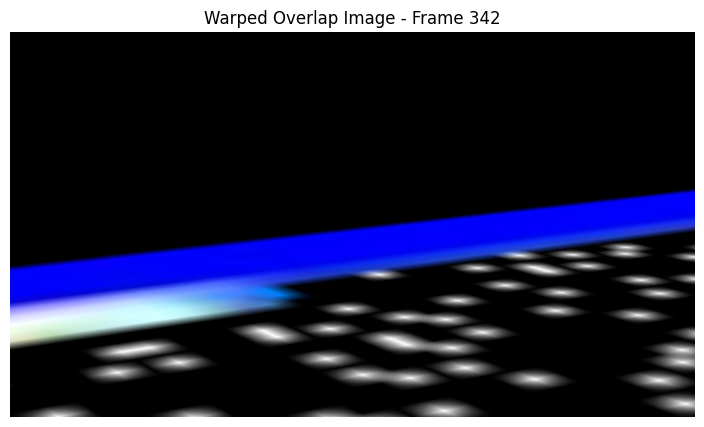

Iteration:   2%|▏         | 8/450 [00:01<01:19,  5.57it/s]

Normalized Homography matrix for frame 223:
[[ 8.7917589e-02  1.3999635e-02  1.6881316e+02]
 [ 5.6299593e-02  4.6542433e-01 -3.7279160e+02]
 [-8.1626291e-05  8.8816928e-03  1.0000000e+00]]


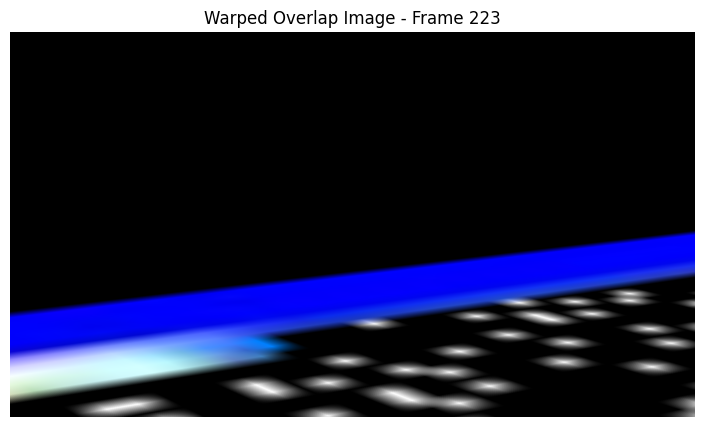

Iteration:   2%|▏         | 9/450 [00:01<01:19,  5.58it/s]

Normalized Homography matrix for frame 187:
[[ 9.5489621e-02  2.6234161e-02  1.2479470e+02]
 [ 4.6407193e-02  4.7641429e-01 -4.1774667e+02]
 [-4.1260417e-05  9.3695559e-03  1.0000000e+00]]


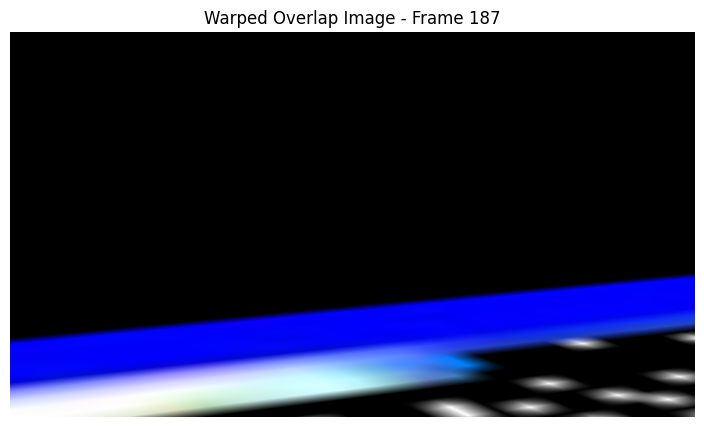

Iteration:   2%|▏         | 10/450 [00:01<01:18,  5.59it/s]

Normalized Homography matrix for frame 215:
[[ 1.0033053e-01  2.0900834e-02  1.7898129e+02]
 [ 6.2704295e-02  5.2322602e-01 -4.2606778e+02]
 [-7.5551274e-05  1.0172412e-02  1.0000000e+00]]


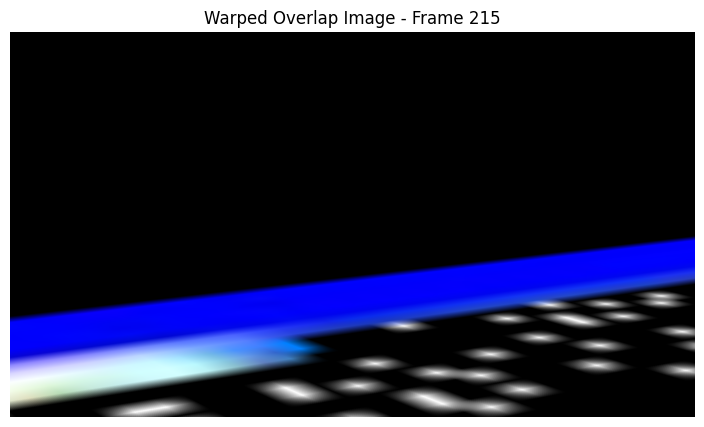

Iteration:   2%|▏         | 11/450 [00:01<01:18,  5.57it/s]

Normalized Homography matrix for frame 25:
[[ 2.7875990e-01  1.4132321e-03 -1.5191057e+02]
 [ 3.4578640e-02  1.2017474e+00 -8.7487366e+02]
 [-3.1916028e-05  2.3312367e-02  1.0000000e+00]]


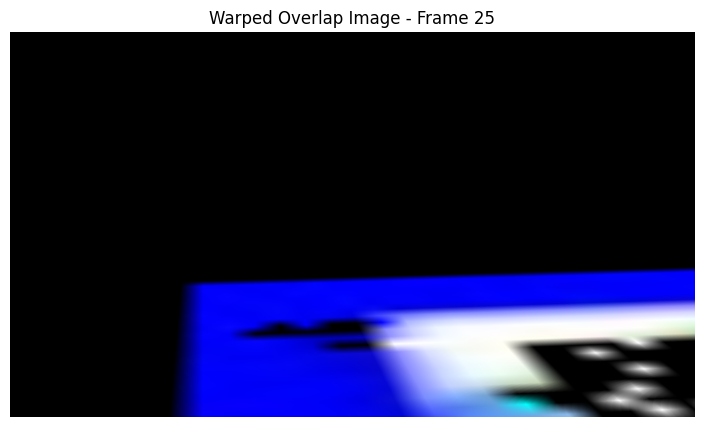

Iteration:   3%|▎         | 12/450 [00:02<01:18,  5.60it/s]

Normalized Homography matrix for frame 164:
[[ 5.7354301e-02 -1.0292406e-02  5.2854012e+01]
 [ 2.3315404e-02  2.5318801e-01 -2.3319473e+02]
 [ 7.0106887e-07  4.1355807e-03  1.0000000e+00]]


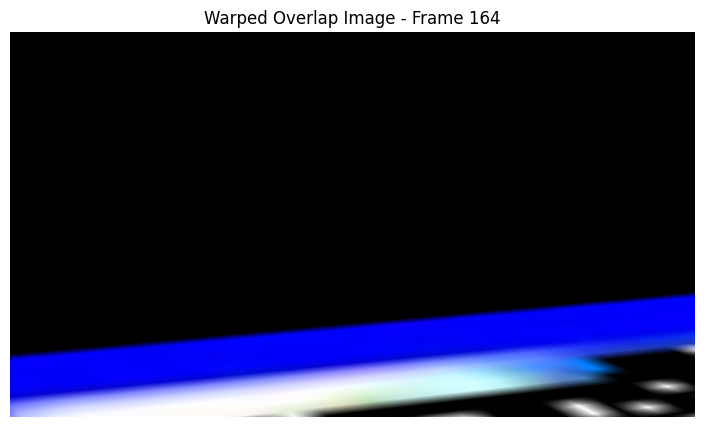

Iteration:   3%|▎         | 13/450 [00:02<01:26,  5.04it/s]

Normalized Homography matrix for frame 211:
[[ 1.0823039e-01  1.9086860e-02  1.8734935e+02]
 [ 6.7343801e-02  5.5903959e-01 -4.6172061e+02]
 [-6.3834894e-05  1.0904844e-02  1.0000000e+00]]


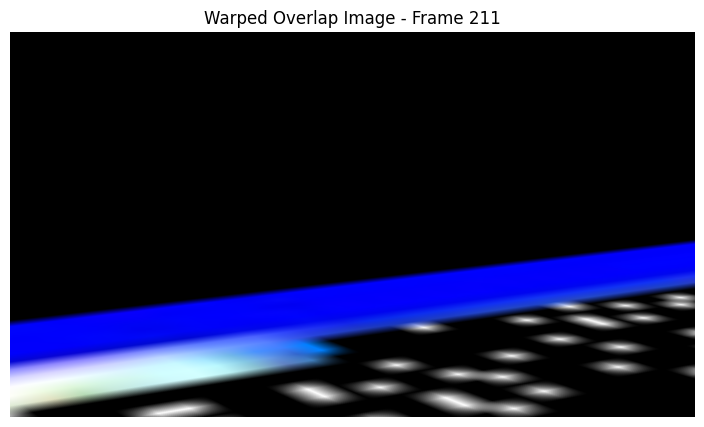

Iteration:   3%|▎         | 14/450 [00:02<01:24,  5.18it/s]

Normalized Homography matrix for frame 315:
[[ 4.9175043e-02  6.2441207e-03  8.8027260e+01]
 [ 3.0196665e-02  2.6648134e-01 -1.7948511e+02]
 [-4.7491812e-05  4.9245241e-03  1.0000000e+00]]


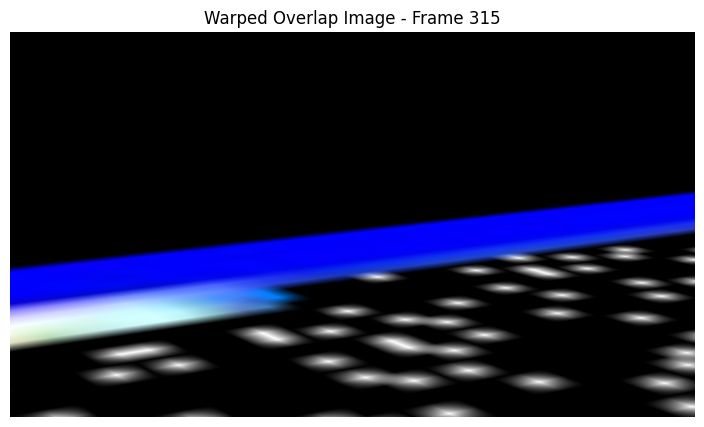

Iteration:   3%|▎         | 15/450 [00:02<01:22,  5.26it/s]

Normalized Homography matrix for frame 1:
[[-4.4710928e-01 -6.5881792e-03  3.8145209e+02]
 [-2.3855619e-02 -2.0074584e+00  1.4089009e+03]
 [-1.5408266e-04 -3.7765231e-02  1.0000000e+00]]


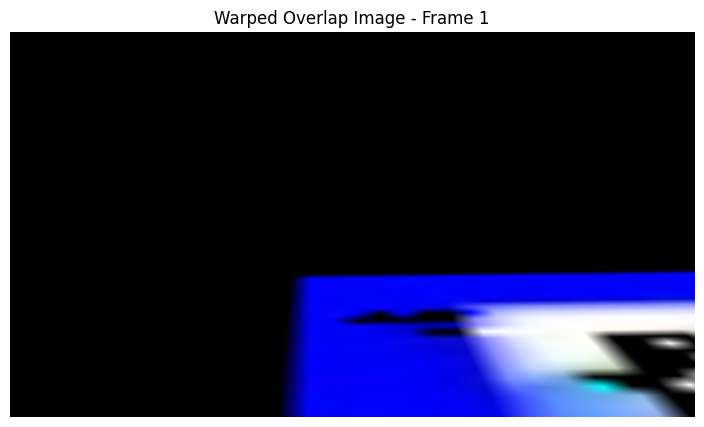

Iteration:   4%|▎         | 16/450 [00:02<01:20,  5.40it/s]

Normalized Homography matrix for frame 216:
[[ 1.1907411e-01  3.9344154e-02  2.0766173e+02]
 [ 7.3646218e-02  6.3750011e-01 -5.1237567e+02]
 [-8.8538327e-05  1.2492680e-02  1.0000000e+00]]


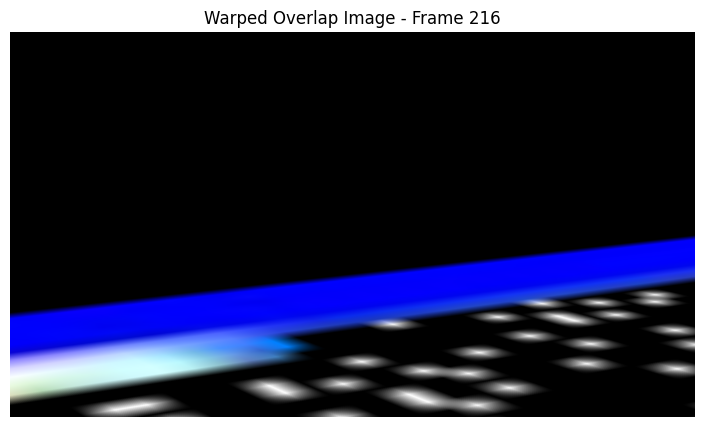

Iteration:   4%|▍         | 17/450 [00:03<01:19,  5.47it/s]

Normalized Homography matrix for frame 135:
[[-1.5309173e+00 -1.0948801e+00  6.5102863e+02]
 [-2.9234290e-01 -6.7286134e+00  5.3649004e+03]
 [-8.2188321e-04 -1.1596586e-01  1.0000000e+00]]


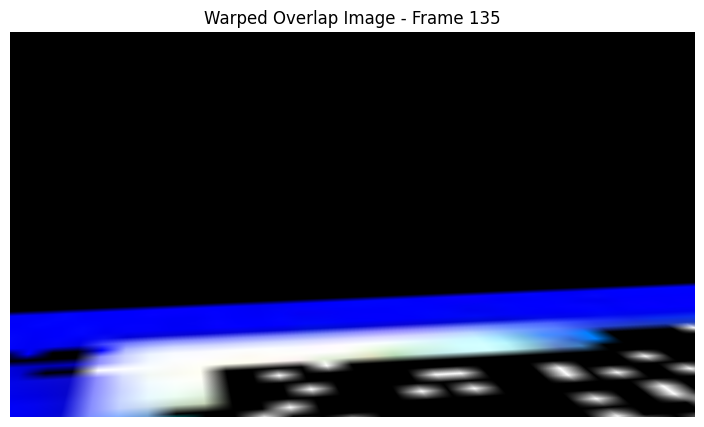

Iteration:   4%|▍         | 18/450 [00:03<01:18,  5.50it/s]

Normalized Homography matrix for frame 22:
[[ 2.7342126e-01  4.6645486e-04 -1.5599039e+02]
 [ 3.3980995e-02  1.1923909e+00 -8.7025659e+02]
 [ 2.6344665e-05  2.2687163e-02  1.0000000e+00]]


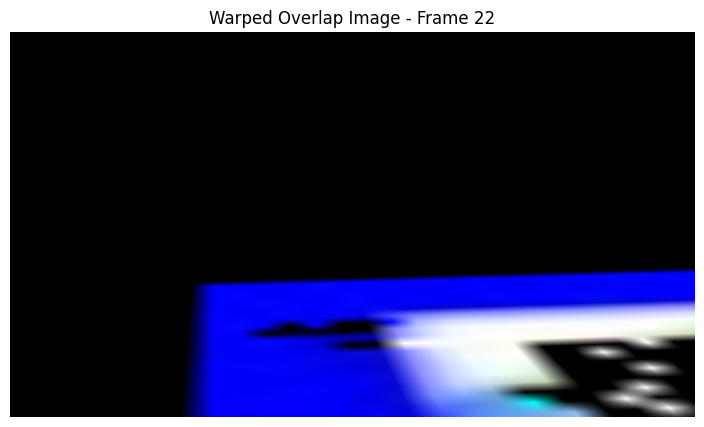

Iteration:   4%|▍         | 19/450 [00:03<01:17,  5.59it/s]

Normalized Homography matrix for frame 358:
[[ 4.9363751e-02  9.6171368e-03  8.8916023e+01]
 [ 3.1511817e-02  2.6845104e-01 -1.7845964e+02]
 [-3.4956473e-05  5.0393147e-03  1.0000000e+00]]


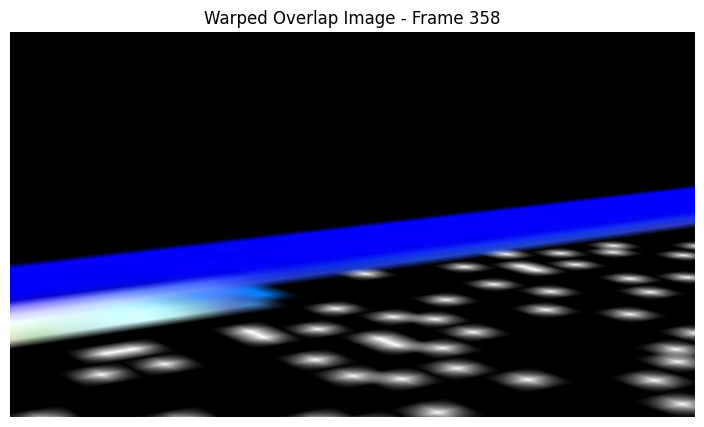

Iteration:   4%|▍         | 20/450 [00:03<01:16,  5.59it/s]

Normalized Homography matrix for frame 104:
[[ 8.8653393e-02  2.7133323e-02  1.6545330e+01]
 [ 2.6546024e-02  3.7543038e-01 -3.3899506e+02]
 [ 6.3139894e-05  7.0936009e-03  1.0000000e+00]]


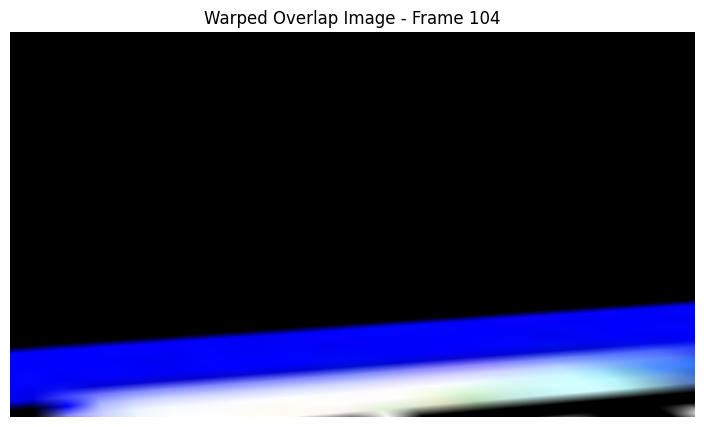

Iteration:   5%|▍         | 21/450 [00:03<01:16,  5.62it/s]

Normalized Homography matrix for frame 14:
[[ 1.2325757e+00  2.1011617e-02 -8.4630676e+02]
 [ 1.0293642e-01  5.2107840e+00 -3.7290681e+03]
 [-2.0784790e-04  1.0204225e-01  1.0000000e+00]]


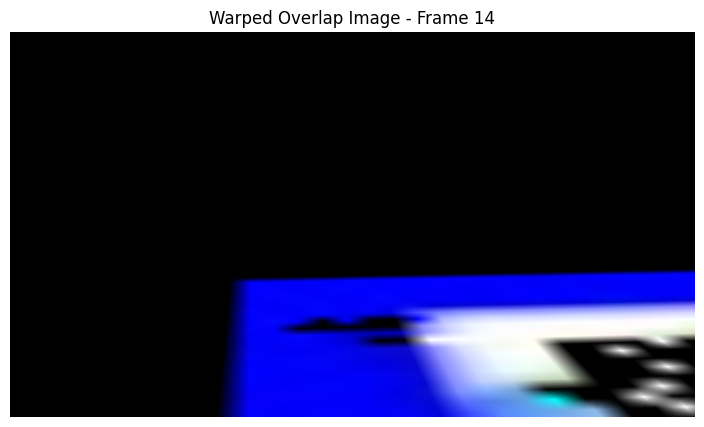

Iteration:   5%|▍         | 22/450 [00:03<01:16,  5.63it/s]

Normalized Homography matrix for frame 221:
[[ 1.1681794e-01  5.3874258e-02  1.9654700e+02]
 [ 6.8823770e-02  6.2871689e-01 -4.9534625e+02]
 [-1.3525104e-04  1.2215989e-02  1.0000000e+00]]


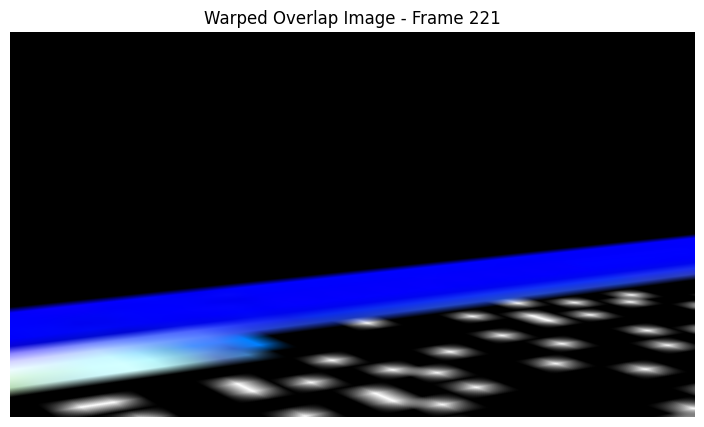

Iteration:   5%|▌         | 23/450 [00:04<01:16,  5.61it/s]

Normalized Homography matrix for frame 77:
[[ 8.9509189e-02  3.8352214e-02 -2.7226585e+01]
 [ 1.8986139e-02  3.5010210e-01 -2.9486734e+02]
 [ 9.9747871e-05  6.2395786e-03  1.0000000e+00]]


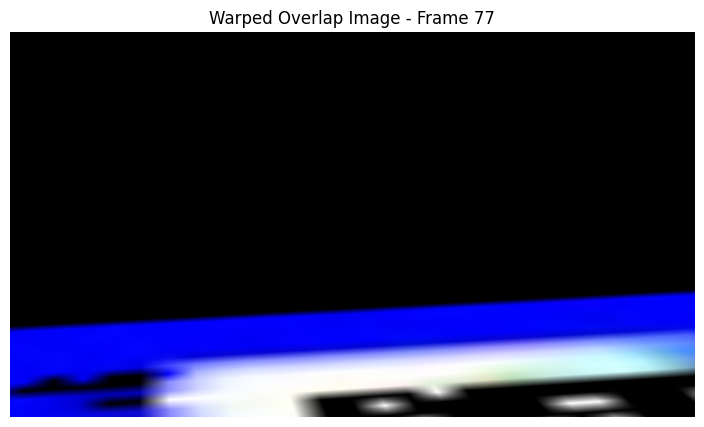

Iteration:   5%|▌         | 24/450 [00:04<01:15,  5.65it/s]

Normalized Homography matrix for frame 266:
[[ 4.5179971e-02  8.3855614e-03  1.2159929e+02]
 [ 3.2882489e-02  2.5805429e-01 -1.8853268e+02]
 [-5.0989009e-05  4.7885049e-03  1.0000000e+00]]


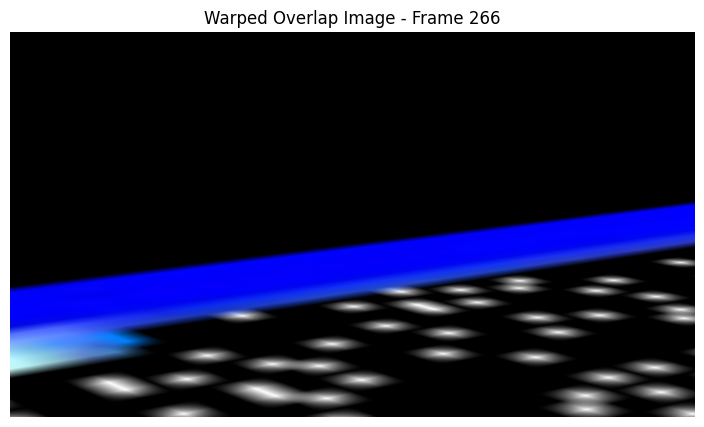

Iteration:   6%|▌         | 25/450 [00:04<01:15,  5.60it/s]

Normalized Homography matrix for frame 19:
[[ 3.41631144e-01 -5.70773892e-03 -2.01400040e+02]
 [ 3.94759513e-02  1.51314199e+00 -1.09642822e+03]
 [ 1.01588475e-05  2.88816281e-02  1.00000000e+00]]


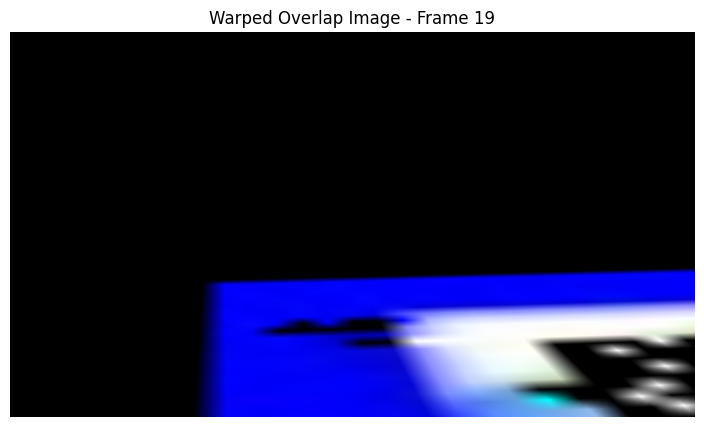

Iteration:   6%|▌         | 26/450 [00:04<01:15,  5.63it/s]

Normalized Homography matrix for frame 84:
[[ 1.2024790e-01  7.4507743e-02 -4.4788200e+01]
 [ 2.7204385e-02  4.4162187e-01 -3.8334879e+02]
 [ 2.0903656e-04  8.6015631e-03  1.0000000e+00]]


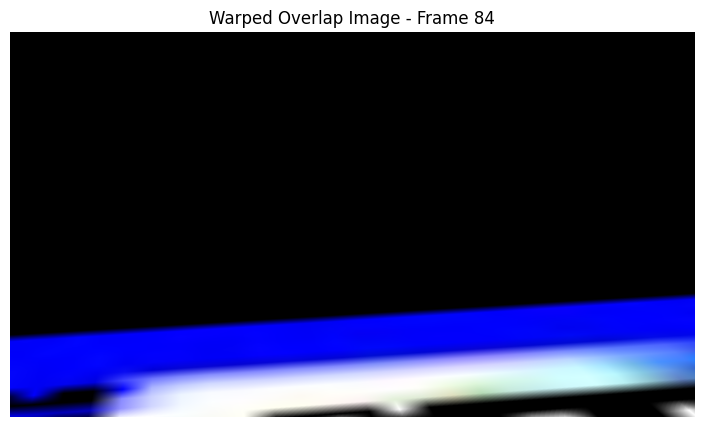

Iteration:   6%|▌         | 27/450 [00:04<01:15,  5.64it/s]

Normalized Homography matrix for frame 435:
[[ 4.3593902e-02  4.5791743e-03  8.4581871e+01]
 [ 2.8974514e-02  2.3614225e-01 -1.5570547e+02]
 [-2.8743143e-05  4.4235345e-03  1.0000000e+00]]


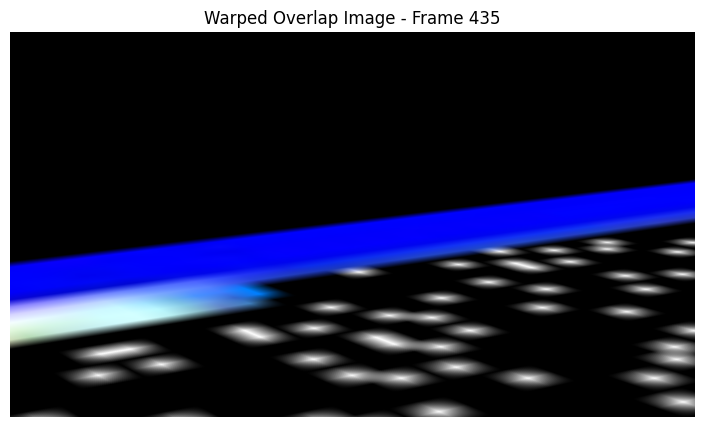

Iteration:   6%|▌         | 28/450 [00:05<01:15,  5.57it/s]

Normalized Homography matrix for frame 370:
[[ 4.6395835e-02  6.1628353e-03  8.6489510e+01]
 [ 3.0231360e-02  2.4918704e-01 -1.6623842e+02]
 [-3.3490734e-05  4.6798154e-03  1.0000000e+00]]


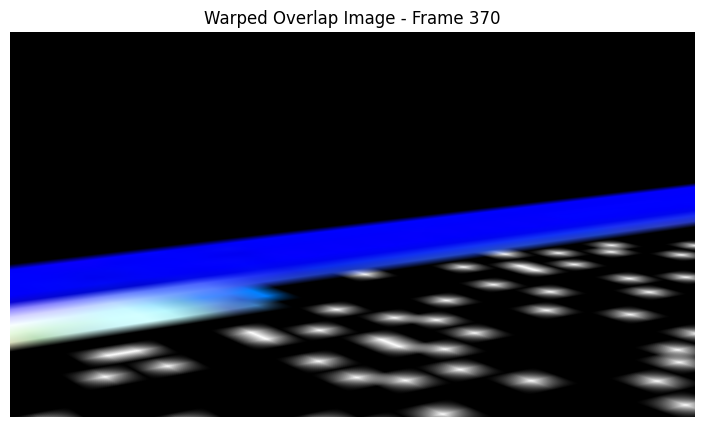

Iteration:   6%|▋         | 29/450 [00:05<01:15,  5.56it/s]

Normalized Homography matrix for frame 377:
[[ 4.6280142e-02  6.4388779e-03  8.7553253e+01]
 [ 3.0687509e-02  2.4972089e-01 -1.6719724e+02]
 [-2.3970022e-05  4.6969424e-03  1.0000000e+00]]


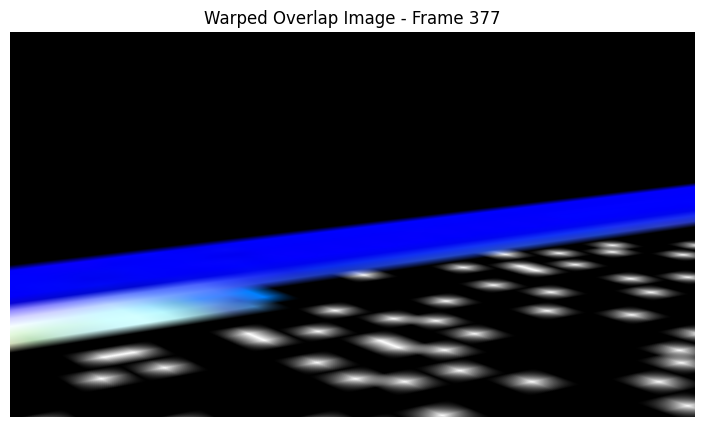

Iteration:   7%|▋         | 30/450 [00:05<01:15,  5.53it/s]

Normalized Homography matrix for frame 192:
[[ 1.05378993e-01  3.44437733e-02  1.43103607e+02]
 [ 5.43004237e-02  5.18937647e-01 -4.50219971e+02]
 [-6.36409895e-05  1.05314255e-02  1.00000000e+00]]


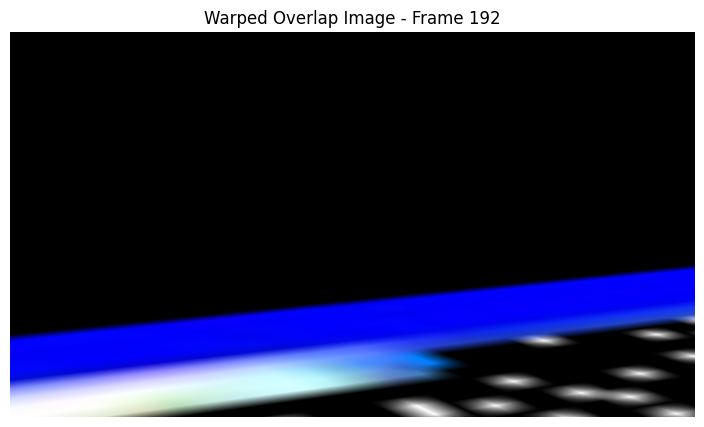

Iteration:   7%|▋         | 31/450 [00:05<01:15,  5.58it/s]

Normalized Homography matrix for frame 418:
[[ 4.5652688e-02  6.8878308e-03  8.7482658e+01]
 [ 3.0369552e-02  2.4611297e-01 -1.6355608e+02]
 [-3.4079570e-05  4.6927631e-03  1.0000000e+00]]


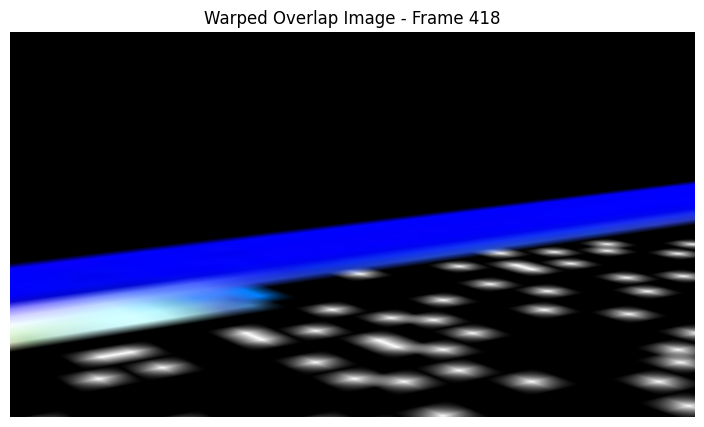

Iteration:   7%|▋         | 32/450 [00:05<01:15,  5.56it/s]

Normalized Homography matrix for frame 428:
[[ 4.2840708e-02  2.6242465e-03  8.3988205e+01]
 [ 2.8356060e-02  2.3081574e-01 -1.5278896e+02]
 [-3.4466331e-05  4.3146503e-03  1.0000000e+00]]


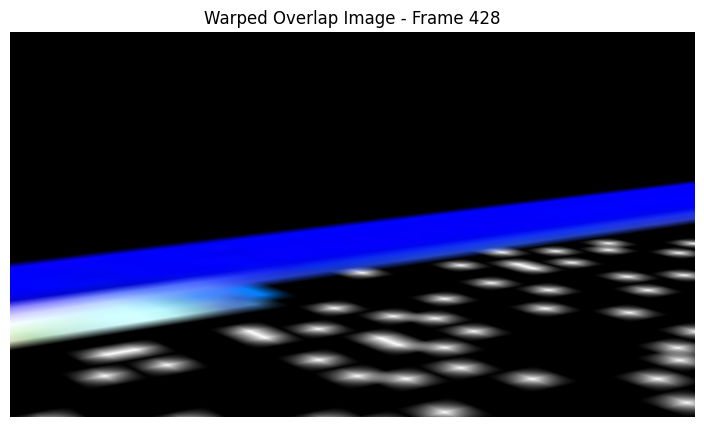

Iteration:   7%|▋         | 33/450 [00:05<01:15,  5.55it/s]

Normalized Homography matrix for frame 299:
[[ 3.9620616e-02  5.6558014e-03  9.3860352e+01]
 [ 2.6617343e-02  2.2375436e-01 -1.5301468e+02]
 [-4.3939686e-05  4.1286754e-03  1.0000000e+00]]


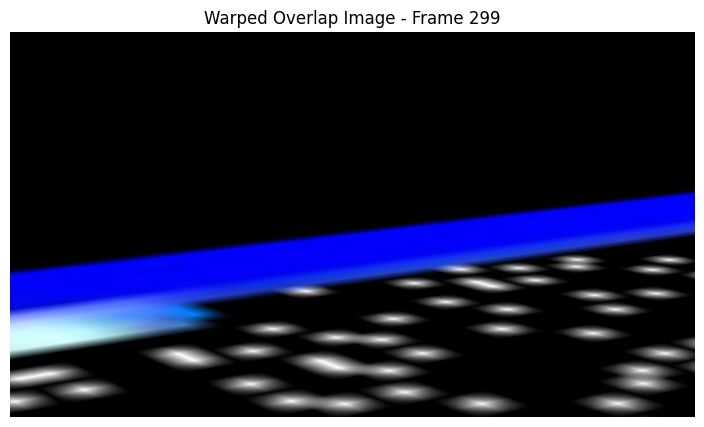

Iteration:   8%|▊         | 34/450 [00:06<01:14,  5.56it/s]

Normalized Homography matrix for frame 333:
[[ 5.2783374e-02  1.0991963e-02  8.6990692e+01]
 [ 3.2014415e-02  2.8536940e-01 -1.9077477e+02]
 [-3.4823664e-05  5.2962359e-03  1.0000000e+00]]


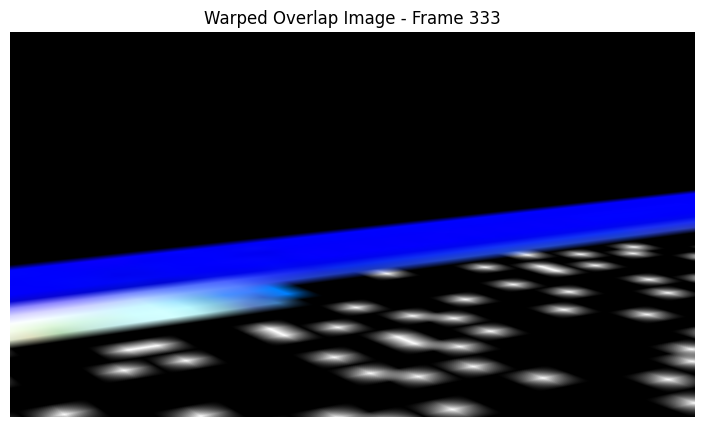

Iteration:   8%|▊         | 35/450 [00:06<01:15,  5.52it/s]

Normalized Homography matrix for frame 247:
[[ 6.6098869e-02  1.5944304e-02  1.5138976e+02]
 [ 4.6502240e-02  3.6456150e-01 -2.8021194e+02]
 [-5.6942641e-05  6.9272425e-03  1.0000000e+00]]


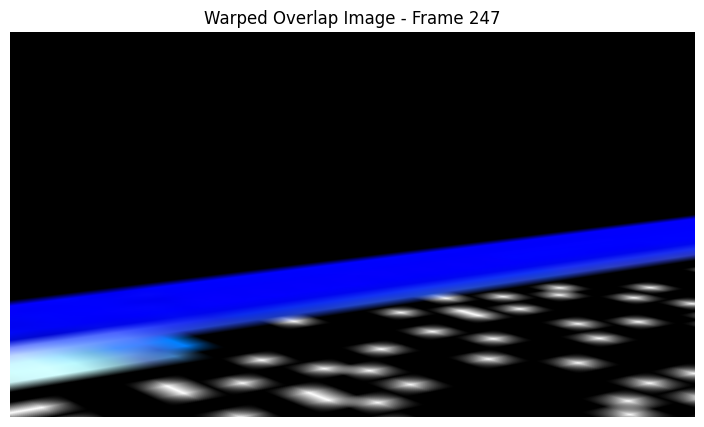

Iteration:   8%|▊         | 36/450 [00:06<01:14,  5.53it/s]

Normalized Homography matrix for frame 442:
[[ 4.2611066e-02  4.4054477e-03  8.1492966e+01]
 [ 2.7588576e-02  2.3040065e-01 -1.5095589e+02]
 [-3.1218504e-05  4.2333202e-03  1.0000000e+00]]


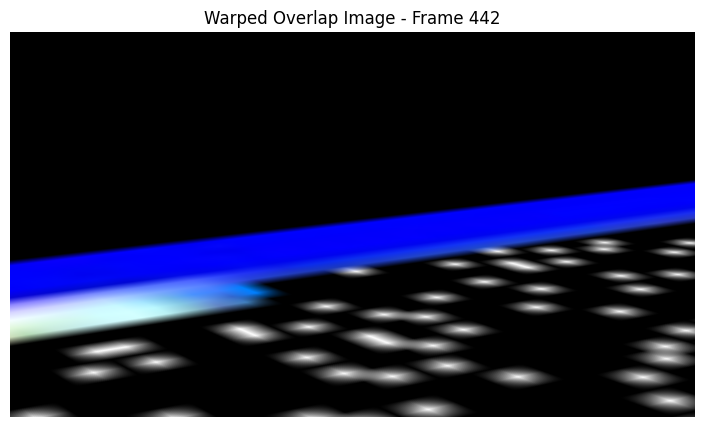

Iteration:   8%|▊         | 37/450 [00:06<01:14,  5.53it/s]

Normalized Homography matrix for frame 118:
[[ 1.5348354e-01  6.1059326e-02  4.5617958e+01]
 [ 4.5747310e-02  6.4991146e-01 -6.0971442e+02]
 [-4.4154131e-05  1.4391331e-02  1.0000000e+00]]


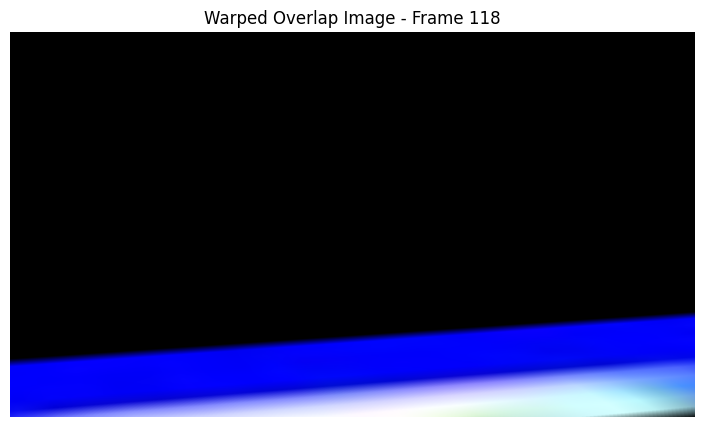

Iteration:   8%|▊         | 38/450 [00:06<01:13,  5.60it/s]

Normalized Homography matrix for frame 436:
[[ 4.2787641e-02  3.8006741e-03  8.2329842e+01]
 [ 2.7928255e-02  2.3011406e-01 -1.5149484e+02]
 [-3.3887864e-05  4.2645545e-03  1.0000000e+00]]


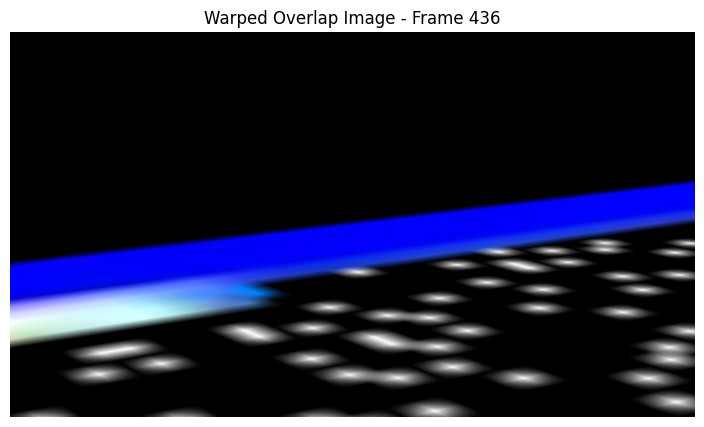

Iteration:   9%|▊         | 39/450 [00:07<01:14,  5.55it/s]

Normalized Homography matrix for frame 140:
[[ 1.3193685e-01  6.0307685e-02  4.2186321e+01]
 [ 4.4484209e-02  5.5909717e-01 -5.2377710e+02]
 [ 9.2115835e-05  1.1738192e-02  1.0000000e+00]]


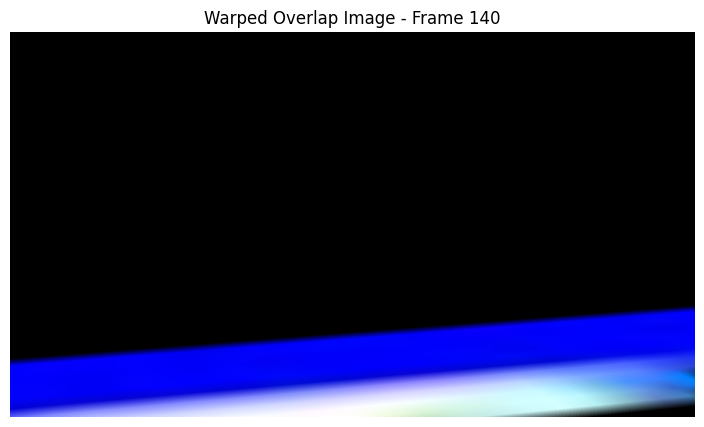

Iteration:   9%|▉         | 40/450 [00:07<01:13,  5.57it/s]

Normalized Homography matrix for frame 81:
[[ 1.3756086e-01  6.9159068e-02 -4.0976631e+01]
 [ 3.1468023e-02  5.1907545e-01 -4.4571808e+02]
 [ 1.5600290e-04  1.0450022e-02  1.0000000e+00]]


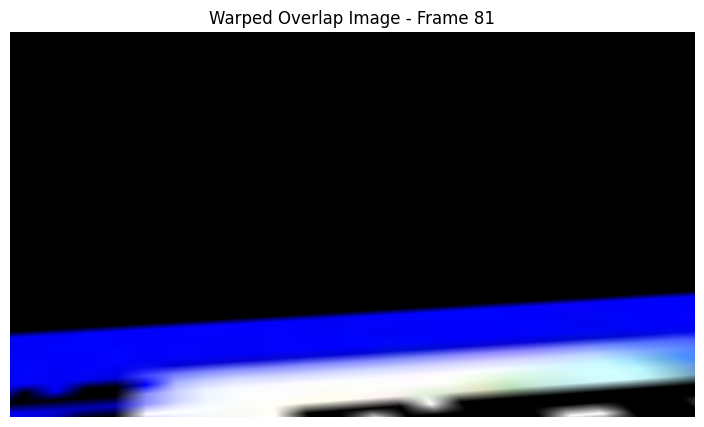

Iteration:   9%|▉         | 41/450 [00:07<01:13,  5.60it/s]

Normalized Homography matrix for frame 356:
[[ 4.9870919e-02  8.6643025e-03  9.0145126e+01]
 [ 3.1772483e-02  2.7191189e-01 -1.8105551e+02]
 [-3.8988641e-05  5.1062400e-03  1.0000000e+00]]


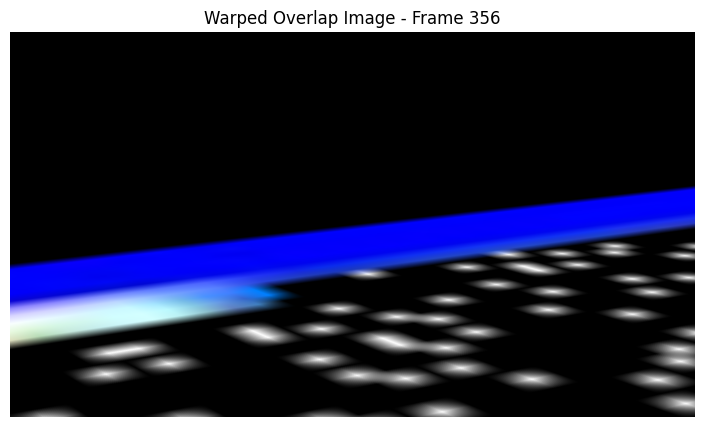

Iteration:   9%|▉         | 42/450 [00:07<01:13,  5.53it/s]

Normalized Homography matrix for frame 382:
[[ 4.6003312e-02  7.3464401e-03  8.7185440e+01]
 [ 2.9497787e-02  2.5082695e-01 -1.6594295e+02]
 [-4.4729972e-05  4.7263633e-03  1.0000000e+00]]


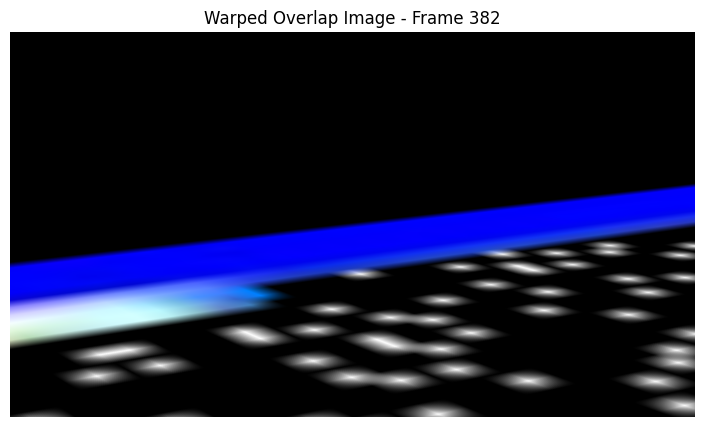

Iteration:  10%|▉         | 43/450 [00:07<01:13,  5.54it/s]

Normalized Homography matrix for frame 230:
[[ 8.4248148e-02  1.0453264e-02  1.7380157e+02]
 [ 5.6438517e-02  4.5635831e-01 -3.6174835e+02]
 [-6.9646841e-05  8.6694807e-03  1.0000000e+00]]


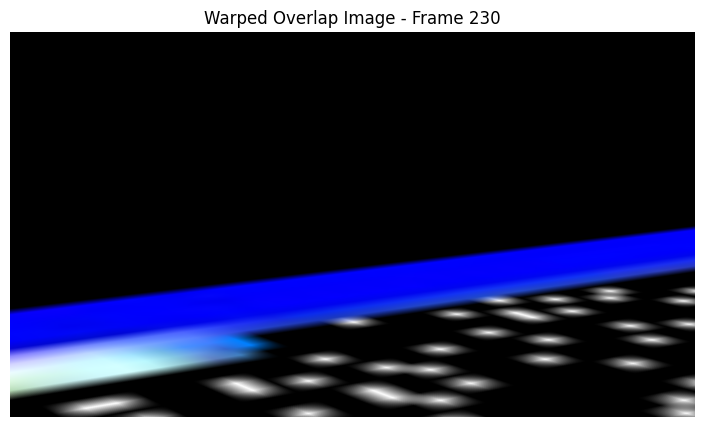

Iteration:  10%|▉         | 44/450 [00:07<01:13,  5.55it/s]

Normalized Homography matrix for frame 368:
[[ 4.4251151e-02  3.2009685e-03  8.4910370e+01]
 [ 2.8828854e-02  2.3880564e-01 -1.5937439e+02]
 [-3.1572428e-05  4.4116895e-03  1.0000000e+00]]


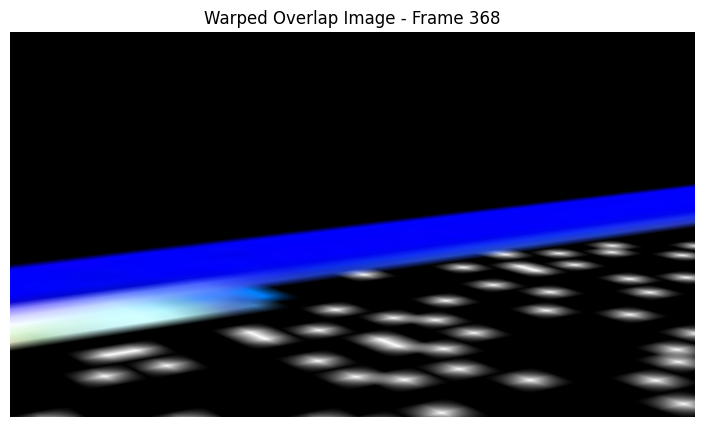

Iteration:  10%|█         | 45/450 [00:08<01:13,  5.54it/s]

Normalized Homography matrix for frame 209:
[[ 1.16095476e-01  2.61255950e-02  1.95958405e+02]
 [ 6.86349273e-02  6.06933951e-01 -4.98820770e+02]
 [-1.16349474e-04  1.19122714e-02  1.00000000e+00]]


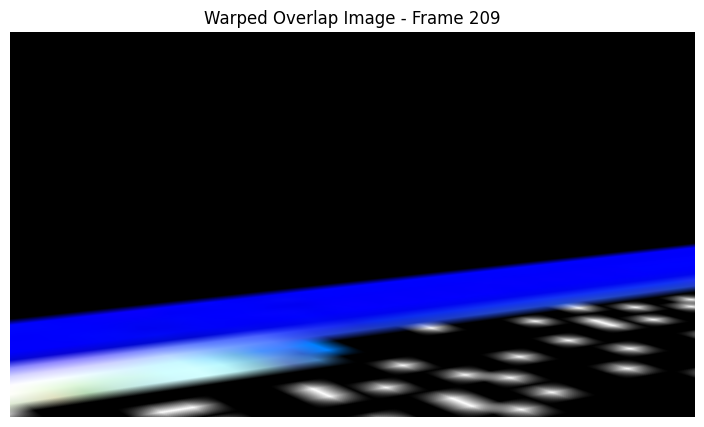

Iteration:  10%|█         | 46/450 [00:08<01:12,  5.59it/s]

Normalized Homography matrix for frame 351:
[[ 5.0925378e-02  8.4047476e-03  8.8478493e+01]
 [ 3.2377049e-02  2.7276906e-01 -1.8344418e+02]
 [-2.9103227e-05  5.0961338e-03  1.0000000e+00]]


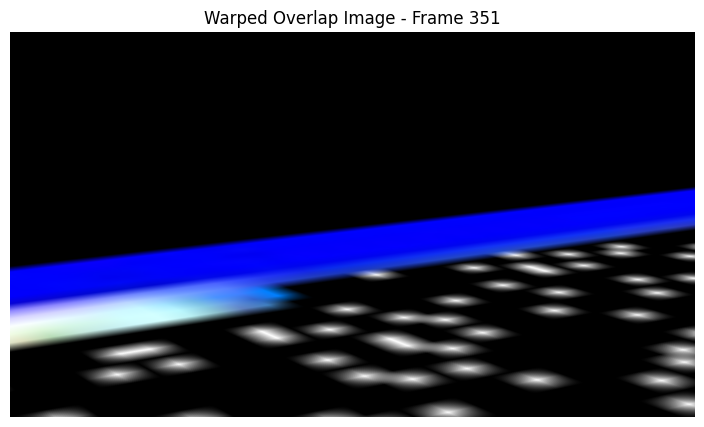

Iteration:  10%|█         | 47/450 [00:08<01:12,  5.53it/s]

Normalized Homography matrix for frame 5:
[[ 7.7928758e-01 -3.2307394e-02 -5.8164062e+02]
 [ 5.0596099e-02  3.4009650e+00 -2.4098679e+03]
 [-6.3929576e-05  6.2484447e-02  1.0000000e+00]]


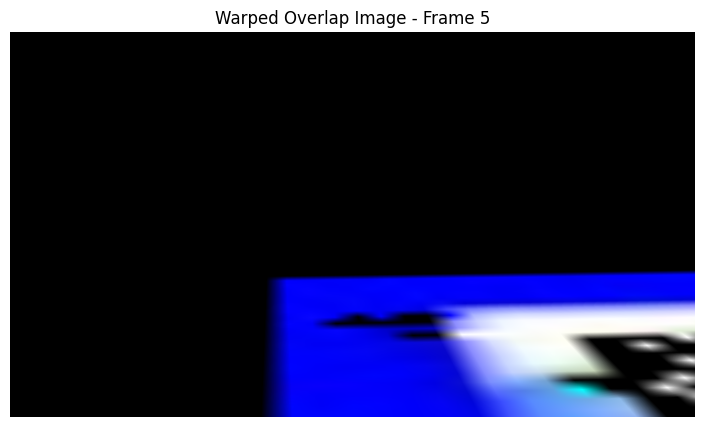

Iteration:  11%|█         | 48/450 [00:08<01:12,  5.57it/s]

Normalized Homography matrix for frame 324:
[[ 5.1689018e-02  4.8358273e-03  8.8279732e+01]
 [ 3.2927275e-02  2.7211225e-01 -1.8593190e+02]
 [-2.9515533e-05  5.1302789e-03  1.0000000e+00]]


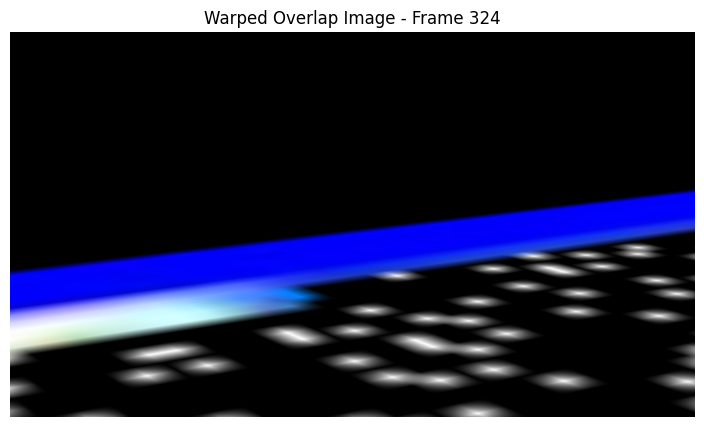

Iteration:  11%|█         | 49/450 [00:08<01:12,  5.53it/s]

Normalized Homography matrix for frame 2:
[[ 2.8696877e-01 -9.6531492e-03 -2.2756708e+02]
 [ 1.2741097e-02  1.3088967e+00 -9.2510431e+02]
 [-2.7296004e-05  2.2114344e-02  1.0000000e+00]]


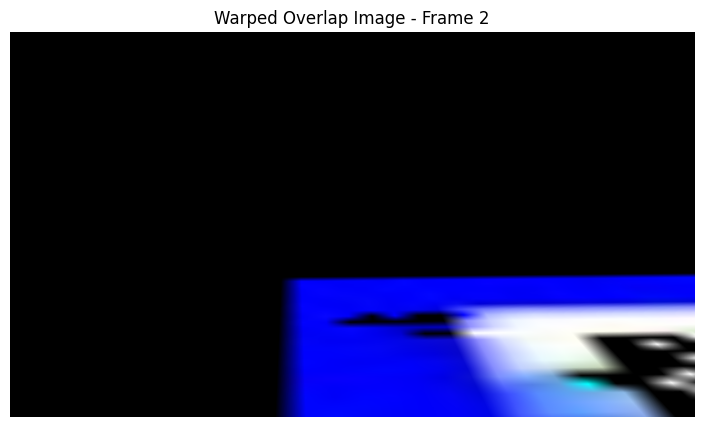

Iteration:  11%|█         | 50/450 [00:09<01:11,  5.58it/s]

Normalized Homography matrix for frame 317:
[[ 4.8146814e-02  5.6970092e-03  8.5933022e+01]
 [ 2.8814027e-02  2.6365301e-01 -1.7572105e+02]
 [-5.2039315e-05  4.7978102e-03  1.0000000e+00]]


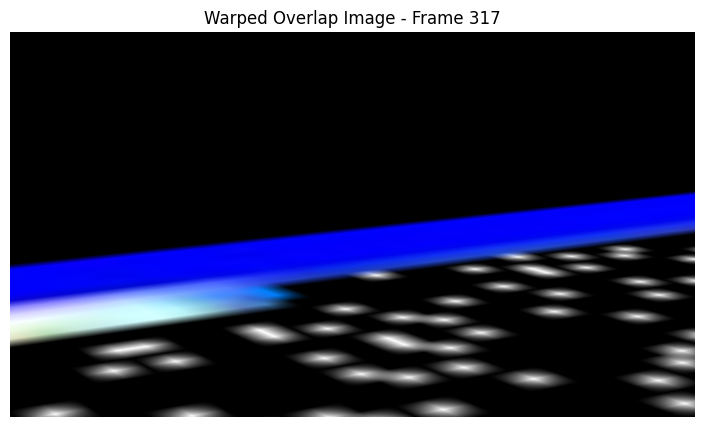

Iteration:  11%|█▏        | 51/450 [00:09<01:11,  5.55it/s]

Normalized Homography matrix for frame 193:
[[ 1.03222854e-01  3.10192816e-02  1.39350250e+02]
 [ 5.21863736e-02  5.21064162e-01 -4.45073456e+02]
 [-5.37680389e-05  1.00990161e-02  1.00000000e+00]]


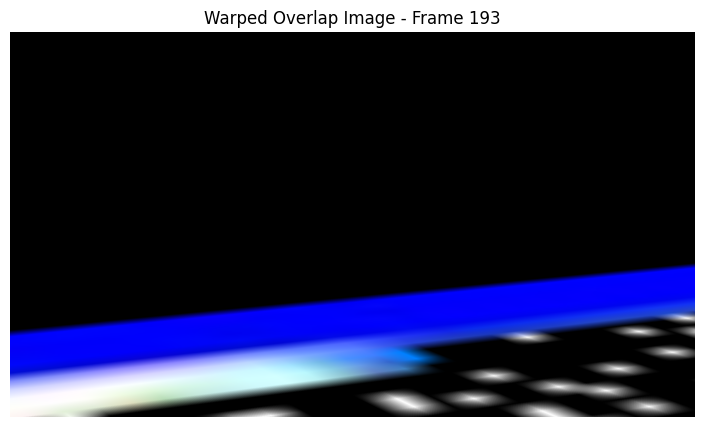

Iteration:  12%|█▏        | 52/450 [00:09<01:10,  5.61it/s]

Normalized Homography matrix for frame 339:
[[ 4.9330197e-02  8.4587308e-03  8.3307999e+01]
 [ 3.0024441e-02  2.6545557e-01 -1.7704724e+02]
 [-2.9638348e-05  4.8249001e-03  1.0000000e+00]]


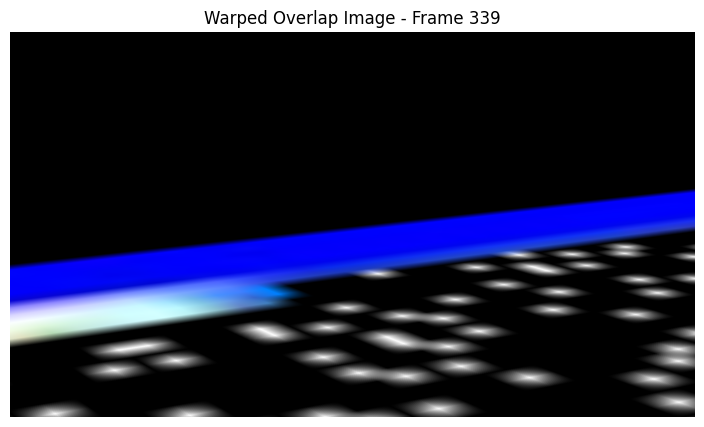

Iteration:  12%|█▏        | 53/450 [00:09<01:19,  4.99it/s]

Normalized Homography matrix for frame 102:
[[ 8.7699398e-02  3.1648245e-02  6.8611441e+00]
 [ 2.4545440e-02  3.5756409e-01 -3.2202954e+02]
 [ 6.6664179e-05  6.6224975e-03  1.0000000e+00]]


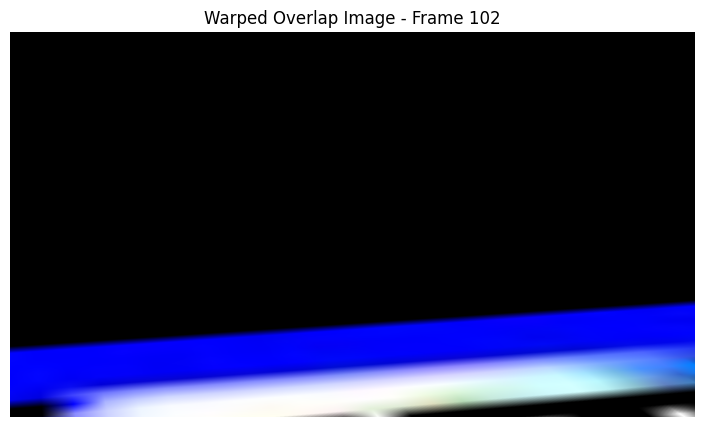

Iteration:  12%|█▏        | 54/450 [00:09<01:16,  5.17it/s]

Normalized Homography matrix for frame 392:
[[ 4.6274636e-02  5.9331818e-03  8.7248619e+01]
 [ 3.0520478e-02  2.4861491e-01 -1.6624342e+02]
 [-3.0062218e-05  4.6773716e-03  1.0000000e+00]]


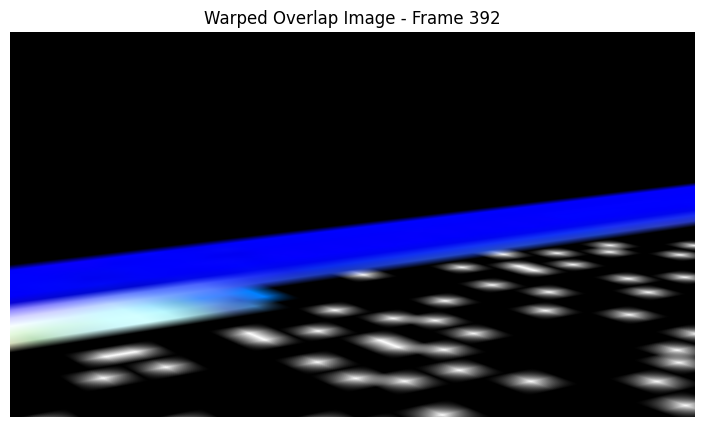

Iteration:  12%|█▏        | 55/450 [00:09<01:15,  5.21it/s]

Normalized Homography matrix for frame 171:
[[ 5.8026474e-02 -9.0835355e-03  7.1219406e+01]
 [ 2.7214305e-02  2.6754209e-01 -2.4810706e+02]
 [ 7.3926444e-06  4.7315466e-03  1.0000000e+00]]


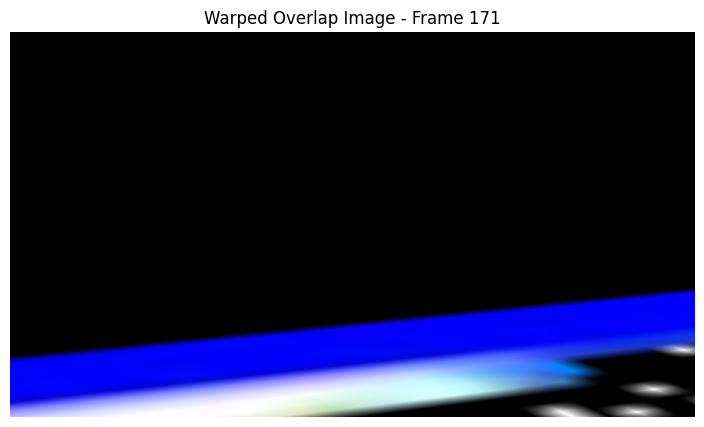

Iteration:  12%|█▏        | 56/450 [00:10<01:14,  5.32it/s]

Normalized Homography matrix for frame 344:
[[ 5.1101383e-02  9.8480256e-03  8.7719734e+01]
 [ 3.1706057e-02  2.7397951e-01 -1.8340439e+02]
 [-4.3145636e-05  5.1616696e-03  1.0000000e+00]]


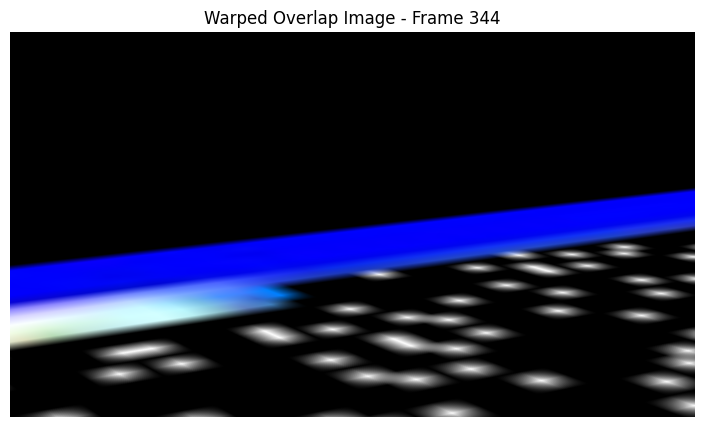

Iteration:  13%|█▎        | 57/450 [00:10<01:13,  5.38it/s]

Normalized Homography matrix for frame 111:
[[ 2.3013102e-01  1.1571938e-01  2.6658461e+01]
 [ 6.7658752e-02  9.5226991e-01 -8.8077118e+02]
 [ 7.8947443e-05  2.1280741e-02  1.0000000e+00]]


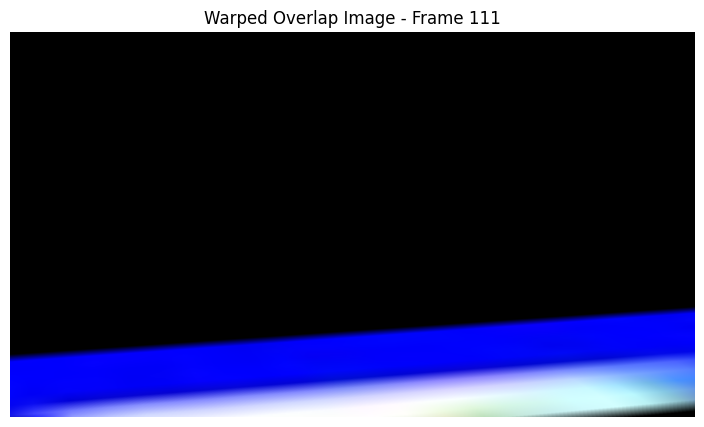

Iteration:  13%|█▎        | 58/450 [00:10<01:11,  5.47it/s]

Normalized Homography matrix for frame 287:
[[ 3.7683897e-02  1.0088546e-02  1.0251360e+02]
 [ 2.8344793e-02  2.1552229e-01 -1.4804979e+02]
 [-3.3208395e-05  4.1108811e-03  1.0000000e+00]]


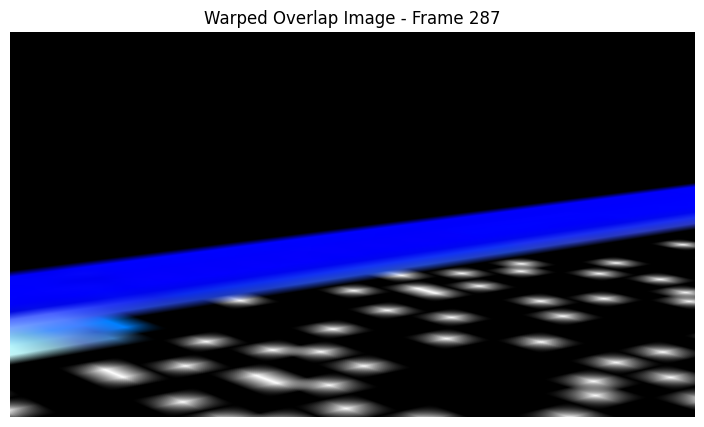

Iteration:  13%|█▎        | 59/450 [00:10<01:11,  5.51it/s]

Normalized Homography matrix for frame 275:
[[ 4.0758185e-02  9.1687096e-03  1.1287025e+02]
 [ 3.1108048e-02  2.3138125e-01 -1.6558421e+02]
 [-3.0943269e-05  4.3487060e-03  1.0000000e+00]]


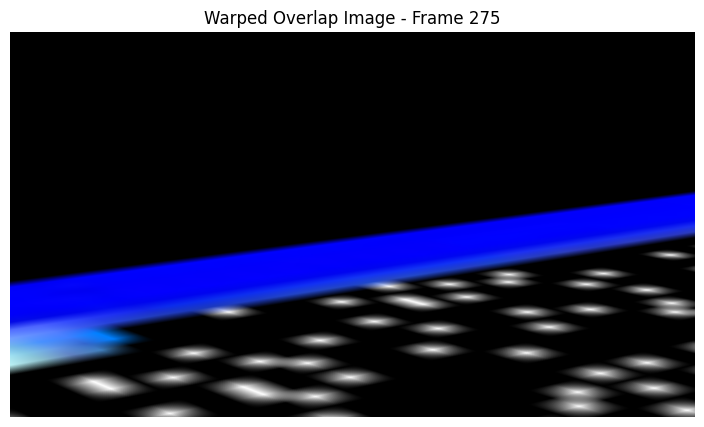

Iteration:  13%|█▎        | 60/450 [00:10<01:10,  5.50it/s]

Normalized Homography matrix for frame 116:
[[ 1.8433940e-01  9.8500080e-02  2.1771666e+01]
 [ 5.3124744e-02  7.4796140e-01 -7.0275415e+02]
 [ 5.7371235e-05  1.6621979e-02  1.0000000e+00]]


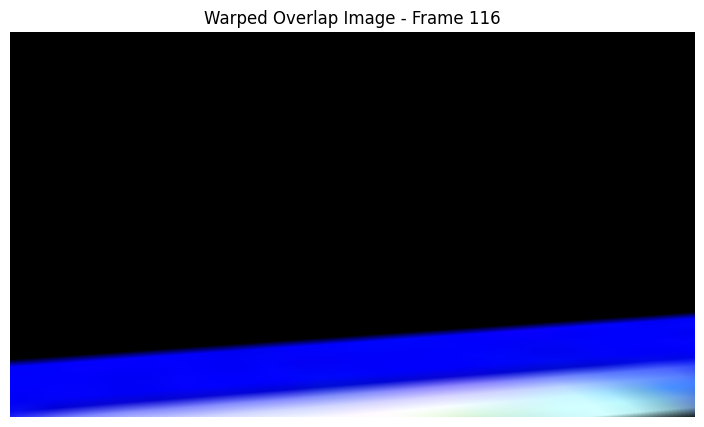

Iteration:  14%|█▎        | 61/450 [00:11<01:10,  5.53it/s]

Normalized Homography matrix for frame 18:
[[ 3.5744327e-01 -7.0385798e-03 -2.1410820e+02]
 [ 4.0615853e-02  1.5778289e+00 -1.1398367e+03]
 [ 1.1395188e-05  2.9982926e-02  1.0000000e+00]]


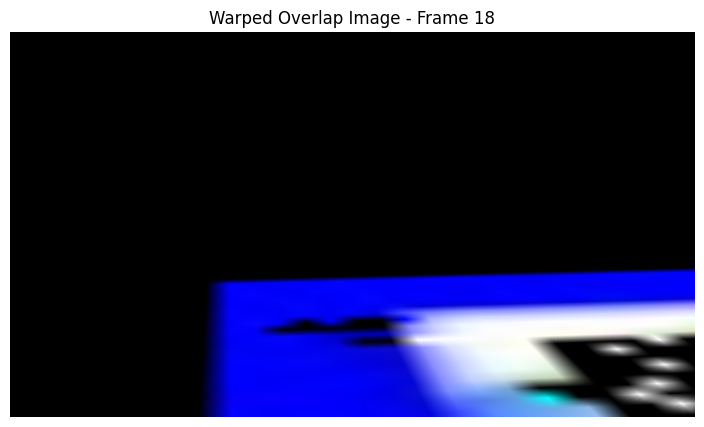

Iteration:  14%|█▍        | 62/450 [00:11<01:09,  5.57it/s]

Normalized Homography matrix for frame 402:
[[ 4.4904929e-02  4.1987882e-03  8.7158813e+01]
 [ 2.9632555e-02  2.4348299e-01 -1.6221066e+02]
 [-3.4053093e-05  4.5618191e-03  1.0000000e+00]]


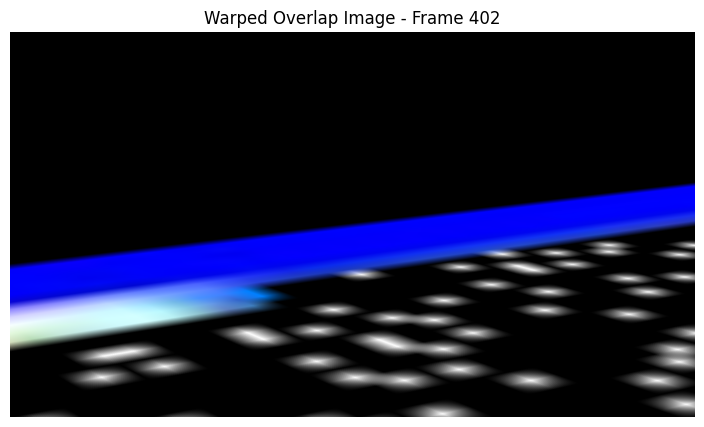

Iteration:  14%|█▍        | 63/450 [00:11<01:09,  5.55it/s]

Normalized Homography matrix for frame 432:
[[ 4.1812424e-02  3.6558053e-03  8.1915833e+01]
 [ 2.6413307e-02  2.2971134e-01 -1.4944006e+02]
 [-4.5289464e-05  4.2029996e-03  1.0000000e+00]]


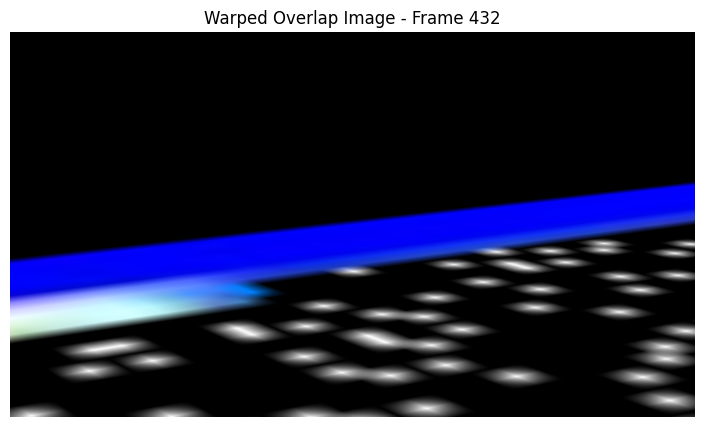

Iteration:  14%|█▍        | 64/450 [00:11<01:09,  5.53it/s]

Normalized Homography matrix for frame 72:
[[ 1.07652009e-01  2.50773039e-02 -1.50105991e+01]
 [ 2.73036491e-02  4.61161613e-01 -3.79683044e+02]
 [ 1.00262114e-04  8.74515530e-03  1.00000000e+00]]


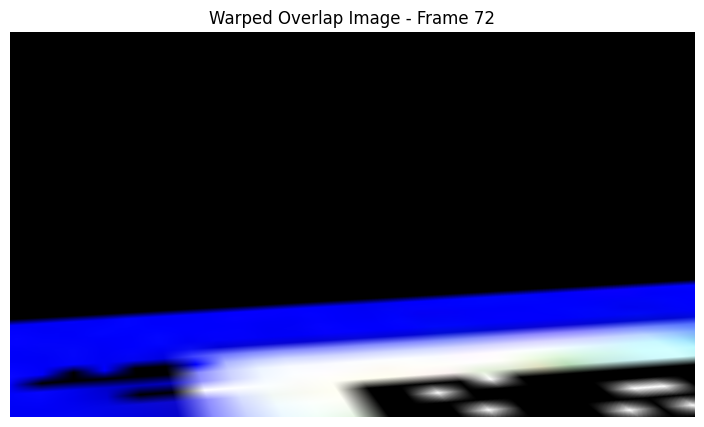

Iteration:  14%|█▍        | 65/450 [00:11<01:09,  5.56it/s]

Normalized Homography matrix for frame 406:
[[ 4.6097845e-02  6.9622267e-03  8.7155502e+01]
 [ 2.9937761e-02  2.4959673e-01 -1.6549673e+02]
 [-3.9866685e-05  4.7027883e-03  1.0000000e+00]]


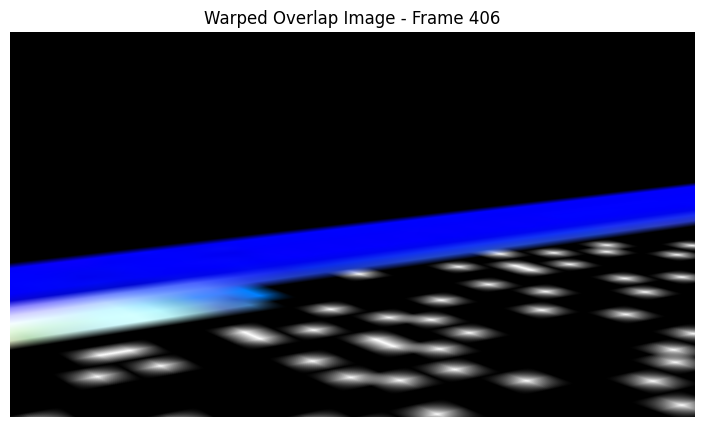

Iteration:  15%|█▍        | 66/450 [00:11<01:10,  5.46it/s]

Normalized Homography matrix for frame 338:
[[ 5.0790038e-02  8.1322668e-03  8.6484940e+01]
 [ 3.1772438e-02  2.7013695e-01 -1.8208754e+02]
 [-3.2829470e-05  5.0616814e-03  1.0000000e+00]]


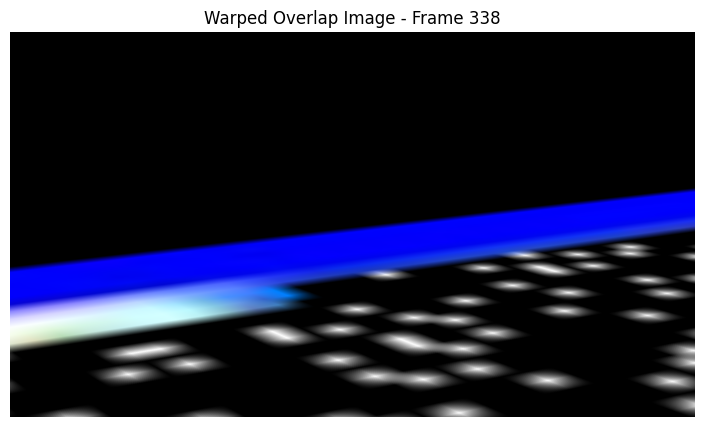

Iteration:  15%|█▍        | 67/450 [00:12<01:10,  5.47it/s]

Normalized Homography matrix for frame 35:
[[ 1.6937332e-01  6.1554797e-03 -8.0300278e+01]
 [ 2.5121856e-02  7.5212920e-01 -5.5589758e+02]
 [ 2.8739563e-05  1.4423506e-02  1.0000000e+00]]


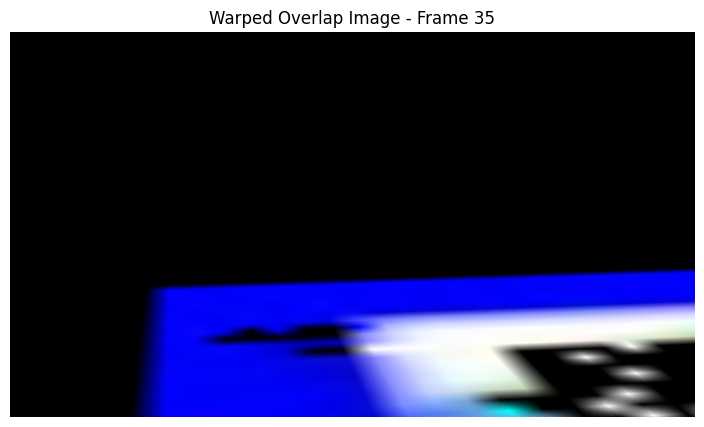

Iteration:  15%|█▌        | 68/450 [00:12<01:09,  5.48it/s]

Normalized Homography matrix for frame 329:
[[ 5.1499534e-02  7.1457089e-03  8.6376350e+01]
 [ 3.2505941e-02  2.7004138e-01 -1.8428064e+02]
 [-2.6267036e-05  5.0875377e-03  1.0000000e+00]]


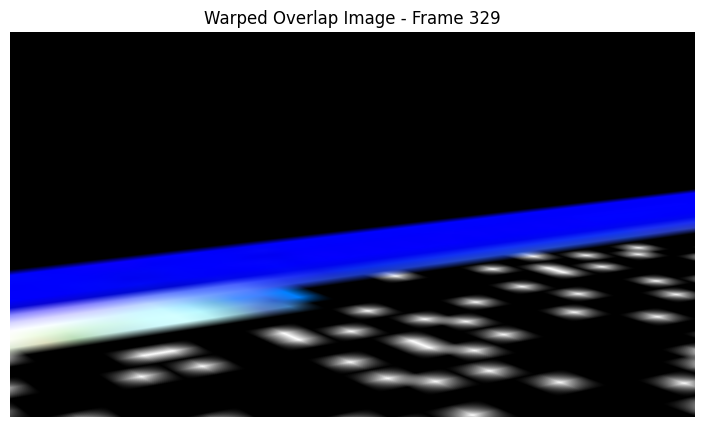

Iteration:  15%|█▌        | 69/450 [00:12<01:09,  5.49it/s]

Normalized Homography matrix for frame 293:
[[ 3.4730002e-02  5.9516928e-03  9.0086975e+01]
 [ 2.4346447e-02  1.9524096e-01 -1.3297998e+02]
 [-3.3650362e-05  3.5787546e-03  1.0000000e+00]]


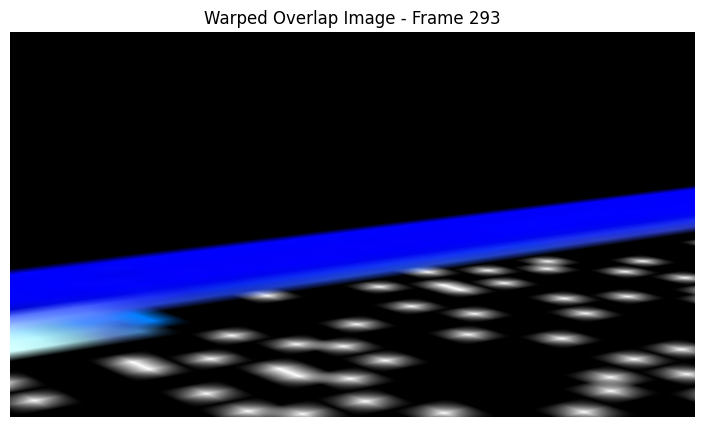

Iteration:  16%|█▌        | 70/450 [00:12<01:08,  5.52it/s]

Normalized Homography matrix for frame 36:
[[ 1.8186873e-01  1.0304948e-03 -7.9783905e+01]
 [ 2.7056765e-02  7.7621537e-01 -5.7447144e+02]
 [-3.6478195e-05  1.5242625e-02  1.0000000e+00]]


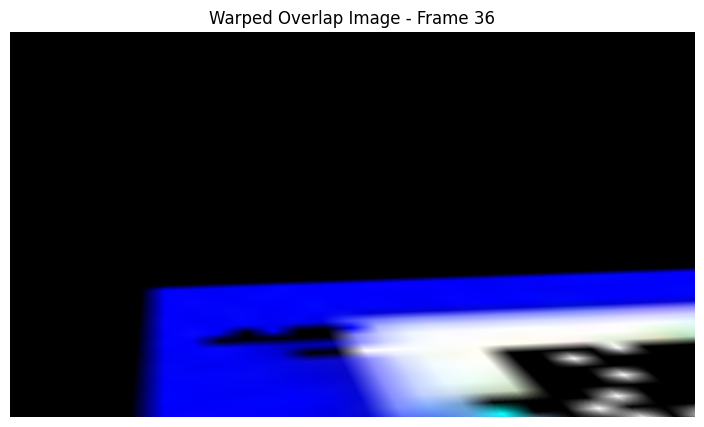

Iteration:  16%|█▌        | 71/450 [00:12<01:08,  5.55it/s]

Normalized Homography matrix for frame 87:
[[ 9.9384926e-02  4.7507279e-02 -2.2133059e+01]
 [ 2.4565216e-02  3.8924319e-01 -3.3703262e+02]
 [ 1.4074451e-04  7.0808409e-03  1.0000000e+00]]


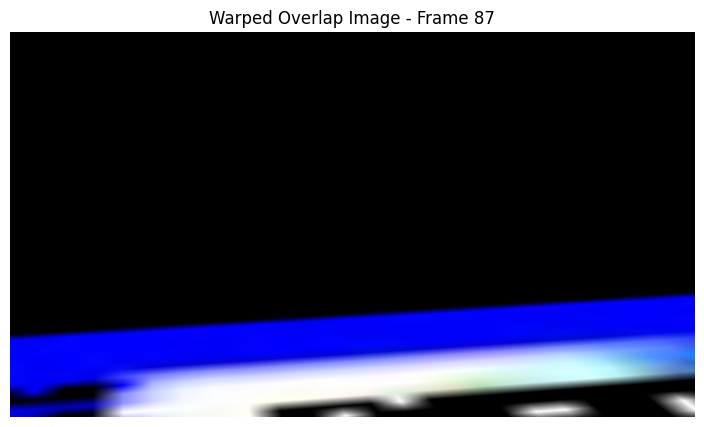

Iteration:  16%|█▌        | 72/450 [00:13<01:07,  5.60it/s]

Normalized Homography matrix for frame 316:
[[ 5.1600717e-02  7.3221456e-03  8.8670074e+01]
 [ 3.2736138e-02  2.7264369e-01 -1.8590611e+02]
 [-2.9034432e-05  5.0941836e-03  1.0000000e+00]]


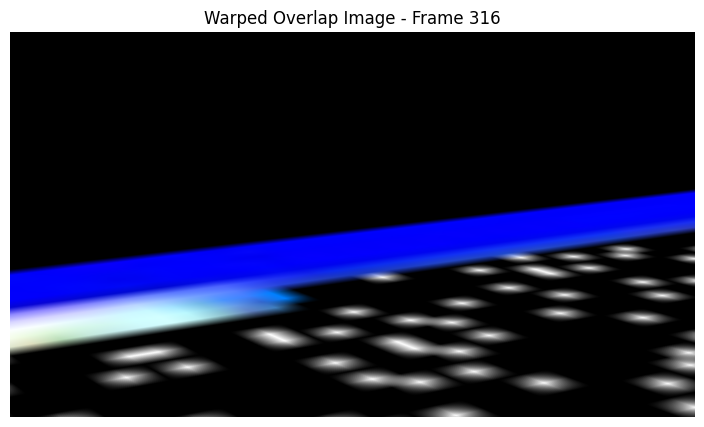

Iteration:  16%|█▌        | 73/450 [00:13<01:07,  5.56it/s]

Normalized Homography matrix for frame 60:
[[ 1.0782994e-01  4.8334396e-04 -1.0808030e+01]
 [ 2.4407623e-02  4.6592337e-01 -3.6617831e+02]
 [-2.0189495e-05  9.0371892e-03  1.0000000e+00]]


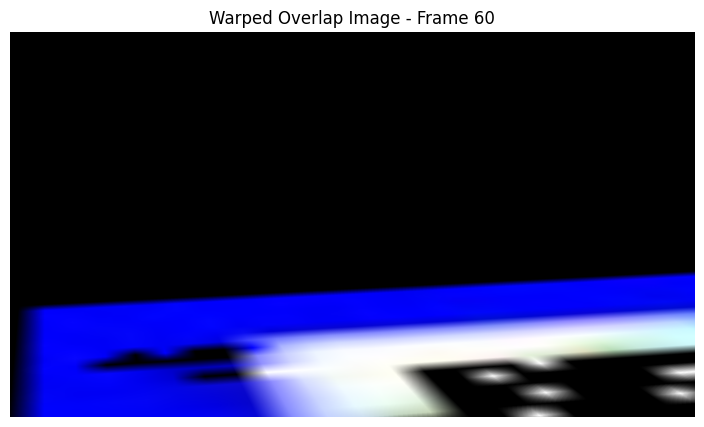

Iteration:  16%|█▋        | 74/450 [00:13<01:07,  5.59it/s]

Normalized Homography matrix for frame 208:
[[ 1.1919098e-01  3.1370774e-02  1.9660948e+02]
 [ 7.0510820e-02  6.2777191e-01 -5.1577557e+02]
 [-7.6280368e-05  1.2153307e-02  1.0000000e+00]]


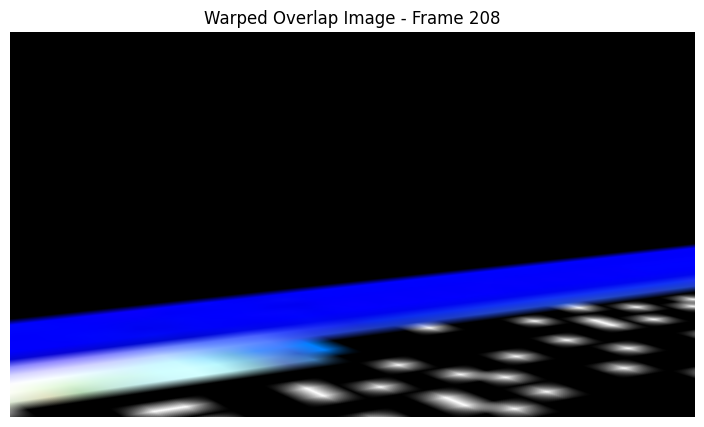

Iteration:  17%|█▋        | 75/450 [00:13<01:06,  5.62it/s]

Normalized Homography matrix for frame 59:
[[ 1.1034003e-01 -3.6232118e-03 -9.2260475e+00]
 [ 2.5956355e-02  5.0696903e-01 -3.9607977e+02]
 [ 1.3306576e-05  9.8179746e-03  1.0000000e+00]]


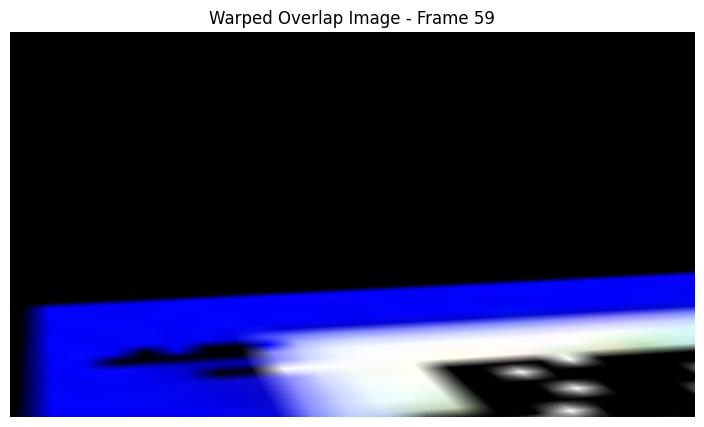

Iteration:  17%|█▋        | 76/450 [00:13<01:07,  5.57it/s]

Normalized Homography matrix for frame 291:
[[ 3.3478316e-02  3.0418721e-03  9.2338242e+01]
 [ 2.4504812e-02  1.8829899e-01 -1.2928067e+02]
 [-3.3774319e-05  3.4933055e-03  1.0000000e+00]]


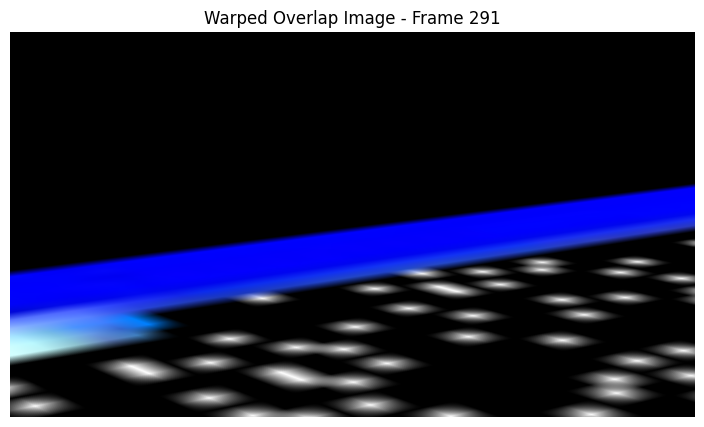

Iteration:  17%|█▋        | 77/450 [00:13<01:07,  5.54it/s]

Normalized Homography matrix for frame 231:
[[ 9.0238370e-02  2.7491055e-02  1.7597105e+02]
 [ 5.8581382e-02  4.9248344e-01 -3.8481812e+02]
 [-7.4222648e-05  9.3944566e-03  1.0000000e+00]]


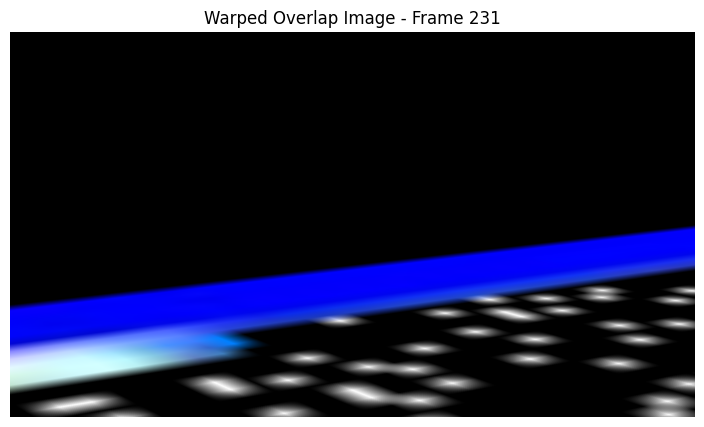

Iteration:  17%|█▋        | 78/450 [00:14<01:07,  5.55it/s]

Normalized Homography matrix for frame 34:
[[ 1.9773006e-01 -8.9568337e-03 -8.3016548e+01]
 [ 3.4245580e-02  8.9620453e-01 -6.6474255e+02]
 [ 6.6947017e-05  1.7145809e-02  1.0000000e+00]]


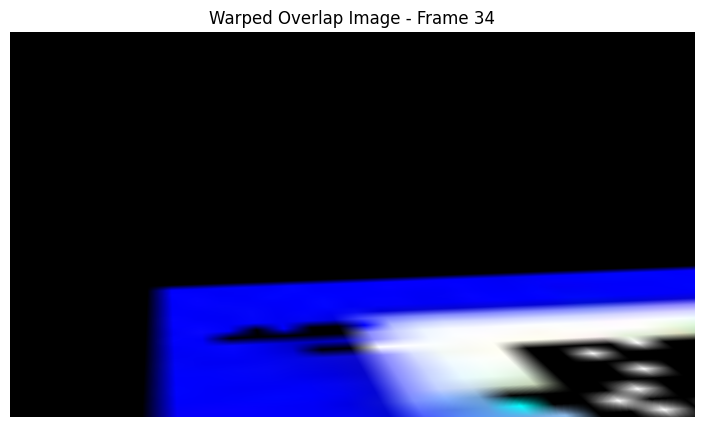

Iteration:  18%|█▊        | 79/450 [00:14<01:06,  5.61it/s]

Normalized Homography matrix for frame 62:
[[ 1.24844469e-01 -5.56126563e-03 -3.43210411e+00]
 [ 2.84228865e-02  5.36709845e-01 -4.21828339e+02]
 [-1.01919424e-04  1.08899903e-02  1.00000000e+00]]


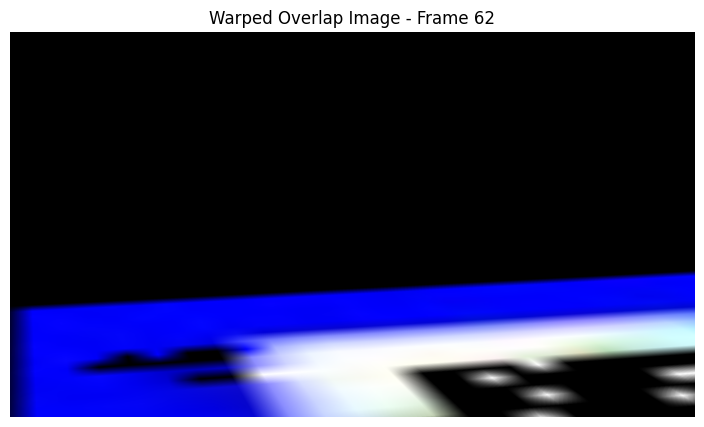

Iteration:  18%|█▊        | 80/450 [00:14<01:05,  5.62it/s]

Normalized Homography matrix for frame 114:
[[ 4.8786831e-01  3.0027643e-01  3.7241356e+00]
 [ 1.3989274e-01  1.8982027e+00 -1.7907703e+03]
 [ 1.8616638e-04  4.5420274e-02  1.0000000e+00]]


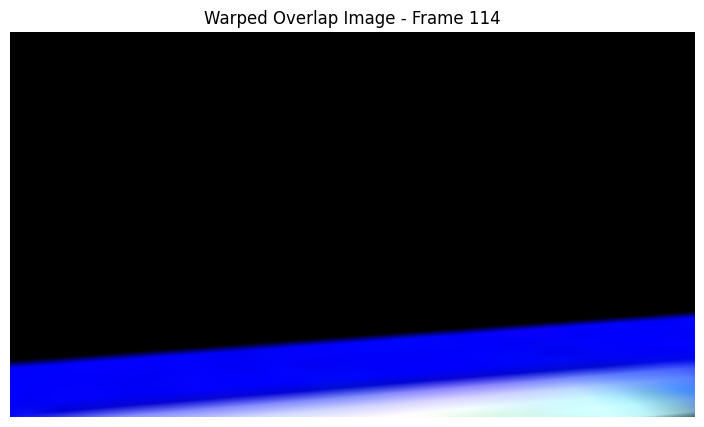

Iteration:  18%|█▊        | 81/450 [00:14<01:05,  5.64it/s]

Normalized Homography matrix for frame 318:
[[ 5.3111702e-02  8.5280836e-03  9.0075394e+01]
 [ 3.3385150e-02  2.8281125e-01 -1.9190199e+02]
 [-3.3619130e-05  5.3106346e-03  1.0000000e+00]]


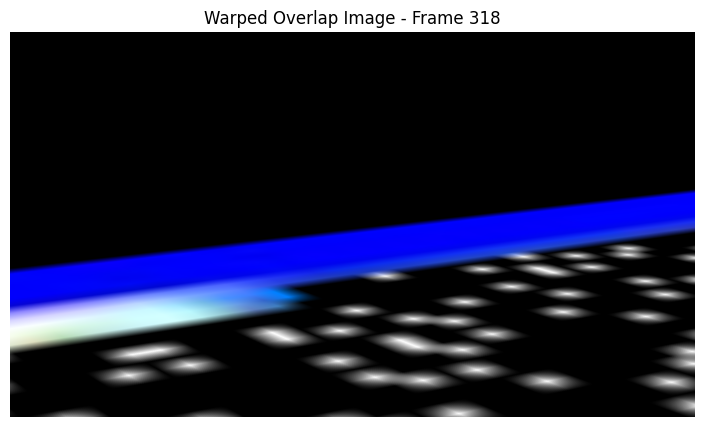

Iteration:  18%|█▊        | 82/450 [00:14<01:05,  5.61it/s]

Normalized Homography matrix for frame 271:
[[ 4.2976372e-02  7.2789155e-03  1.1890752e+02]
 [ 3.2976747e-02  2.4390559e-01 -1.7763408e+02]
 [-2.9006111e-05  4.5540328e-03  1.0000000e+00]]


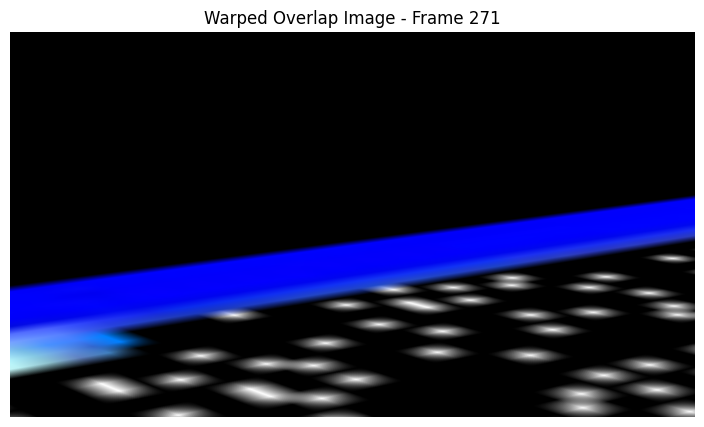

Iteration:  18%|█▊        | 83/450 [00:15<01:05,  5.56it/s]

Normalized Homography matrix for frame 330:
[[ 5.1051285e-02  6.9325026e-03  8.5551849e+01]
 [ 3.1801153e-02  2.6924822e-01 -1.8262320e+02]
 [-3.0712537e-05  5.0317519e-03  1.0000000e+00]]


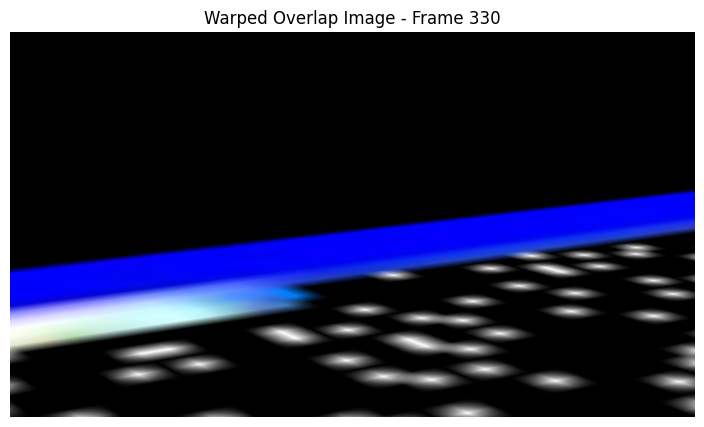

Iteration:  19%|█▊        | 84/450 [00:15<01:05,  5.56it/s]

Normalized Homography matrix for frame 23:
[[ 2.0612927e-01 -7.3942146e-03 -1.0952953e+02]
 [ 2.4541568e-02  9.1612357e-01 -6.6481940e+02]
 [-3.6057270e-05  1.7060306e-02  1.0000000e+00]]


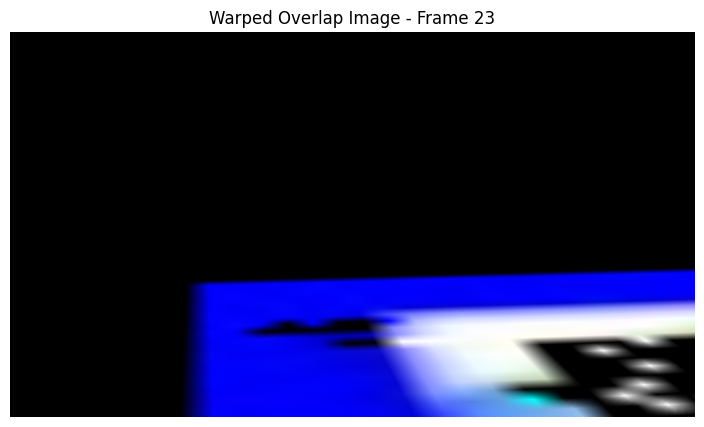

Iteration:  19%|█▉        | 85/450 [00:15<01:05,  5.60it/s]

Normalized Homography matrix for frame 33:
[[ 2.12465301e-01  1.13161737e-02 -1.06714134e+02]
 [ 3.09597906e-02  9.31117892e-01 -6.86517212e+02]
 [ 4.19317184e-05  1.81302913e-02  1.00000000e+00]]


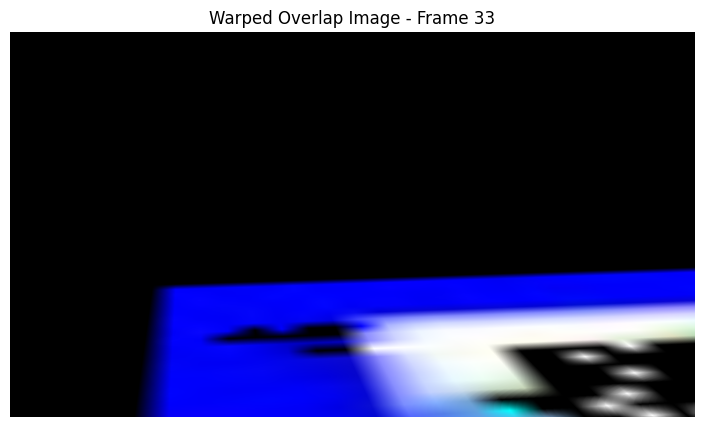

Iteration:  19%|█▉        | 86/450 [00:15<01:04,  5.61it/s]

Normalized Homography matrix for frame 348:
[[ 4.9498796e-02  5.9719775e-03  8.7341858e+01]
 [ 3.1814110e-02  2.6298025e-01 -1.7743802e+02]
 [-2.9473616e-05  4.9233297e-03  1.0000000e+00]]


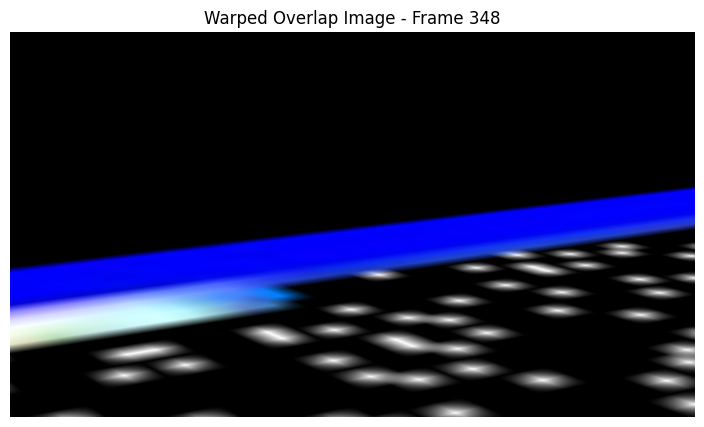

Iteration:  19%|█▉        | 87/450 [00:15<01:06,  5.47it/s]

Normalized Homography matrix for frame 301:
[[ 4.1675009e-02  2.4633624e-03  9.4430122e+01]
 [ 2.8418349e-02  2.2748494e-01 -1.5813022e+02]
 [-4.4493845e-05  4.2579370e-03  1.0000000e+00]]


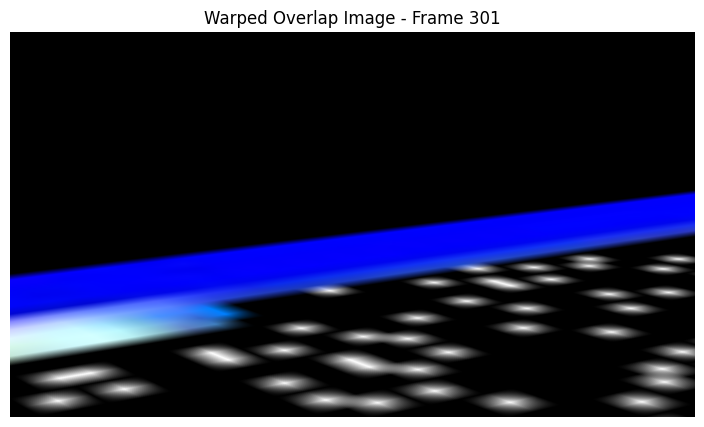

Iteration:  20%|█▉        | 88/450 [00:15<01:05,  5.50it/s]

Normalized Homography matrix for frame 427:
[[ 4.3823402e-02  6.4887442e-03  8.3744904e+01]
 [ 2.8378358e-02  2.3937272e-01 -1.5701688e+02]
 [-3.0712137e-05  4.4335164e-03  1.0000000e+00]]


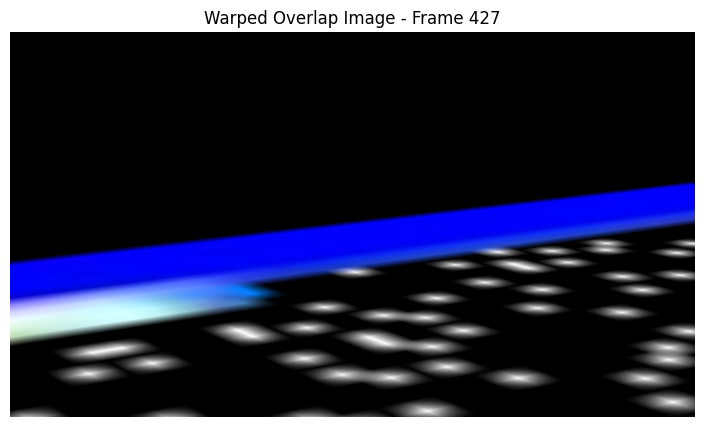

Iteration:  20%|█▉        | 89/450 [00:16<01:06,  5.43it/s]

Normalized Homography matrix for frame 11:
[[ 5.6975228e-01 -3.7383127e-03 -3.9727844e+02]
 [ 4.6263650e-02  2.5734231e+00 -1.8320551e+03]
 [-1.4261122e-06  4.7779497e-02  1.0000000e+00]]


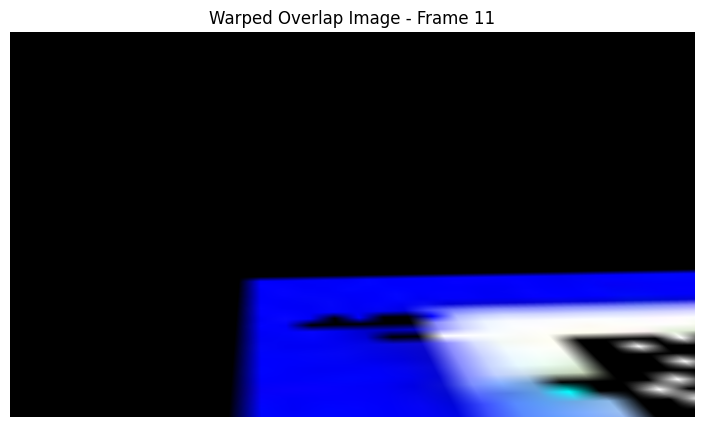

Iteration:  20%|██        | 90/450 [00:16<01:05,  5.54it/s]

Normalized Homography matrix for frame 337:
[[ 4.9929217e-02  6.2588272e-03  8.7624390e+01]
 [ 3.1328715e-02  2.6915526e-01 -1.8106584e+02]
 [-3.5627920e-05  5.0368882e-03  1.0000000e+00]]


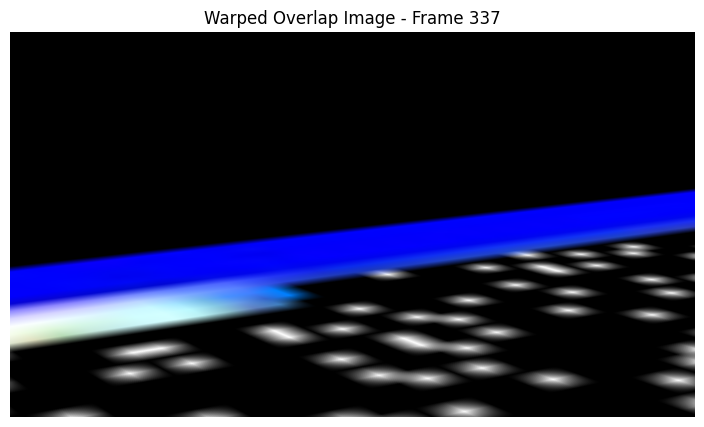

Iteration:  20%|██        | 91/450 [00:16<01:05,  5.49it/s]

Normalized Homography matrix for frame 55:
[[ 1.2761113e-01  9.7800884e-04 -2.3555195e+01]
 [ 2.7758921e-02  5.5944711e-01 -4.2983527e+02]
 [-1.0454264e-06  1.1072909e-02  1.0000000e+00]]


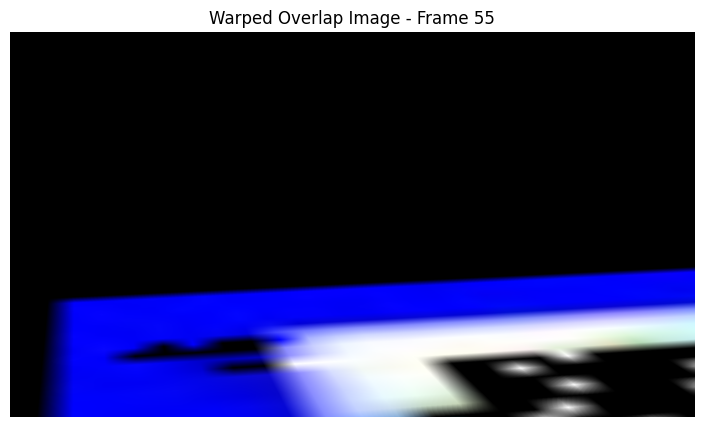

Iteration:  20%|██        | 92/450 [00:16<01:04,  5.52it/s]

Normalized Homography matrix for frame 148:
[[ 1.3221186e-01  6.7710221e-02  4.6404297e+01]
 [ 4.2948570e-02  5.7190001e-01 -5.2467035e+02]
 [ 3.1261465e-05  1.1948861e-02  1.0000000e+00]]


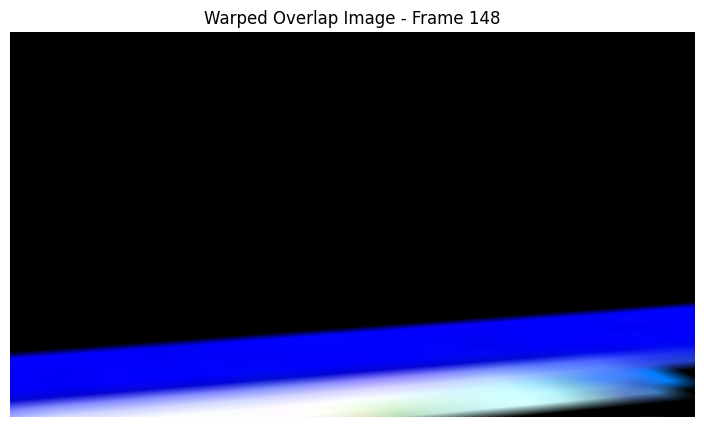

Iteration:  21%|██        | 93/450 [00:16<01:11,  4.98it/s]

Normalized Homography matrix for frame 40:
[[ 1.7505793e-01  6.1117858e-03 -7.2456223e+01]
 [ 2.8191520e-02  7.4080354e-01 -5.5108411e+02]
 [-1.7676521e-05  1.4647854e-02  1.0000000e+00]]


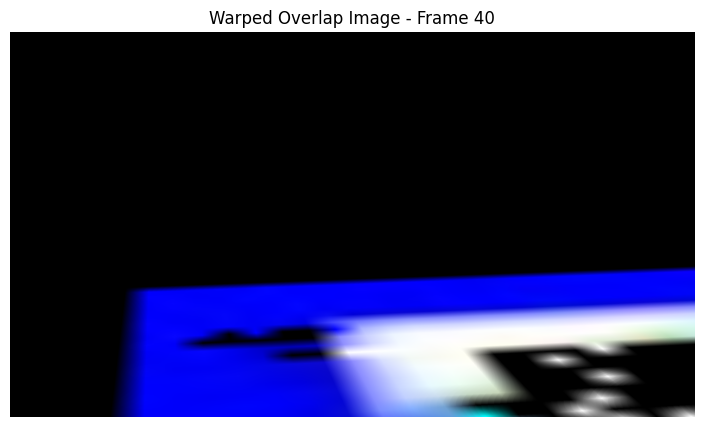

Iteration:  21%|██        | 94/450 [00:17<01:09,  5.15it/s]

Normalized Homography matrix for frame 181:
[[ 1.0330315e-01  3.5626452e-02  1.1840680e+02]
 [ 5.1059730e-02  4.8609728e-01 -4.4224203e+02]
 [ 2.5311168e-05  1.0069781e-02  1.0000000e+00]]


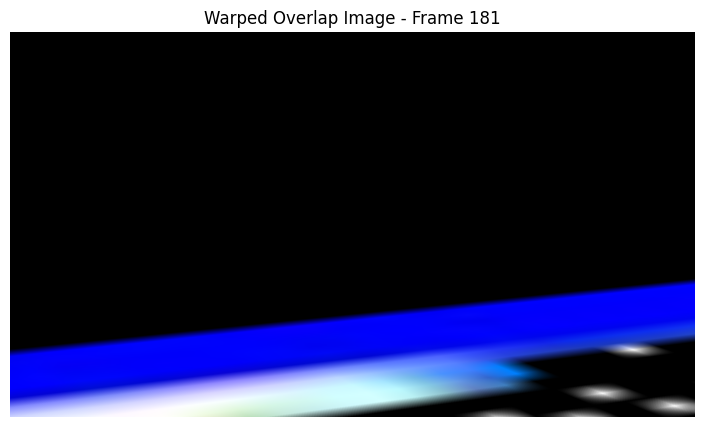

Iteration:  21%|██        | 95/450 [00:17<01:06,  5.32it/s]

Normalized Homography matrix for frame 127:
[[ 8.7163866e-02  2.0696526e-02  4.1667030e+01]
 [ 2.8249100e-02  3.8421130e-01 -3.5930756e+02]
 [ 7.5632088e-06  7.5887209e-03  1.0000000e+00]]


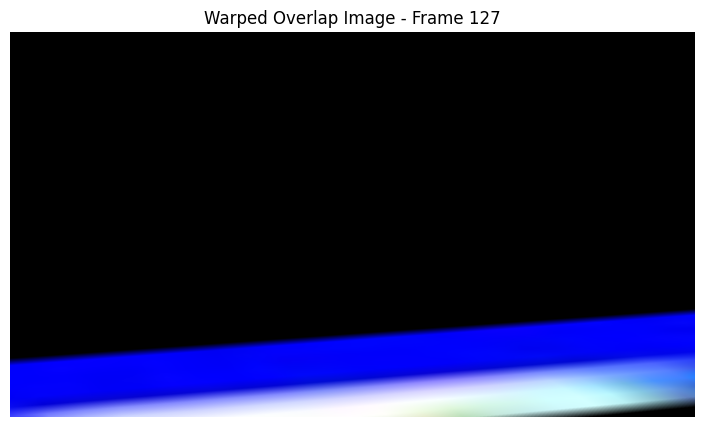

Iteration:  21%|██▏       | 96/450 [00:17<01:05,  5.42it/s]

Normalized Homography matrix for frame 88:
[[ 1.82667837e-01  1.15803786e-01 -6.06443481e+01]
 [ 4.60411757e-02  6.80547357e-01 -5.95892273e+02]
 [ 3.41606617e-04  1.40047166e-02  1.00000000e+00]]


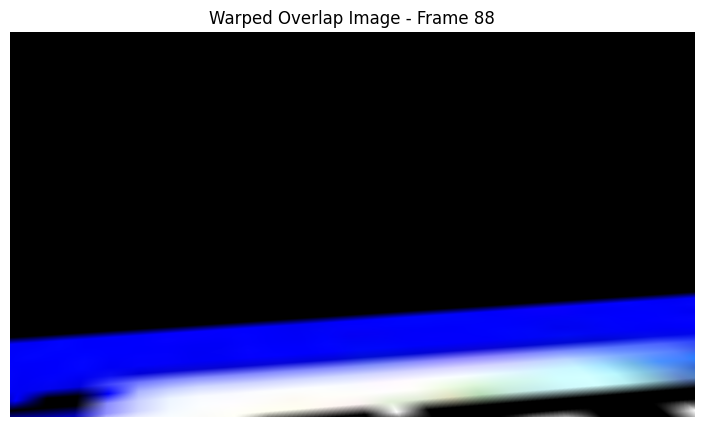

Iteration:  22%|██▏       | 97/450 [00:17<01:04,  5.51it/s]

Normalized Homography matrix for frame 117:
[[ 3.0391550e-01  1.5645647e-01  4.6133629e+01]
 [ 9.2082128e-02  1.2498761e+00 -1.1757141e+03]
 [ 7.7272278e-05  2.8672704e-02  1.0000000e+00]]


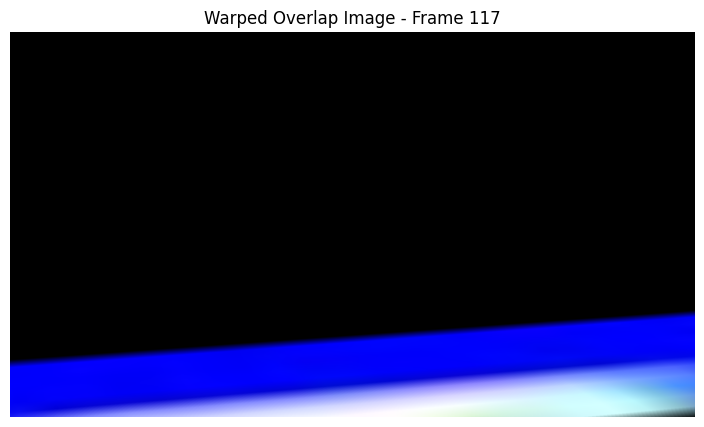

Iteration:  22%|██▏       | 98/450 [00:17<01:03,  5.56it/s]

Normalized Homography matrix for frame 369:
[[ 4.7158442e-02  1.0229933e-02  8.5446030e+01]
 [ 3.0213216e-02  2.5396329e-01 -1.6854282e+02]
 [-3.0118288e-05  4.7579375e-03  1.0000000e+00]]


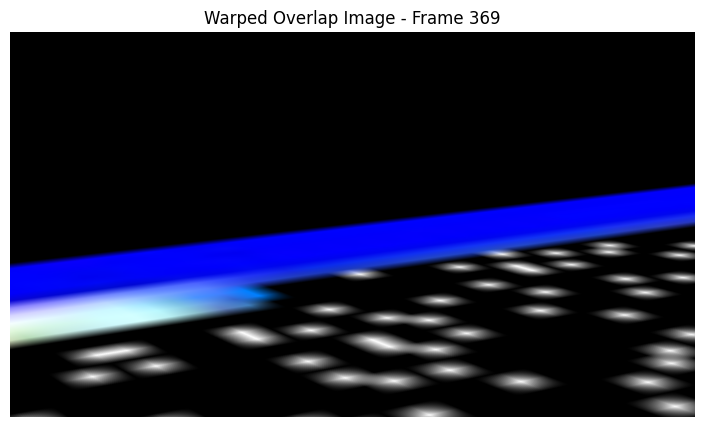

Iteration:  22%|██▏       | 99/450 [00:17<01:03,  5.54it/s]

Normalized Homography matrix for frame 419:
[[ 4.4208013e-02  2.2235019e-03  8.6106339e+01]
 [ 2.8974634e-02  2.3885641e-01 -1.5880453e+02]
 [-4.0579995e-05  4.4575161e-03  1.0000000e+00]]


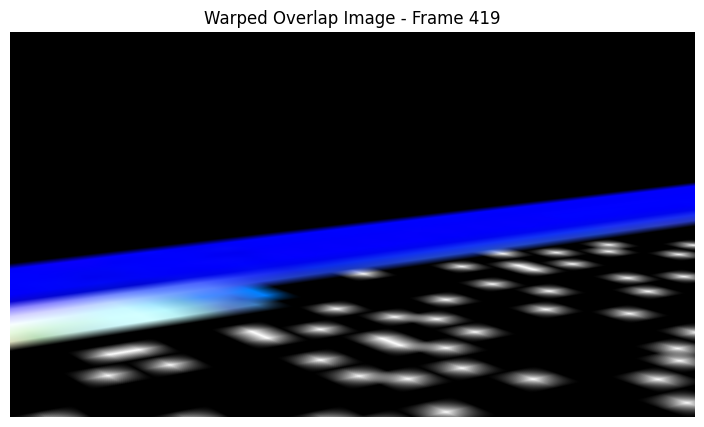

Iteration:  22%|██▏       | 100/450 [00:18<01:03,  5.51it/s]

Normalized Homography matrix for frame 441:
[[ 4.1719560e-02  4.4545712e-04  8.2255653e+01]
 [ 2.7818391e-02  2.2415994e-01 -1.4848080e+02]
 [-2.5326810e-05  4.1070483e-03  1.0000000e+00]]


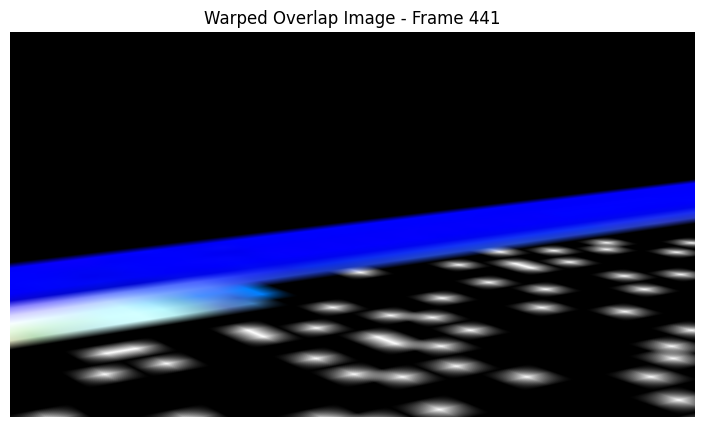

Iteration:  22%|██▏       | 101/450 [00:18<01:03,  5.51it/s]

Normalized Homography matrix for frame 180:
[[ 8.38955417e-02  1.72332935e-02  1.04408676e+02]
 [ 4.08585705e-02  4.04979050e-01 -3.67269867e+02]
 [ 8.75711521e-06  7.98788760e-03  1.00000000e+00]]


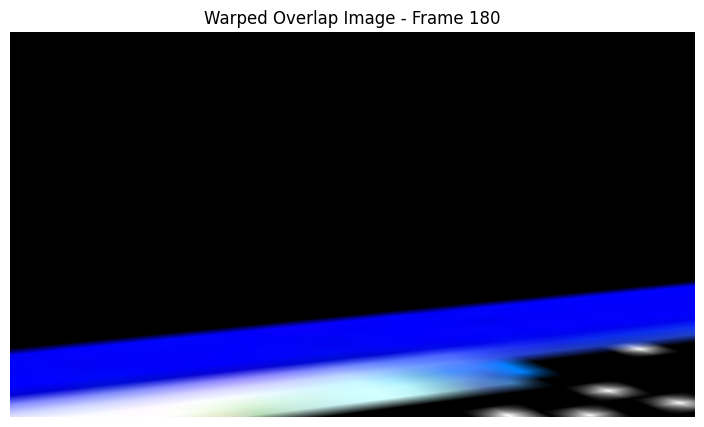

Iteration:  23%|██▎       | 102/450 [00:18<01:02,  5.60it/s]

Normalized Homography matrix for frame 240:
[[ 9.0210393e-02  3.4439798e-02  1.8442760e+02]
 [ 6.1555889e-02  4.9735257e-01 -3.8426645e+02]
 [-6.7028333e-05  9.6652312e-03  1.0000000e+00]]


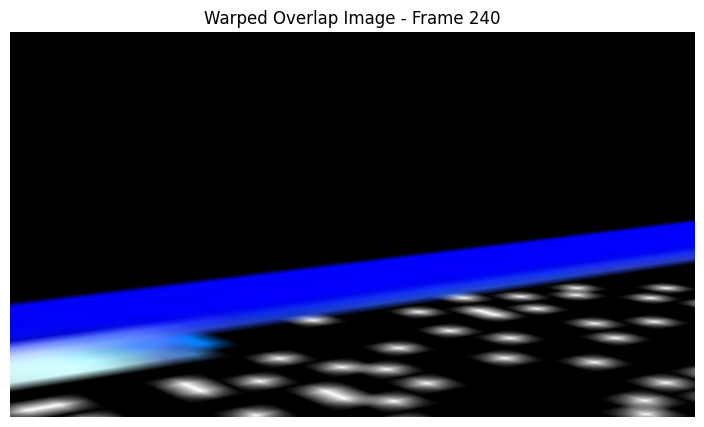

Iteration:  23%|██▎       | 103/450 [00:18<01:01,  5.61it/s]

Normalized Homography matrix for frame 265:
[[ 4.82625440e-02  1.18952077e-02  1.26990555e+02]
 [ 3.60410810e-02  2.72352070e-01 -2.00824585e+02]
 [-4.30814835e-05  5.17912395e-03  1.00000000e+00]]


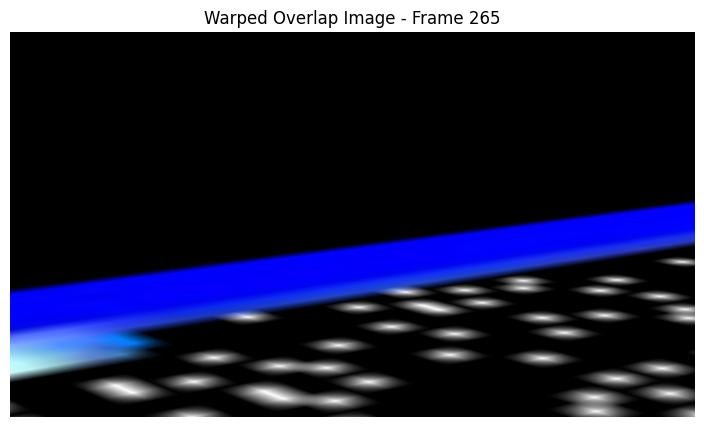

Iteration:  23%|██▎       | 104/450 [00:18<01:02,  5.57it/s]

Normalized Homography matrix for frame 131:
[[ 1.13519214e-01  3.17181945e-02  5.43572922e+01]
 [ 3.90520394e-02  5.04520237e-01 -4.71984955e+02]
 [ 3.34324286e-05  1.03897797e-02  1.00000000e+00]]


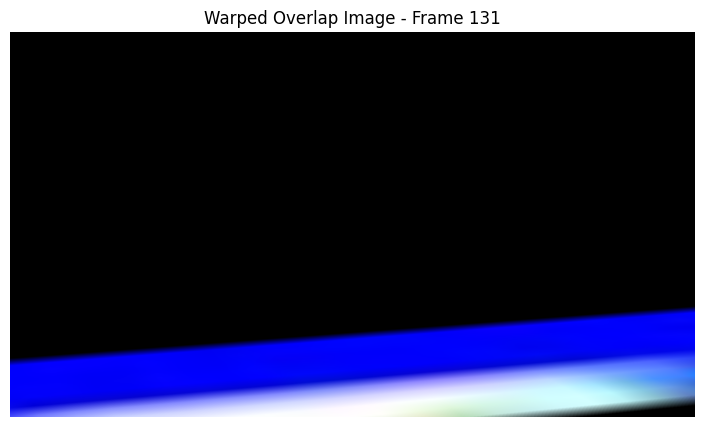

Iteration:  23%|██▎       | 105/450 [00:19<01:01,  5.58it/s]

Normalized Homography matrix for frame 169:
[[ 6.4262226e-02 -2.6214148e-03  6.4671143e+01]
 [ 2.7401343e-02  2.9130328e-01 -2.6694925e+02]
 [-2.7164066e-07  5.1325276e-03  1.0000000e+00]]


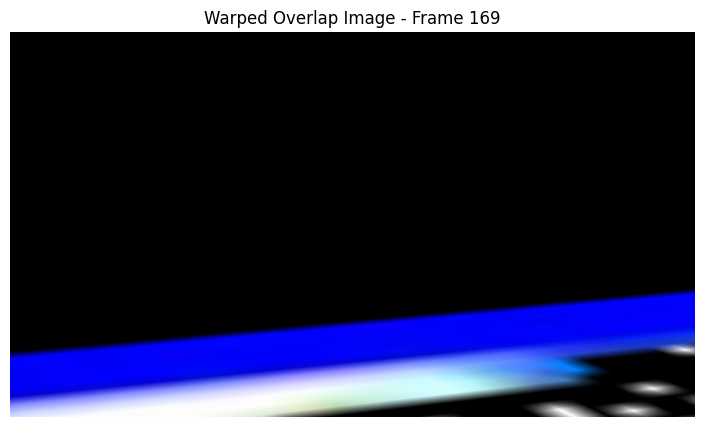

Iteration:  24%|██▎       | 106/450 [00:19<01:01,  5.64it/s]

Normalized Homography matrix for frame 52:
[[ 1.0604252e-01 -4.5012296e-03 -1.8934292e+01]
 [ 2.0570803e-02  4.8481396e-01 -3.6874210e+02]
 [-3.1119234e-05  9.3353931e-03  1.0000000e+00]]


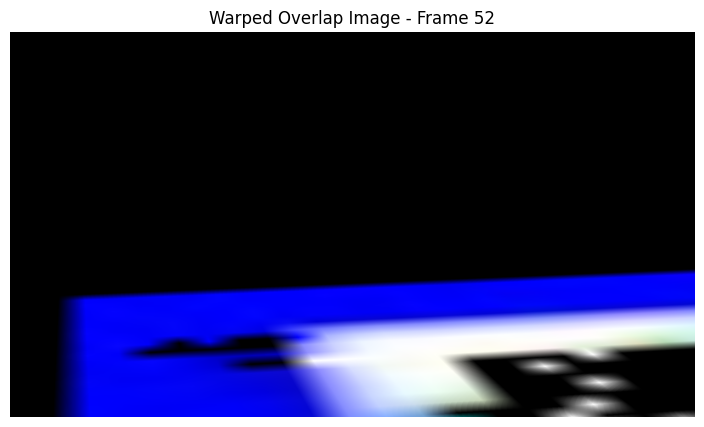

Iteration:  24%|██▍       | 107/450 [00:19<01:00,  5.63it/s]

Normalized Homography matrix for frame 173:
[[ 8.2503580e-02  1.7829631e-02  6.5632263e+01]
 [ 3.2769155e-02  3.6617720e-01 -3.2815762e+02]
 [-1.4718174e-05  6.7580971e-03  1.0000000e+00]]


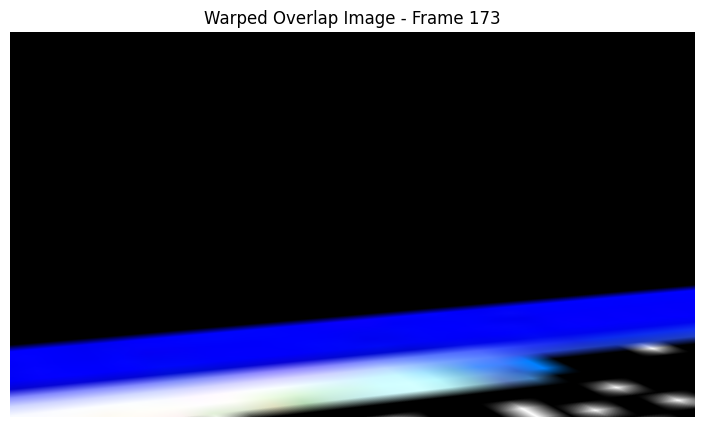

Iteration:  24%|██▍       | 108/450 [00:19<01:00,  5.66it/s]

Normalized Homography matrix for frame 142:
[[ 1.2798780e-01  5.6288850e-02  4.7788700e+01]
 [ 4.2459562e-02  5.3574115e-01 -5.0417715e+02]
 [ 2.1043390e-05  1.1654434e-02  1.0000000e+00]]


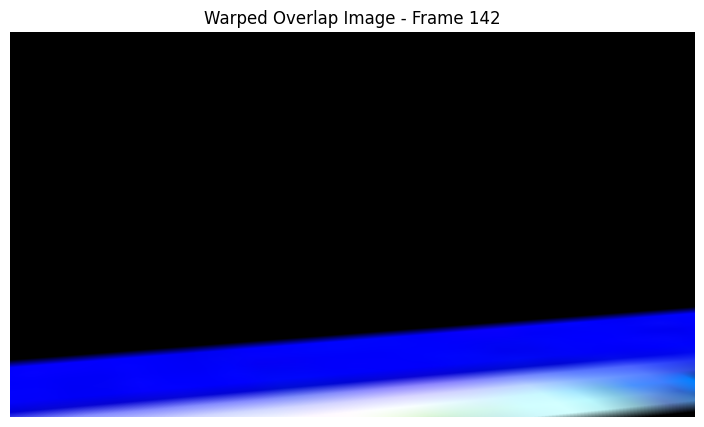

Iteration:  24%|██▍       | 109/450 [00:19<00:59,  5.71it/s]

Normalized Homography matrix for frame 347:
[[ 5.3611752e-02  1.2987639e-02  9.0479927e+01]
 [ 3.3734646e-02  2.8815785e-01 -1.9332539e+02]
 [-3.2586860e-05  5.4687066e-03  1.0000000e+00]]


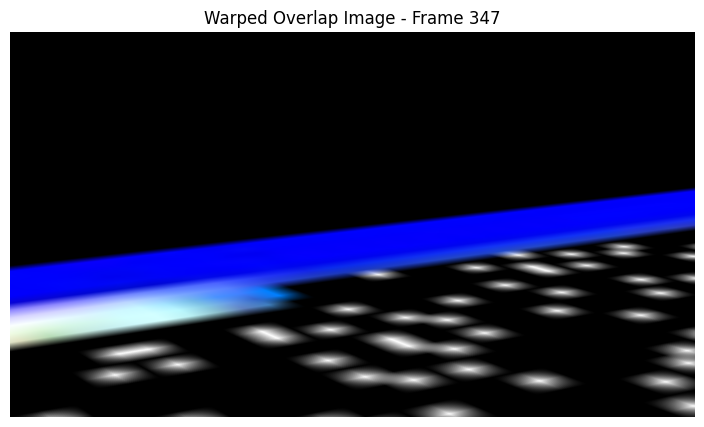

Iteration:  24%|██▍       | 110/450 [00:19<01:00,  5.64it/s]

Normalized Homography matrix for frame 197:
[[ 9.0001963e-02  1.7211104e-02  1.3650896e+02]
 [ 4.8162315e-02  4.5687750e-01 -3.8723199e+02]
 [-5.6190300e-05  8.7121325e-03  1.0000000e+00]]


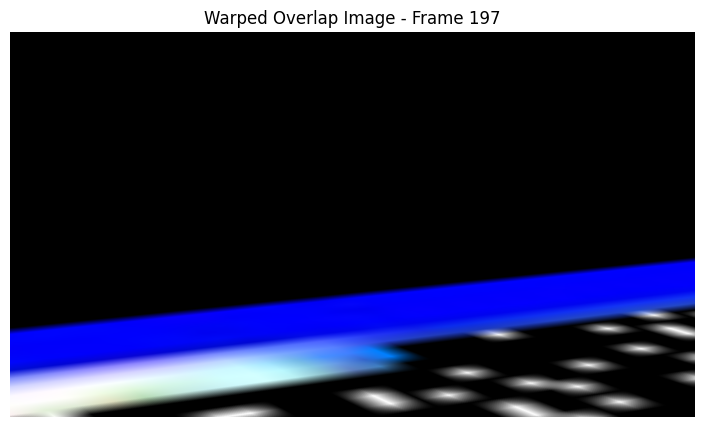

Iteration:  25%|██▍       | 111/450 [00:20<01:00,  5.60it/s]

Normalized Homography matrix for frame 413:
[[ 4.5747176e-02  8.9250132e-03  8.4338531e+01]
 [ 2.9125301e-02  2.4702430e-01 -1.6317761e+02]
 [-3.5432873e-05  4.5934385e-03  1.0000000e+00]]


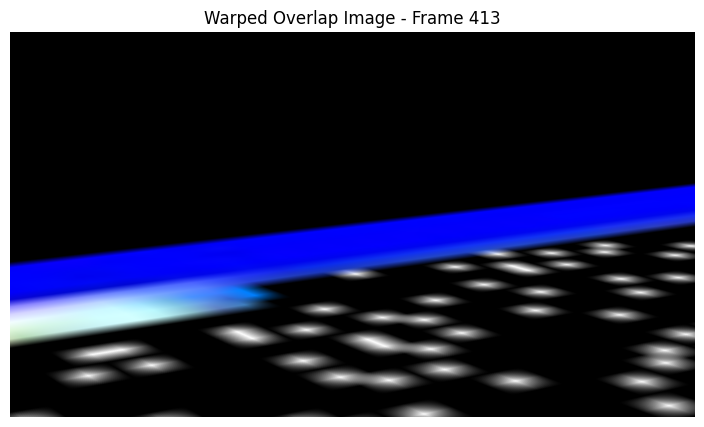

Iteration:  25%|██▍       | 112/450 [00:20<01:00,  5.55it/s]

Normalized Homography matrix for frame 16:
[[ 5.9091723e-01 -1.5555663e-02 -3.6337787e+02]
 [ 6.9989048e-02  2.5880075e+00 -1.8681919e+03]
 [ 1.0071847e-04  4.9650483e-02  1.0000000e+00]]


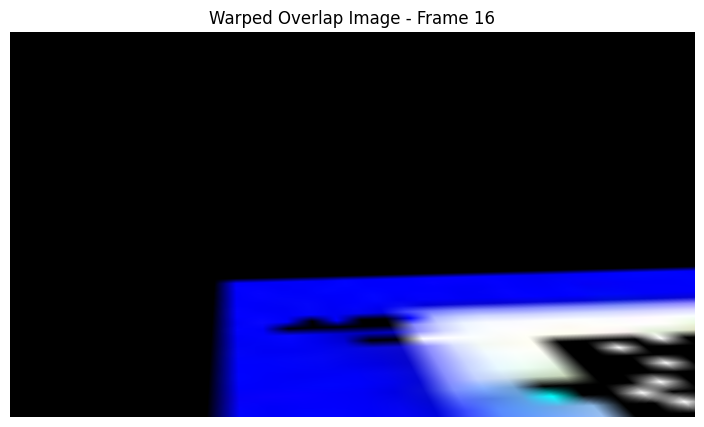

Iteration:  25%|██▌       | 113/450 [00:20<01:00,  5.59it/s]

Normalized Homography matrix for frame 341:
[[ 5.1613156e-02  6.8580811e-03  8.8643486e+01]
 [ 3.3210773e-02  2.7309451e-01 -1.8564072e+02]
 [-2.2245435e-05  5.1279142e-03  1.0000000e+00]]


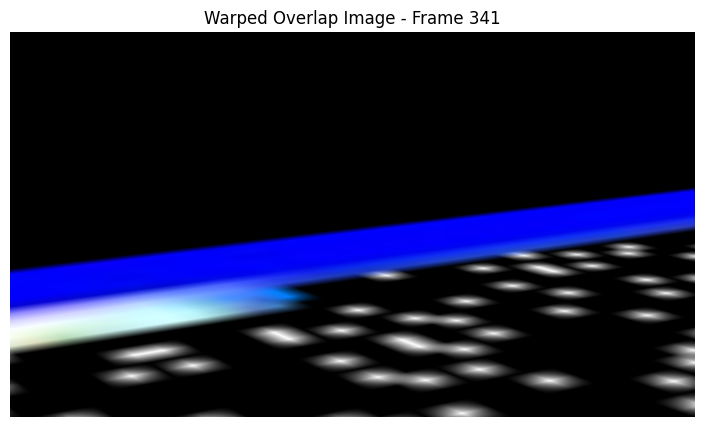

Iteration:  25%|██▌       | 114/450 [00:20<01:00,  5.53it/s]

Normalized Homography matrix for frame 241:
[[ 7.0752285e-02  1.6057832e-02  1.5275160e+02]
 [ 4.6457537e-02  3.9119673e-01 -3.0088828e+02]
 [-8.2933810e-05  7.2788619e-03  1.0000000e+00]]


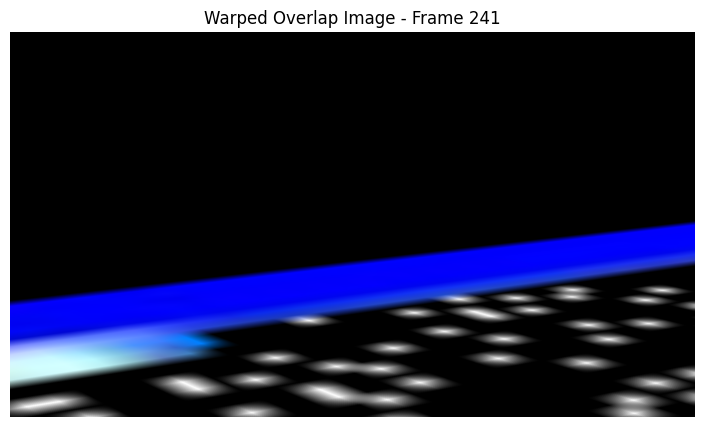

Iteration:  26%|██▌       | 115/450 [00:20<01:00,  5.54it/s]

Normalized Homography matrix for frame 146:
[[ 3.5767636e-01  2.6802957e-01 -1.6440042e+02]
 [ 4.7968119e-02  1.5135818e+00 -1.1885828e+03]
 [-4.4516441e-05  2.5703883e-02  1.0000000e+00]]


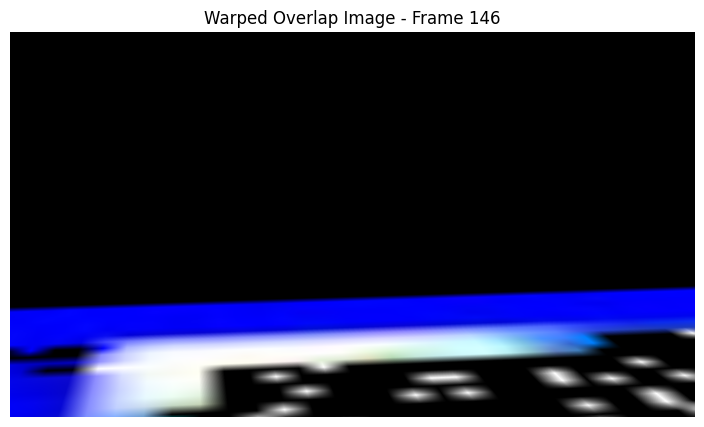

Iteration:  26%|██▌       | 116/450 [00:21<00:59,  5.57it/s]

Normalized Homography matrix for frame 350:
[[ 4.9408793e-02  4.3561854e-03  8.7494896e+01]
 [ 3.2136891e-02  2.6139343e-01 -1.7752554e+02]
 [-2.1404709e-05  4.8569036e-03  1.0000000e+00]]


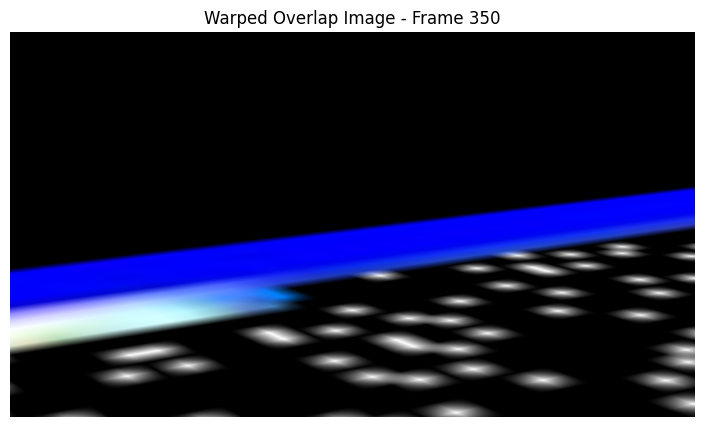

Iteration:  26%|██▌       | 117/450 [00:21<01:00,  5.54it/s]

Normalized Homography matrix for frame 445:
[[ 4.2832736e-02  5.0770687e-03  8.0604103e+01]
 [ 2.7356291e-02  2.2971188e-01 -1.5035216e+02]
 [-3.7271402e-05  4.2220140e-03  1.0000000e+00]]


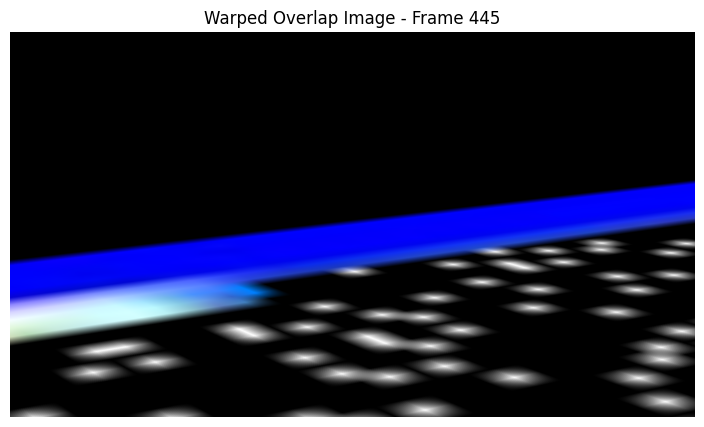

Iteration:  26%|██▌       | 118/450 [00:21<01:00,  5.53it/s]

Normalized Homography matrix for frame 386:
[[ 4.3478422e-02  1.8293955e-03  8.4454948e+01]
 [ 2.8450575e-02  2.3323849e-01 -1.5575703e+02]
 [-3.5931240e-05  4.3176524e-03  1.0000000e+00]]


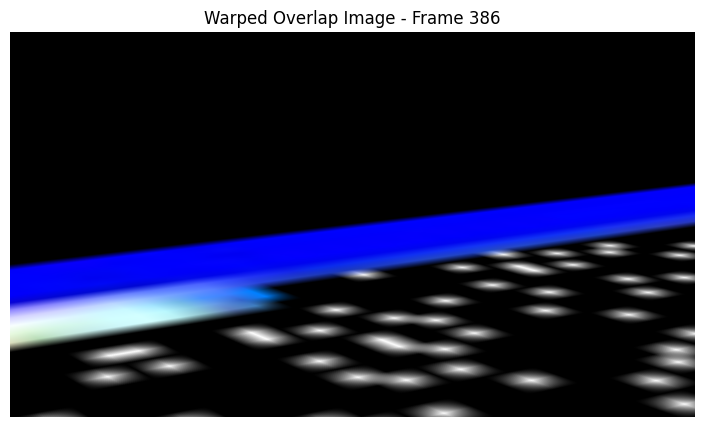

Iteration:  26%|██▋       | 119/450 [00:21<01:00,  5.51it/s]

Normalized Homography matrix for frame 152:
[[ 6.7338780e-02 -9.4432076e-03  1.8499249e+01]
 [ 2.0413276e-02  2.5026199e-01 -2.2718716e+02]
 [-1.2881906e-05  3.8586217e-03  1.0000000e+00]]


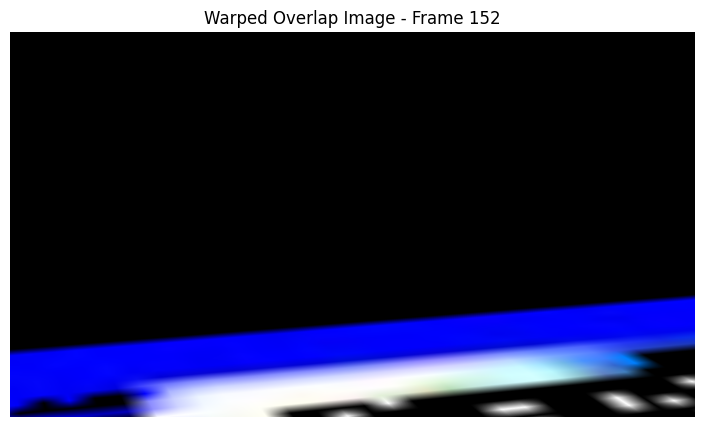

Iteration:  27%|██▋       | 120/450 [00:21<00:59,  5.55it/s]

Normalized Homography matrix for frame 284:
[[ 3.6059488e-02  6.5497356e-03  1.0091242e+02]
 [ 2.7045172e-02  2.0512219e-01 -1.4213101e+02]
 [-3.3098280e-05  3.8141578e-03  1.0000000e+00]]


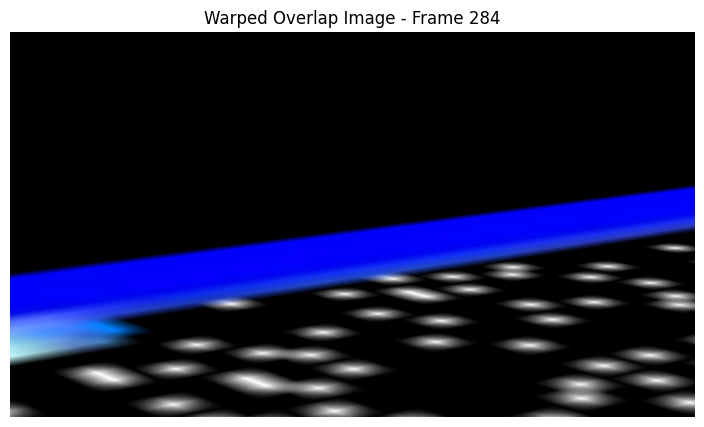

Iteration:  27%|██▋       | 121/450 [00:21<00:59,  5.51it/s]

Normalized Homography matrix for frame 270:
[[ 4.36417237e-02  6.34870352e-03  1.20971344e+02]
 [ 3.28261107e-02  2.49651000e-01 -1.81511368e+02]
 [-4.35641523e-05  4.65276279e-03  1.00000000e+00]]


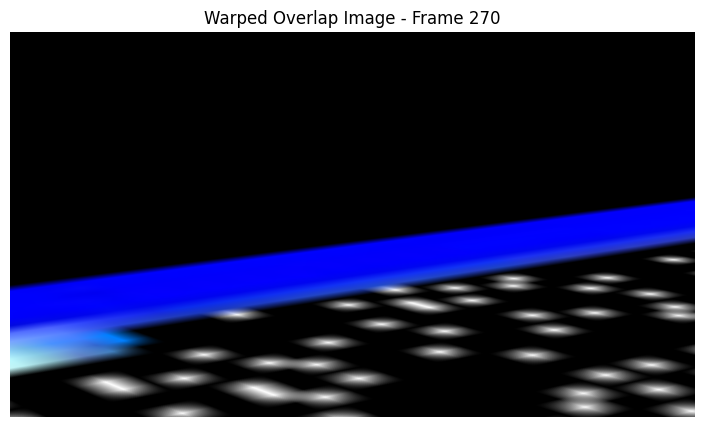

Iteration:  27%|██▋       | 122/450 [00:22<00:59,  5.49it/s]

Normalized Homography matrix for frame 319:
[[ 5.1458061e-02  6.0098707e-03  8.8813469e+01]
 [ 3.2103635e-02  2.7551213e-01 -1.8648430e+02]
 [-3.7598216e-05  5.1247110e-03  1.0000000e+00]]


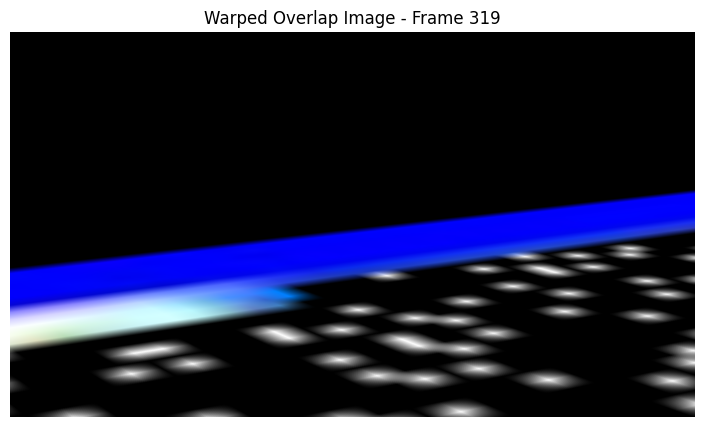

Iteration:  27%|██▋       | 123/450 [00:22<00:59,  5.51it/s]

Normalized Homography matrix for frame 112:
[[ 2.1614194e-01  9.8672889e-02  3.7037403e+01]
 [ 6.4613611e-02  8.9567059e-01 -8.3374731e+02]
 [ 3.1690470e-05  2.0096665e-02  1.0000000e+00]]


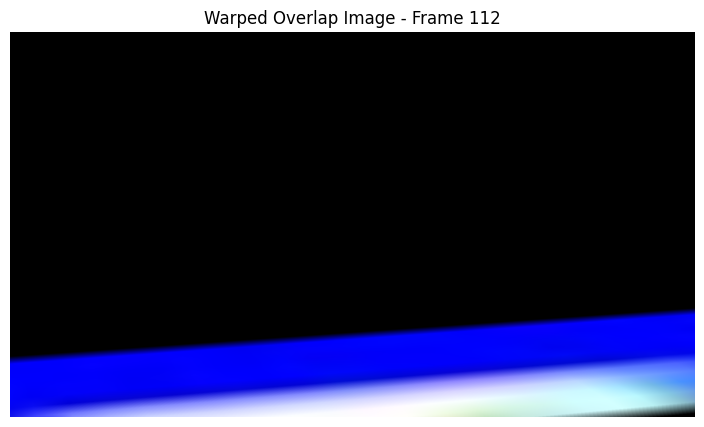

Iteration:  28%|██▊       | 124/450 [00:22<00:59,  5.52it/s]

Normalized Homography matrix for frame 207:
[[ 1.13161996e-01  2.50835605e-02  1.86840790e+02]
 [ 6.78722933e-02  5.87155581e-01 -4.85694000e+02]
 [-6.09332237e-05  1.14111658e-02  1.00000000e+00]]


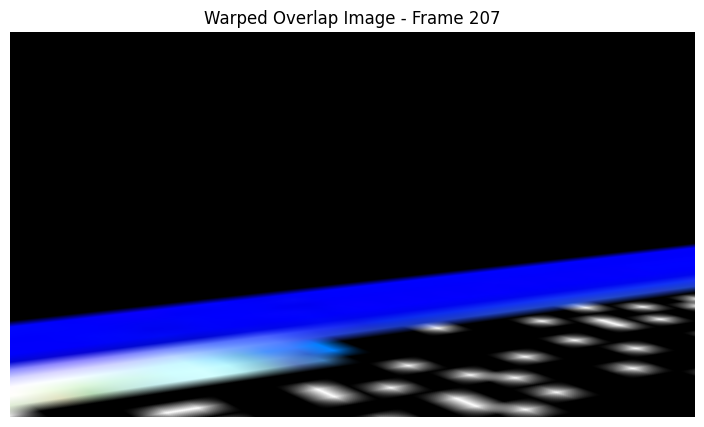

Iteration:  28%|██▊       | 125/450 [00:22<00:58,  5.55it/s]

Normalized Homography matrix for frame 165:
[[ 6.6173144e-02 -5.3317985e-03  5.6390564e+01]
 [ 2.7179003e-02  2.8756198e-01 -2.6491467e+02]
 [ 3.8844869e-06  4.9651274e-03  1.0000000e+00]]


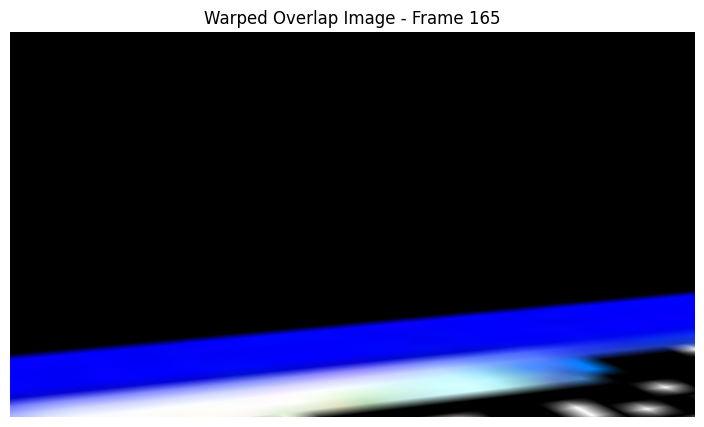

Iteration:  28%|██▊       | 126/450 [00:22<00:57,  5.61it/s]

Normalized Homography matrix for frame 367:
[[ 4.7515806e-02  1.0079719e-02  8.5656136e+01]
 [ 3.0795600e-02  2.5377664e-01 -1.6934377e+02]
 [-2.5675274e-05  4.7812145e-03  1.0000000e+00]]


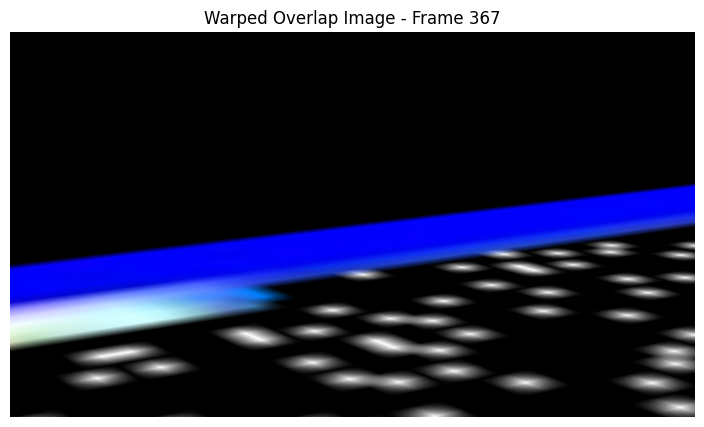

Iteration:  28%|██▊       | 127/450 [00:22<00:58,  5.56it/s]

Normalized Homography matrix for frame 365:
[[ 4.6450581e-02  8.3941761e-03  8.4621391e+01]
 [ 2.9868348e-02  2.4864781e-01 -1.6553970e+02]
 [-3.0644533e-05  4.6596536e-03  1.0000000e+00]]


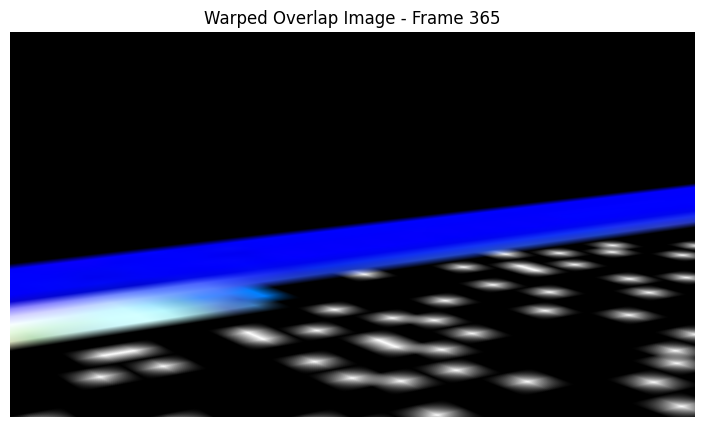

Iteration:  28%|██▊       | 128/450 [00:23<00:58,  5.54it/s]

Normalized Homography matrix for frame 49:
[[ 1.6117141e-01  1.1184302e-03 -4.5082741e+01]
 [ 3.0322213e-02  6.9964731e-01 -5.2667706e+02]
 [-4.3922992e-05  1.4131946e-02  1.0000000e+00]]


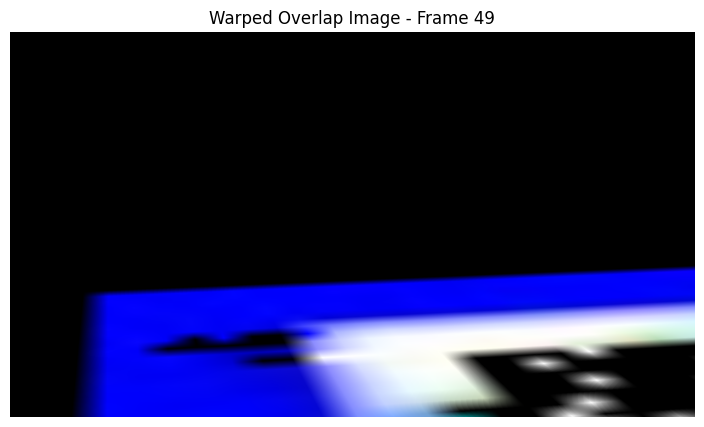

Iteration:  29%|██▊       | 129/450 [00:23<00:57,  5.57it/s]

Normalized Homography matrix for frame 123:
[[ 2.58922189e-01  1.30462050e-01  5.23077469e+01]
 [ 8.02567303e-02  1.06903493e+00 -1.00565985e+03]
 [ 4.33383102e-05  2.45741364e-02  1.00000000e+00]]


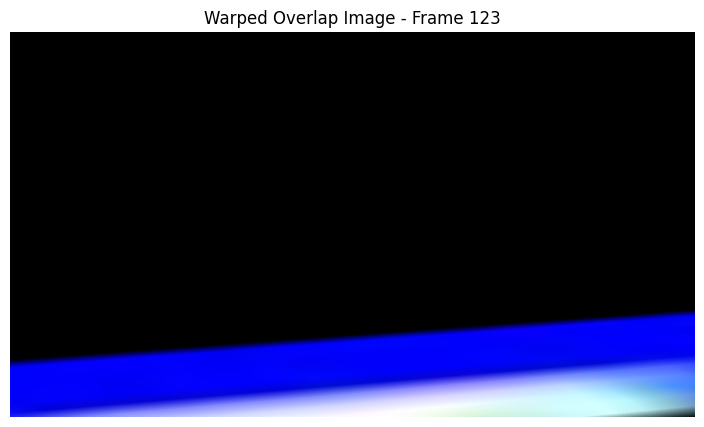

Iteration:  29%|██▉       | 130/450 [00:23<00:57,  5.60it/s]

Normalized Homography matrix for frame 78:
[[ 1.3603480e-01  7.0772022e-02 -4.9279186e+01]
 [ 3.2084510e-02  5.2833730e-01 -4.4770615e+02]
 [ 2.3563264e-04  1.0045553e-02  1.0000000e+00]]


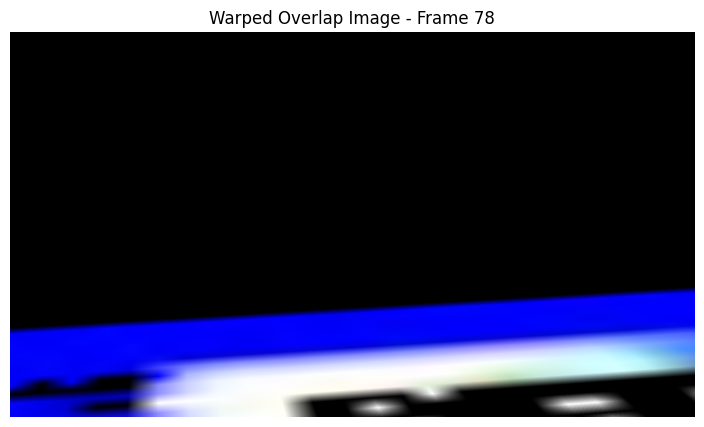

Iteration:  29%|██▉       | 131/450 [00:23<00:56,  5.62it/s]

Normalized Homography matrix for frame 54:
[[ 1.2046861e-01 -6.2355641e-03 -1.7216427e+01]
 [ 2.5435509e-02  5.4697198e-01 -4.1893451e+02]
 [-2.8839664e-05  1.0718178e-02  1.0000000e+00]]


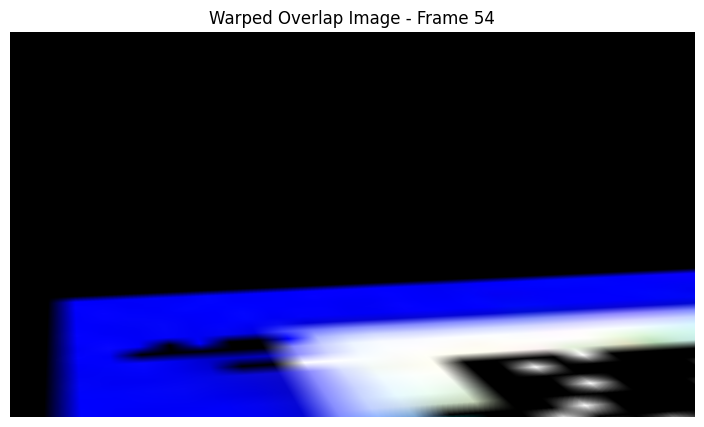

Iteration:  29%|██▉       | 132/450 [00:23<00:56,  5.60it/s]

Normalized Homography matrix for frame 411:
[[ 4.4770423e-02  4.5547453e-03  8.5529404e+01]
 [ 2.8789587e-02  2.4214694e-01 -1.6065778e+02]
 [-4.3095584e-05  4.5127748e-03  1.0000000e+00]]


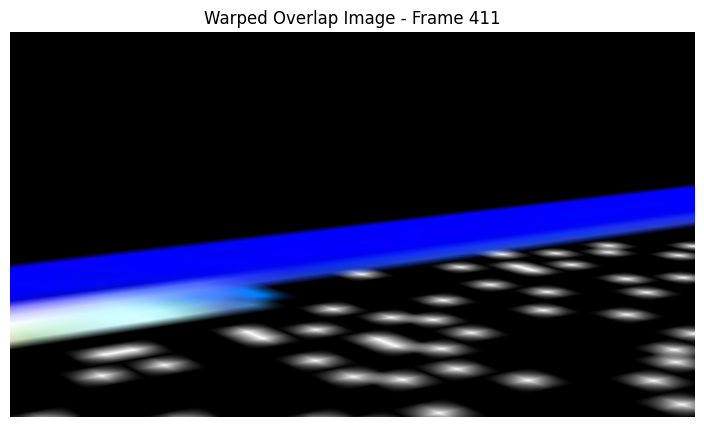

Iteration:  30%|██▉       | 133/450 [00:24<01:03,  4.99it/s]

Normalized Homography matrix for frame 420:
[[ 4.4595651e-02  7.7256863e-03  8.3499985e+01]
 [ 2.8469011e-02  2.3985124e-01 -1.5803979e+02]
 [-4.2648237e-05  4.5002932e-03  1.0000000e+00]]


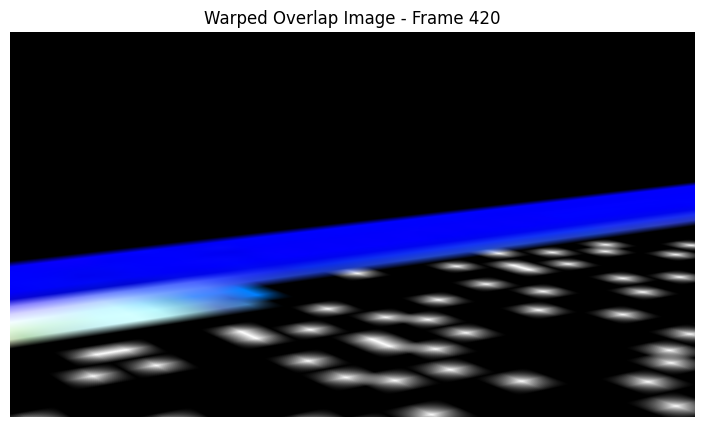

Iteration:  30%|██▉       | 134/450 [00:24<01:01,  5.12it/s]

Normalized Homography matrix for frame 312:
[[ 4.6946496e-02  4.1872654e-03  8.7523186e+01]
 [ 2.9644988e-02  2.5237229e-01 -1.7158859e+02]
 [-3.8594397e-05  4.6347342e-03  1.0000000e+00]]


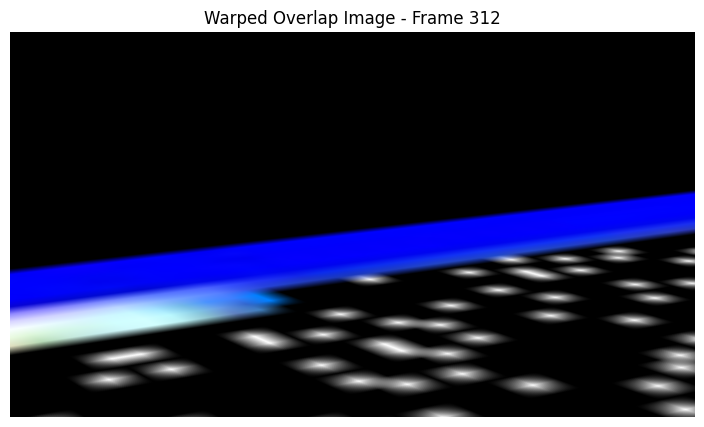

Iteration:  30%|███       | 135/450 [00:24<01:00,  5.24it/s]

Normalized Homography matrix for frame 53:
[[ 1.1101269e-01 -6.1032162e-03 -1.7377871e+01]
 [ 2.2356762e-02  4.8839477e-01 -3.7296655e+02]
 [-5.1847324e-05  9.5267305e-03  1.0000000e+00]]


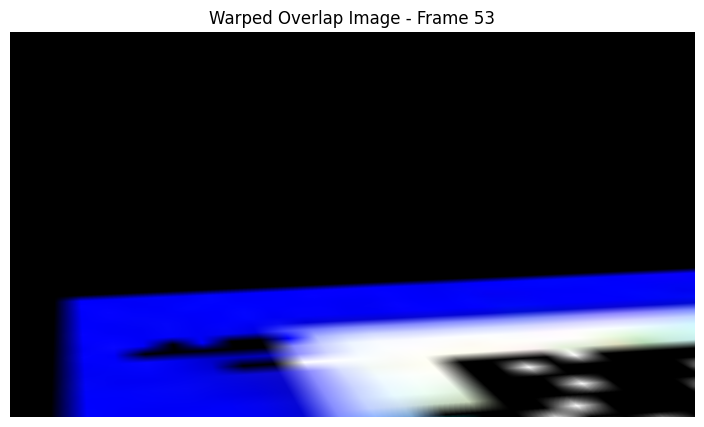

Iteration:  30%|███       | 136/450 [00:24<00:58,  5.34it/s]

Normalized Homography matrix for frame 141:
[[ 1.7262799e-01  8.7758347e-02  5.0841801e+01]
 [ 5.8138315e-02  7.0403117e-01 -6.6698871e+02]
 [ 7.1384209e-05  1.5966693e-02  1.0000000e+00]]


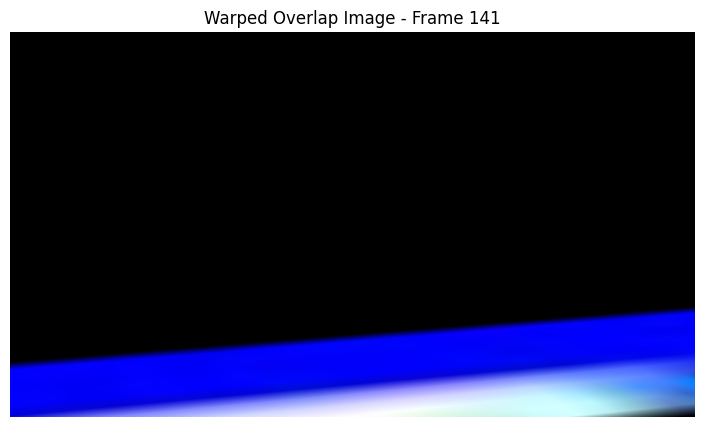

Iteration:  30%|███       | 137/450 [00:24<00:57,  5.44it/s]

Normalized Homography matrix for frame 65:
[[ 9.0593711e-02  2.4770468e-05 -7.7489060e-01]
 [ 2.2553734e-02  4.1577092e-01 -3.3323169e+02]
 [ 2.3730800e-05  7.8331484e-03  1.0000000e+00]]


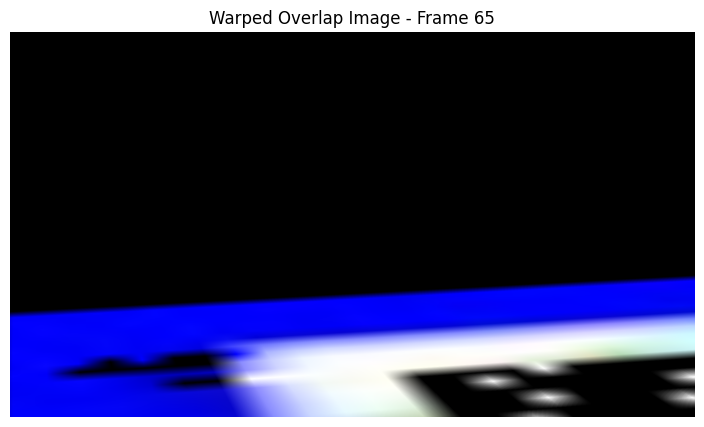

Iteration:  31%|███       | 138/450 [00:25<00:56,  5.51it/s]

Normalized Homography matrix for frame 255:
[[ 5.6160197e-02  1.1515865e-02  1.3724515e+02]
 [ 3.9523683e-02  3.1538165e-01 -2.3810083e+02]
 [-5.6454784e-05  5.8597620e-03  1.0000000e+00]]


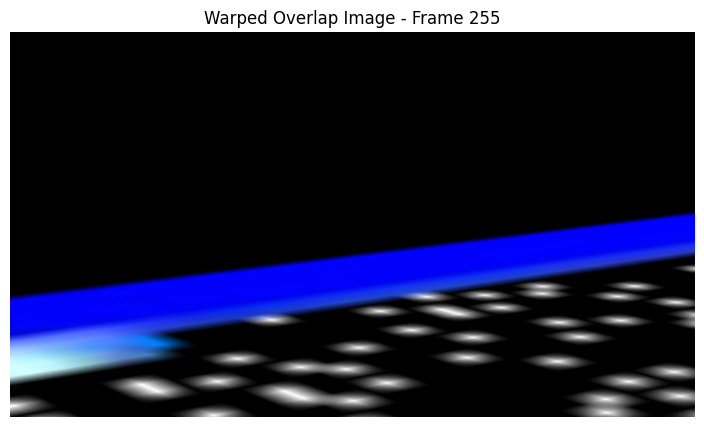

Iteration:  31%|███       | 139/450 [00:25<00:56,  5.52it/s]

Normalized Homography matrix for frame 225:
[[ 9.2254363e-02  2.2154229e-02  1.7570378e+02]
 [ 5.8060091e-02  4.9822542e-01 -3.9490512e+02]
 [-8.9495443e-05  9.4603905e-03  1.0000000e+00]]


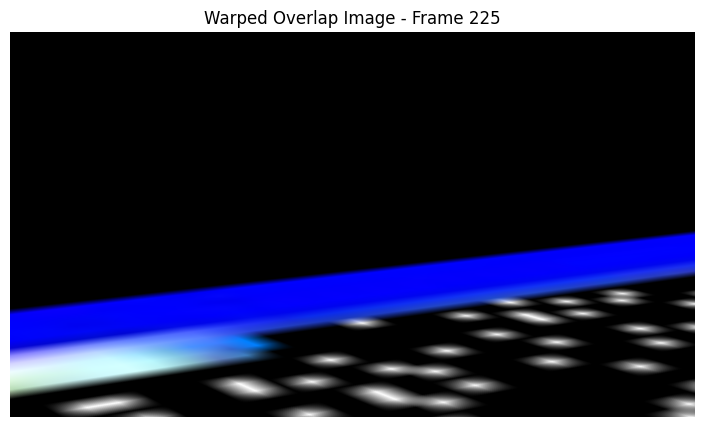

Iteration:  31%|███       | 140/450 [00:25<00:55,  5.54it/s]

Normalized Homography matrix for frame 66:
[[ 8.8892363e-02  1.7877060e-03 -1.2581582e+00]
 [ 2.1054048e-02  4.0910378e-01 -3.2848746e+02]
 [ 8.9446730e-06  7.7018947e-03  1.0000000e+00]]


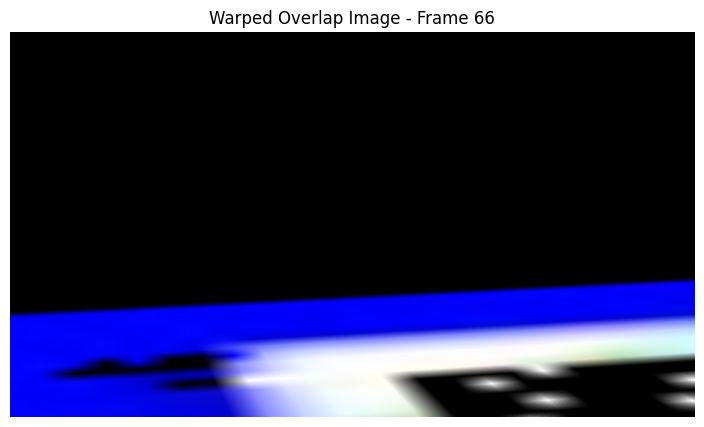

Iteration:  31%|███▏      | 141/450 [00:25<00:55,  5.58it/s]

Normalized Homography matrix for frame 273:
[[ 4.2692009e-02  9.1955131e-03  1.1903980e+02]
 [ 3.2733280e-02  2.4400070e-01 -1.7617912e+02]
 [-3.5830726e-05  4.6189311e-03  1.0000000e+00]]


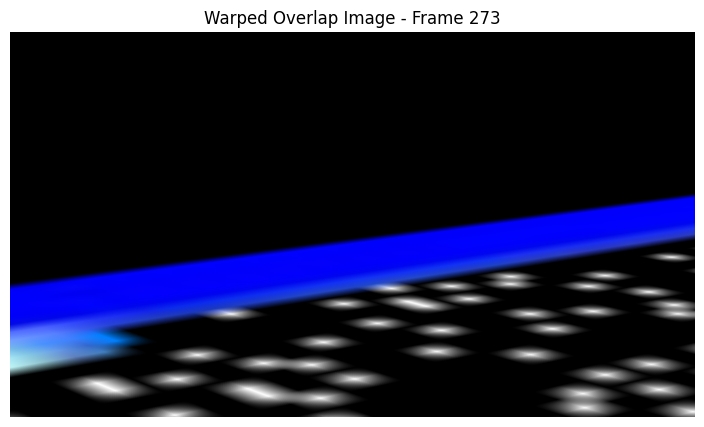

Iteration:  32%|███▏      | 142/450 [00:25<00:55,  5.53it/s]

Normalized Homography matrix for frame 307:
[[ 4.6181206e-02  4.3376507e-03  9.2980927e+01]
 [ 3.0521570e-02  2.5038686e-01 -1.7250917e+02]
 [-3.6068748e-05  4.6809777e-03  1.0000000e+00]]


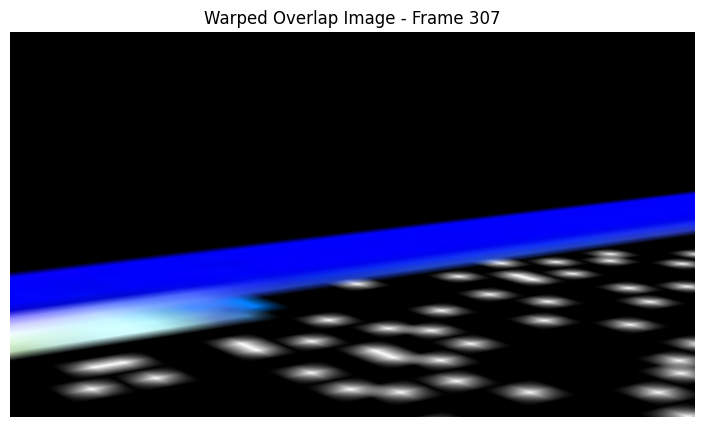

Iteration:  32%|███▏      | 143/450 [00:25<00:55,  5.54it/s]

Normalized Homography matrix for frame 174:
[[ 7.5027645e-02  8.1490241e-03  7.4102249e+01]
 [ 3.2071028e-02  3.3976293e-01 -3.0794876e+02]
 [-1.6897347e-05  6.3218731e-03  1.0000000e+00]]


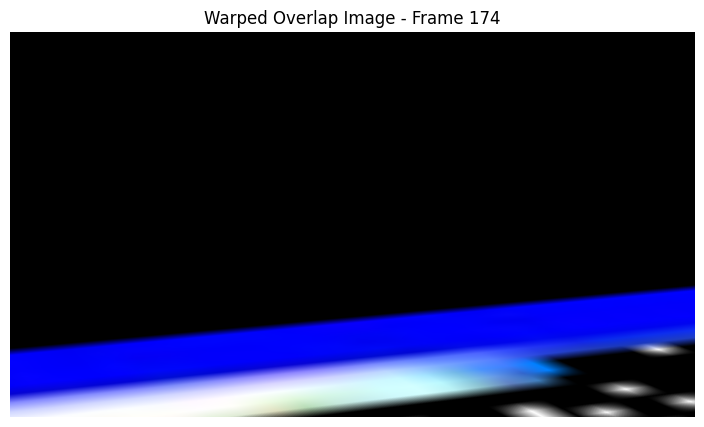

Iteration:  32%|███▏      | 144/450 [00:26<00:54,  5.62it/s]

Normalized Homography matrix for frame 205:
[[ 1.2521958e-01  3.8528565e-02  2.0176614e+02]
 [ 7.3293343e-02  6.5028214e-01 -5.4006805e+02]
 [-9.3751529e-05  1.3029864e-02  1.0000000e+00]]


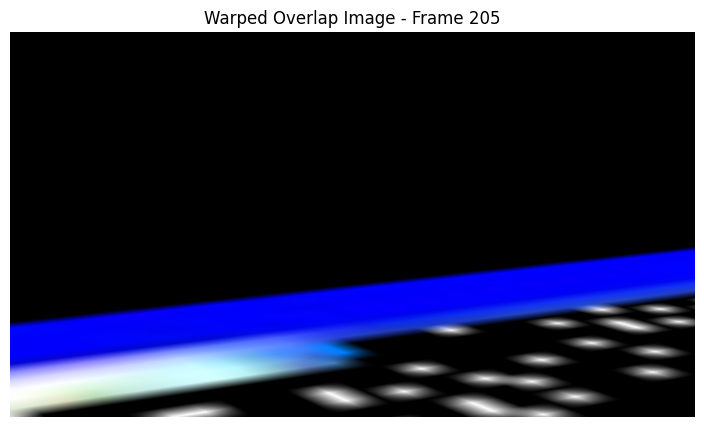

Iteration:  32%|███▏      | 145/450 [00:26<00:53,  5.66it/s]

Normalized Homography matrix for frame 440:
[[ 4.4977922e-02  8.4366584e-03  8.3710831e+01]
 [ 2.9213585e-02  2.4288115e-01 -1.5936133e+02]
 [-3.1281361e-05  4.5628729e-03  1.0000000e+00]]


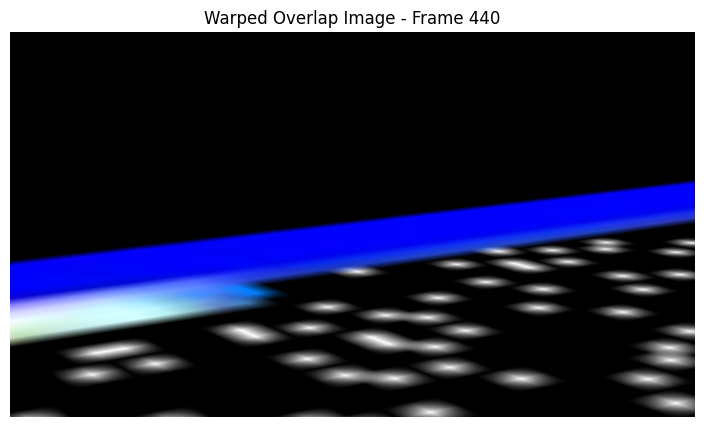

Iteration:  32%|███▏      | 146/450 [00:26<00:54,  5.60it/s]

Normalized Homography matrix for frame 248:
[[ 6.5299332e-02  1.6682072e-02  1.4969115e+02]
 [ 4.6294164e-02  3.5986841e-01 -2.7669510e+02]
 [-4.5343149e-05  6.8117091e-03  1.0000000e+00]]


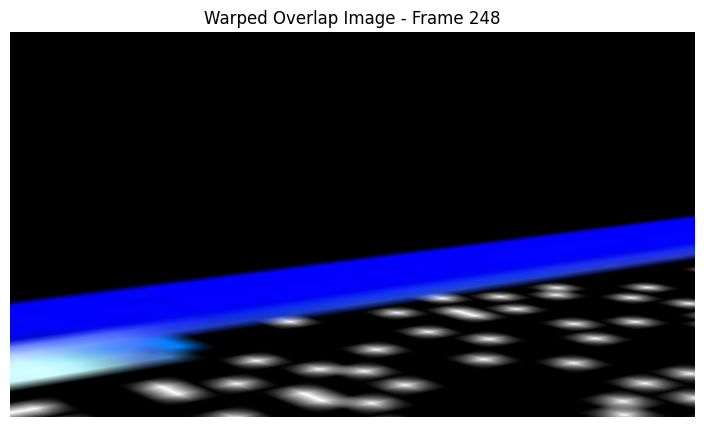

Iteration:  33%|███▎      | 147/450 [00:26<00:54,  5.57it/s]

Normalized Homography matrix for frame 444:
[[ 4.3088324e-02  6.8920921e-03  7.9901306e+01]
 [ 2.7332617e-02  2.3191339e-01 -1.5165331e+02]
 [-3.0510799e-05  4.2376420e-03  1.0000000e+00]]


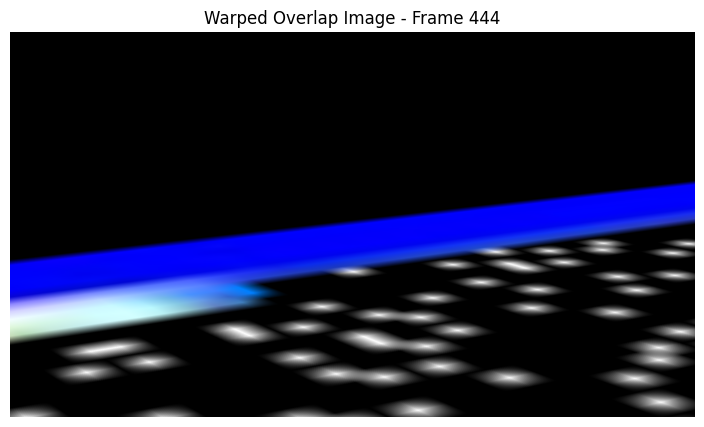

Iteration:  33%|███▎      | 148/450 [00:26<00:54,  5.55it/s]

Normalized Homography matrix for frame 446:
[[ 4.2334866e-02  4.2585582e-03  8.1824791e+01]
 [ 2.7095364e-02  2.3188312e-01 -1.5121706e+02]
 [-3.4684301e-05  4.2365878e-03  1.0000000e+00]]


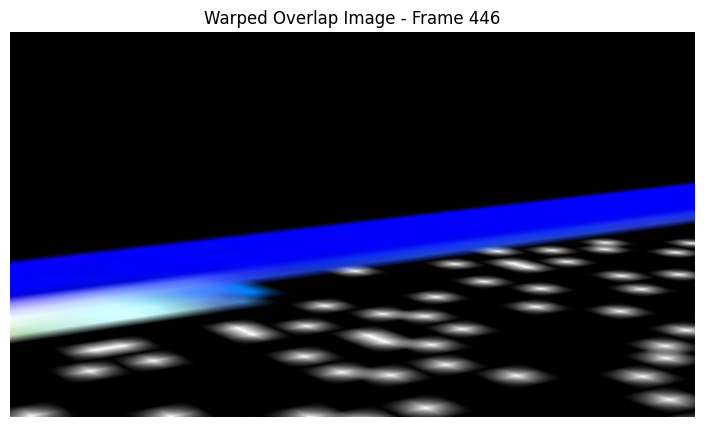

Iteration:  33%|███▎      | 149/450 [00:27<00:54,  5.51it/s]

Normalized Homography matrix for frame 159:
[[ 7.5423829e-02 -4.2931158e-03  1.8937225e+01]
 [ 2.3643820e-02  2.6977861e-01 -2.4479440e+02]
 [-1.7264081e-05  4.3911291e-03  1.0000000e+00]]


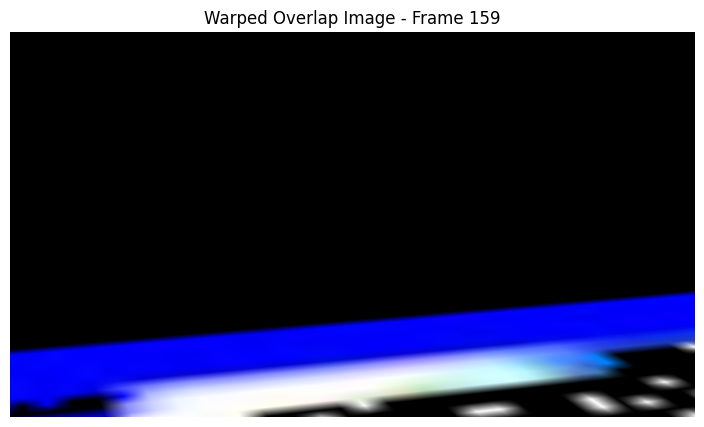

Iteration:  33%|███▎      | 150/450 [00:27<00:53,  5.57it/s]

Normalized Homography matrix for frame 42:
[[ 1.3335259e-01 -9.3994202e-04 -4.7882133e+01]
 [ 2.3262566e-02  5.7887250e-01 -4.3269019e+02]
 [ 2.9941391e-06  1.1058491e-02  1.0000000e+00]]


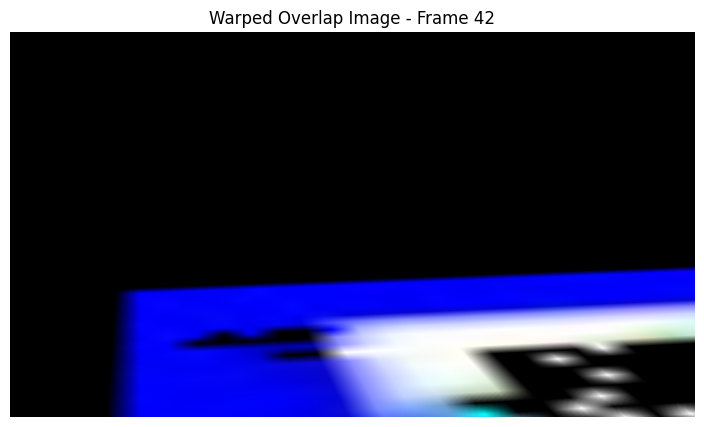

Iteration:  34%|███▎      | 151/450 [00:27<00:53,  5.60it/s]

Normalized Homography matrix for frame 210:
[[ 1.06587574e-01  2.41147615e-02  1.76536072e+02]
 [ 6.41884655e-02  5.56411028e-01 -4.55132812e+02]
 [-4.53613393e-05  1.05439276e-02  1.00000000e+00]]


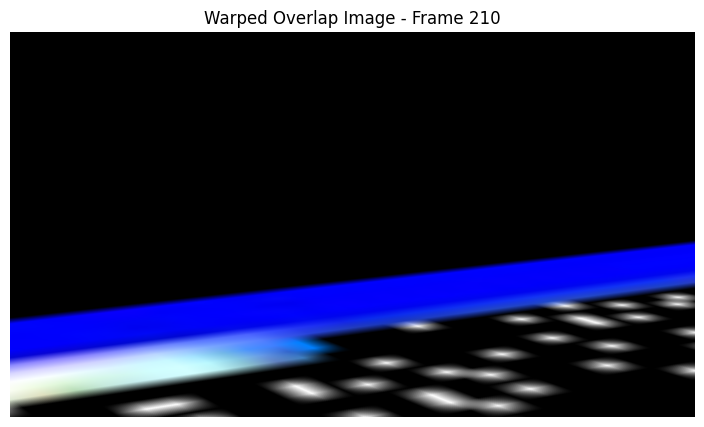

Iteration:  34%|███▍      | 152/450 [00:27<00:53,  5.61it/s]

Normalized Homography matrix for frame 196:
[[ 9.0394288e-02  1.6141504e-02  1.3522998e+02]
 [ 4.8952572e-02  4.5979095e-01 -3.9018127e+02]
 [-2.8493901e-05  8.6237984e-03  1.0000000e+00]]


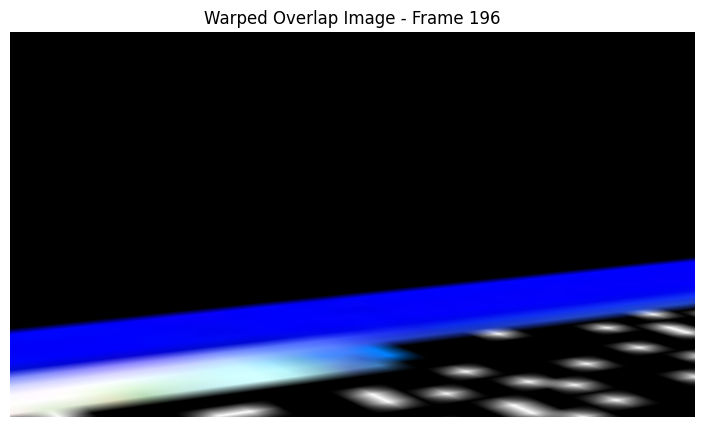

Iteration:  34%|███▍      | 153/450 [00:27<00:52,  5.64it/s]

Normalized Homography matrix for frame 38:
[[ 1.9248514e-01  4.0941862e-03 -8.0943451e+01]
 [ 3.0722076e-02  8.3696061e-01 -6.1968506e+02]
 [-8.9911473e-06  1.6636534e-02  1.0000000e+00]]


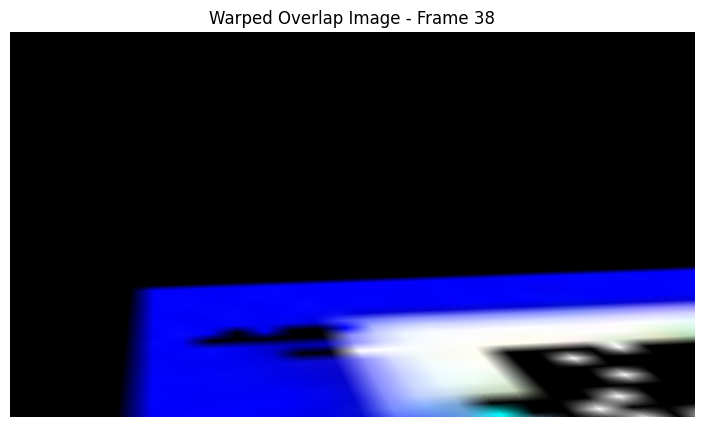

Iteration:  34%|███▍      | 154/450 [00:27<00:52,  5.65it/s]

Normalized Homography matrix for frame 280:
[[ 3.7555959e-02  5.2833706e-03  1.0846781e+02]
 [ 2.9362964e-02  2.1363112e-01 -1.5097081e+02]
 [-3.3139237e-05  4.0651863e-03  1.0000000e+00]]


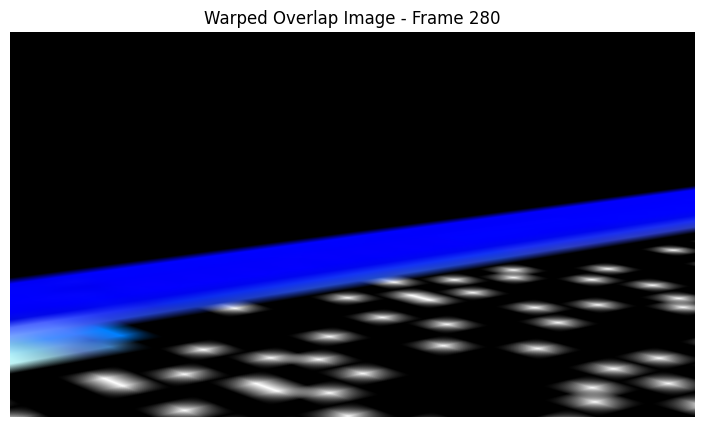

Iteration:  34%|███▍      | 155/450 [00:28<00:53,  5.52it/s]

Normalized Homography matrix for frame 206:
[[ 1.1813591e-01  3.0980375e-02  1.9273021e+02]
 [ 6.9502160e-02  6.1847413e-01 -5.1175885e+02]
 [-6.8748166e-05  1.2045537e-02  1.0000000e+00]]


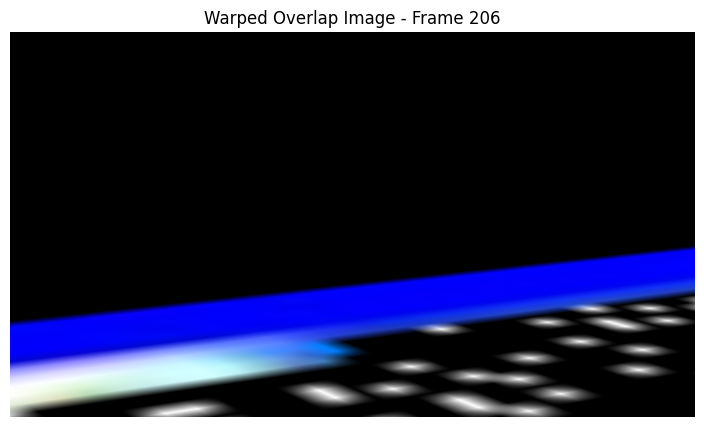

Iteration:  35%|███▍      | 156/450 [00:28<00:52,  5.57it/s]

Normalized Homography matrix for frame 168:
[[ 5.9237216e-02 -9.6041774e-03  6.4445877e+01]
 [ 2.6934739e-02  2.6991922e-01 -2.4990721e+02]
 [ 2.0938520e-05  4.5778425e-03  1.0000000e+00]]


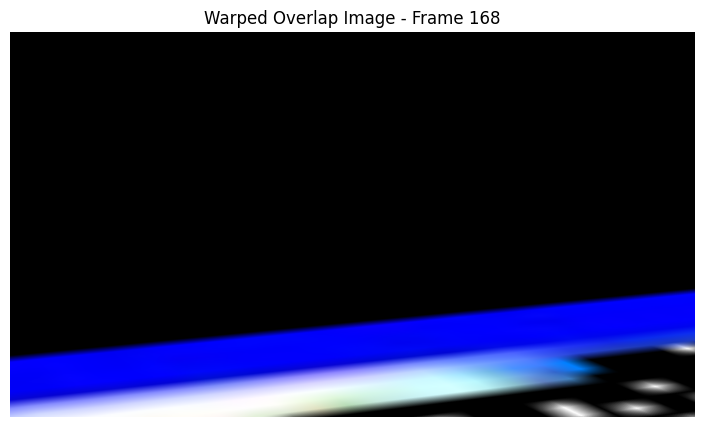

Iteration:  35%|███▍      | 157/450 [00:28<00:52,  5.61it/s]

Normalized Homography matrix for frame 267:
[[ 4.5392290e-02  5.4674163e-03  1.2608996e+02]
 [ 3.4991875e-02  2.5743508e-01 -1.9003664e+02]
 [-3.9828228e-05  4.8885420e-03  1.0000000e+00]]


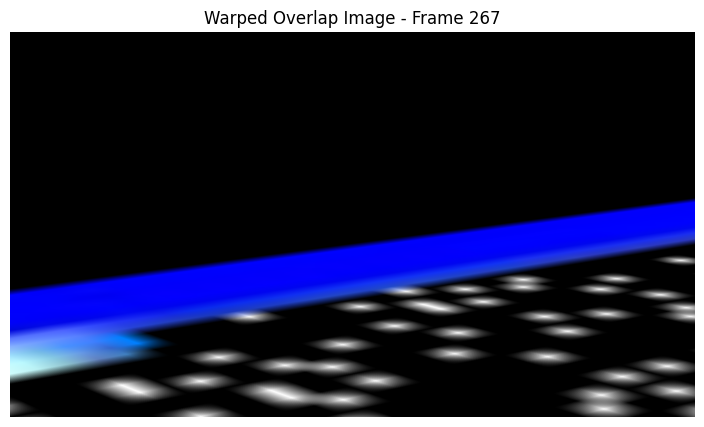

Iteration:  35%|███▌      | 158/450 [00:28<00:52,  5.61it/s]

Normalized Homography matrix for frame 403:
[[ 4.4434220e-02  2.3870612e-03  8.4846420e+01]
 [ 2.9810989e-02  2.3701248e-01 -1.5949998e+02]
 [-1.4846286e-05  4.3548536e-03  1.0000000e+00]]


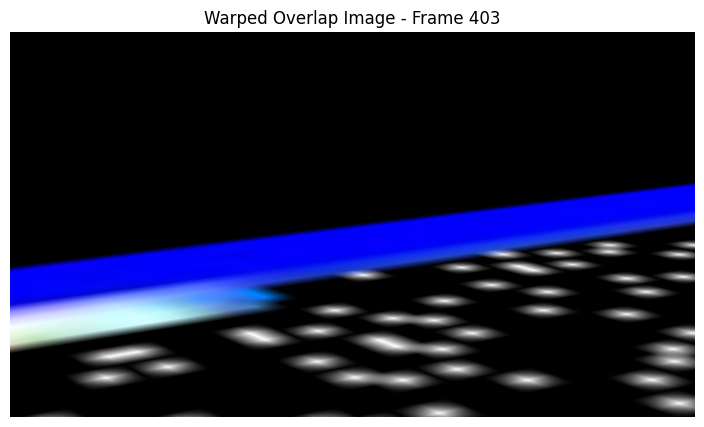

Iteration:  35%|███▌      | 159/450 [00:28<00:52,  5.57it/s]

Normalized Homography matrix for frame 51:
[[ 1.4178015e-01  1.2660960e-03 -3.4610970e+01]
 [ 2.6940489e-02  6.0764235e-01 -4.6091260e+02]
 [-6.0768722e-05  1.2204198e-02  1.0000000e+00]]


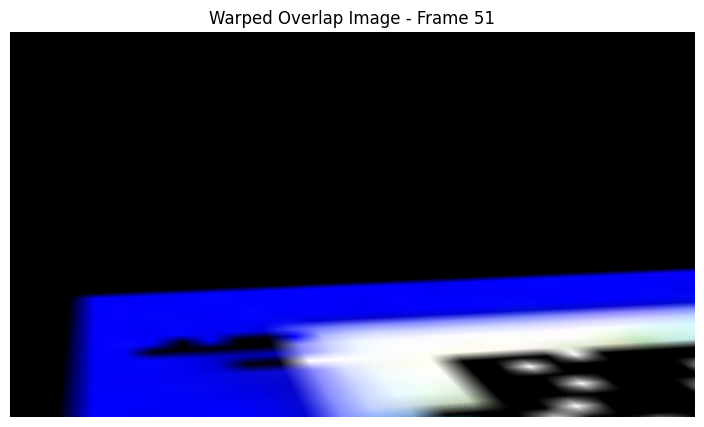

Iteration:  36%|███▌      | 160/450 [00:28<00:52,  5.54it/s]

Normalized Homography matrix for frame 401:
[[ 4.5301639e-02  5.5212877e-03  8.5406258e+01]
 [ 2.9359289e-02  2.4345104e-01 -1.6200488e+02]
 [-3.6576217e-05  4.5439587e-03  1.0000000e+00]]


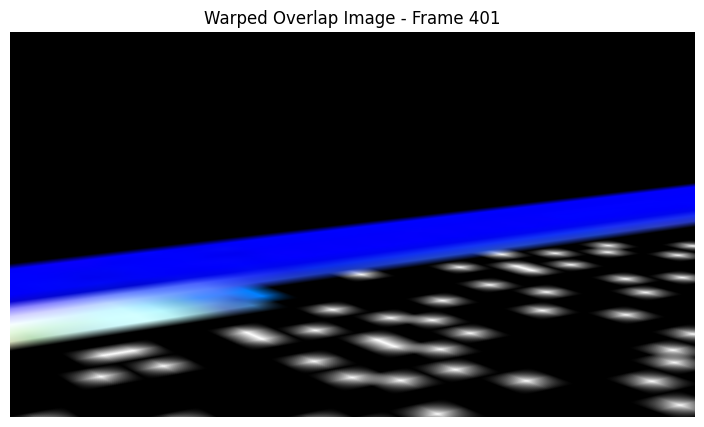

Iteration:  36%|███▌      | 161/450 [00:29<00:52,  5.53it/s]

Normalized Homography matrix for frame 17:
[[ 2.8173062e-01  2.0911177e-03 -1.8038660e+02]
 [ 2.9450553e-02  1.2545010e+00 -9.0529968e+02]
 [ 4.4258260e-05  2.3413368e-02  1.0000000e+00]]


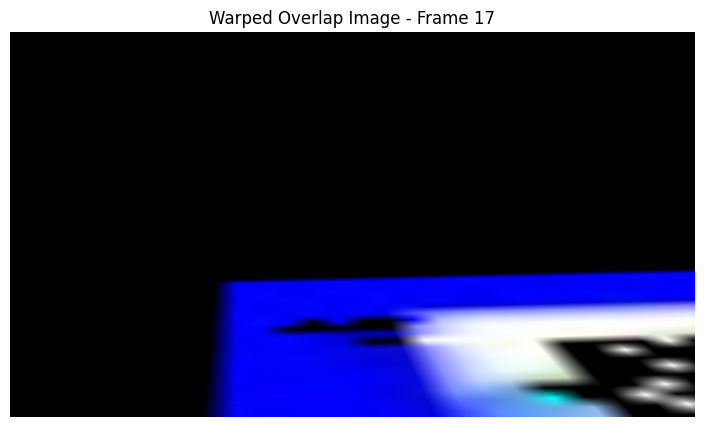

Iteration:  36%|███▌      | 162/450 [00:29<00:51,  5.57it/s]

Normalized Homography matrix for frame 238:
[[ 7.8752771e-02  1.8848799e-02  1.6703795e+02]
 [ 5.2408911e-02  4.3479231e-01 -3.3648825e+02]
 [-8.7589375e-05  8.2773268e-03  1.0000000e+00]]


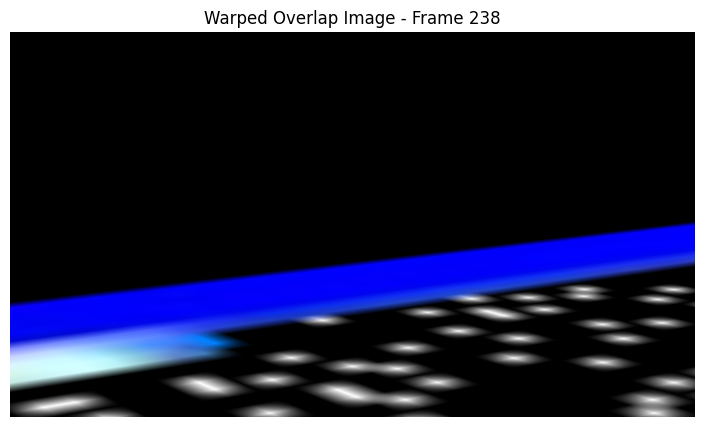

Iteration:  36%|███▌      | 163/450 [00:29<00:51,  5.61it/s]

Normalized Homography matrix for frame 421:
[[ 4.3824550e-02  2.9350370e-03  8.5875092e+01]
 [ 2.8873291e-02  2.3838045e-01 -1.5806305e+02]
 [-3.3846547e-05  4.4307685e-03  1.0000000e+00]]


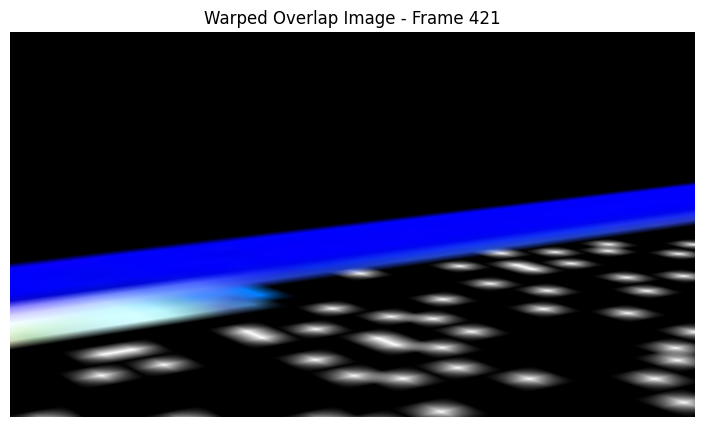

Iteration:  36%|███▋      | 164/450 [00:29<00:51,  5.57it/s]

Normalized Homography matrix for frame 431:
[[ 4.2463928e-02  2.8370775e-03  8.3387665e+01]
 [ 2.8136006e-02  2.2927850e-01 -1.5158887e+02]
 [-3.0375957e-05  4.2659529e-03  1.0000000e+00]]


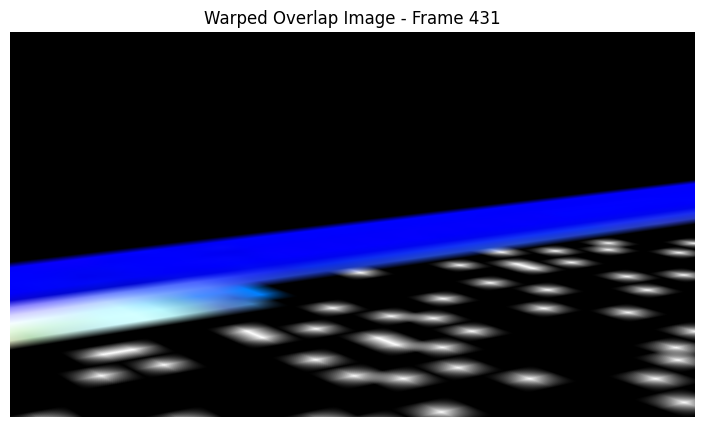

Iteration:  37%|███▋      | 165/450 [00:29<00:51,  5.52it/s]

Normalized Homography matrix for frame 69:
[[ 1.3893178e-01  2.9388320e-02 -1.8579212e+01]
 [ 3.3369787e-02  6.0687691e-01 -4.9152612e+02]
 [ 6.1859319e-05  1.2259615e-02  1.0000000e+00]]


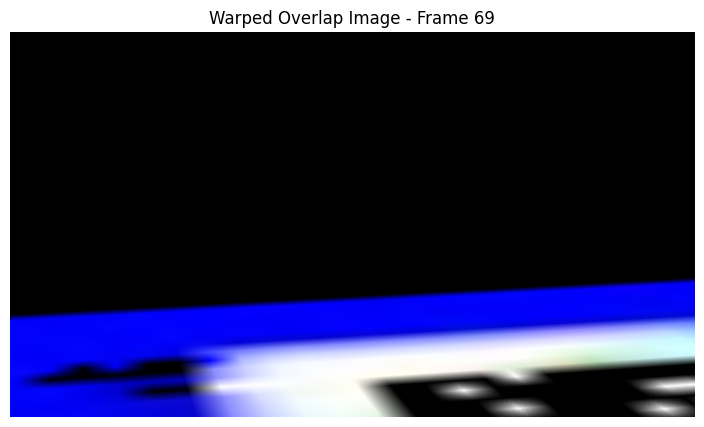

Iteration:  37%|███▋      | 166/450 [00:30<00:51,  5.55it/s]

Normalized Homography matrix for frame 384:
[[ 4.6831287e-02  9.2611350e-03  8.6365669e+01]
 [ 2.9921364e-02  2.5367922e-01 -1.6818280e+02]
 [-3.7316640e-05  4.7588209e-03  1.0000000e+00]]


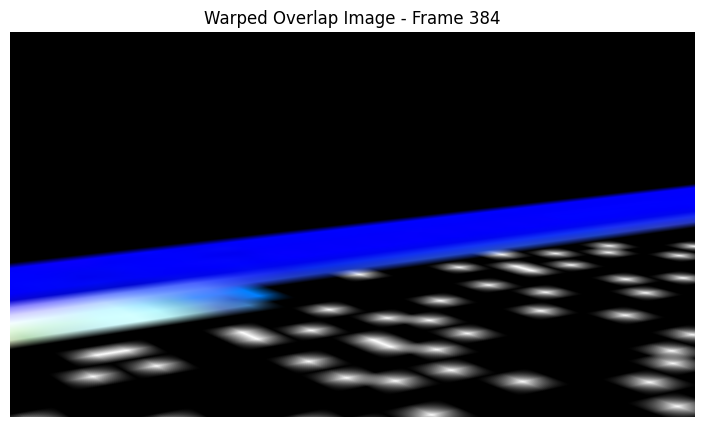

Iteration:  37%|███▋      | 167/450 [00:30<00:51,  5.54it/s]

Normalized Homography matrix for frame 282:
[[ 3.76628600e-02  7.77467573e-03  1.04506516e+02]
 [ 2.81783715e-02  2.13864908e-01 -1.49118347e+02]
 [-3.98450356e-05  4.00384422e-03  1.00000000e+00]]


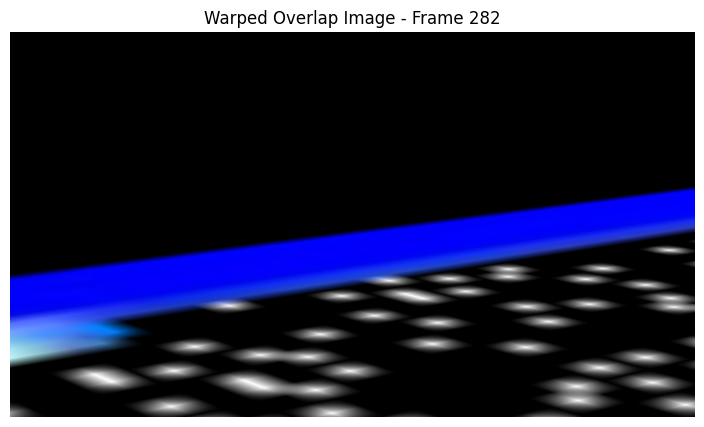

Iteration:  37%|███▋      | 168/450 [00:30<00:52,  5.35it/s]

Normalized Homography matrix for frame 222:
[[ 9.4288923e-02  1.8526321e-02  1.7733003e+02]
 [ 6.0470950e-02  5.0001961e-01 -4.0120996e+02]
 [-7.3483381e-05  9.5794117e-03  1.0000000e+00]]


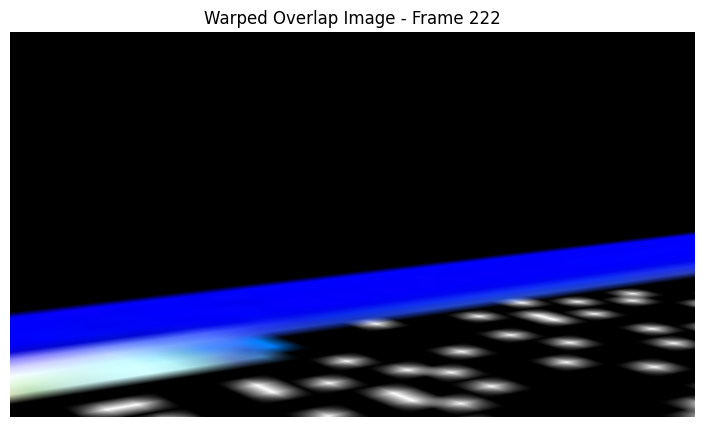

Iteration:  38%|███▊      | 169/450 [00:30<00:51,  5.41it/s]

Normalized Homography matrix for frame 404:
[[ 4.7292359e-02  8.2391836e-03  8.8784782e+01]
 [ 3.0886587e-02  2.5705272e-01 -1.7088681e+02]
 [-3.4270735e-05  4.8542339e-03  1.0000000e+00]]


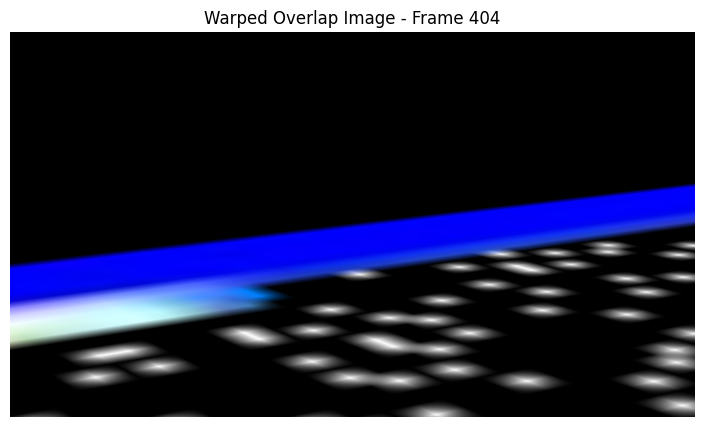

Iteration:  38%|███▊      | 170/450 [00:30<00:51,  5.41it/s]

Normalized Homography matrix for frame 86:
[[ 9.75152403e-02  4.46955524e-02 -2.03357086e+01]
 [ 2.36904342e-02  3.77707601e-01 -3.25673828e+02]
 [ 1.17955766e-04  6.99644629e-03  1.00000000e+00]]


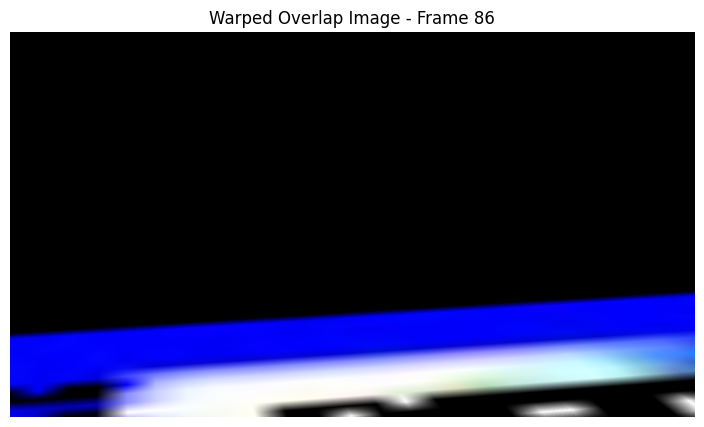

Iteration:  38%|███▊      | 171/450 [00:30<00:50,  5.47it/s]

Normalized Homography matrix for frame 175:
[[ 7.0062220e-02  6.2651979e-03  7.3057739e+01]
 [ 2.9965503e-02  3.2694316e-01 -2.9359445e+02]
 [-9.6828953e-06  5.8596865e-03  1.0000000e+00]]


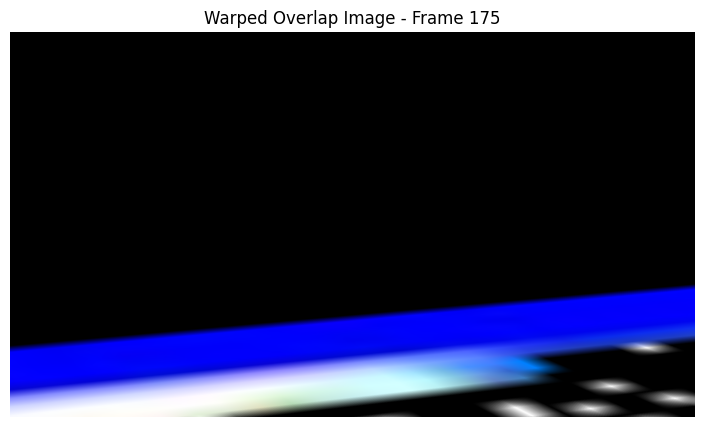

Iteration:  38%|███▊      | 172/450 [00:31<00:50,  5.54it/s]

Normalized Homography matrix for frame 278:
[[ 3.9927088e-02  1.0269068e-02  1.1057502e+02]
 [ 3.0308235e-02  2.2942375e-01 -1.6185503e+02]
 [-2.8569037e-05  4.3042488e-03  1.0000000e+00]]


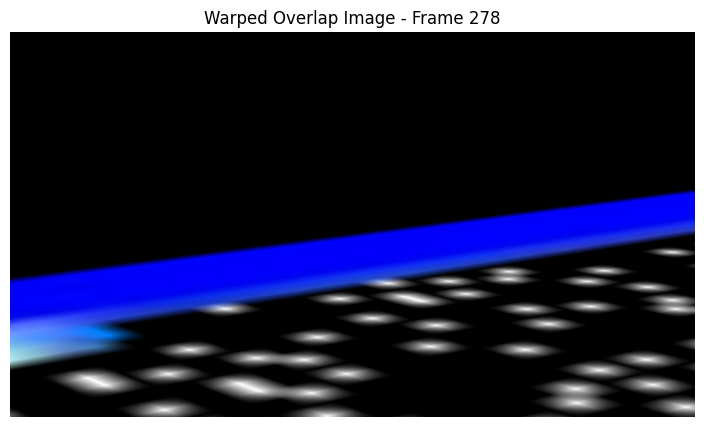

Iteration:  38%|███▊      | 173/450 [00:31<00:56,  4.94it/s]

Normalized Homography matrix for frame 243:
[[ 6.9915645e-02  1.7070398e-02  1.5466231e+02]
 [ 4.6972223e-02  3.8887087e-01 -2.9827914e+02]
 [-7.7300654e-05  7.3142573e-03  1.0000000e+00]]


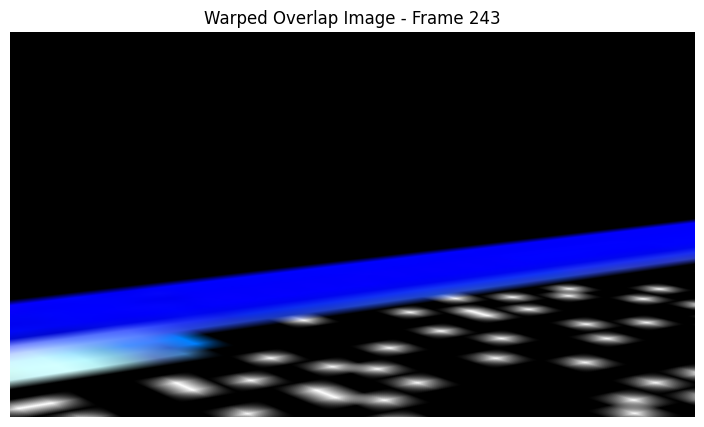

Iteration:  39%|███▊      | 174/450 [00:31<00:53,  5.11it/s]

Normalized Homography matrix for frame 133:
[[-7.1247883e-02 -9.4241789e-04 -1.6214266e+00]
 [-1.4666235e-02 -3.7276542e-01  2.8322382e+02]
 [ 1.9055398e-04 -7.8048352e-03  1.0000000e+00]]


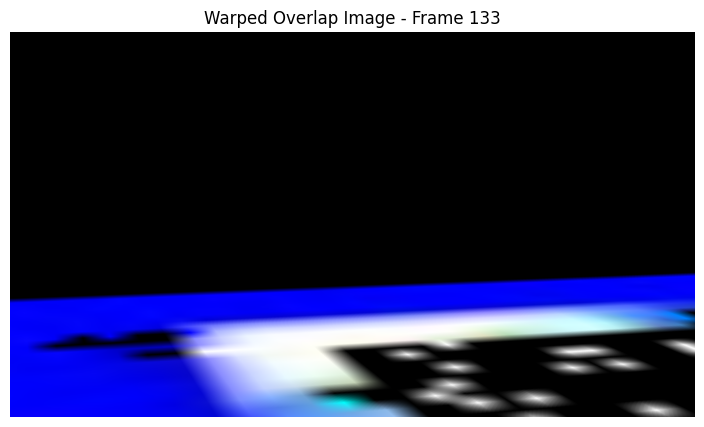

Iteration:  39%|███▉      | 175/450 [00:31<00:52,  5.23it/s]

Normalized Homography matrix for frame 64:
[[ 1.15009613e-01 -5.39991073e-03  1.39272523e+00]
 [ 2.74224989e-02  5.14744341e-01 -4.06667206e+02]
 [-5.77062528e-05  1.02820415e-02  1.00000000e+00]]


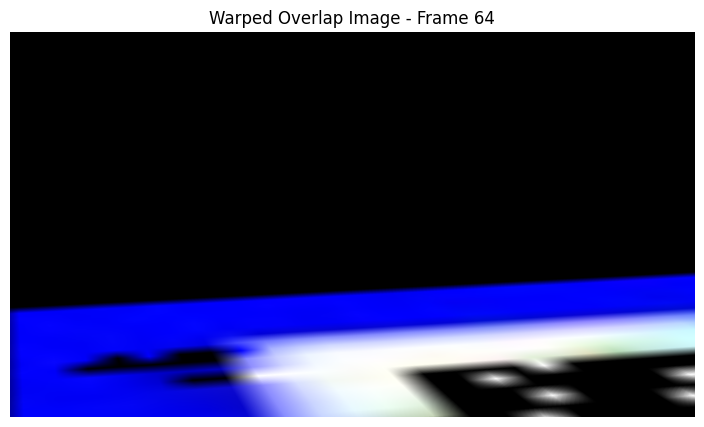

Iteration:  39%|███▉      | 176/450 [00:31<00:51,  5.33it/s]

Normalized Homography matrix for frame 257:
[[ 5.2936763e-02  1.3156361e-02  1.3048889e+02]
 [ 3.7801031e-02  2.9569536e-01 -2.2188156e+02]
 [-4.5199384e-05  5.5276621e-03  1.0000000e+00]]


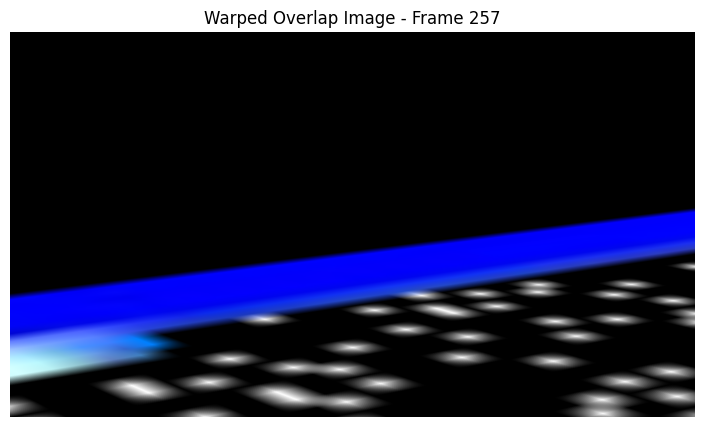

Iteration:  39%|███▉      | 177/450 [00:32<00:50,  5.37it/s]

Normalized Homography matrix for frame 91:
[[ 9.9716015e-02  6.2499963e-02 -3.0419588e+01]
 [ 2.3759939e-02  3.7137541e-01 -3.2689883e+02]
 [ 1.7984756e-04  6.9641899e-03  1.0000000e+00]]


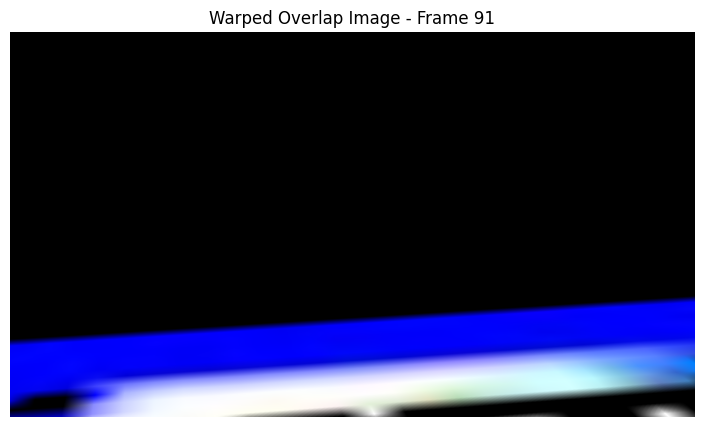

Iteration:  40%|███▉      | 178/450 [00:32<00:50,  5.41it/s]

Normalized Homography matrix for frame 296:
[[ 4.12725955e-02  1.32400915e-02  9.55330963e+01]
 [ 2.85487045e-02  2.28791520e-01 -1.56959137e+02]
 [-3.59960177e-05  4.35348926e-03  1.00000000e+00]]


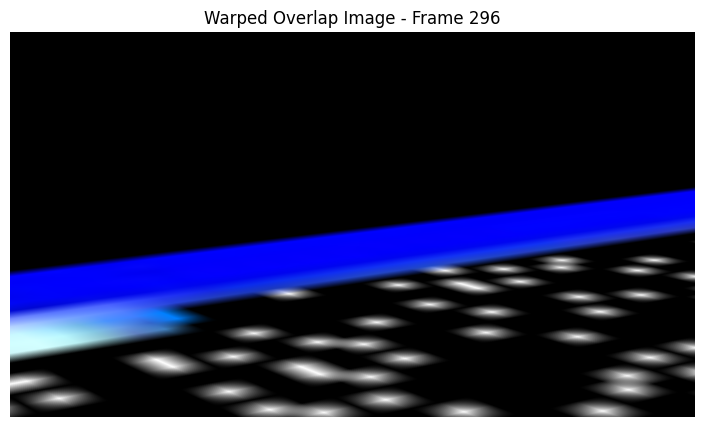

Iteration:  40%|███▉      | 179/450 [00:32<00:49,  5.46it/s]

Normalized Homography matrix for frame 198:
[[ 9.0250455e-02  1.5612407e-02  1.4187624e+02]
 [ 5.0038721e-02  4.6325952e-01 -3.9286615e+02]
 [-3.3204349e-05  8.7699443e-03  1.0000000e+00]]


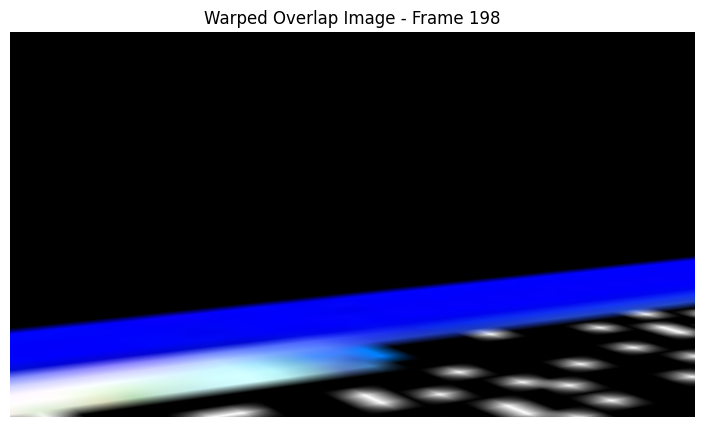

Iteration:  40%|████      | 180/450 [00:32<00:49,  5.48it/s]

Normalized Homography matrix for frame 28:
[[ 1.9795959e-01  6.8324065e-04 -1.0305798e+02]
 [ 2.5692519e-02  8.7184185e-01 -6.3971478e+02]
 [-1.8694278e-06  1.6611174e-02  1.0000000e+00]]


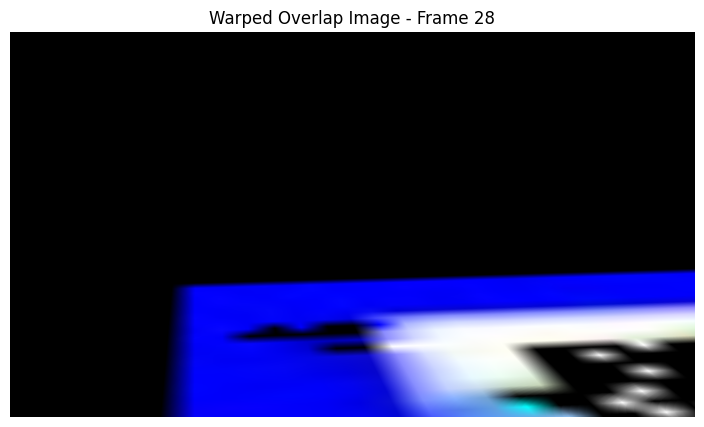

Iteration:  40%|████      | 181/450 [00:32<00:48,  5.53it/s]

Normalized Homography matrix for frame 105:
[[ 8.4649853e-02  3.5373427e-02  3.8884904e+00]
 [ 2.4761347e-02  3.3980581e-01 -3.1036844e+02]
 [ 1.0823494e-04  6.1402507e-03  1.0000000e+00]]


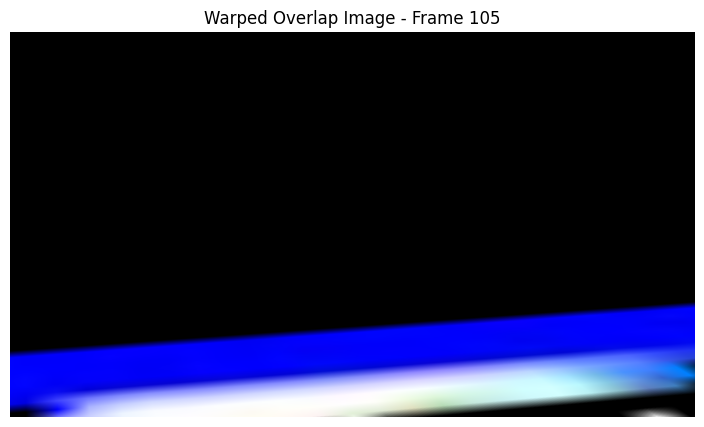

Iteration:  40%|████      | 182/450 [00:33<00:48,  5.58it/s]

Normalized Homography matrix for frame 283:
[[ 3.7090722e-02  6.9607934e-03  1.0461253e+02]
 [ 2.8622031e-02  2.1039233e-01 -1.4725920e+02]
 [-2.7787517e-05  3.9706021e-03  1.0000000e+00]]


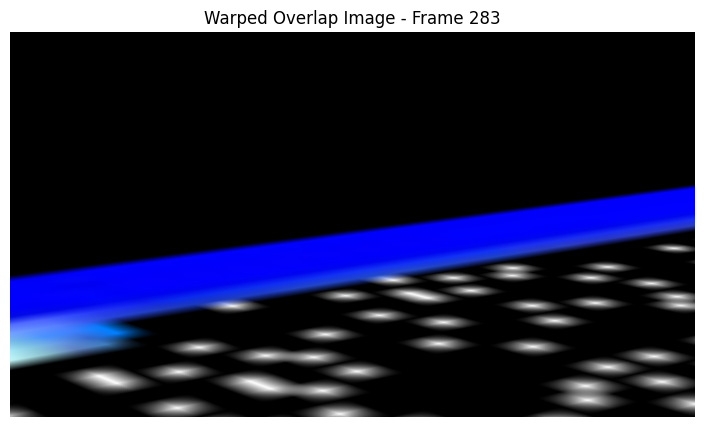

Iteration:  41%|████      | 183/450 [00:33<00:48,  5.54it/s]

Normalized Homography matrix for frame 3:
[[-6.5422016e-01  4.6747276e-03  5.2471033e+02]
 [-3.1032095e-02 -2.9010024e+00  2.0329254e+03]
 [ 7.3867726e-05 -5.6525234e-02  1.0000000e+00]]


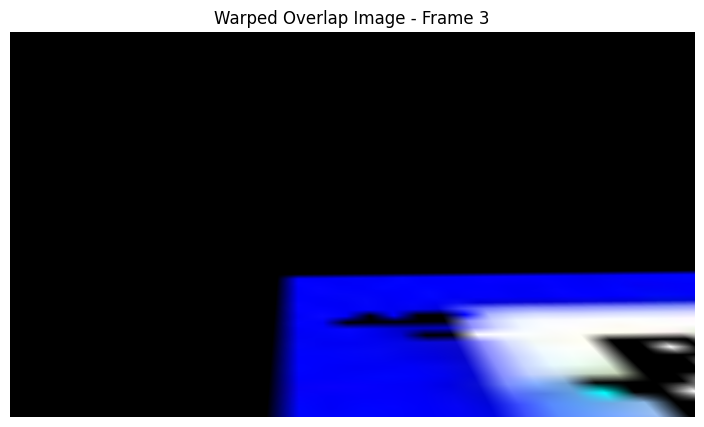

Iteration:  41%|████      | 184/450 [00:33<00:47,  5.59it/s]

Normalized Homography matrix for frame 67:
[[ 1.8238749e-01  4.1106571e-02 -2.5019066e+01]
 [ 4.4359516e-02  8.1893390e-01 -6.5687714e+02]
 [ 8.7643013e-05  1.7269114e-02  1.0000000e+00]]


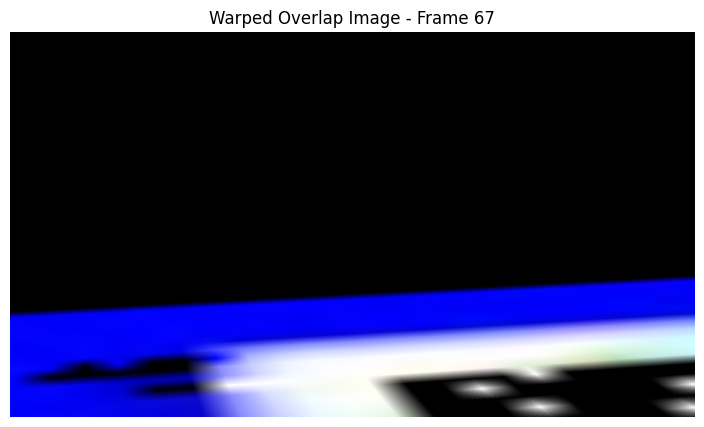

Iteration:  41%|████      | 185/450 [00:33<00:47,  5.60it/s]

Normalized Homography matrix for frame 90:
[[ 1.2124417e-01  6.1008271e-02 -2.5096989e+01]
 [ 3.2612175e-02  4.7607300e-01 -4.1429950e+02]
 [ 2.0387086e-04  9.0211229e-03  1.0000000e+00]]


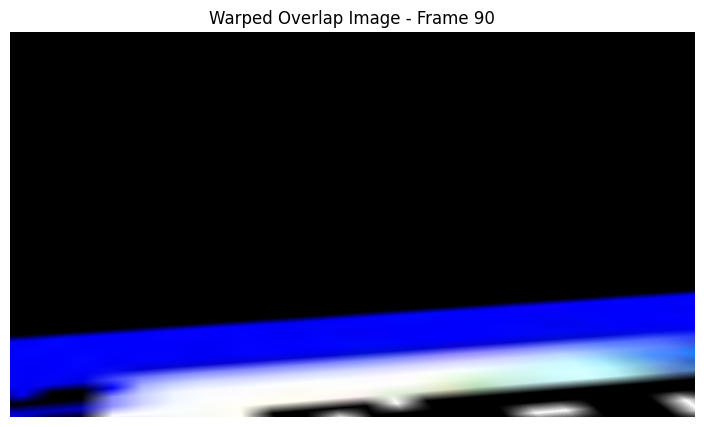

Iteration:  41%|████▏     | 186/450 [00:33<00:47,  5.61it/s]

Normalized Homography matrix for frame 381:
[[ 4.5449384e-02  6.7436956e-03  8.6258415e+01]
 [ 2.9627968e-02  2.4556829e-01 -1.6342453e+02]
 [-3.4641860e-05  4.6243593e-03  1.0000000e+00]]


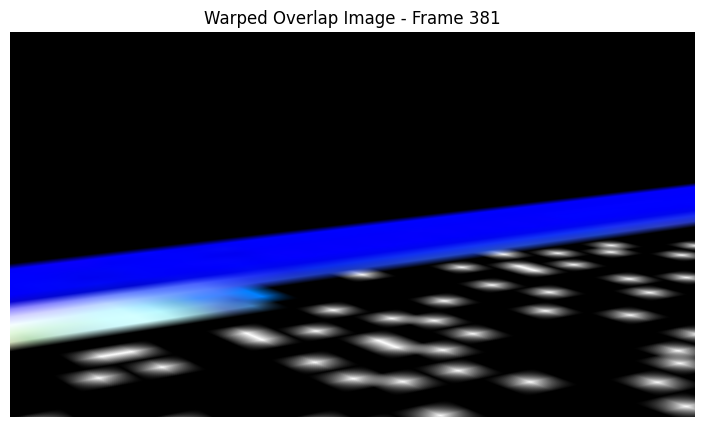

Iteration:  42%|████▏     | 187/450 [00:33<00:47,  5.55it/s]

Normalized Homography matrix for frame 26:
[[ 1.71559080e-01 -1.34520931e-04 -9.18050079e+01]
 [ 2.16562655e-02  7.63574779e-01 -5.58775696e+02]
 [ 1.05752315e-05  1.41483396e-02  1.00000000e+00]]


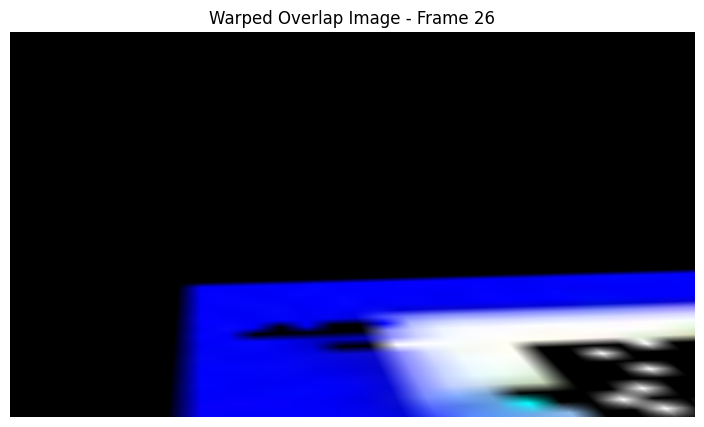

Iteration:  42%|████▏     | 188/450 [00:34<00:46,  5.59it/s]

Normalized Homography matrix for frame 121:
[[ 2.3582704e-01  9.4820127e-02  7.1191376e+01]
 [ 7.6177098e-02  1.0136031e+00 -9.4521899e+02]
 [ 1.8860086e-05  2.2703985e-02  1.0000000e+00]]


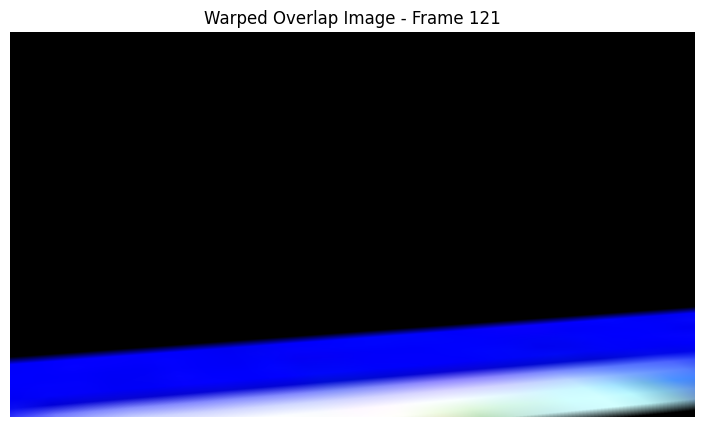

Iteration:  42%|████▏     | 189/450 [00:34<00:46,  5.60it/s]

Normalized Homography matrix for frame 107:
[[ 1.4523222e-01  4.7897123e-02  3.6610043e+01]
 [ 4.4928461e-02  6.2703580e-01 -5.7331964e+02]
 [ 3.9253191e-05  1.3220157e-02  1.0000000e+00]]


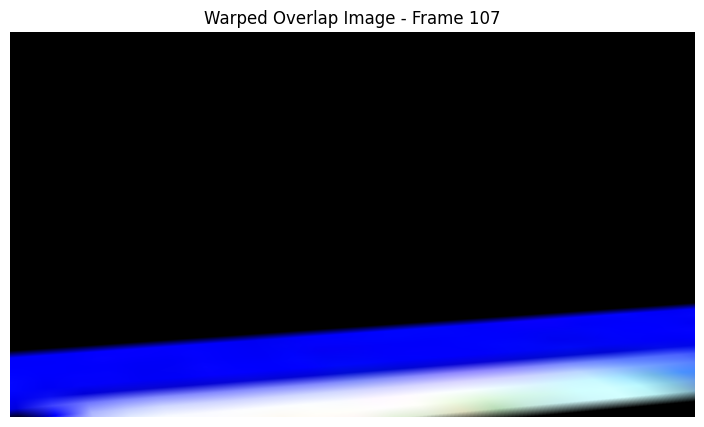

Iteration:  42%|████▏     | 190/450 [00:34<00:46,  5.60it/s]

Normalized Homography matrix for frame 201:
[[ 9.7995088e-02  2.2174701e-02  1.5748219e+02]
 [ 5.4598708e-02  5.0948292e-01 -4.2569983e+02]
 [-6.9331683e-05  9.8193577e-03  1.0000000e+00]]


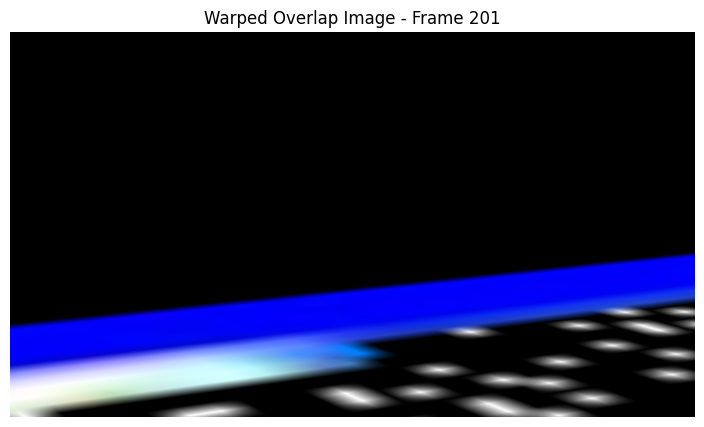

Iteration:  42%|████▏     | 191/450 [00:34<00:45,  5.65it/s]

Normalized Homography matrix for frame 126:
[[-6.4268172e-02 -5.2755154e-03  1.5914862e+00]
 [-1.5828934e-02 -3.5688671e-01  2.6865851e+02]
 [ 7.8634323e-05 -6.9583412e-03  1.0000000e+00]]


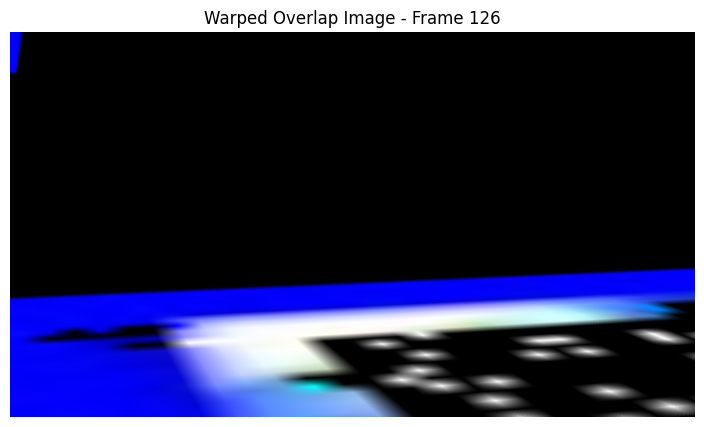

Iteration:  43%|████▎     | 192/450 [00:34<00:46,  5.60it/s]

Normalized Homography matrix for frame 383:
[[ 4.4571940e-02  3.1803662e-03  8.5185432e+01]
 [ 2.9658720e-02  2.3780648e-01 -1.5994875e+02]
 [-2.2563689e-05  4.4149826e-03  1.0000000e+00]]


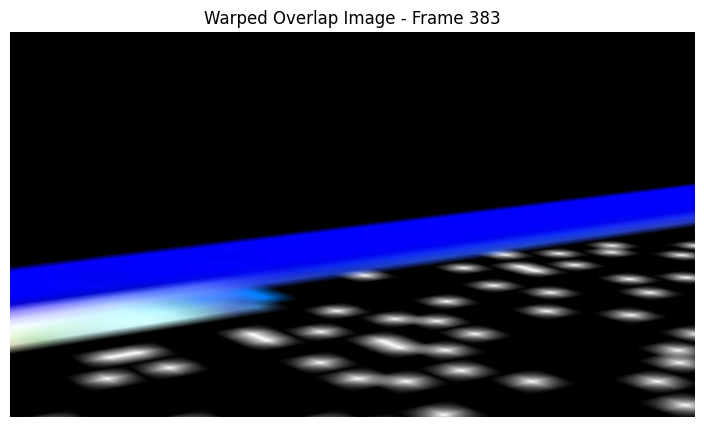

Iteration:  43%|████▎     | 193/450 [00:34<00:46,  5.58it/s]

Normalized Homography matrix for frame 43:
[[ 1.6186775e-01  1.9160688e-03 -5.8746300e+01]
 [ 2.8816370e-02  7.0650262e-01 -5.2779529e+02]
 [ 1.0330016e-05  1.3814689e-02  1.0000000e+00]]


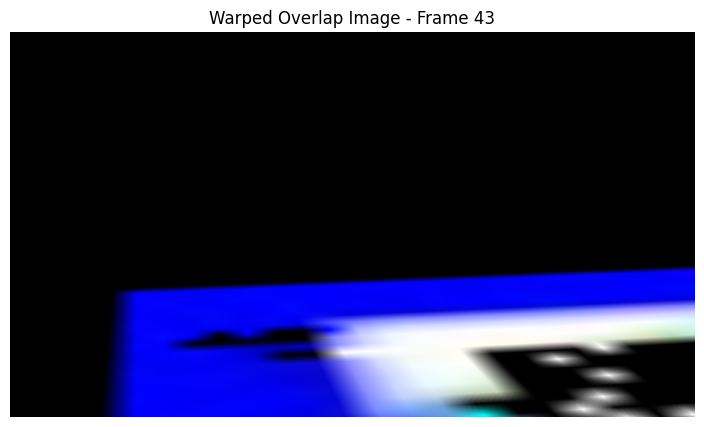

Iteration:  43%|████▎     | 194/450 [00:35<00:45,  5.57it/s]

Normalized Homography matrix for frame 424:
[[ 4.4640936e-02  6.3152616e-03  8.5200867e+01]
 [ 2.8692866e-02  2.4406745e-01 -1.6017323e+02]
 [-3.9037976e-05  4.5274040e-03  1.0000000e+00]]


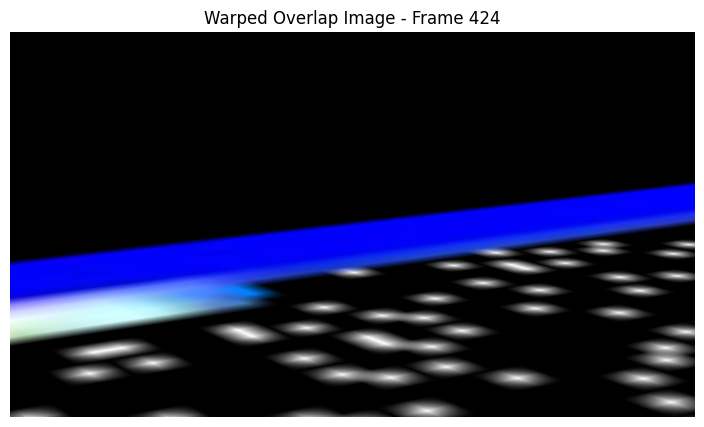

Iteration:  43%|████▎     | 195/450 [00:35<00:45,  5.55it/s]

Normalized Homography matrix for frame 153:
[[ 9.0448208e-02 -1.0118193e-04 -1.4414409e+01]
 [ 2.2559721e-02  2.8256214e-01 -2.5223059e+02]
 [ 6.8355516e-06  4.3624281e-03  1.0000000e+00]]


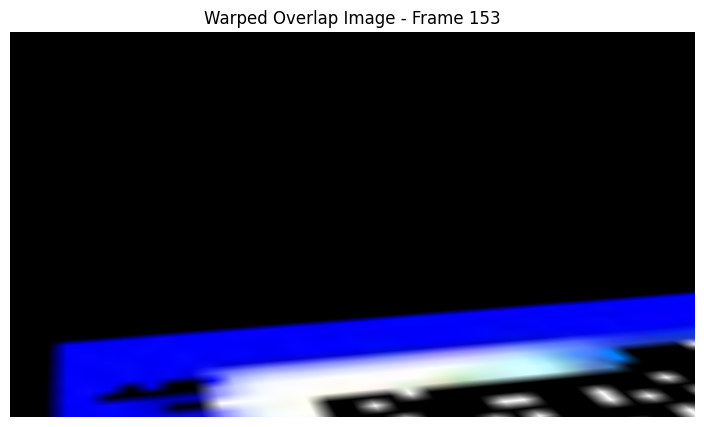

Iteration:  44%|████▎     | 196/450 [00:35<00:45,  5.56it/s]

Normalized Homography matrix for frame 362:
[[ 4.5660842e-02  1.4522128e-03  8.6585457e+01]
 [ 2.9937062e-02  2.4313264e-01 -1.6365767e+02]
 [-3.7660488e-05  4.5367875e-03  1.0000000e+00]]


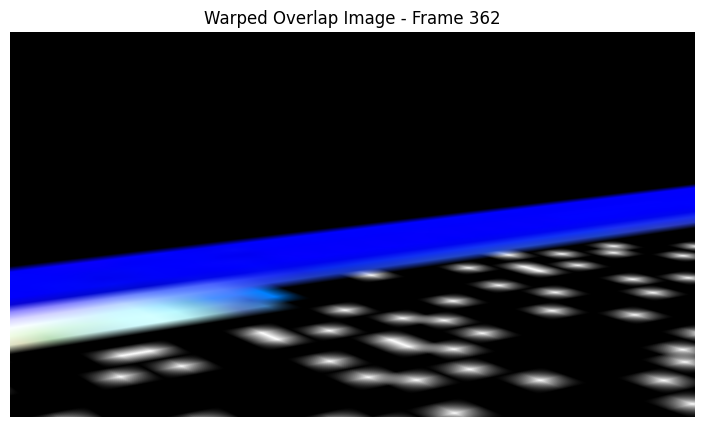

Iteration:  44%|████▍     | 197/450 [00:35<00:45,  5.52it/s]

Normalized Homography matrix for frame 379:
[[ 4.5461435e-02  3.7064233e-03  8.6523544e+01]
 [ 2.9973958e-02  2.4442393e-01 -1.6387590e+02]
 [-2.8313849e-05  4.5547644e-03  1.0000000e+00]]


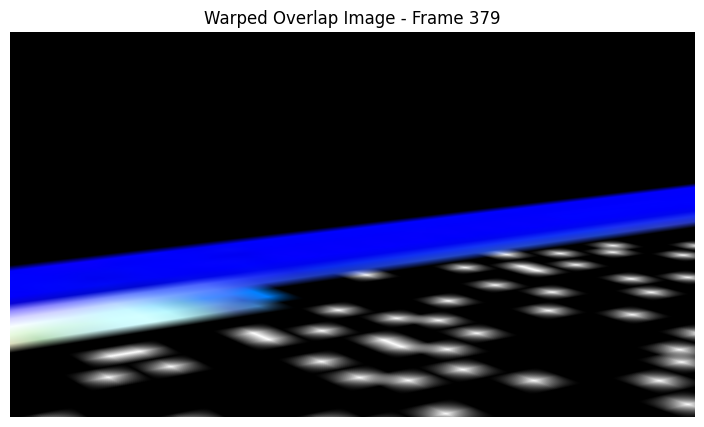

Iteration:  44%|████▍     | 198/450 [00:35<00:45,  5.49it/s]

Normalized Homography matrix for frame 417:
[[ 4.4677448e-02  5.4748408e-03  8.4998451e+01]
 [ 2.8937465e-02  2.4134865e-01 -1.6007245e+02]
 [-3.6079520e-05  4.4953222e-03  1.0000000e+00]]


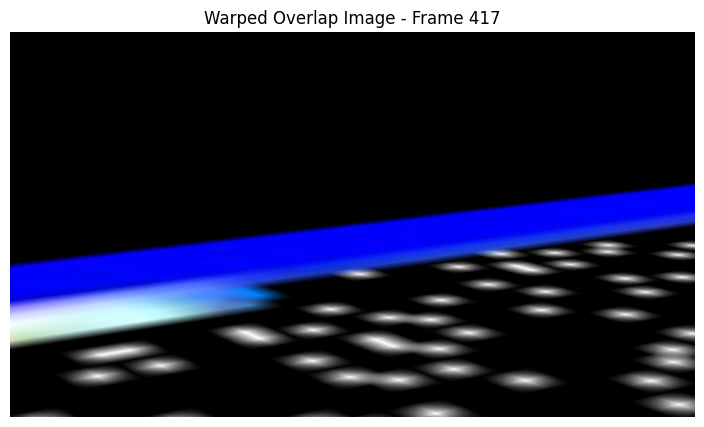

Iteration:  44%|████▍     | 199/450 [00:36<00:45,  5.48it/s]

Normalized Homography matrix for frame 162:
[[ 6.8814367e-02 -3.7096413e-03  4.2719166e+01]
 [ 2.5815185e-02  2.8260550e-01 -2.5867984e+02]
 [ 2.3467157e-06  4.7457875e-03  1.0000000e+00]]


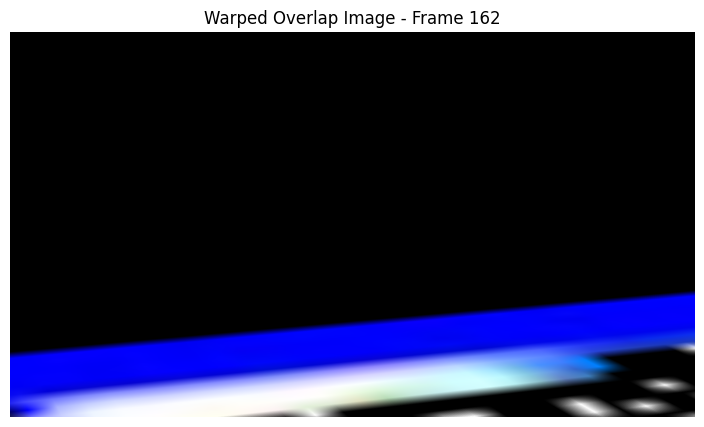

Iteration:  44%|████▍     | 200/450 [00:36<00:45,  5.54it/s]

Normalized Homography matrix for frame 224:
[[ 9.0663373e-02  1.6891463e-02  1.7555399e+02]
 [ 5.7414453e-02  4.9248618e-01 -3.9150595e+02]
 [-7.9725774e-05  9.2777973e-03  1.0000000e+00]]


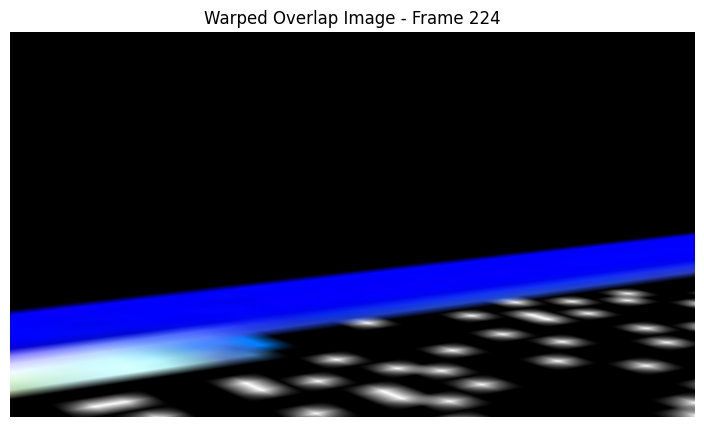

Iteration:  45%|████▍     | 201/450 [00:36<00:44,  5.57it/s]

Normalized Homography matrix for frame 311:
[[ 4.9100548e-02  5.3108181e-03  9.1608574e+01]
 [ 3.1894945e-02  2.6303086e-01 -1.8010309e+02]
 [-3.4595727e-05  4.9283262e-03  1.0000000e+00]]


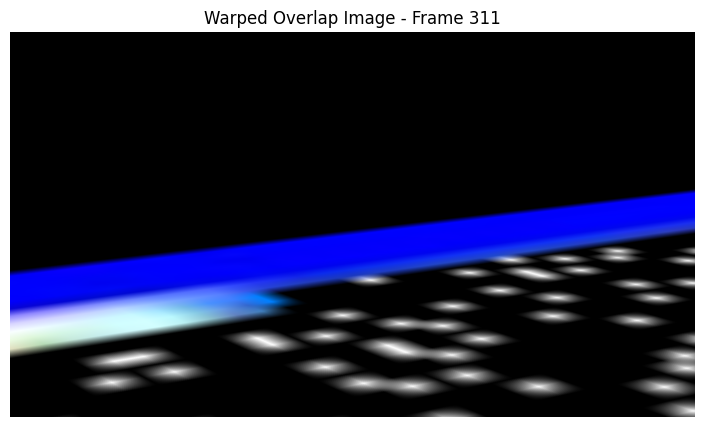

Iteration:  45%|████▍     | 202/450 [00:36<00:44,  5.57it/s]

Normalized Homography matrix for frame 97:
[[ 1.06369495e-01  5.29966205e-02 -1.29845181e+01]
 [ 2.85863969e-02  4.14803177e-01 -3.68167053e+02]
 [ 1.42290868e-04  7.84277171e-03  1.00000000e+00]]


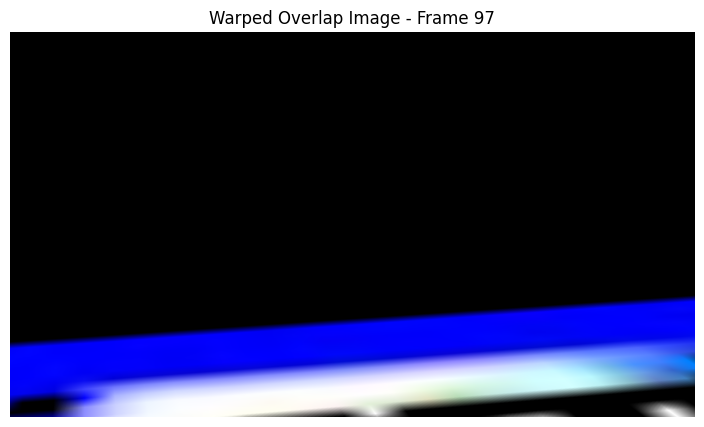

Iteration:  45%|████▌     | 203/450 [00:36<00:44,  5.59it/s]

Normalized Homography matrix for frame 74:
[[ 1.01350956e-01  3.05490959e-02 -1.93760185e+01]
 [ 2.39976440e-02  4.22253937e-01 -3.50992889e+02]
 [ 9.22619147e-05  7.85503071e-03  1.00000000e+00]]


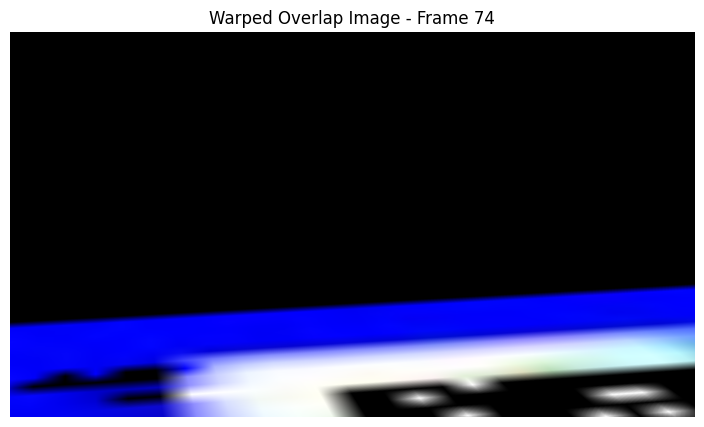

Iteration:  45%|████▌     | 204/450 [00:36<00:43,  5.62it/s]

Normalized Homography matrix for frame 39:
[[ 1.7907724e-01 -6.9712647e-03 -6.4398354e+01]
 [ 3.1865373e-02  7.8833646e-01 -5.8778137e+02]
 [ 1.4893820e-06  1.5495765e-02  1.0000000e+00]]


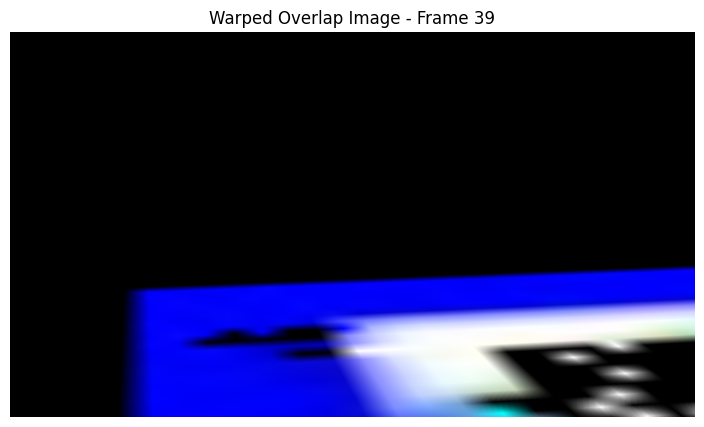

Iteration:  46%|████▌     | 205/450 [00:37<00:43,  5.60it/s]

Normalized Homography matrix for frame 374:
[[ 4.6050236e-02  4.3540439e-03  8.7485275e+01]
 [ 3.0015146e-02  2.4979466e-01 -1.6633322e+02]
 [-3.6247737e-05  4.6660271e-03  1.0000000e+00]]


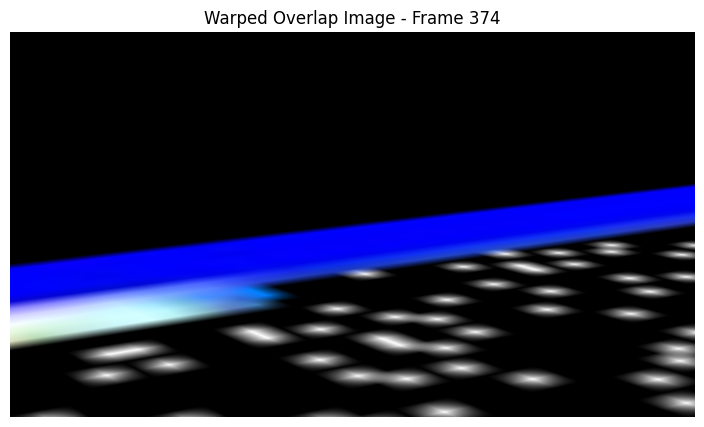

Iteration:  46%|████▌     | 206/450 [00:37<00:43,  5.56it/s]

Normalized Homography matrix for frame 237:
[[ 8.0172800e-02  2.0066626e-02  1.6595250e+02]
 [ 5.3771447e-02  4.3778330e-01 -3.3996835e+02]
 [-6.9504982e-05  8.3021782e-03  1.0000000e+00]]


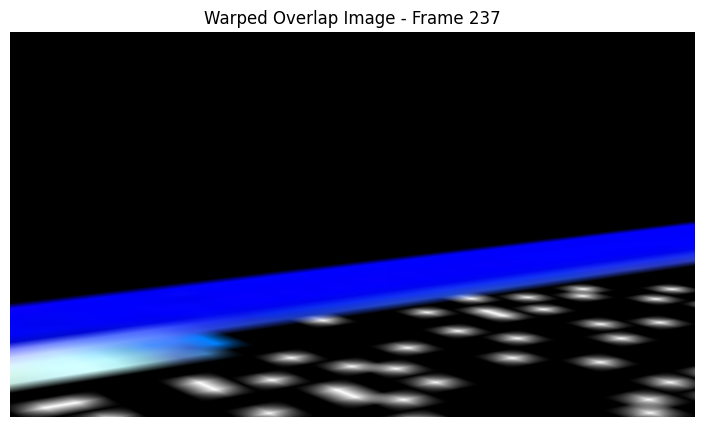

Iteration:  46%|████▌     | 207/450 [00:37<00:43,  5.55it/s]

Normalized Homography matrix for frame 414:
[[ 4.4937816e-02  5.3975768e-03  8.5946213e+01]
 [ 2.9059265e-02  2.4475728e-01 -1.6193576e+02]
 [-3.6656191e-05  4.5427172e-03  1.0000000e+00]]


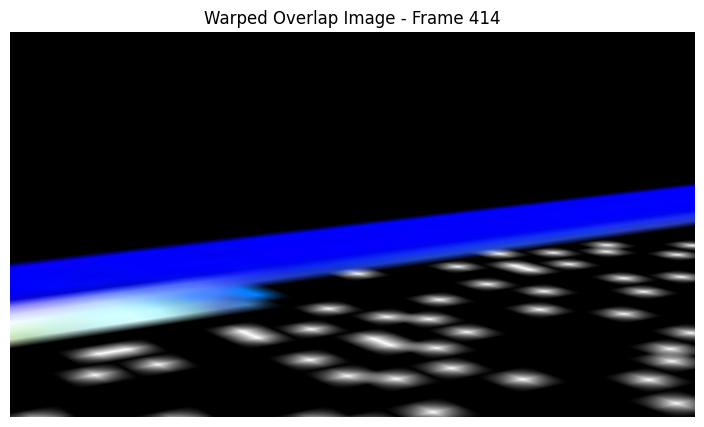

Iteration:  46%|████▌     | 208/450 [00:37<00:43,  5.54it/s]

Normalized Homography matrix for frame 134:
[[ 2.7558532e-01  1.4252415e-01  7.5569626e+01]
 [ 8.7338760e-02  1.1377449e+00 -1.0716799e+03]
 [-6.6509463e-05  2.6965491e-02  1.0000000e+00]]


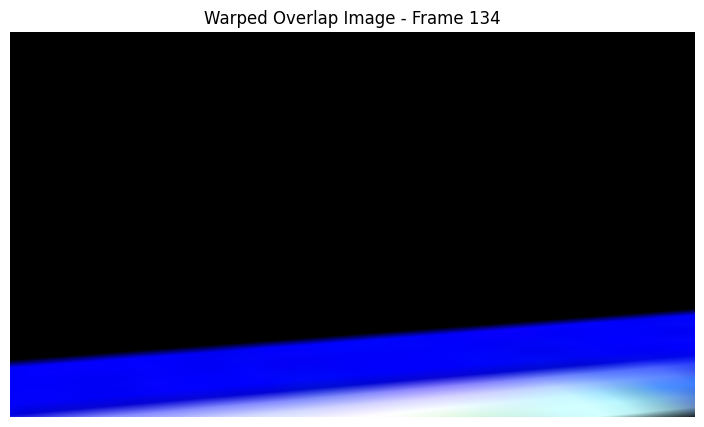

Iteration:  46%|████▋     | 209/450 [00:37<00:43,  5.57it/s]

Normalized Homography matrix for frame 233:
[[ 1.0000403e-01  4.1728381e-02  1.8648061e+02]
 [ 6.4794794e-02  5.4070687e-01 -4.2033575e+02]
 [-8.5577129e-05  1.0497222e-02  1.0000000e+00]]


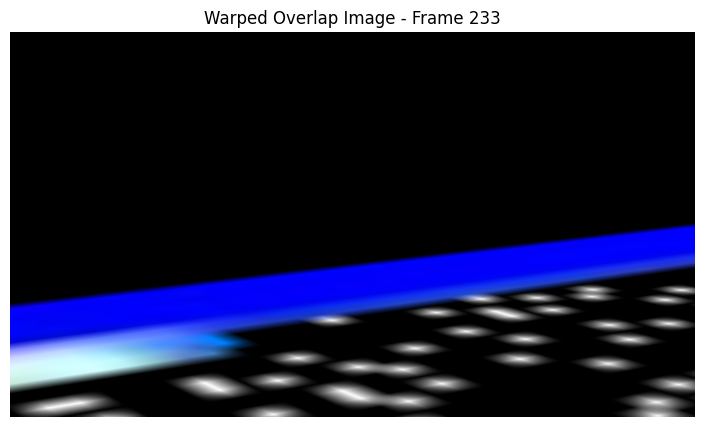

Iteration:  47%|████▋     | 210/450 [00:38<00:43,  5.46it/s]

Normalized Homography matrix for frame 260:
[[ 4.9375787e-02  7.2671501e-03  1.2765227e+02]
 [ 3.5611879e-02  2.7712637e-01 -2.0689160e+02]
 [-5.4843655e-05  5.1592486e-03  1.0000000e+00]]


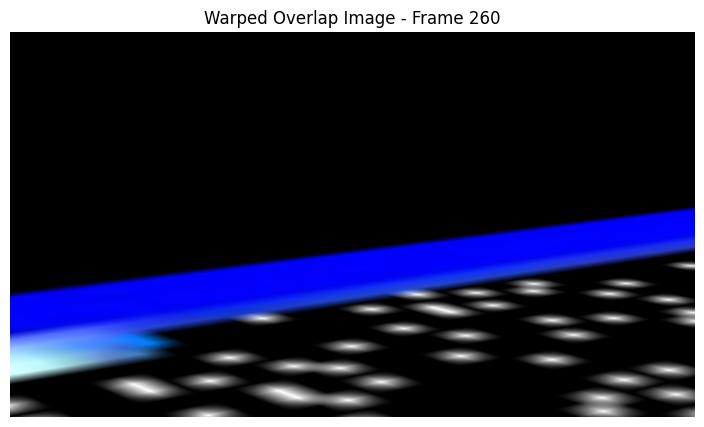

Iteration:  47%|████▋     | 211/450 [00:38<00:43,  5.46it/s]

Normalized Homography matrix for frame 327:
[[ 5.1175274e-02  3.9644837e-03  8.7604744e+01]
 [ 3.1828783e-02  2.7367455e-01 -1.8580727e+02]
 [-3.2996344e-05  5.0577130e-03  1.0000000e+00]]


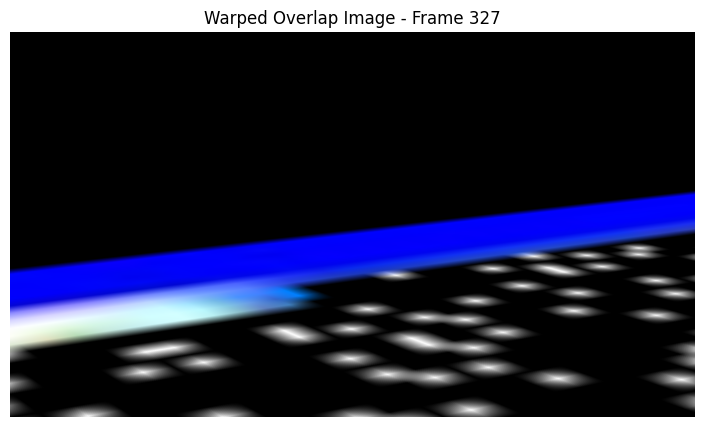

Iteration:  47%|████▋     | 212/450 [00:38<00:44,  5.39it/s]

Normalized Homography matrix for frame 167:
[[ 6.2435523e-02 -5.9913471e-03  6.6128891e+01]
 [ 2.7672993e-02  2.8550276e-01 -2.6350735e+02]
 [ 1.2762096e-05  5.0063636e-03  1.0000000e+00]]


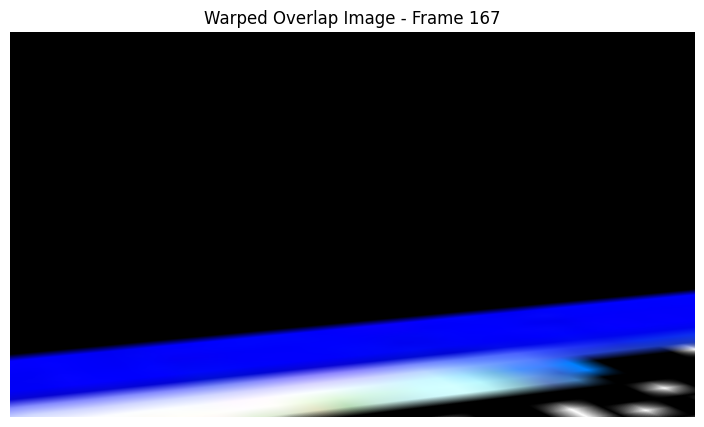

Iteration:  47%|████▋     | 213/450 [00:38<00:48,  4.92it/s]

Normalized Homography matrix for frame 166:
[[ 6.2937155e-02 -6.0928310e-03  6.7234261e+01]
 [ 2.8743496e-02  2.8655210e-01 -2.6778226e+02]
 [ 2.8177052e-05  5.0728824e-03  1.0000000e+00]]


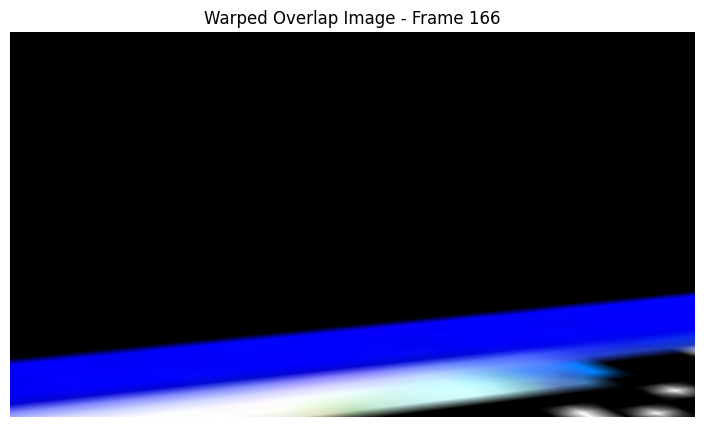

Iteration:  48%|████▊     | 214/450 [00:38<00:45,  5.15it/s]

Normalized Homography matrix for frame 218:
[[ 1.3176115e-01  4.4437762e-02  2.4400876e+02]
 [ 8.5389957e-02  6.9411641e-01 -5.6571875e+02]
 [-1.6522651e-04  1.4589919e-02  1.0000000e+00]]


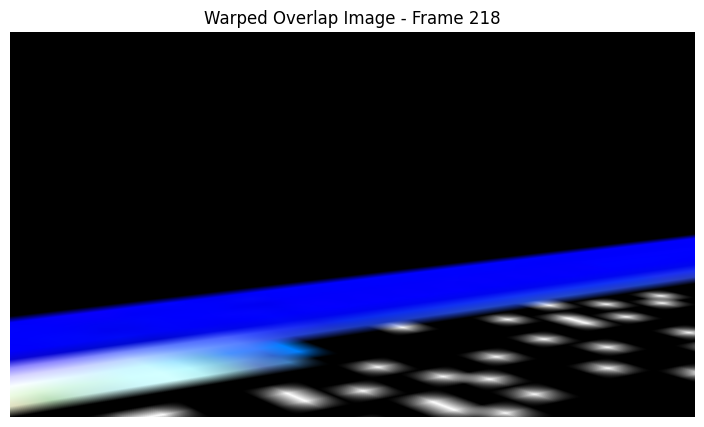

Iteration:  48%|████▊     | 215/450 [00:39<00:44,  5.26it/s]

Normalized Homography matrix for frame 292:
[[ 3.4647297e-02  4.2576618e-03  9.1728157e+01]
 [ 2.4831325e-02  1.9368654e-01 -1.3295958e+02]
 [-3.4223271e-05  3.5743220e-03  1.0000000e+00]]


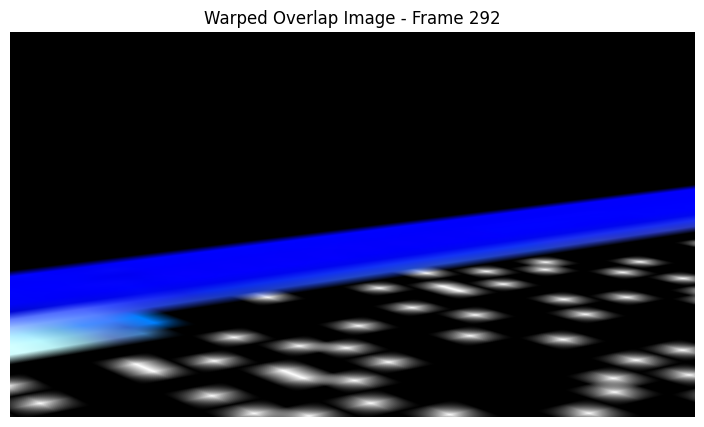

Iteration:  48%|████▊     | 216/450 [00:39<00:43,  5.33it/s]

Normalized Homography matrix for frame 10:
[[-3.8213587e+00  1.4642762e-01  2.5843984e+03]
 [-3.6392429e-01 -1.5715797e+01  1.1299898e+04]
 [ 3.4401144e-04 -3.1292722e-01  1.0000000e+00]]


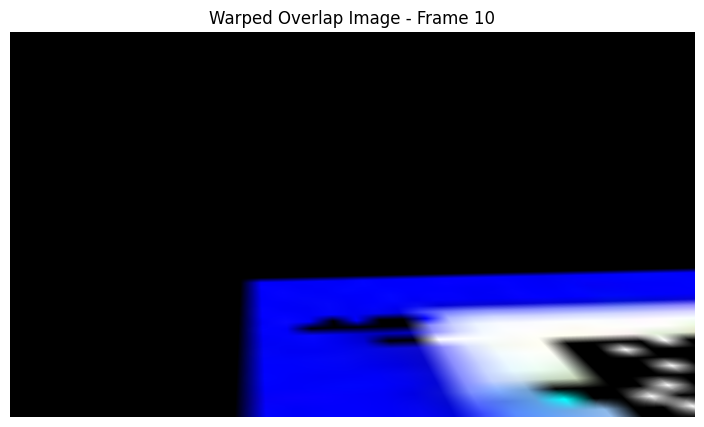

Iteration:  48%|████▊     | 217/450 [00:39<00:42,  5.49it/s]

Normalized Homography matrix for frame 434:
[[ 4.3662716e-02  5.3803227e-03  8.2598312e+01]
 [ 2.8892187e-02  2.3322630e-01 -1.5390268e+02]
 [-2.5500034e-05  4.3496597e-03  1.0000000e+00]]


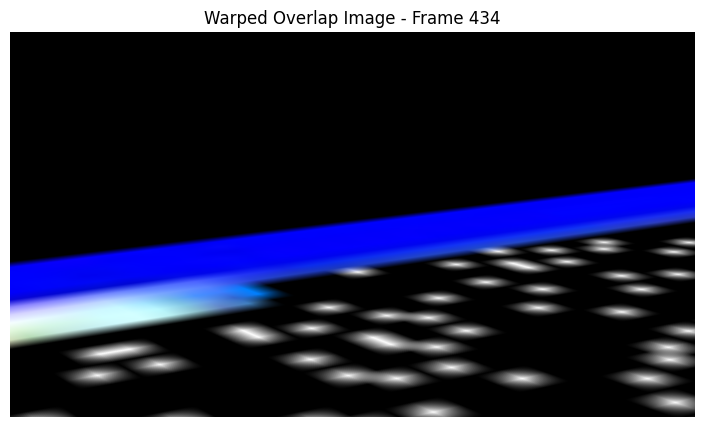

Iteration:  48%|████▊     | 218/450 [00:39<00:42,  5.49it/s]

Normalized Homography matrix for frame 393:
[[ 4.6993267e-02  8.4800543e-03  8.7504242e+01]
 [ 3.0664034e-02  2.5411329e-01 -1.6921175e+02]
 [-3.0287440e-05  4.7880444e-03  1.0000000e+00]]


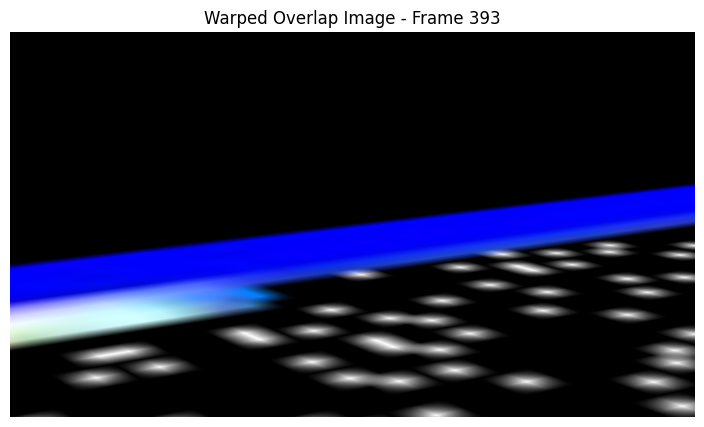

Iteration:  49%|████▊     | 219/450 [00:39<00:42,  5.48it/s]

Normalized Homography matrix for frame 182:
[[ 7.7135019e-02  1.5451554e-02  9.9186478e+01]
 [ 3.4995798e-02  3.8027081e-01 -3.3728253e+02]
 [-4.9997358e-05  7.3618898e-03  1.0000000e+00]]


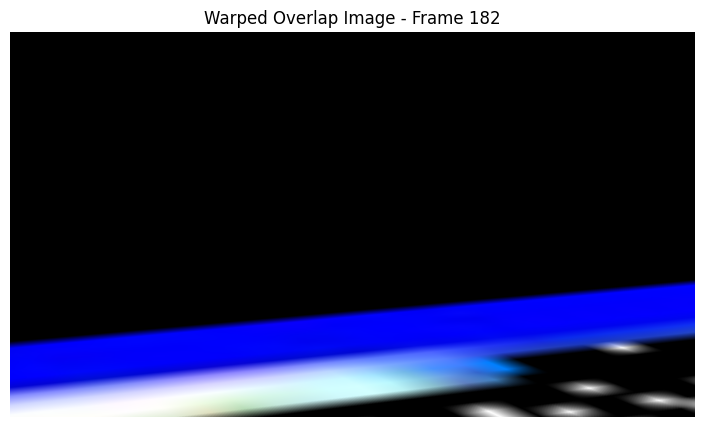

Iteration:  49%|████▉     | 220/450 [00:39<00:41,  5.54it/s]

Normalized Homography matrix for frame 227:
[[ 9.7191922e-02  3.1068707e-02  1.8013474e+02]
 [ 6.1172977e-02  5.2259433e-01 -4.1179797e+02]
 [-9.3835275e-05  1.0018503e-02  1.0000000e+00]]


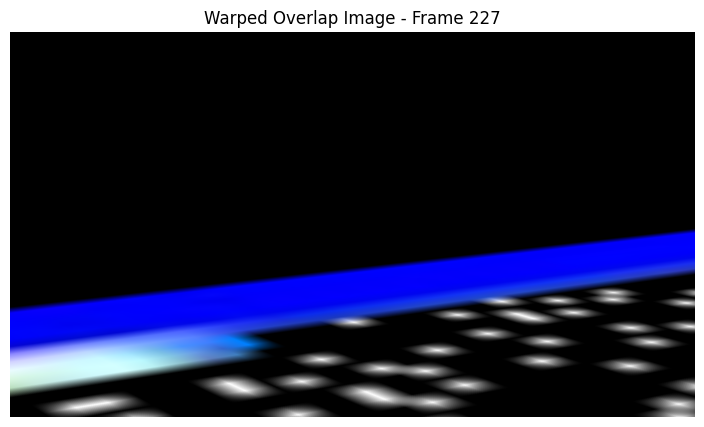

Iteration:  49%|████▉     | 221/450 [00:40<00:41,  5.53it/s]

Normalized Homography matrix for frame 364:
[[ 4.6829414e-02  8.6224880e-03  8.4997253e+01]
 [ 2.9738704e-02  2.5151664e-01 -1.6692972e+02]
 [-3.7896614e-05  4.7067516e-03  1.0000000e+00]]


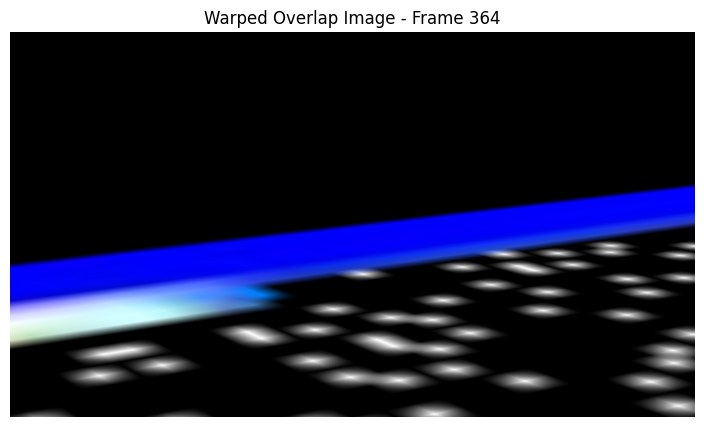

Iteration:  49%|████▉     | 222/450 [00:40<00:41,  5.47it/s]

Normalized Homography matrix for frame 422:
[[ 4.4658300e-02  7.0683160e-03  8.5513260e+01]
 [ 2.8918399e-02  2.4500197e-01 -1.6109079e+02]
 [-3.2769112e-05  4.5556626e-03  1.0000000e+00]]


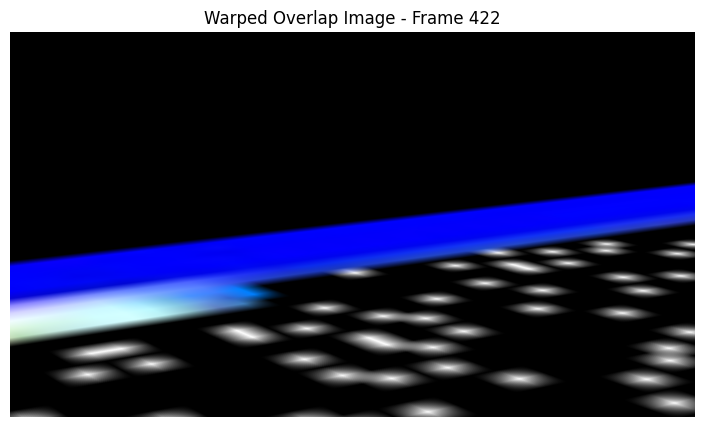

Iteration:  50%|████▉     | 223/450 [00:40<00:41,  5.46it/s]

Normalized Homography matrix for frame 408:
[[ 4.6780657e-02  8.2368534e-03  8.7090515e+01]
 [ 3.0581146e-02  2.5196865e-01 -1.6746429e+02]
 [-3.1946925e-05  4.7436175e-03  1.0000000e+00]]


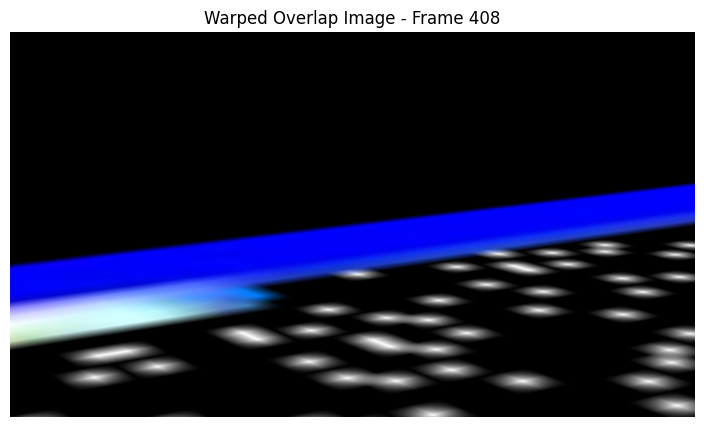

Iteration:  50%|████▉     | 224/450 [00:40<00:41,  5.48it/s]

Normalized Homography matrix for frame 219:
[[ 1.2320878e-01  4.7180403e-02  2.1572482e+02]
 [ 7.5880267e-02  6.6361737e-01 -5.2930365e+02]
 [-1.1721982e-04  1.3114086e-02  1.0000000e+00]]


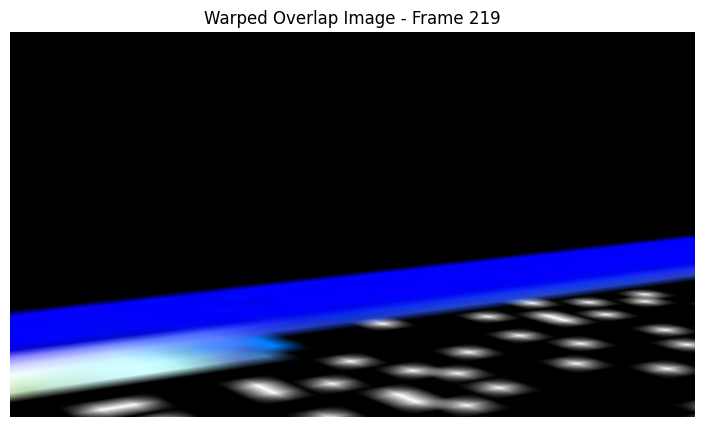

Iteration:  50%|█████     | 225/450 [00:40<00:40,  5.51it/s]

Normalized Homography matrix for frame 399:
[[ 4.4771027e-02  4.6718000e-03  8.4478561e+01]
 [ 2.9377239e-02  2.3864834e-01 -1.5956282e+02]
 [-2.8200469e-05  4.4284626e-03  1.0000000e+00]]


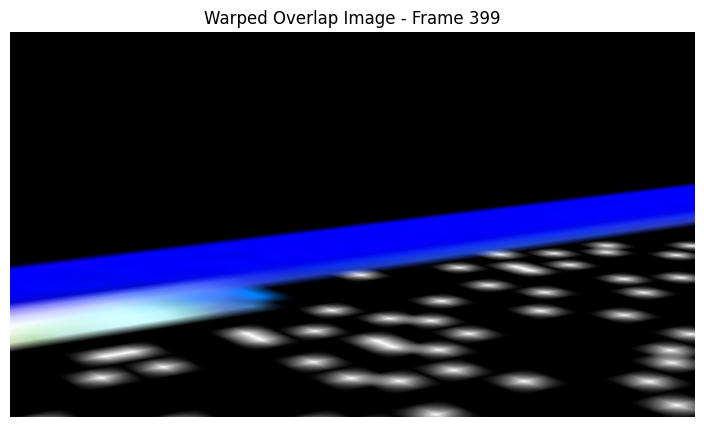

Iteration:  50%|█████     | 226/450 [00:41<00:40,  5.49it/s]

Normalized Homography matrix for frame 378:
[[ 4.5044877e-02  5.6531541e-03  8.4313133e+01]
 [ 2.8833495e-02  2.4293922e-01 -1.6123448e+02]
 [-3.5779296e-05  4.4954754e-03  1.0000000e+00]]


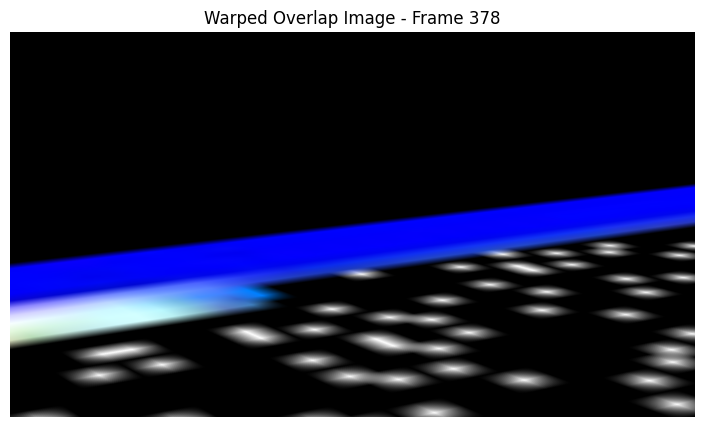

Iteration:  50%|█████     | 227/450 [00:41<00:40,  5.49it/s]

Normalized Homography matrix for frame 30:
[[ 1.3123827e-01 -4.9394909e-03 -6.1383640e+01]
 [ 1.7502043e-02  5.9707540e-01 -4.4041403e+02]
 [-6.3156112e-06  1.0782888e-02  1.0000000e+00]]


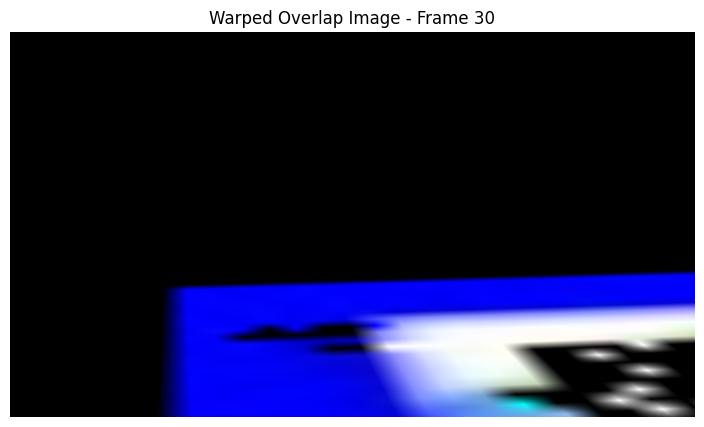

Iteration:  51%|█████     | 228/450 [00:41<00:40,  5.54it/s]

Normalized Homography matrix for frame 297:
[[ 3.7955258e-02  4.7446559e-03  9.2510727e+01]
 [ 2.6064985e-02  2.1262859e-01 -1.4584189e+02]
 [-3.8039761e-05  3.9105811e-03  1.0000000e+00]]


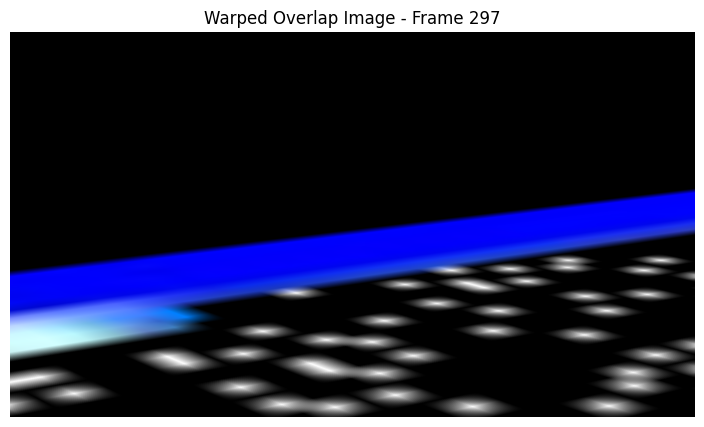

Iteration:  51%|█████     | 229/450 [00:41<00:39,  5.55it/s]

Normalized Homography matrix for frame 277:
[[ 3.8715709e-02  7.0839166e-03  1.0910448e+02]
 [ 2.9327089e-02  2.2121361e-01 -1.5678220e+02]
 [-3.3433400e-05  4.1161729e-03  1.0000000e+00]]


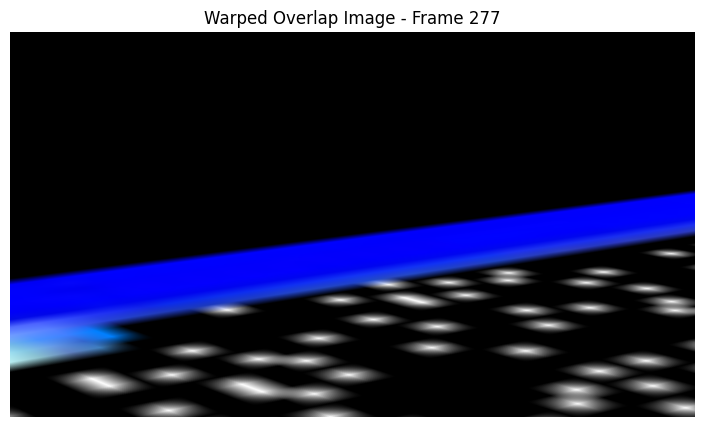

Iteration:  51%|█████     | 230/450 [00:41<00:39,  5.53it/s]

Normalized Homography matrix for frame 394:
[[ 4.6582274e-02  9.9452045e-03  8.5725357e+01]
 [ 2.9989423e-02  2.5162327e-01 -1.6665691e+02]
 [-3.2286407e-05  4.7286302e-03  1.0000000e+00]]


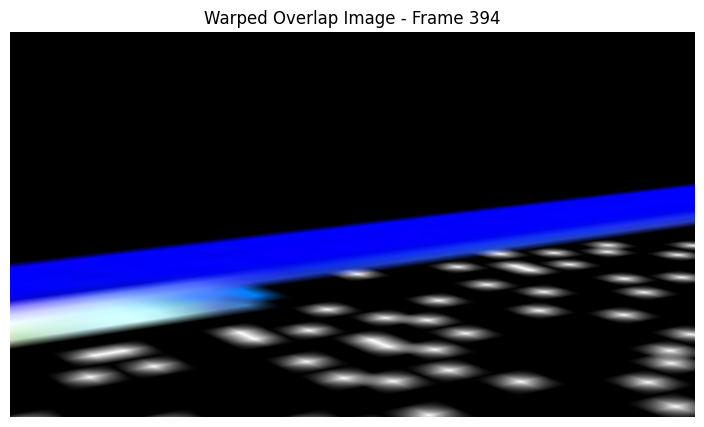

Iteration:  51%|█████▏    | 231/450 [00:41<00:39,  5.56it/s]

Normalized Homography matrix for frame 151:
[[ 7.2909988e-02 -1.8156265e-03  2.0440617e+01]
 [ 2.1625359e-02  2.8728205e-01 -2.5698938e+02]
 [-9.3627659e-06  4.5715496e-03  1.0000000e+00]]


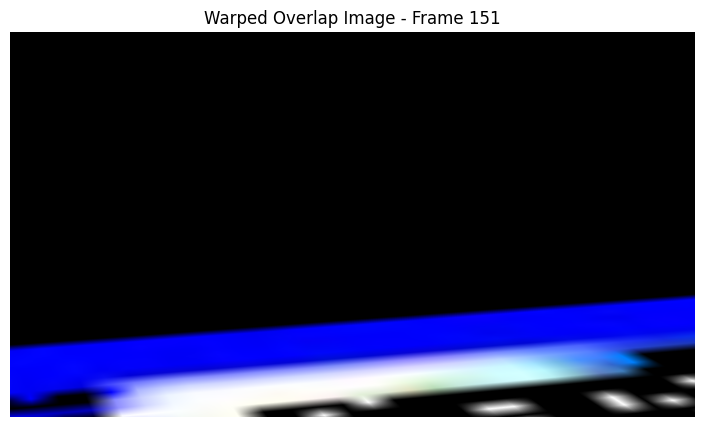

Iteration:  52%|█████▏    | 232/450 [00:42<00:38,  5.59it/s]

Normalized Homography matrix for frame 80:
[[ 9.0159722e-02  3.4094959e-02 -1.9350805e+01]
 [ 2.1608831e-02  3.6058724e-01 -3.0620325e+02]
 [ 1.0811139e-04  6.3911360e-03  1.0000000e+00]]


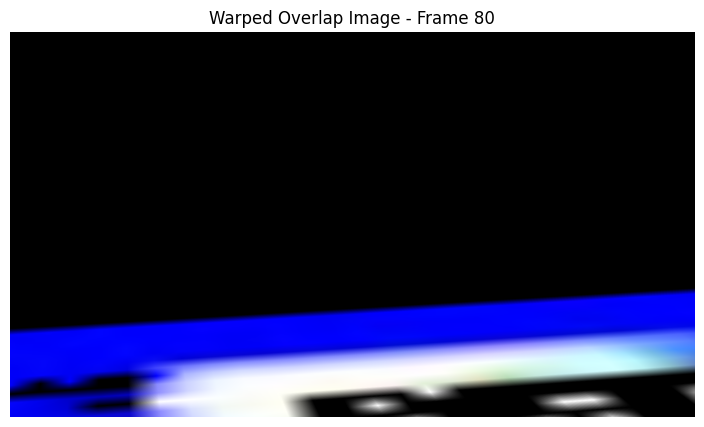

Iteration:  52%|█████▏    | 233/450 [00:42<00:38,  5.62it/s]

Normalized Homography matrix for frame 245:
[[ 6.5342762e-02  1.1534648e-02  1.5083807e+02]
 [ 4.5032423e-02  3.6270788e-01 -2.7865857e+02]
 [-7.2782830e-05  6.8309936e-03  1.0000000e+00]]


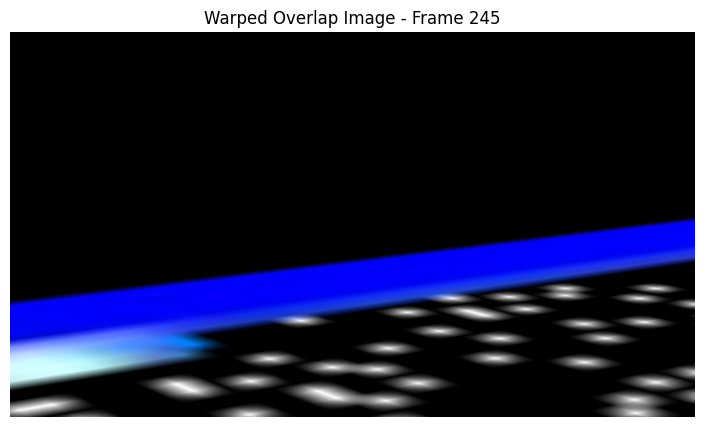

Iteration:  52%|█████▏    | 234/450 [00:42<00:38,  5.59it/s]

Normalized Homography matrix for frame 407:
[[ 4.4029456e-02  2.7703554e-03  8.5223114e+01]
 [ 2.8782427e-02  2.3695721e-01 -1.5812448e+02]
 [-3.5979894e-05  4.3968945e-03  1.0000000e+00]]


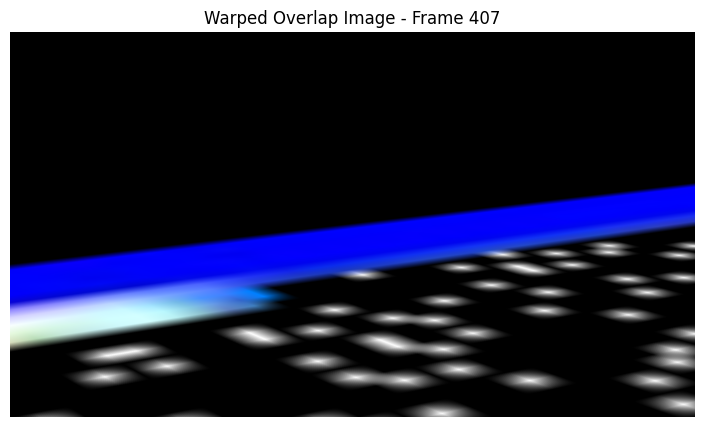

Iteration:  52%|█████▏    | 235/450 [00:42<00:38,  5.59it/s]

Normalized Homography matrix for frame 405:
[[ 4.5822300e-02  6.5455274e-03  8.5039719e+01]
 [ 3.0030984e-02  2.4404851e-01 -1.6298434e+02]
 [-2.7786184e-05  4.5656650e-03  1.0000000e+00]]


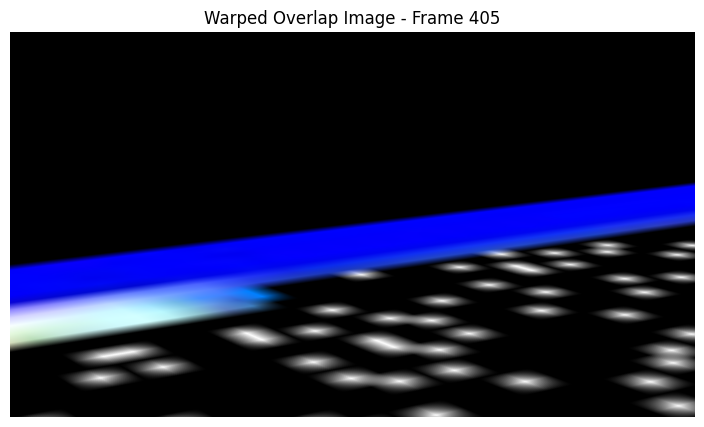

Iteration:  52%|█████▏    | 236/450 [00:42<00:38,  5.55it/s]

Normalized Homography matrix for frame 302:
[[ 4.4640068e-02  9.5564099e-03  9.4690849e+01]
 [ 2.9825496e-02  2.4360715e-01 -1.6815782e+02]
 [-4.0413459e-05  4.6111383e-03  1.0000000e+00]]


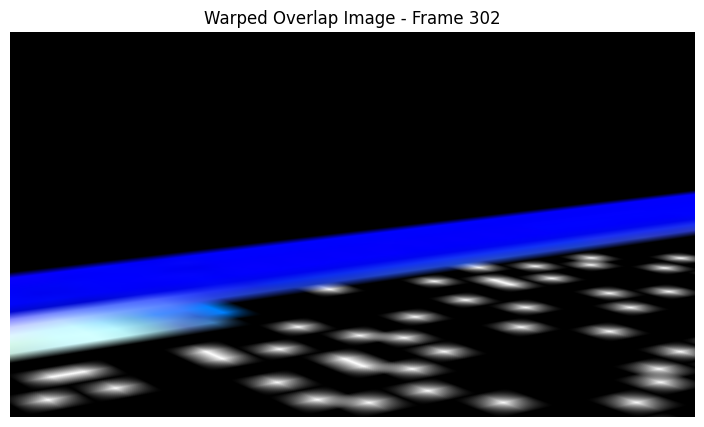

Iteration:  53%|█████▎    | 237/450 [00:43<00:38,  5.56it/s]

Normalized Homography matrix for frame 124:
[[ 1.0657457e-01  3.5444502e-02  3.9625488e+01]
 [ 3.3203568e-02  4.5960376e-01 -4.2990866e+02]
 [ 5.6497674e-06  9.4484780e-03  1.0000000e+00]]


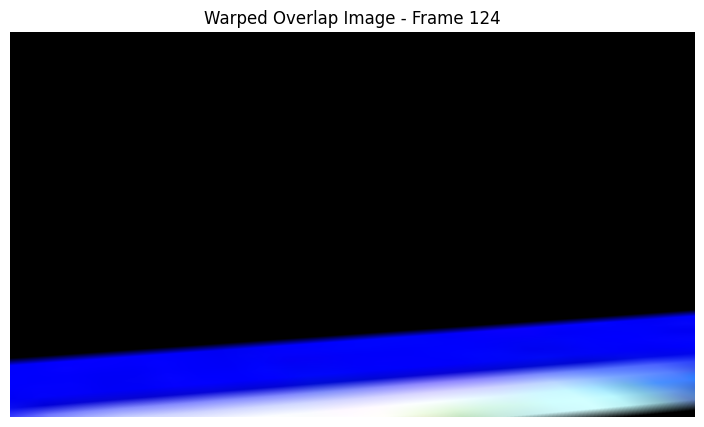

Iteration:  53%|█████▎    | 238/450 [00:43<00:38,  5.56it/s]

Normalized Homography matrix for frame 249:
[[ 6.4288132e-02  1.3778803e-02  1.5084013e+02]
 [ 4.5190245e-02  3.5862488e-01 -2.7466220e+02]
 [-5.9638736e-05  6.7516821e-03  1.0000000e+00]]


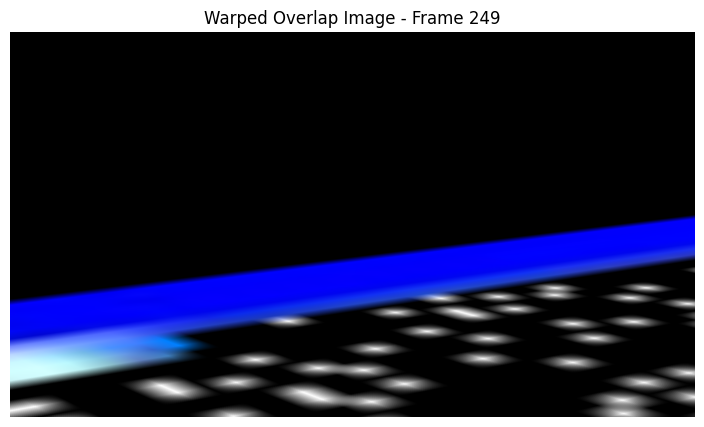

Iteration:  53%|█████▎    | 239/450 [00:43<00:38,  5.55it/s]

Normalized Homography matrix for frame 172:
[[ 7.0355572e-02  4.6297922e-03  6.9874062e+01]
 [ 2.9280689e-02  3.2352430e-01 -2.9190289e+02]
 [-1.7775748e-05  5.8521861e-03  1.0000000e+00]]


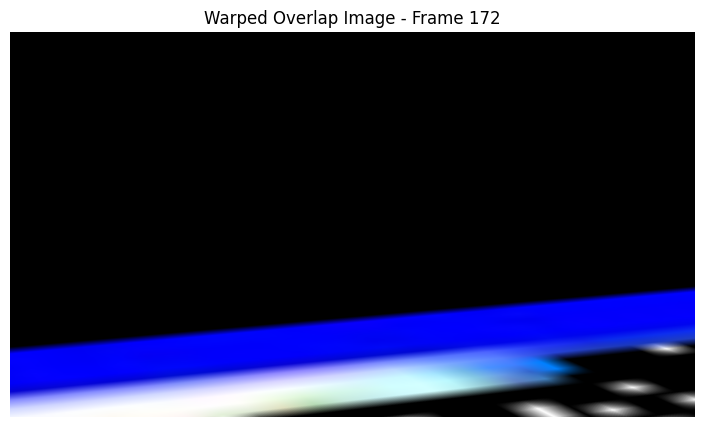

Iteration:  53%|█████▎    | 240/450 [00:43<00:37,  5.59it/s]

Normalized Homography matrix for frame 261:
[[ 4.9332667e-02  9.6153850e-03  1.2632363e+02]
 [ 3.6113441e-02  2.7579781e-01 -2.0581860e+02]
 [-3.9411138e-05  5.1450776e-03  1.0000000e+00]]


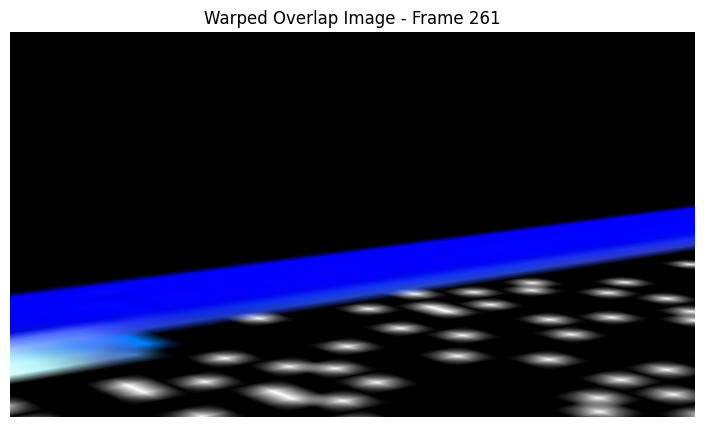

Iteration:  54%|█████▎    | 241/450 [00:43<00:37,  5.57it/s]

Normalized Homography matrix for frame 48:
[[ 1.2533933e-01  1.8047449e-03 -3.6574993e+01]
 [ 2.2855729e-02  5.5991107e-01 -4.2183905e+02]
 [-7.4889695e-06  1.0862022e-02  1.0000000e+00]]


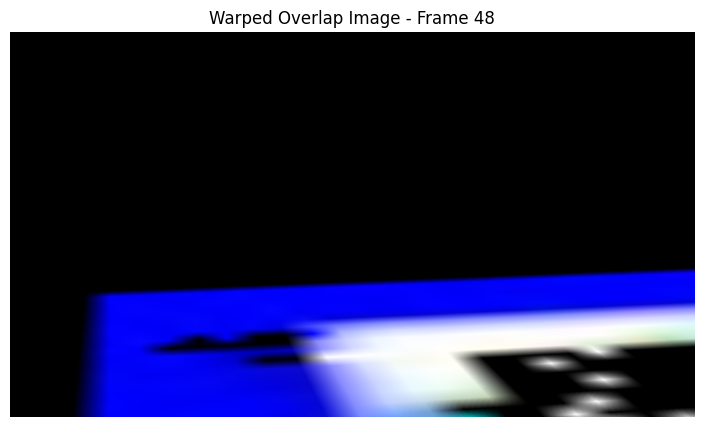

Iteration:  54%|█████▍    | 242/450 [00:43<00:37,  5.58it/s]

Normalized Homography matrix for frame 321:
[[ 5.2203111e-02  5.6176372e-03  8.9070961e+01]
 [ 3.3773005e-02  2.7597597e-01 -1.8846025e+02]
 [-1.4925573e-05  5.1510972e-03  1.0000000e+00]]


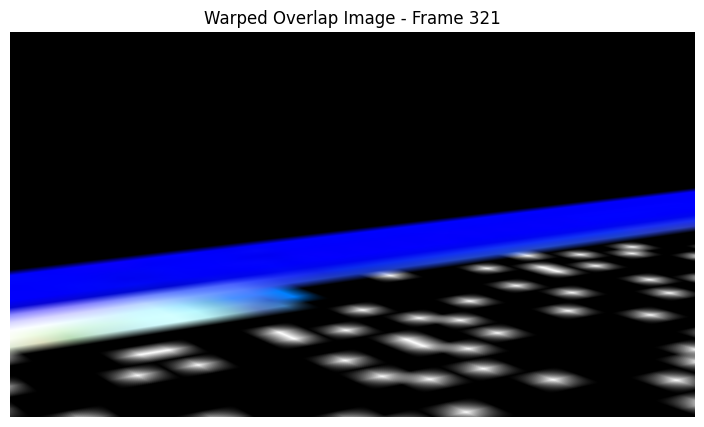

Iteration:  54%|█████▍    | 243/450 [00:44<00:37,  5.55it/s]

Normalized Homography matrix for frame 388:
[[ 4.5424152e-02  4.5263926e-03  8.6737923e+01]
 [ 2.9816115e-02  2.4330263e-01 -1.6278987e+02]
 [-3.8003611e-05  4.5778435e-03  1.0000000e+00]]


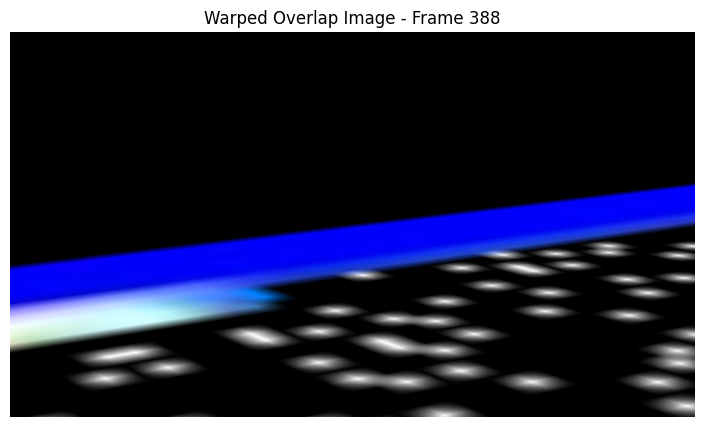

Iteration:  54%|█████▍    | 244/450 [00:44<00:37,  5.52it/s]

Normalized Homography matrix for frame 304:
[[ 4.24466282e-02 -1.01888334e-04  9.27806549e+01]
 [ 2.84870472e-02  2.30449885e-01 -1.59556824e+02]
 [-4.73047112e-05  4.29288298e-03  1.00000000e+00]]


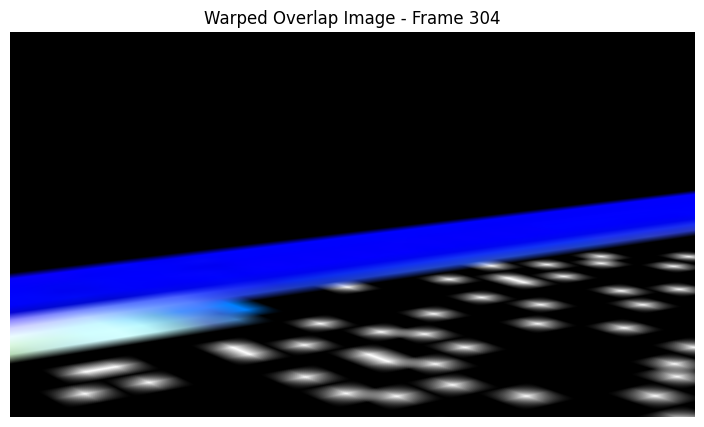

Iteration:  54%|█████▍    | 245/450 [00:44<00:37,  5.54it/s]

Normalized Homography matrix for frame 322:
[[ 5.1767021e-02  7.9990076e-03  8.6885338e+01]
 [ 3.1799611e-02  2.7729294e-01 -1.8737224e+02]
 [-3.2140782e-05  5.1313355e-03  1.0000000e+00]]


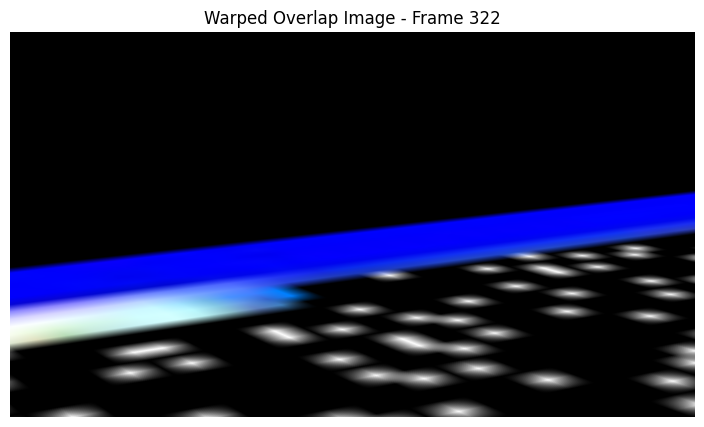

Iteration:  55%|█████▍    | 246/450 [00:44<00:37,  5.51it/s]

Normalized Homography matrix for frame 314:
[[ 4.9473591e-02  5.0312178e-03  9.0642494e+01]
 [ 3.1081364e-02  2.6674724e-01 -1.8091685e+02]
 [-5.0922674e-05  5.0012711e-03  1.0000000e+00]]


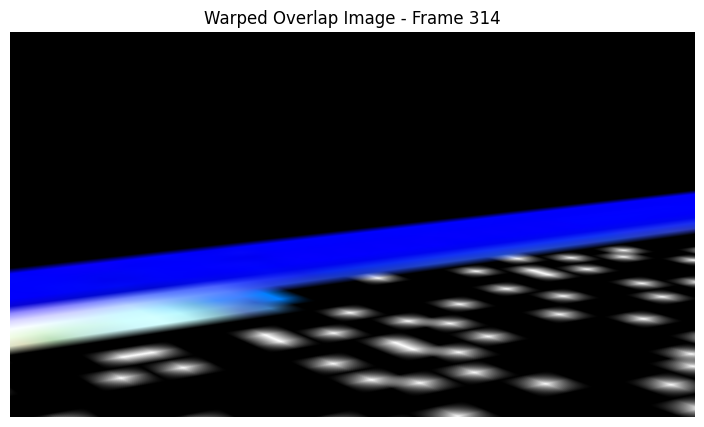

Iteration:  55%|█████▍    | 247/450 [00:44<00:36,  5.53it/s]

Normalized Homography matrix for frame 336:
[[ 5.0667286e-02  6.4955712e-03  8.5923782e+01]
 [ 3.1672120e-02  2.6956299e-01 -1.8218086e+02]
 [-2.6938575e-05  4.9857167e-03  1.0000000e+00]]


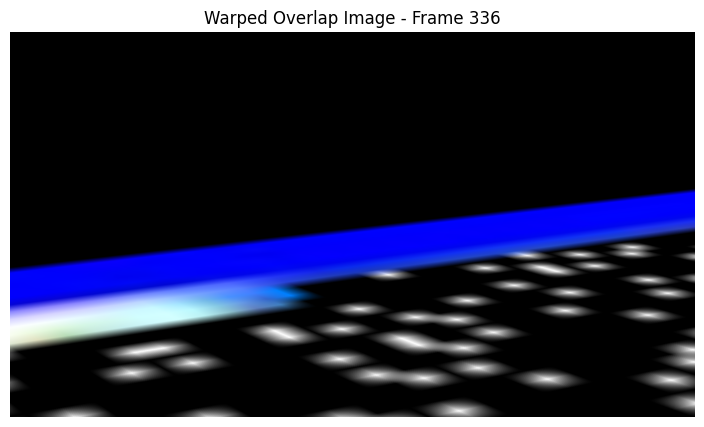

Iteration:  55%|█████▌    | 248/450 [00:44<00:36,  5.50it/s]

Normalized Homography matrix for frame 115:
[[-1.50623351e-01 -9.56382230e-02  7.99500198e+01]
 [-2.44115405e-02 -6.88670456e-01  5.24953674e+02]
 [ 3.09528247e-07 -1.24283135e-02  1.00000000e+00]]


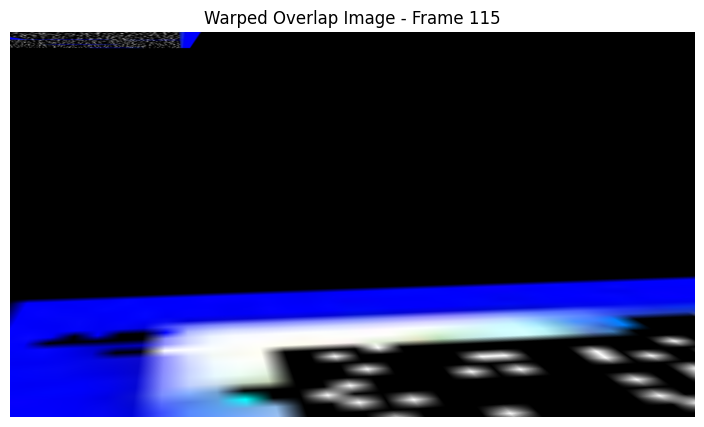

Iteration:  55%|█████▌    | 249/450 [00:45<00:36,  5.50it/s]

Normalized Homography matrix for frame 44:
[[ 1.4562394e-01 -2.2783414e-03 -4.7408009e+01]
 [ 2.6404426e-02  6.5101343e-01 -4.8609921e+02]
 [ 1.6512986e-06  1.2694127e-02  1.0000000e+00]]


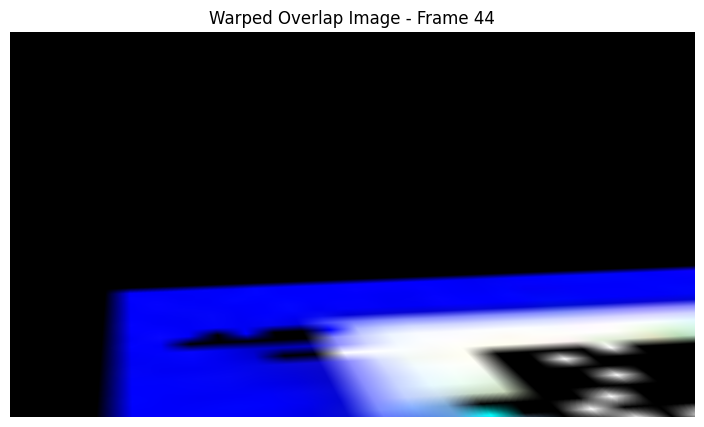

Iteration:  56%|█████▌    | 250/450 [00:45<00:36,  5.51it/s]

Normalized Homography matrix for frame 71:
[[ 1.3367549e-01  3.5721269e-02 -2.5952816e+01]
 [ 3.4154929e-02  5.7271284e-01 -4.7054669e+02]
 [ 1.5605493e-04  1.1092776e-02  1.0000000e+00]]


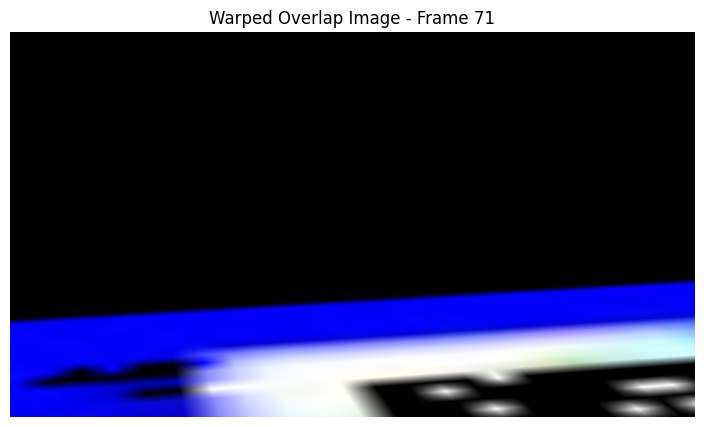

Iteration:  56%|█████▌    | 251/450 [00:45<00:35,  5.55it/s]

Normalized Homography matrix for frame 395:
[[ 4.5083400e-02  5.2781673e-03  8.5138496e+01]
 [ 2.9129561e-02  2.4300885e-01 -1.6168085e+02]
 [-3.4971639e-05  4.5117415e-03  1.0000000e+00]]


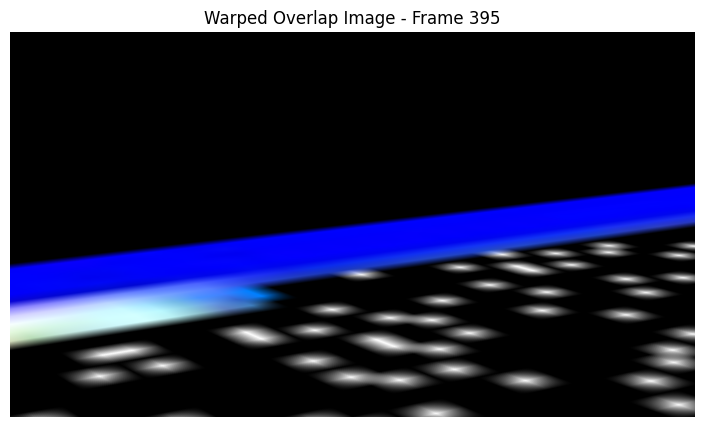

Iteration:  56%|█████▌    | 252/450 [00:45<00:35,  5.52it/s]

Normalized Homography matrix for frame 154:
[[ 8.9486718e-02 -3.9665280e-03 -8.6081028e+00]
 [ 2.3403419e-02  2.8515813e-01 -2.5368655e+02]
 [-3.6526030e-06  4.3708803e-03  1.0000000e+00]]


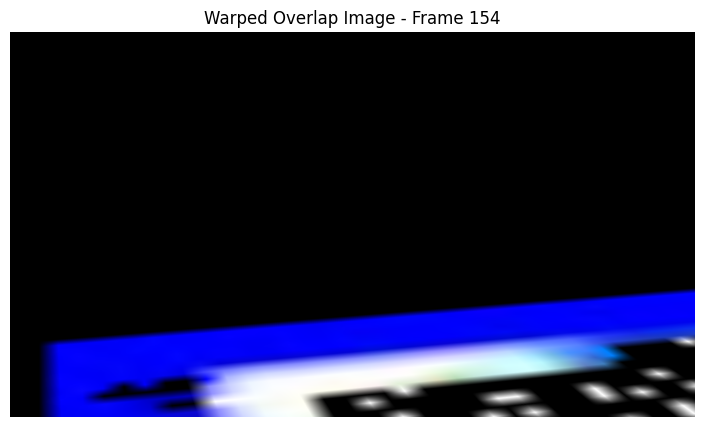

Iteration:  56%|█████▌    | 253/450 [00:45<00:39,  5.01it/s]

Normalized Homography matrix for frame 73:
[[ 1.1837626e-01  2.9981574e-02 -1.8585764e+01]
 [ 3.0781833e-02  5.0794554e-01 -4.2031308e+02]
 [ 1.3454517e-04  9.6219694e-03  1.0000000e+00]]


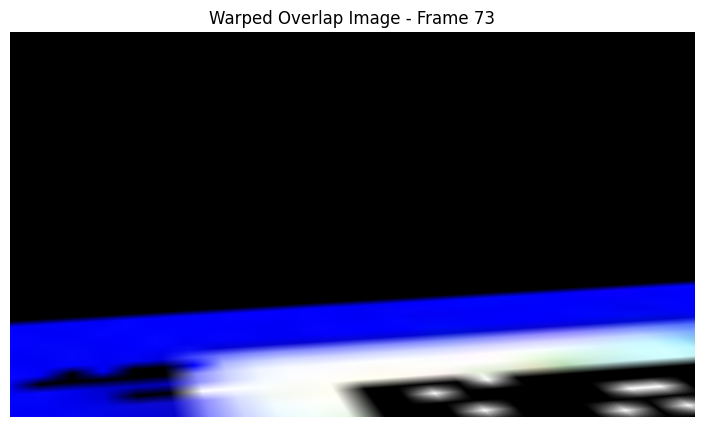

Iteration:  56%|█████▋    | 254/450 [00:46<00:37,  5.18it/s]

Normalized Homography matrix for frame 430:
[[ 4.3931361e-02  4.9760775e-03  8.3463257e+01]
 [ 2.8927751e-02  2.3518741e-01 -1.5550363e+02]
 [-3.0585863e-05  4.3973369e-03  1.0000000e+00]]


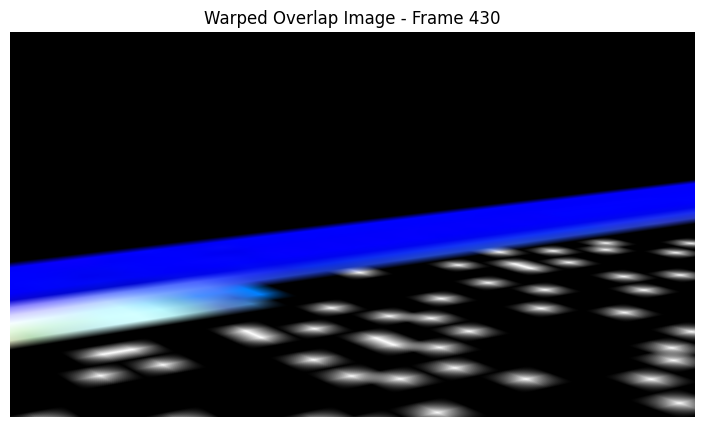

Iteration:  57%|█████▋    | 255/450 [00:46<00:36,  5.27it/s]

Normalized Homography matrix for frame 385:
[[ 4.4976972e-02  4.8166220e-03  8.6590126e+01]
 [ 2.9438742e-02  2.4385865e-01 -1.6267473e+02]
 [-3.2828691e-05  4.5537413e-03  1.0000000e+00]]


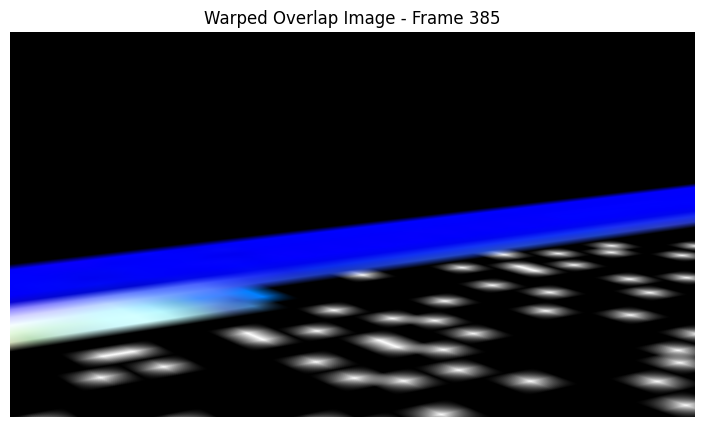

Iteration:  57%|█████▋    | 256/450 [00:46<00:36,  5.32it/s]

Normalized Homography matrix for frame 185:
[[ 7.8198828e-02  1.5595630e-02  9.9709648e+01]
 [ 3.6189254e-02  3.8569278e-01 -3.3824490e+02]
 [-3.7905895e-05  7.2703832e-03  1.0000000e+00]]


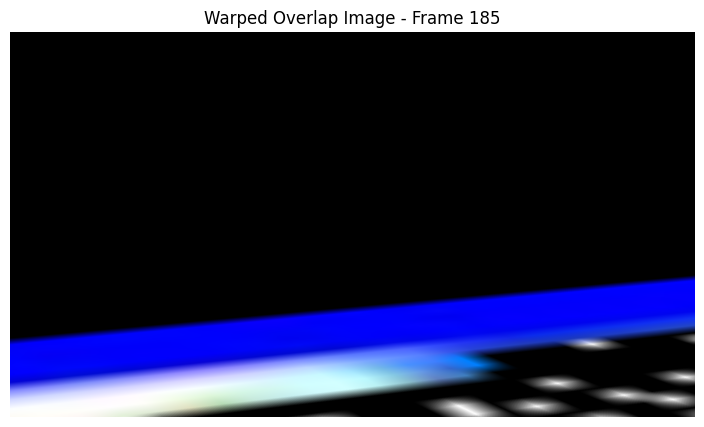

Iteration:  57%|█████▋    | 257/450 [00:46<00:35,  5.45it/s]

Normalized Homography matrix for frame 190:
[[ 7.4475102e-02  9.7510675e-03  1.0548174e+02]
 [ 3.5306677e-02  3.7542745e-01 -3.2270270e+02]
 [-6.1738960e-05  6.9146804e-03  1.0000000e+00]]


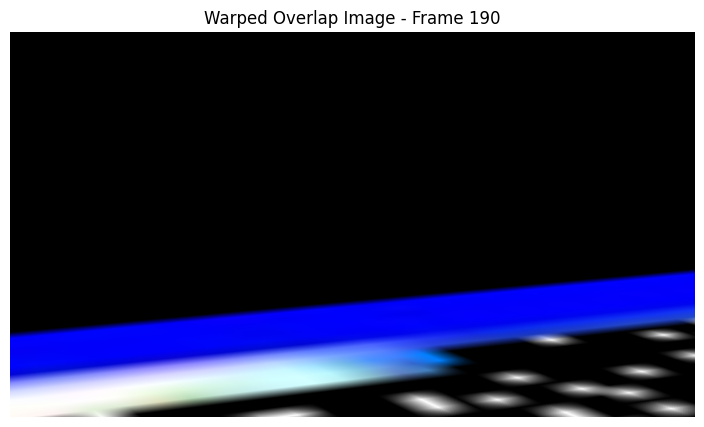

Iteration:  57%|█████▋    | 258/450 [00:46<00:34,  5.57it/s]

Normalized Homography matrix for frame 157:
[[ 7.1973868e-02 -5.0957701e-03  1.9876026e+01]
 [ 2.2029480e-02  2.6251504e-01 -2.3768393e+02]
 [-2.2990387e-05  4.2122570e-03  1.0000000e+00]]


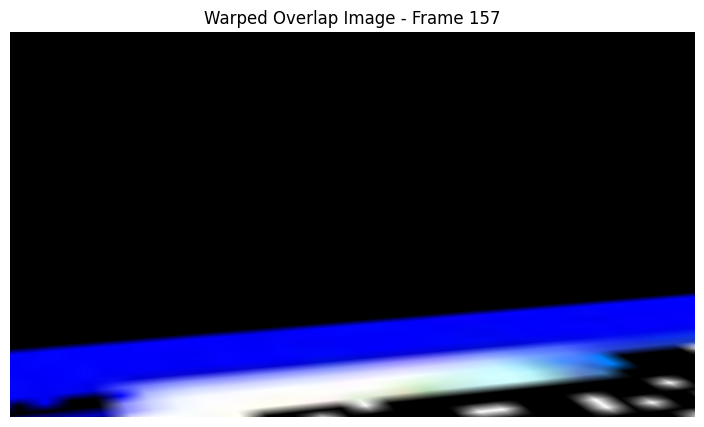

Iteration:  58%|█████▊    | 259/450 [00:47<00:33,  5.62it/s]

Normalized Homography matrix for frame 31:
[[ 3.7028107e-01 -1.0557912e-02 -1.7293530e+02]
 [ 5.2809462e-02  1.5686322e+00 -1.1527045e+03]
 [-1.3437352e-04  3.1897381e-02  1.0000000e+00]]


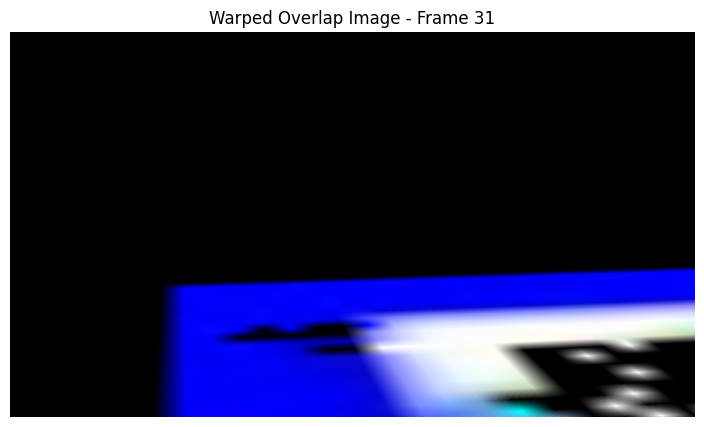

Iteration:  58%|█████▊    | 260/450 [00:47<00:33,  5.61it/s]

Normalized Homography matrix for frame 32:
[[ 2.6047787e-01 -2.0250145e-03 -1.2417824e+02]
 [ 3.8766313e-02  1.1420566e+00 -8.4184839e+02]
 [ 8.4752428e-06  2.2651900e-02  1.0000000e+00]]


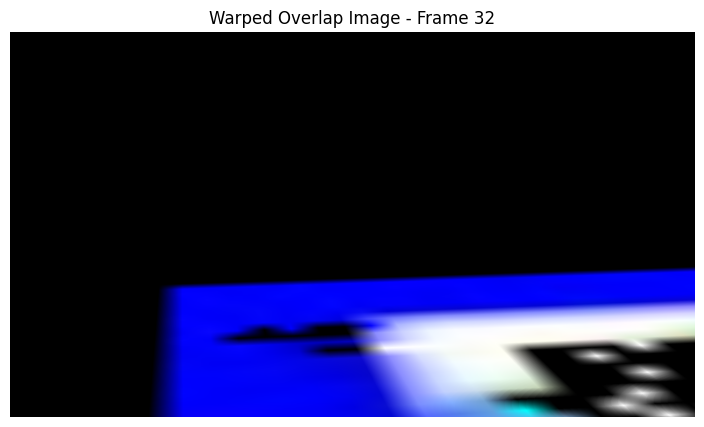

Iteration:  58%|█████▊    | 261/450 [00:47<00:33,  5.62it/s]

Normalized Homography matrix for frame 357:
[[ 4.7014527e-02  5.1282519e-03  8.7384354e+01]
 [ 2.9981708e-02  2.5581396e-01 -1.7043098e+02]
 [-3.8322345e-05  4.7392803e-03  1.0000000e+00]]


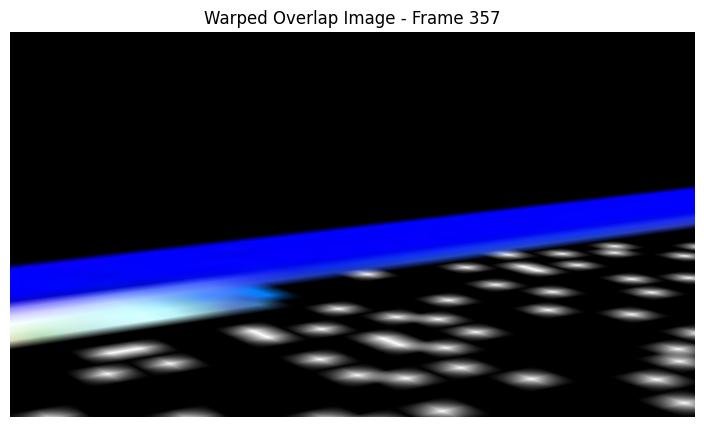

Iteration:  58%|█████▊    | 262/450 [00:47<00:33,  5.56it/s]

Normalized Homography matrix for frame 212:
[[ 1.0179559e-01  1.6614646e-02  1.7920198e+02]
 [ 6.2707819e-02  5.4008055e-01 -4.4017960e+02]
 [-4.7511836e-05  1.0162655e-02  1.0000000e+00]]


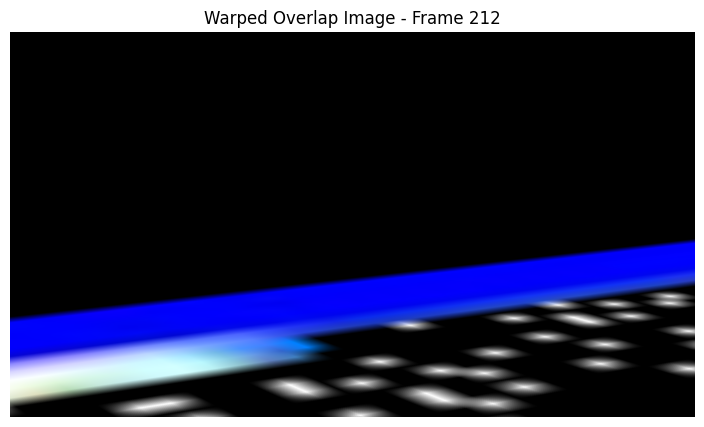

Iteration:  58%|█████▊    | 263/450 [00:47<00:33,  5.60it/s]

Normalized Homography matrix for frame 76:
[[ 1.0831444e-01  3.5648752e-02 -2.2848354e+01]
 [ 2.7102226e-02  4.4622582e-01 -3.7473862e+02]
 [ 1.3642847e-04  8.2127796e-03  1.0000000e+00]]


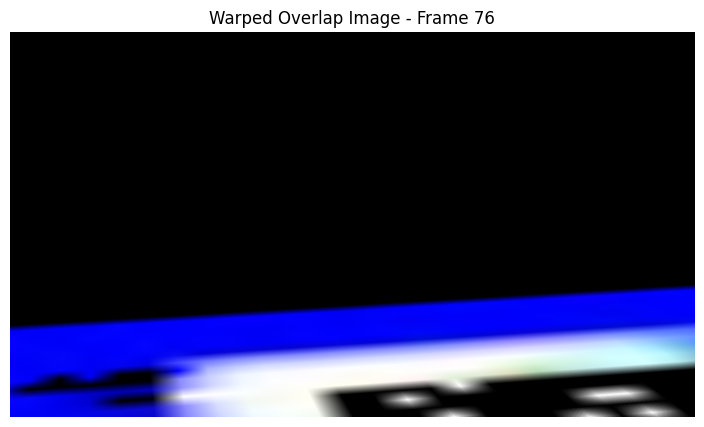

Iteration:  59%|█████▊    | 264/450 [00:47<00:33,  5.62it/s]

Normalized Homography matrix for frame 100:
[[ 9.8136209e-02  4.9682964e-02 -1.0591495e+01]
 [ 2.7715486e-02  3.8245156e-01 -3.4454486e+02]
 [ 1.6385883e-04  6.9967960e-03  1.0000000e+00]]


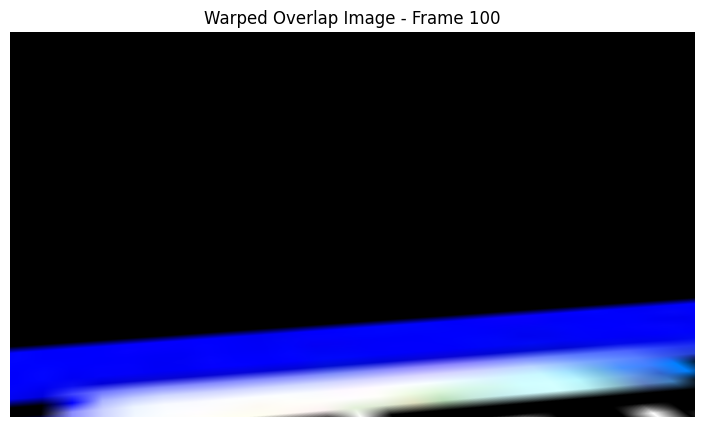

Iteration:  59%|█████▉    | 265/450 [00:48<00:32,  5.63it/s]

Normalized Homography matrix for frame 101:
[[ 9.4756305e-02  5.3173099e-02 -1.3083936e+01]
 [ 2.5422189e-02  3.6208799e-01 -3.2810388e+02]
 [ 1.5220648e-04  6.7086210e-03  1.0000000e+00]]


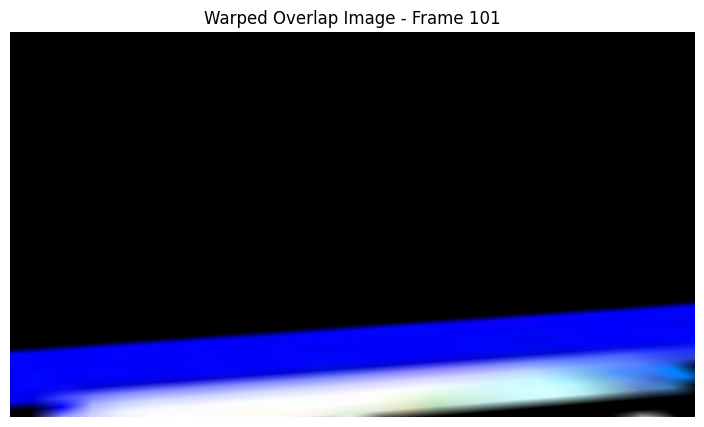

Iteration:  59%|█████▉    | 266/450 [00:48<00:32,  5.67it/s]

Normalized Homography matrix for frame 103:
[[ 8.2274400e-02  2.4005149e-02  1.4603027e+01]
 [ 2.4200344e-02  3.4797975e-01 -3.1376932e+02]
 [ 5.8851601e-05  6.4040758e-03  1.0000000e+00]]


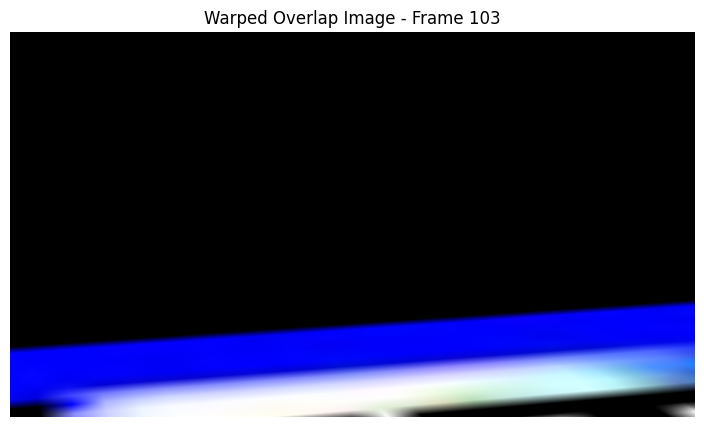

Iteration:  59%|█████▉    | 267/450 [00:48<00:32,  5.69it/s]

Normalized Homography matrix for frame 425:
[[ 4.4090815e-02  6.3581020e-03  8.3603729e+01]
 [ 2.8339380e-02  2.3925865e-01 -1.5722375e+02]
 [-3.7029953e-05  4.4499217e-03  1.0000000e+00]]


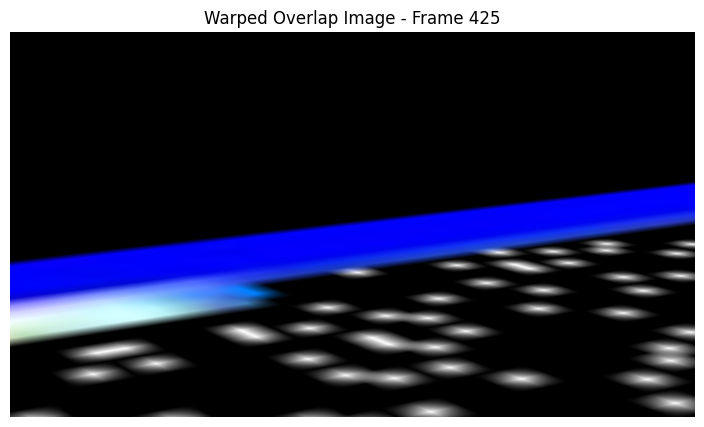

Iteration:  60%|█████▉    | 268/450 [00:48<00:32,  5.62it/s]

Normalized Homography matrix for frame 188:
[[ 8.3325684e-02  1.5038464e-02  1.1465258e+02]
 [ 4.0628053e-02  4.1722462e-01 -3.6453223e+02]
 [-4.2932075e-05  7.9549281e-03  1.0000000e+00]]


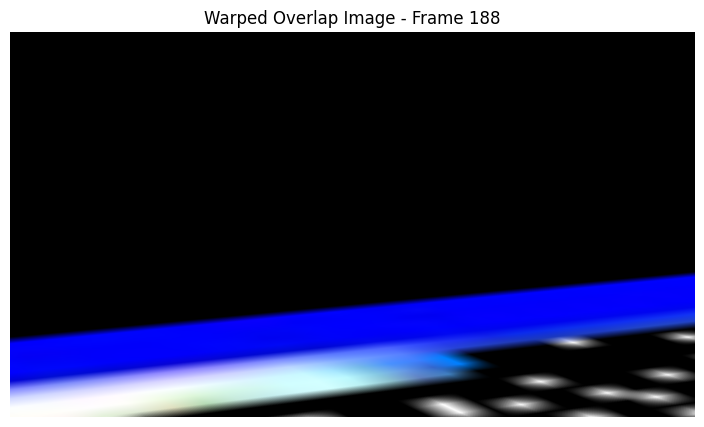

Iteration:  60%|█████▉    | 269/450 [00:48<00:32,  5.63it/s]

Normalized Homography matrix for frame 144:
[[ 4.7939080e-01  4.3962479e-01 -1.4760428e+02]
 [ 9.2398092e-02  2.2366693e+00 -1.8007802e+03]
 [ 2.2450273e-04  3.9324068e-02  1.0000000e+00]]


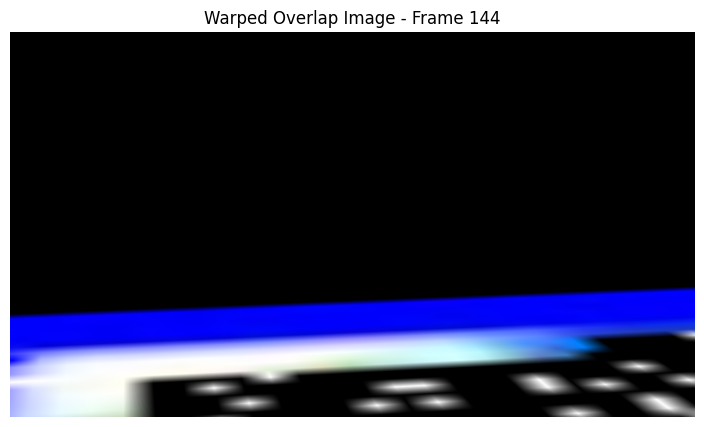

Iteration:  60%|██████    | 270/450 [00:48<00:31,  5.64it/s]

Normalized Homography matrix for frame 177:
[[ 6.9573238e-02  3.3278284e-03  8.3663406e+01]
 [ 3.2640088e-02  3.1976402e-01 -2.9489554e+02]
 [-9.0882595e-06  6.1392998e-03  1.0000000e+00]]


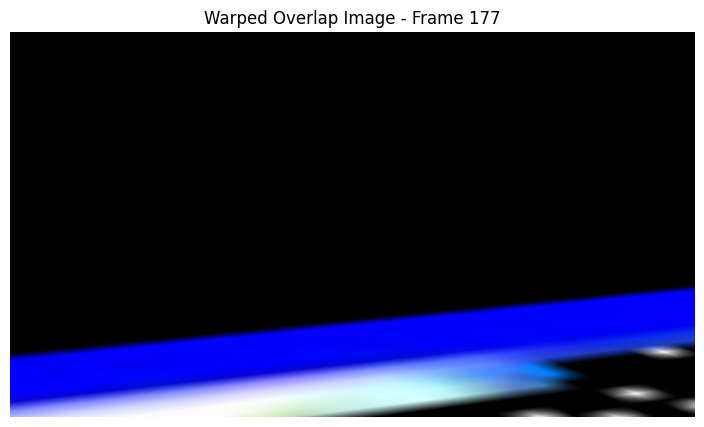

Iteration:  60%|██████    | 271/450 [00:49<00:31,  5.69it/s]

Normalized Homography matrix for frame 346:
[[ 5.1038045e-02  7.9850955e-03  8.9185760e+01]
 [ 3.1865545e-02  2.7568099e-01 -1.8475313e+02]
 [-4.2411924e-05  5.1663620e-03  1.0000000e+00]]


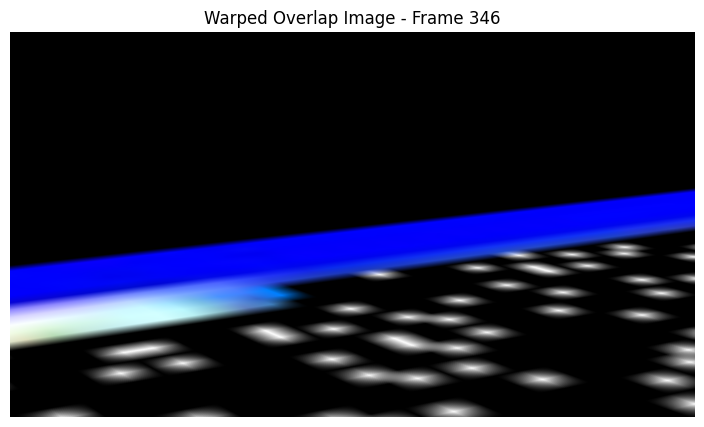

Iteration:  60%|██████    | 272/450 [00:49<00:31,  5.65it/s]

Normalized Homography matrix for frame 232:
[[ 7.7293657e-02  1.0433053e-02  1.6060159e+02]
 [ 5.1482435e-02  4.1846240e-01 -3.2916833e+02]
 [-6.6155335e-05  7.8729121e-03  1.0000000e+00]]


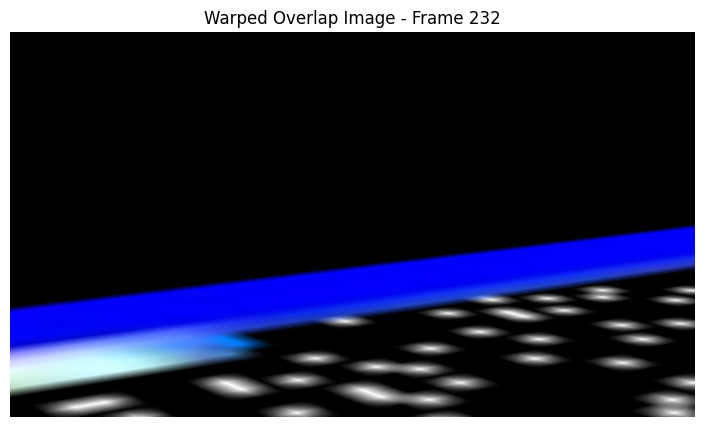

Iteration:  61%|██████    | 273/450 [00:49<00:31,  5.62it/s]

Normalized Homography matrix for frame 410:
[[ 4.6876825e-02  9.2137549e-03  8.7676765e+01]
 [ 3.0154459e-02  2.5574988e-01 -1.6901836e+02]
 [-3.9429684e-05  4.8204721e-03  1.0000000e+00]]


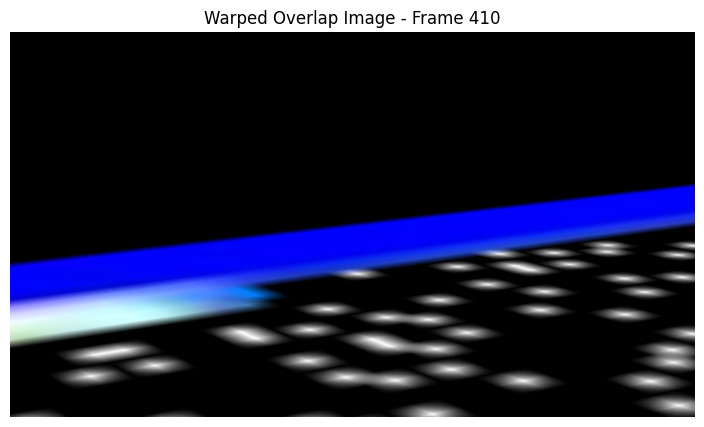

Iteration:  61%|██████    | 274/450 [00:49<00:31,  5.59it/s]

Normalized Homography matrix for frame 68:
[[ 1.5252328e-01  3.9519660e-02 -2.6617434e+01]
 [ 3.5119042e-02  6.6885233e-01 -5.3844189e+02]
 [ 6.7700348e-05  1.3831846e-02  1.0000000e+00]]


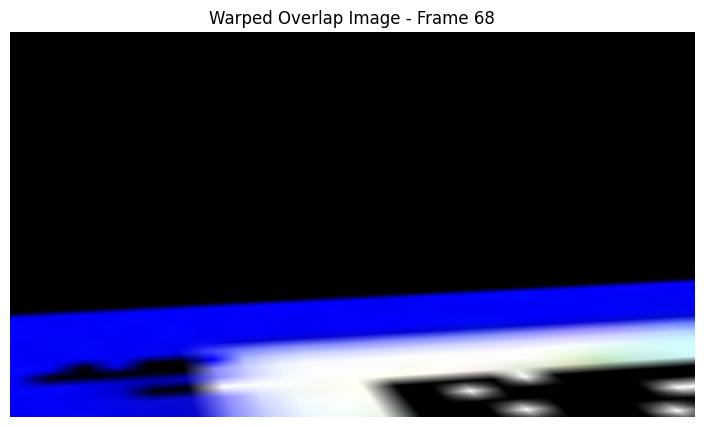

Iteration:  61%|██████    | 275/450 [00:49<00:31,  5.60it/s]

Normalized Homography matrix for frame 220:
[[ 8.9044742e-02  1.6406149e-02  1.6556454e+02]
 [ 5.6266185e-02  4.7155830e-01 -3.7854022e+02]
 [-6.1201092e-05  8.9015989e-03  1.0000000e+00]]


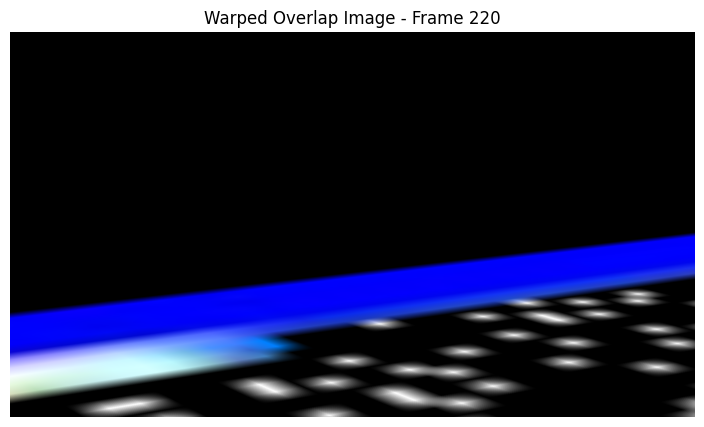

Iteration:  61%|██████▏   | 276/450 [00:50<00:31,  5.54it/s]

Normalized Homography matrix for frame 7:
[[ 8.2584029e-01 -2.2275217e-02 -6.0319513e+02]
 [ 6.5933555e-02  3.7073350e+00 -2.6304790e+03]
 [ 1.1907405e-04  6.8109408e-02  1.0000000e+00]]


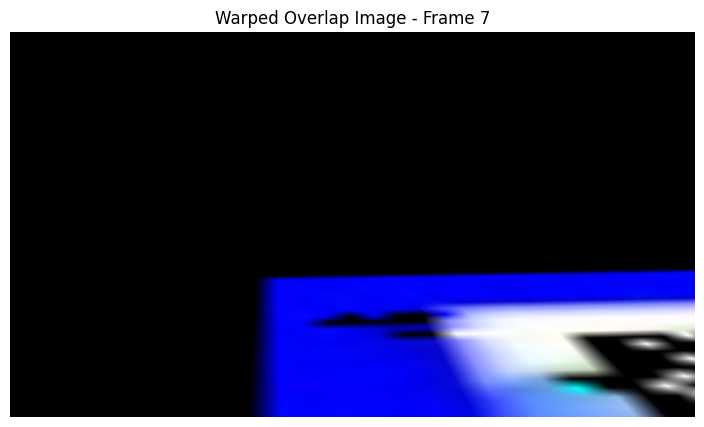

Iteration:  62%|██████▏   | 277/450 [00:50<00:30,  5.60it/s]

Normalized Homography matrix for frame 108:
[[ 1.8268624e-01  6.1615799e-02  4.4871094e+01]
 [ 5.6623865e-02  8.0083734e-01 -7.2715948e+02]
 [ 4.1131680e-05  1.7062740e-02  1.0000000e+00]]


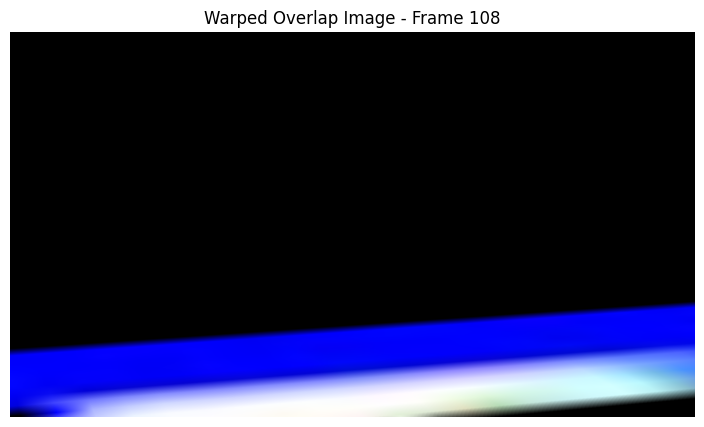

Iteration:  62%|██████▏   | 278/450 [00:50<00:30,  5.58it/s]

Normalized Homography matrix for frame 234:
[[ 7.6758355e-02  1.2205475e-02  1.5802084e+02]
 [ 5.0526813e-02  4.1431355e-01 -3.2395227e+02]
 [-7.7340330e-05  7.7523692e-03  1.0000000e+00]]


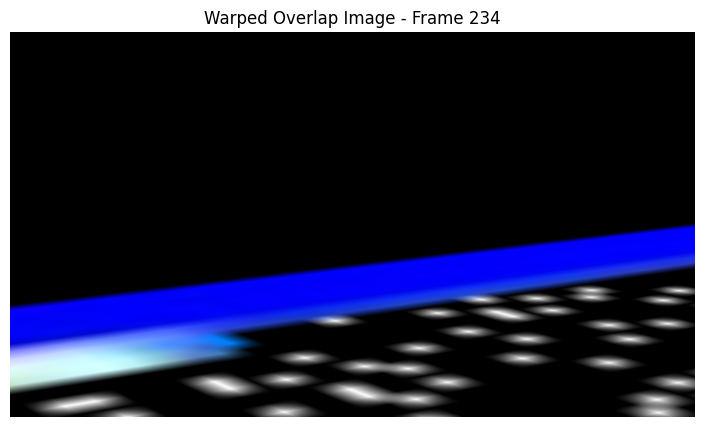

Iteration:  62%|██████▏   | 279/450 [00:50<00:30,  5.58it/s]

Normalized Homography matrix for frame 160:
[[ 7.39406645e-02 -3.37347272e-03  2.12051239e+01]
 [ 2.37303469e-02  2.67574459e-01 -2.43855179e+02]
 [-1.17711315e-05  4.37315227e-03  1.00000000e+00]]


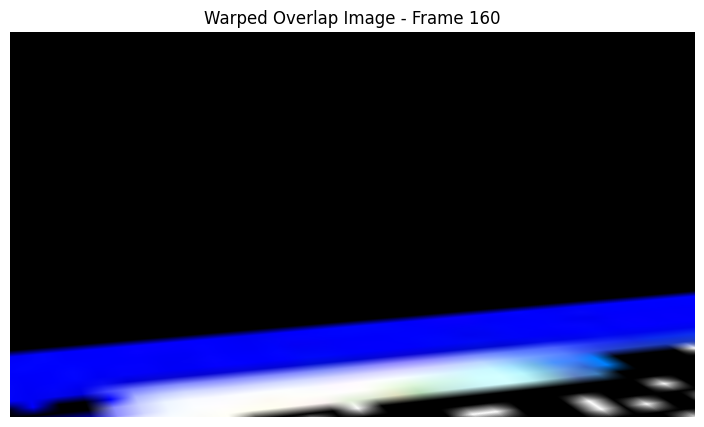

Iteration:  62%|██████▏   | 280/450 [00:50<00:30,  5.60it/s]

Normalized Homography matrix for frame 50:
[[ 2.1485724e-01 -9.1423998e-03 -4.5120285e+01]
 [ 4.9820308e-02  9.7456306e-01 -7.3946826e+02]
 [ 6.6331966e-05  1.9994825e-02  1.0000000e+00]]


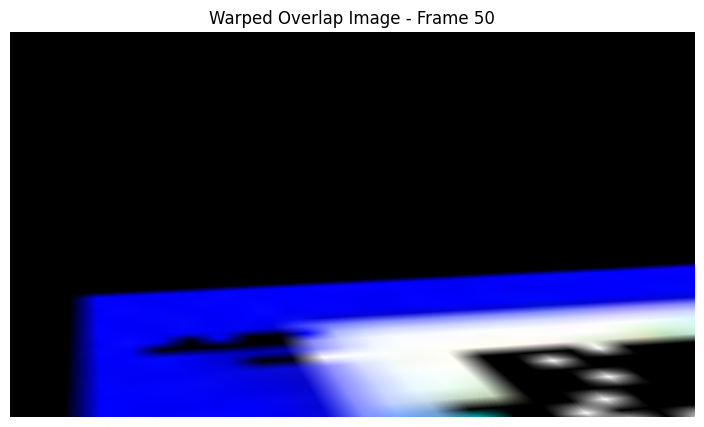

Iteration:  62%|██████▏   | 281/450 [00:50<00:30,  5.61it/s]

Normalized Homography matrix for frame 438:
[[ 4.2802949e-02  4.4148713e-03  8.1730820e+01]
 [ 2.7630176e-02  2.3108323e-01 -1.5151921e+02]
 [-3.4177916e-05  4.2533809e-03  1.0000000e+00]]


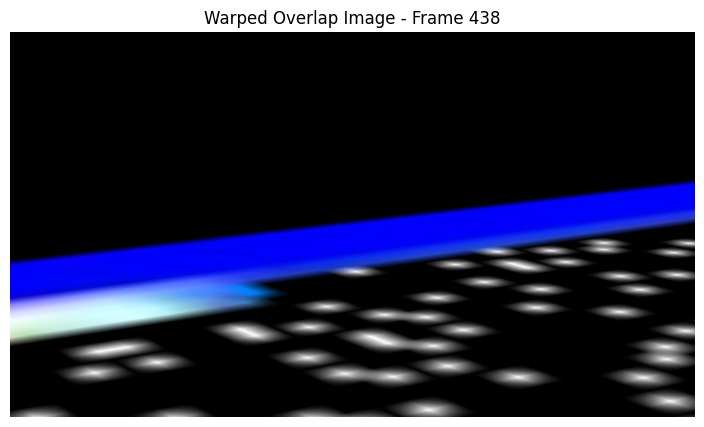

Iteration:  63%|██████▎   | 282/450 [00:51<00:30,  5.57it/s]

Normalized Homography matrix for frame 70:
[[ 1.4941548e-01  3.6459487e-02 -2.3615412e+01]
 [ 3.7715558e-02  6.4907366e-01 -5.2807819e+02]
 [ 1.2485417e-04  1.3113753e-02  1.0000000e+00]]


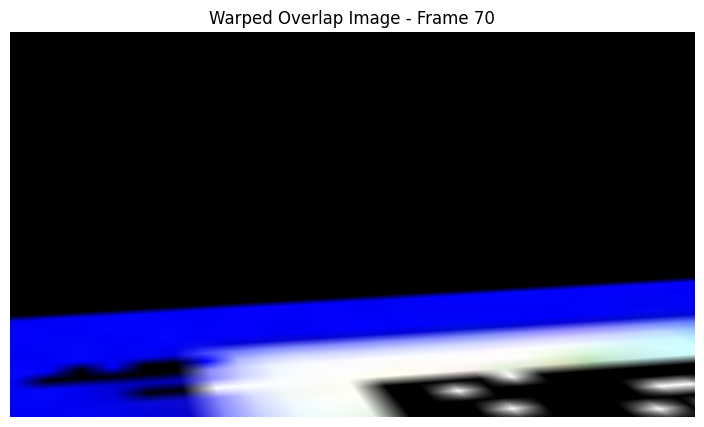

Iteration:  63%|██████▎   | 283/450 [00:51<00:29,  5.65it/s]

Normalized Homography matrix for frame 45:
[[ 1.3274945e-01 -3.0526661e-03 -4.0918488e+01]
 [ 2.5023011e-02  5.8520490e-01 -4.3889157e+02]
 [ 7.0284027e-06  1.1312316e-02  1.0000000e+00]]


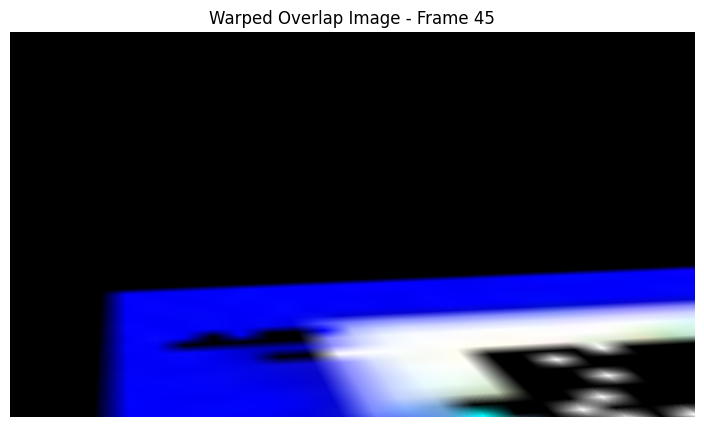

Iteration:  63%|██████▎   | 284/450 [00:51<00:29,  5.66it/s]

Normalized Homography matrix for frame 263:
[[ 4.6271399e-02  3.7866859e-03  1.2444136e+02]
 [ 3.4807924e-02  2.5953650e-01 -1.9333893e+02]
 [-3.7825172e-05  4.8208982e-03  1.0000000e+00]]


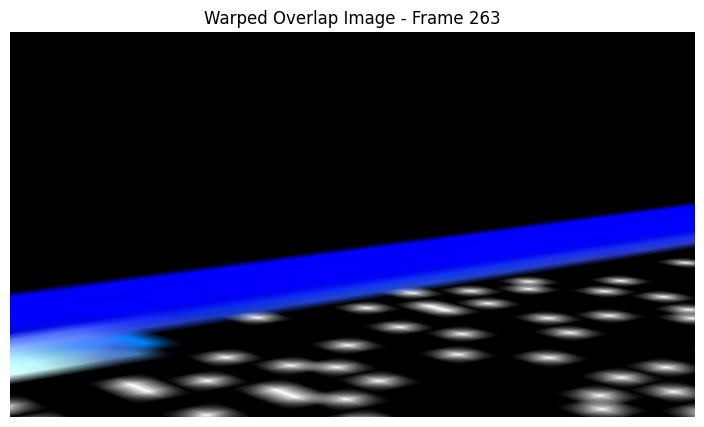

Iteration:  63%|██████▎   | 285/450 [00:51<00:29,  5.61it/s]

Normalized Homography matrix for frame 129:
[[ 1.0986399e-01  3.1713136e-02  5.1297066e+01]
 [ 3.6380898e-02  4.8585337e-01 -4.5462723e+02]
 [ 7.9019010e-06  1.0045777e-02  1.0000000e+00]]


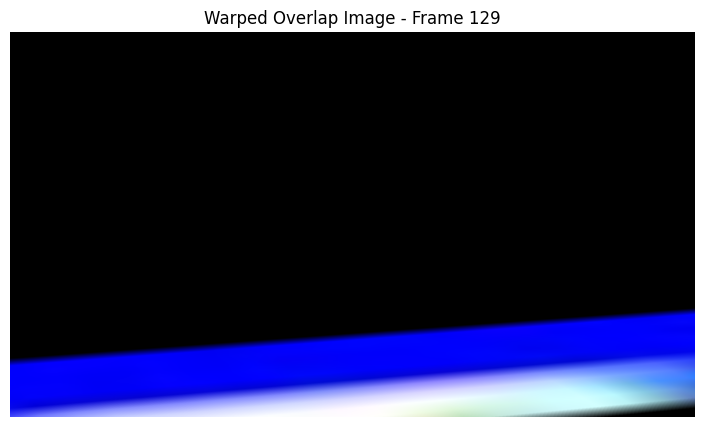

Iteration:  64%|██████▎   | 286/450 [00:51<00:29,  5.58it/s]

Normalized Homography matrix for frame 20:
[[ 1.2720754e+00 -3.8722600e-03 -7.5766608e+02]
 [ 1.6236173e-01  5.5861015e+00 -4.0394639e+03]
 [ 2.6927007e-04  1.1142964e-01  1.0000000e+00]]


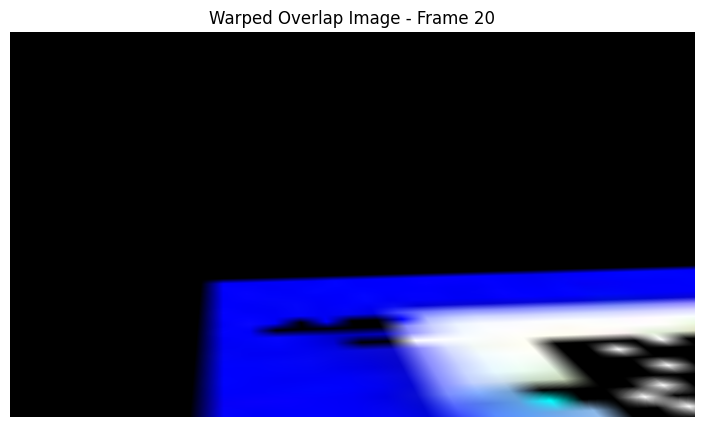

Iteration:  64%|██████▍   | 287/450 [00:52<00:29,  5.61it/s]

Normalized Homography matrix for frame 195:
[[ 7.07149953e-02 -1.55736064e-03  1.16568054e+02]
 [ 3.84084247e-02  3.62162024e-01 -3.10317413e+02]
 [-2.80148688e-05  6.54455181e-03  1.00000000e+00]]


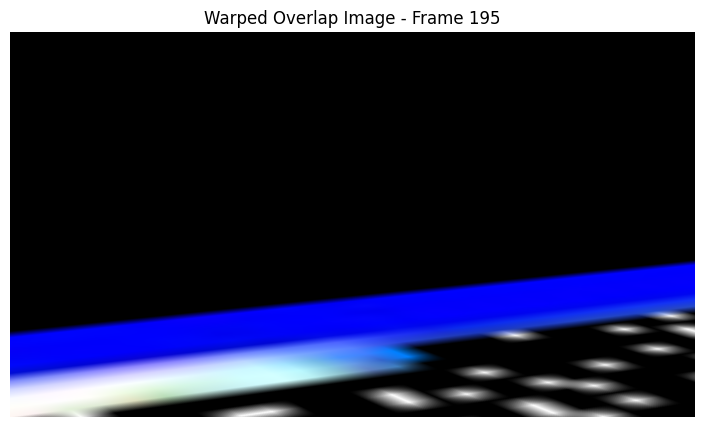

Iteration:  64%|██████▍   | 288/450 [00:52<00:28,  5.65it/s]

Normalized Homography matrix for frame 294:
[[ 3.6220439e-02  6.2845149e-03  9.1407112e+01]
 [ 2.5466703e-02  2.0030525e-01 -1.3722623e+02]
 [-4.1608313e-05  3.7574989e-03  1.0000000e+00]]


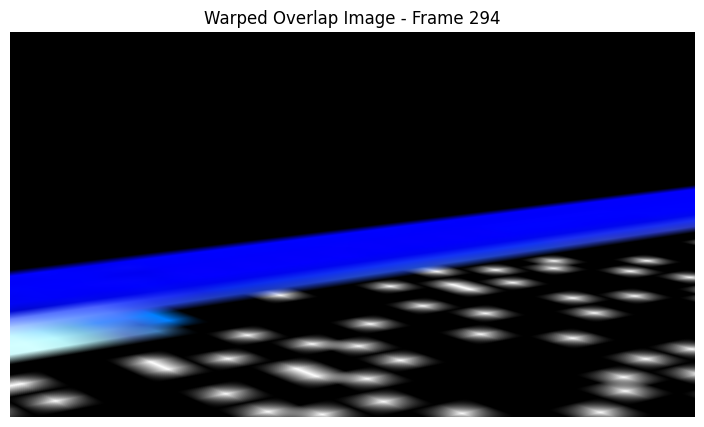

Iteration:  64%|██████▍   | 289/450 [00:52<00:28,  5.64it/s]

Normalized Homography matrix for frame 95:
[[ 7.3077217e-02  3.3764064e-02 -9.6498833e+00]
 [ 1.8239580e-02  2.7833468e-01 -2.4678497e+02]
 [ 9.3722119e-05  4.8112832e-03  1.0000000e+00]]


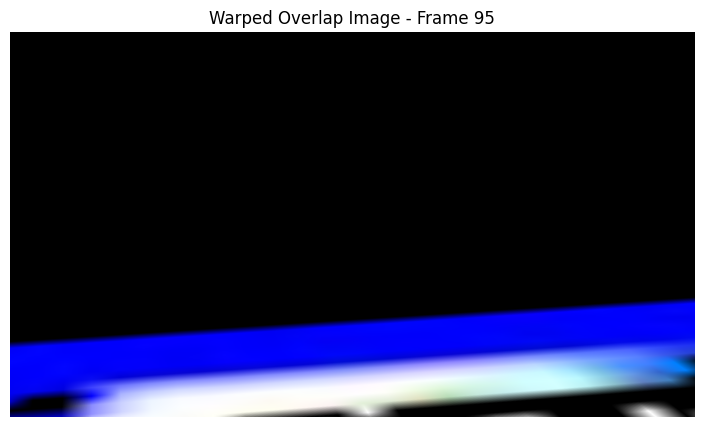

Iteration:  64%|██████▍   | 290/450 [00:52<00:28,  5.66it/s]

Normalized Homography matrix for frame 400:
[[ 4.4270549e-02  3.5930343e-03  8.5717941e+01]
 [ 2.8945465e-02  2.3998897e-01 -1.5971368e+02]
 [-3.3415810e-05  4.4495105e-03  1.0000000e+00]]


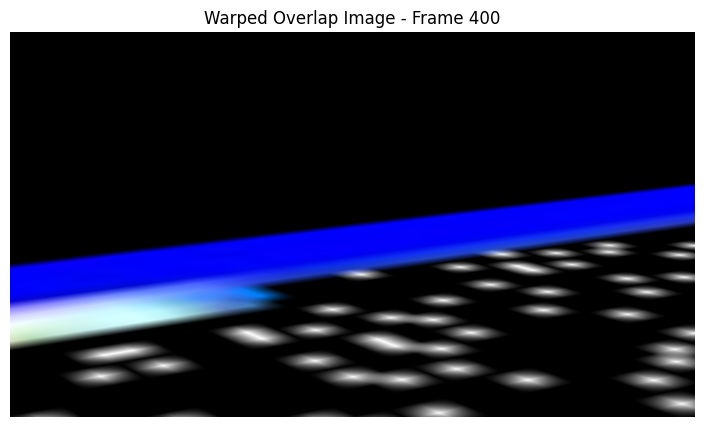

Iteration:  65%|██████▍   | 291/450 [00:52<00:28,  5.61it/s]

Normalized Homography matrix for frame 110:
[[ 1.8932109e-01  6.4916499e-02  5.0102108e+01]
 [ 5.8413859e-02  8.2157773e-01 -7.5401141e+02]
 [ 8.9483783e-06  1.7813072e-02  1.0000000e+00]]


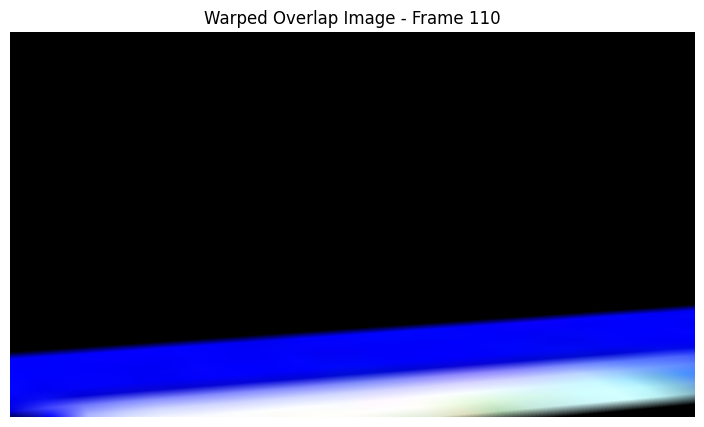

Iteration:  65%|██████▍   | 292/450 [00:52<00:28,  5.63it/s]

Normalized Homography matrix for frame 390:
[[ 4.5622636e-02  5.4309266e-03  8.6263191e+01]
 [ 2.9979810e-02  2.4505550e-01 -1.6377850e+02]
 [-2.9905588e-05  4.5882394e-03  1.0000000e+00]]


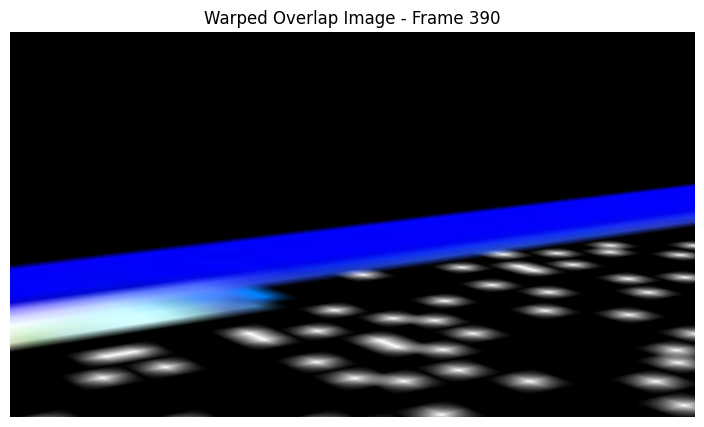

Iteration:  65%|██████▌   | 293/450 [00:53<00:31,  4.99it/s]

Normalized Homography matrix for frame 191:
[[ 7.60286972e-02  7.78662646e-03  1.14865105e+02]
 [ 3.85868587e-02  3.86027873e-01 -3.33869629e+02]
 [-4.37598646e-05  7.22358841e-03  1.00000000e+00]]


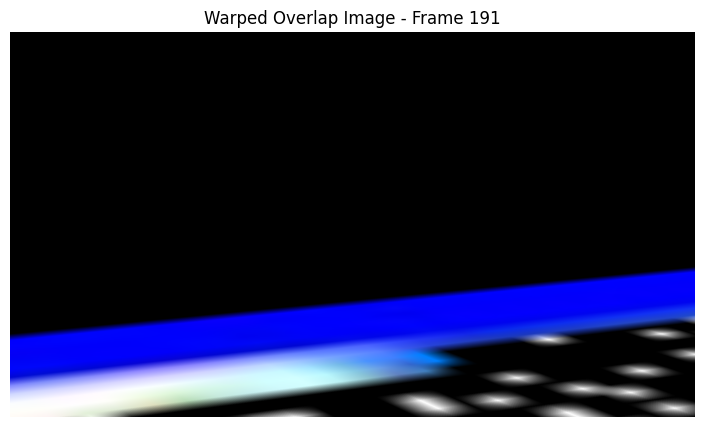

Iteration:  65%|██████▌   | 294/450 [00:53<00:29,  5.21it/s]

Normalized Homography matrix for frame 122:
[[ 1.2055278e-01  4.4494111e-02  3.8167667e+01]
 [ 3.7739962e-02  5.1896787e-01 -4.8498428e+02]
 [ 3.4675031e-05  1.0752995e-02  1.0000000e+00]]


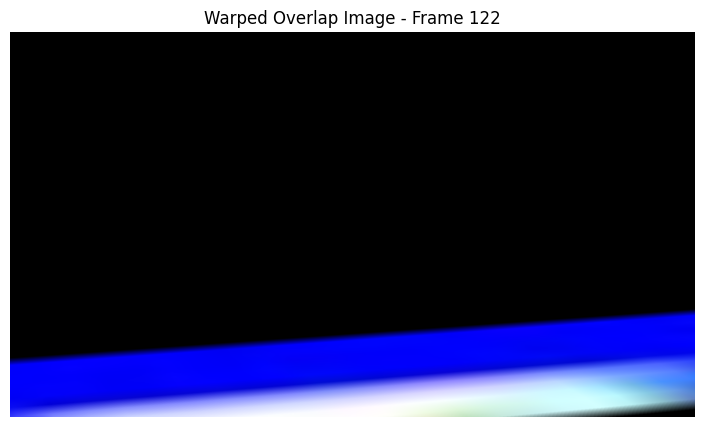

Iteration:  66%|██████▌   | 295/450 [00:53<00:28,  5.35it/s]

Normalized Homography matrix for frame 387:
[[ 4.5134522e-02  4.9230834e-03  8.4773720e+01]
 [ 2.9449886e-02  2.4075170e-01 -1.6102852e+02]
 [-3.2409149e-05  4.5031728e-03  1.0000000e+00]]


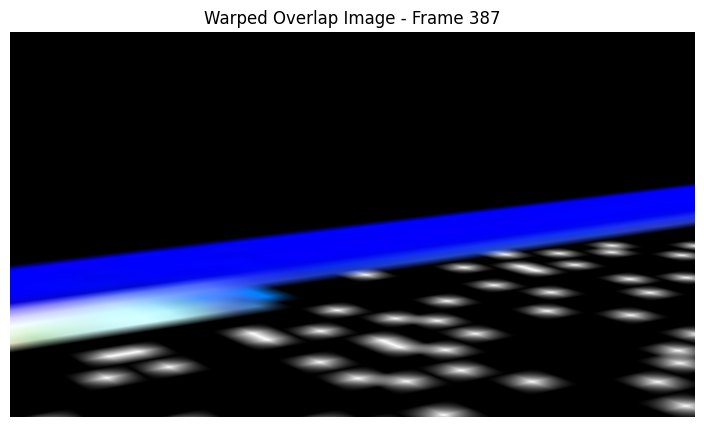

Iteration:  66%|██████▌   | 296/450 [00:53<00:28,  5.40it/s]

Normalized Homography matrix for frame 328:
[[ 4.9781427e-02  3.2697027e-03  8.5889961e+01]
 [ 3.1439494e-02  2.6317120e-01 -1.7926517e+02]
 [-2.7549750e-05  4.8742527e-03  1.0000000e+00]]


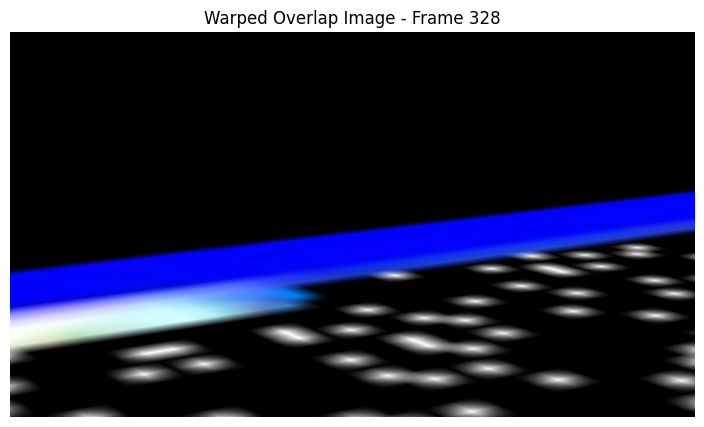

Iteration:  66%|██████▌   | 297/450 [00:53<00:28,  5.45it/s]

Normalized Homography matrix for frame 183:
[[ 7.0964098e-02  3.4613220e-03  9.9943184e+01]
 [ 3.5765599e-02  3.4737521e-01 -3.1315387e+02]
 [-1.5063231e-06  6.5572034e-03  1.0000000e+00]]


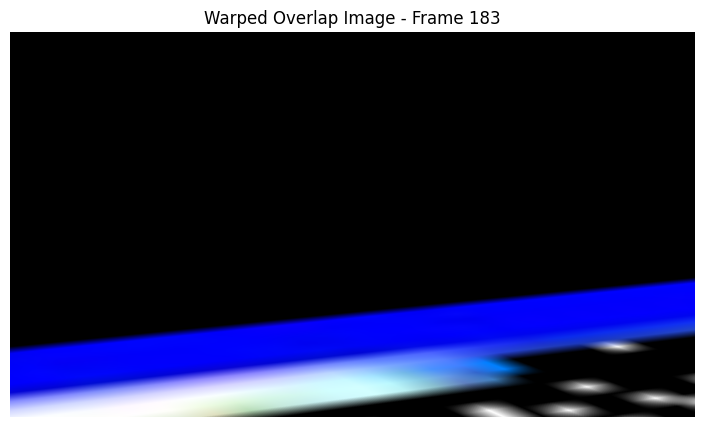

Iteration:  66%|██████▌   | 298/450 [00:54<00:27,  5.54it/s]

Normalized Homography matrix for frame 415:
[[ 4.2871471e-02  4.2776862e-04  8.3818863e+01]
 [ 2.8013876e-02  2.3094422e-01 -1.5362289e+02]
 [-3.4474640e-05  4.2204070e-03  1.0000000e+00]]


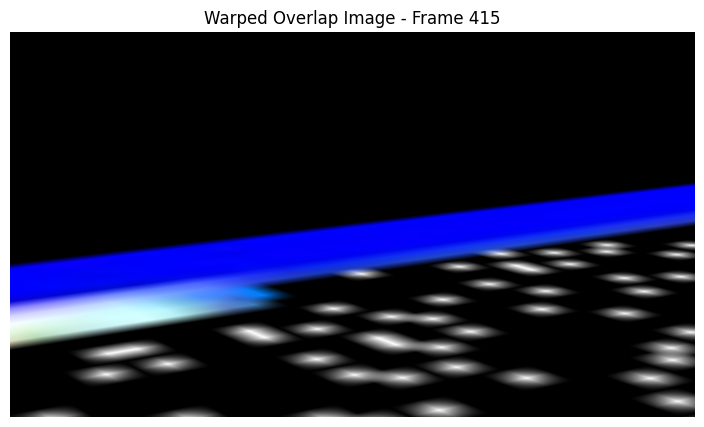

Iteration:  66%|██████▋   | 299/450 [00:54<00:27,  5.50it/s]

Normalized Homography matrix for frame 288:
[[ 3.3637211e-02  1.7368045e-03  9.6475761e+01]
 [ 2.5051095e-02  1.9204579e-01 -1.3191997e+02]
 [-3.7613012e-05  3.5504524e-03  1.0000000e+00]]


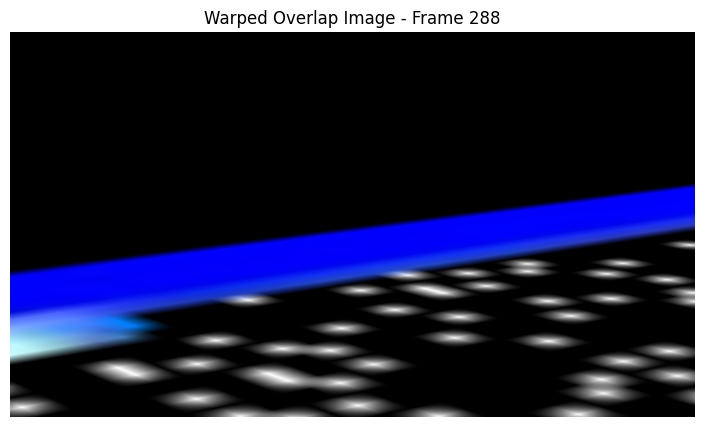

Iteration:  67%|██████▋   | 300/450 [00:54<00:27,  5.51it/s]

Normalized Homography matrix for frame 61:
[[ 1.32297799e-01 -5.75991534e-03 -5.45977020e+00]
 [ 3.20691690e-02  5.97065091e-01 -4.67465179e+02]
 [-2.56185303e-05  1.20751895e-02  1.00000000e+00]]


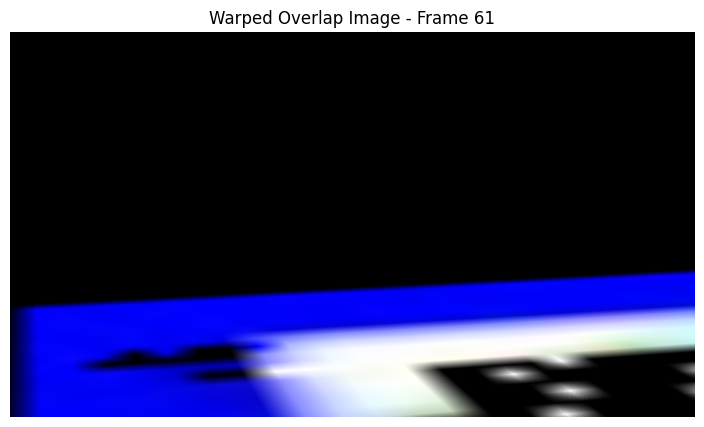

Iteration:  67%|██████▋   | 301/450 [00:54<00:26,  5.55it/s]

Normalized Homography matrix for frame 373:
[[ 4.5553762e-02  4.5749065e-03  8.6350967e+01]
 [ 3.0246487e-02  2.4400957e-01 -1.6373378e+02]
 [-2.4357225e-05  4.5643118e-03  1.0000000e+00]]


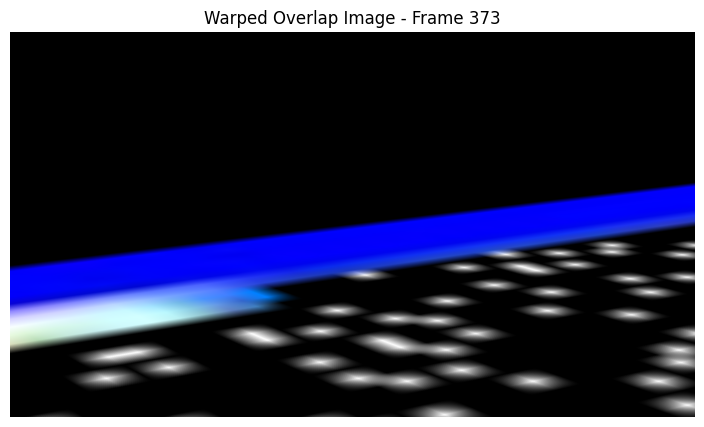

Iteration:  67%|██████▋   | 302/450 [00:54<00:26,  5.52it/s]

Normalized Homography matrix for frame 214:
[[ 8.3424740e-02  2.0162202e-03  1.5695000e+02]
 [ 5.3521004e-02  4.3652886e-01 -3.5852060e+02]
 [-2.6713769e-05  8.0732889e-03  1.0000000e+00]]


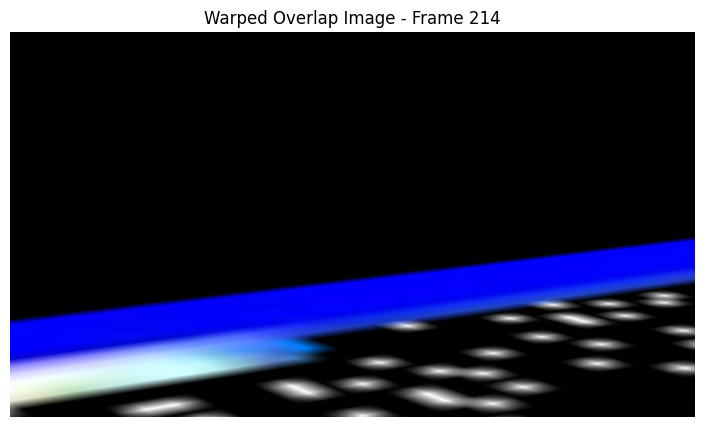

Iteration:  67%|██████▋   | 303/450 [00:54<00:26,  5.60it/s]

Normalized Homography matrix for frame 200:
[[ 8.255307e-02  9.996553e-03  1.307957e+02]
 [ 4.460157e-02  4.309873e-01 -3.585948e+02]
 [-3.852060e-05  7.718679e-03  1.000000e+00]]


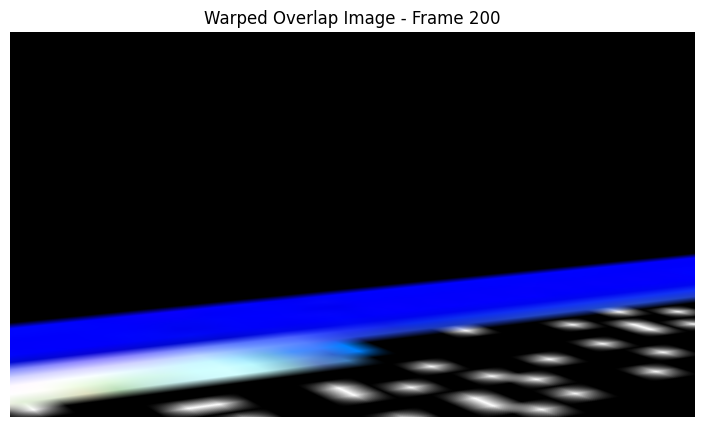

Iteration:  68%|██████▊   | 304/450 [00:55<00:25,  5.62it/s]

Normalized Homography matrix for frame 281:
[[ 3.6635306e-02  3.2943760e-03  1.0726808e+02]
 [ 2.8605895e-02  2.1066146e-01 -1.4801491e+02]
 [-2.9739458e-05  3.9468580e-03  1.0000000e+00]]


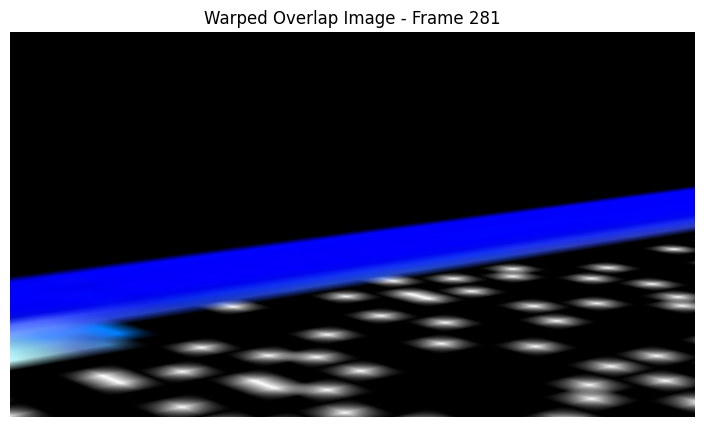

Iteration:  68%|██████▊   | 305/450 [00:55<00:25,  5.58it/s]

Normalized Homography matrix for frame 24:
[[ 1.6519563e-01 -6.4807772e-03 -8.5083221e+01]
 [ 2.0371474e-02  7.5409281e-01 -5.4964307e+02]
 [-1.0345185e-05  1.3792166e-02  1.0000000e+00]]


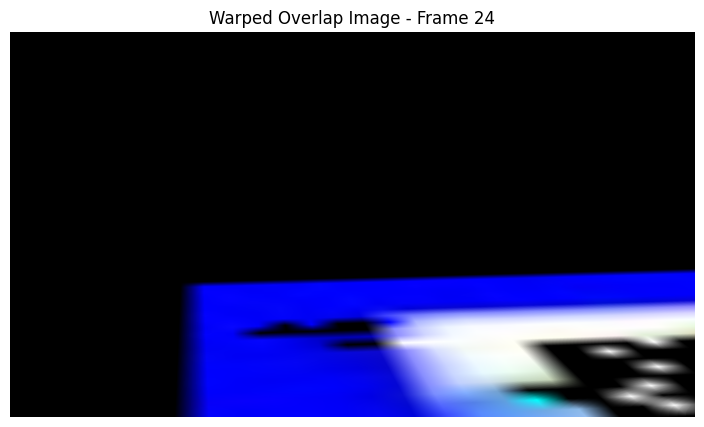

Iteration:  68%|██████▊   | 306/450 [00:55<00:25,  5.60it/s]

Normalized Homography matrix for frame 178:
[[ 9.3439922e-02  3.0228358e-02  1.0007888e+02]
 [ 4.2784408e-02  4.4143778e-01 -3.9978128e+02]
 [ 4.0517748e-06  8.8495575e-03  1.0000000e+00]]


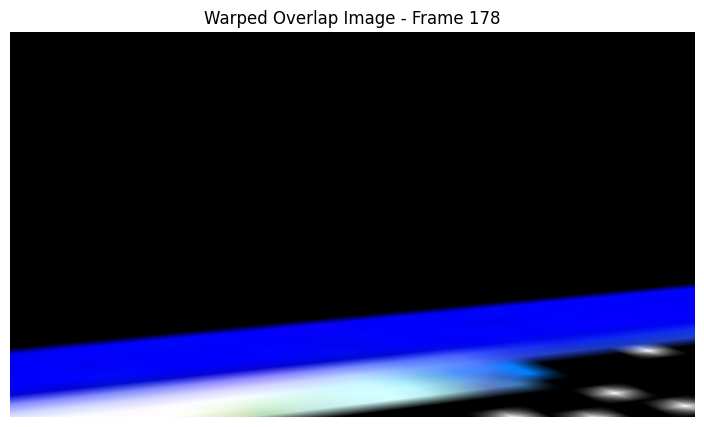

Iteration:  68%|██████▊   | 307/450 [00:55<00:25,  5.66it/s]

Normalized Homography matrix for frame 203:
[[ 8.5513540e-02  8.2589258e-03  1.4670792e+02]
 [ 4.9215350e-02  4.4935799e-01 -3.7389493e+02]
 [-4.4239285e-05  8.3113946e-03  1.0000000e+00]]


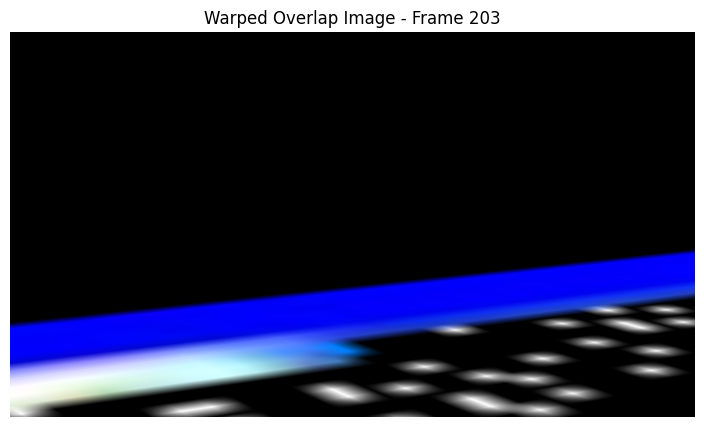

Iteration:  68%|██████▊   | 308/450 [00:55<00:24,  5.70it/s]

Normalized Homography matrix for frame 128:
[[ 1.2344201e-01  4.2271014e-02  5.1164635e+01]
 [ 3.9805781e-02  5.3326070e-01 -5.0045795e+02]
 [-1.1882822e-05  1.1458977e-02  1.0000000e+00]]


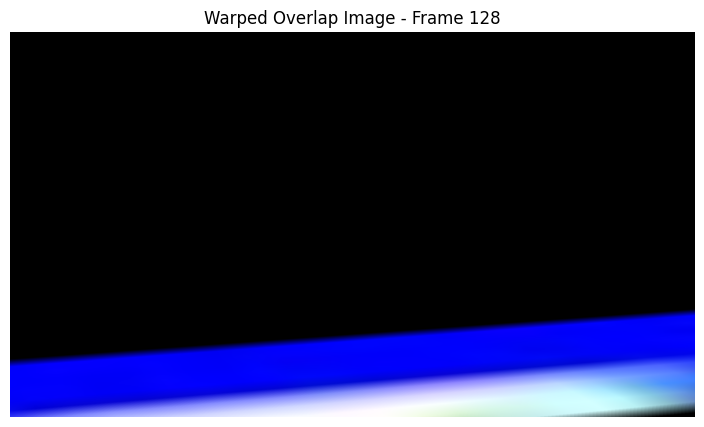

Iteration:  69%|██████▊   | 309/450 [00:55<00:24,  5.69it/s]

Normalized Homography matrix for frame 236:
[[ 7.1476668e-02  5.0965580e-03  1.5727754e+02]
 [ 4.8669875e-02  3.9133686e-01 -3.0643469e+02]
 [-6.4191903e-05  7.2994418e-03  1.0000000e+00]]


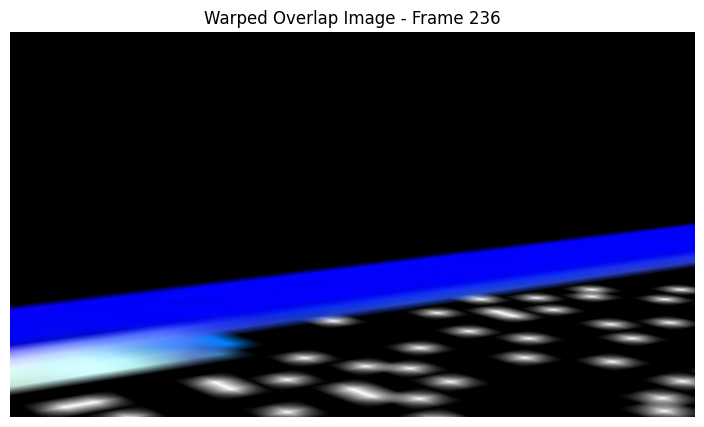

Iteration:  69%|██████▉   | 310/450 [00:56<00:24,  5.65it/s]

Normalized Homography matrix for frame 360:
[[ 4.6616346e-02  4.1640797e-03  8.8276863e+01]
 [ 2.9614512e-02  2.5524586e-01 -1.6915842e+02]
 [-4.9572922e-05  4.7531780e-03  1.0000000e+00]]


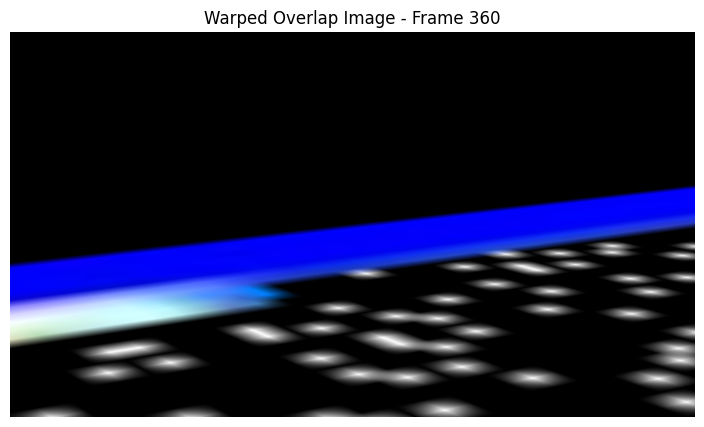

Iteration:  69%|██████▉   | 311/450 [00:56<00:24,  5.56it/s]

Normalized Homography matrix for frame 250:
[[ 5.9825432e-02  9.6631777e-03  1.4615602e+02]
 [ 4.2116176e-02  3.3802024e-01 -2.5777332e+02]
 [-6.0279726e-05  6.2994310e-03  1.0000000e+00]]


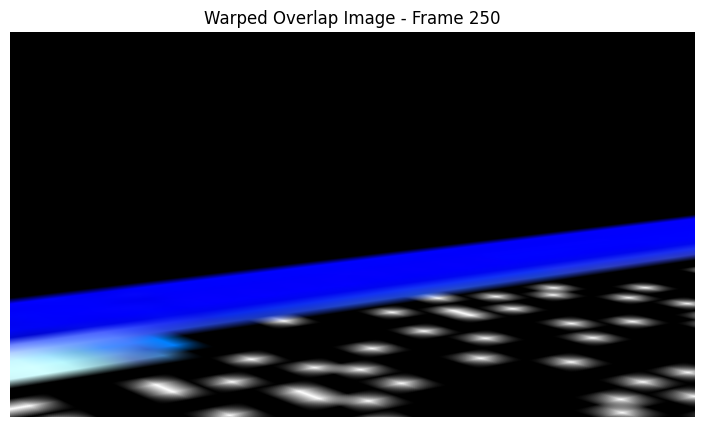

Iteration:  69%|██████▉   | 312/450 [00:56<00:24,  5.58it/s]

Normalized Homography matrix for frame 354:
[[ 4.8431505e-02  4.5601754e-03  8.7622810e+01]
 [ 3.1342208e-02  2.5679311e-01 -1.7327499e+02]
 [-3.6466310e-05  4.8245164e-03  1.0000000e+00]]


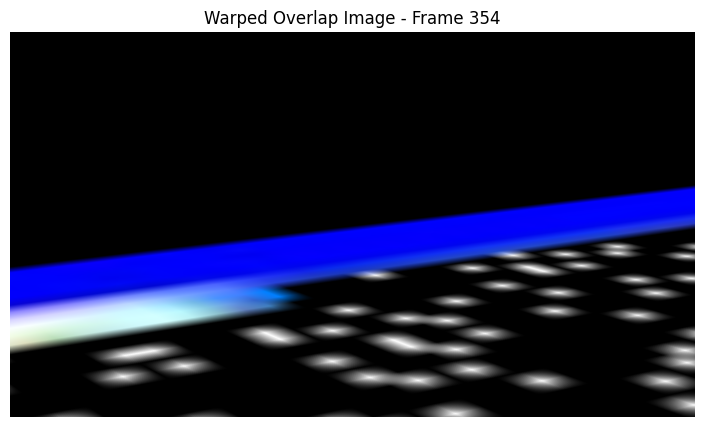

Iteration:  70%|██████▉   | 313/450 [00:56<00:24,  5.56it/s]

Normalized Homography matrix for frame 285:
[[ 3.4935500e-02  4.1669211e-03  9.9464333e+01]
 [ 2.5985558e-02  2.0041952e-01 -1.3795753e+02]
 [-3.7341091e-05  3.6952081e-03  1.0000000e+00]]


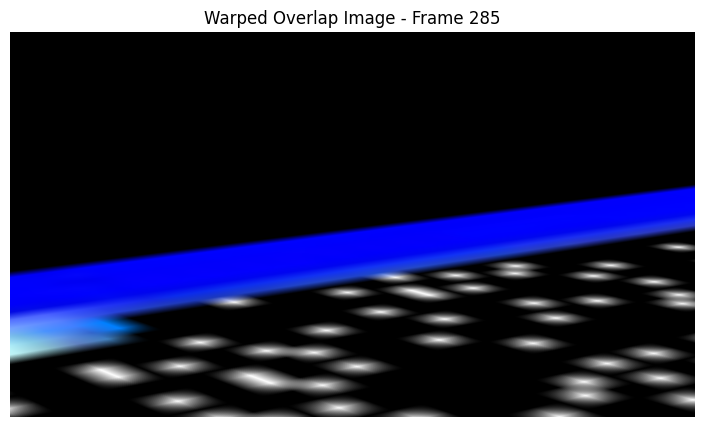

Iteration:  70%|██████▉   | 314/450 [00:56<00:24,  5.56it/s]

Normalized Homography matrix for frame 253:
[[ 5.4004841e-02  7.0067705e-03  1.3280815e+02]
 [ 3.8098648e-02  3.0036134e-01 -2.2810254e+02]
 [-5.1758885e-05  5.5245450e-03  1.0000000e+00]]


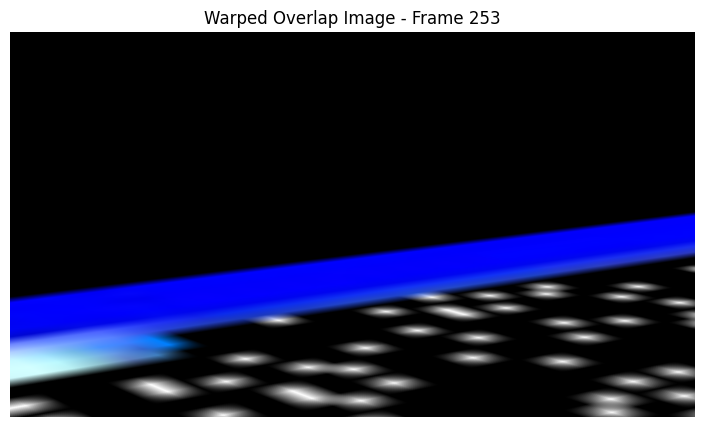

Iteration:  70%|███████   | 315/450 [00:57<00:24,  5.56it/s]

Normalized Homography matrix for frame 75:
[[ 8.5522465e-02  2.2470487e-02 -1.4064358e+01]
 [ 2.0758722e-02  3.5486716e-01 -2.9656677e+02]
 [ 8.4609033e-05  6.2821475e-03  1.0000000e+00]]


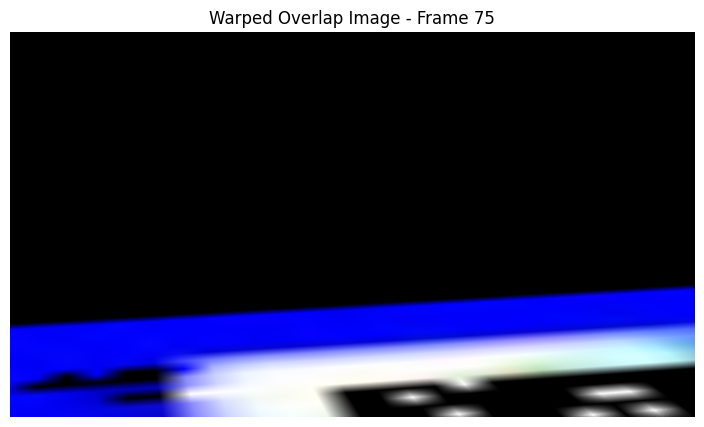

Iteration:  70%|███████   | 316/450 [00:57<00:23,  5.59it/s]

Normalized Homography matrix for frame 323:
[[ 5.0240226e-02  4.9802130e-03  8.7224571e+01]
 [ 3.0609455e-02  2.7114224e-01 -1.8242319e+02]
 [-4.7521295e-05  5.0160754e-03  1.0000000e+00]]


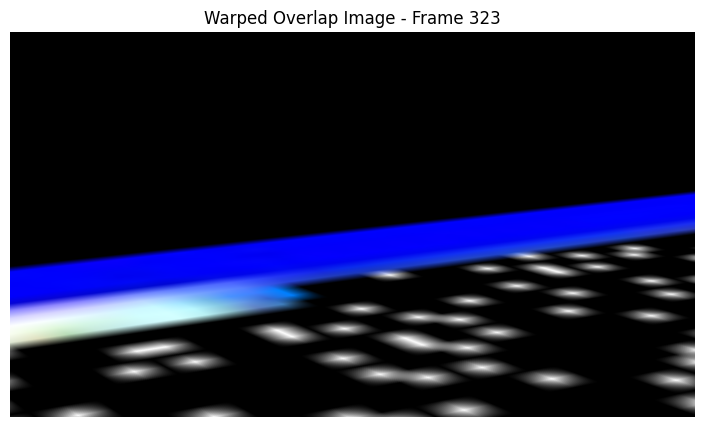

Iteration:  70%|███████   | 317/450 [00:57<00:23,  5.56it/s]

Normalized Homography matrix for frame 21:
[[ 3.0650187e-01 -1.7936278e-02 -1.6056645e+02]
 [ 4.1333254e-02  1.3823620e+00 -1.0056192e+03]
 [ 1.8491308e-05  2.6257735e-02  1.0000000e+00]]


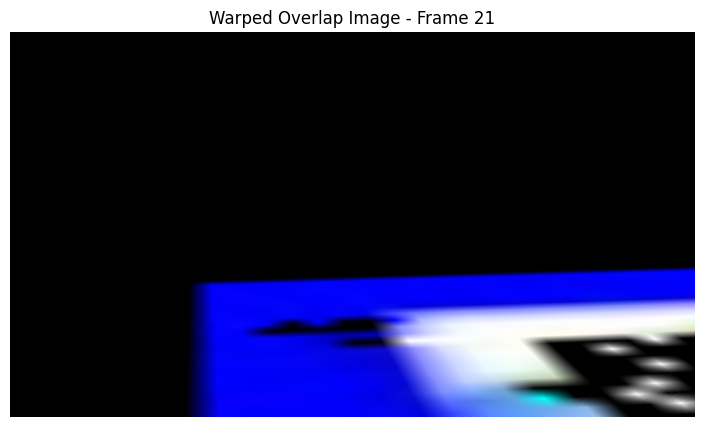

Iteration:  71%|███████   | 318/450 [00:57<00:23,  5.57it/s]

Normalized Homography matrix for frame 41:
[[ 1.2185737e-01  7.0881163e-04 -4.6945343e+01]
 [ 2.0481963e-02  5.2767640e-01 -3.9487848e+02]
 [ 1.2039054e-05  9.9034030e-03  1.0000000e+00]]


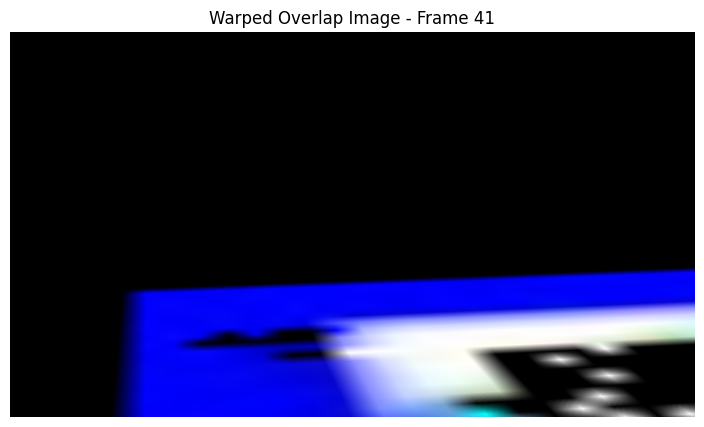

Iteration:  71%|███████   | 319/450 [00:57<00:23,  5.59it/s]

Normalized Homography matrix for frame 352:
[[ 4.6571594e-02  3.5000111e-03  8.5923683e+01]
 [ 2.9494084e-02  2.5119266e-01 -1.6805513e+02]
 [-4.0655334e-05  4.6471609e-03  1.0000000e+00]]


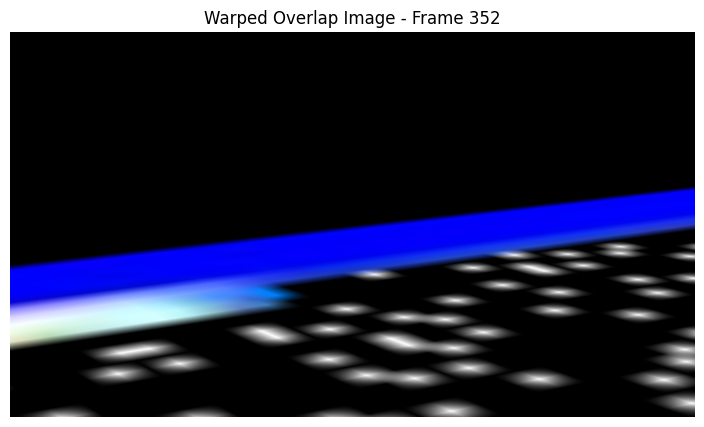

Iteration:  71%|███████   | 320/450 [00:57<00:23,  5.55it/s]

Normalized Homography matrix for frame 186:
[[ 6.8953536e-02 -4.9950631e-04  9.9911041e+01]
 [ 3.4288317e-02  3.4580162e-01 -3.0528149e+02]
 [-1.3829614e-05  6.2294481e-03  1.0000000e+00]]


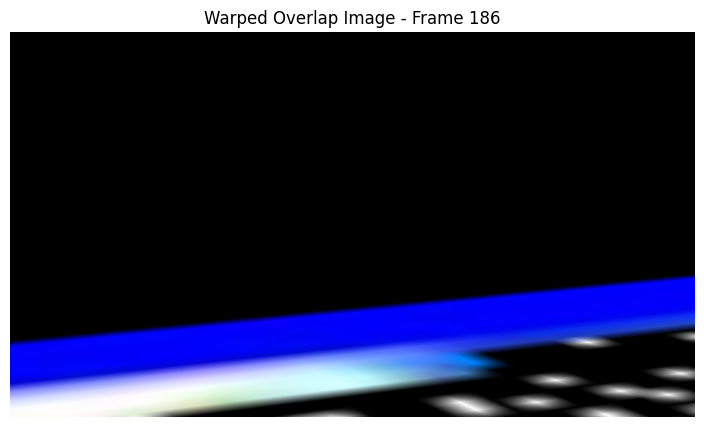

Iteration:  71%|███████▏  | 321/450 [00:58<00:23,  5.60it/s]

Normalized Homography matrix for frame 355:
[[ 4.6841726e-02  2.1425111e-03  8.7223061e+01]
 [ 3.0382944e-02  2.5215480e-01 -1.6942160e+02]
 [-3.1368138e-05  4.6453928e-03  1.0000000e+00]]


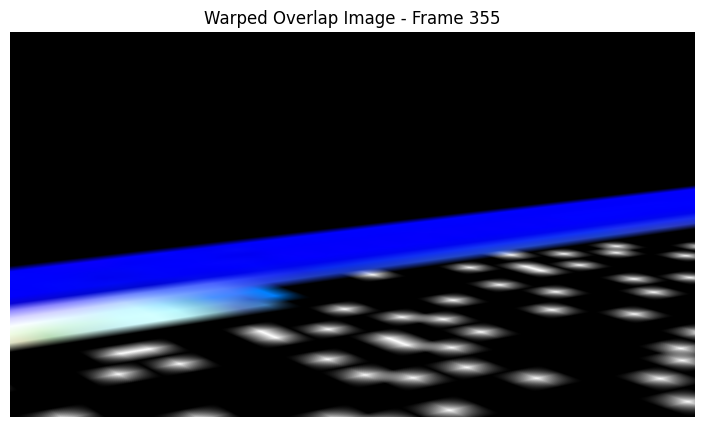

Iteration:  72%|███████▏  | 322/450 [00:58<00:23,  5.56it/s]

Normalized Homography matrix for frame 4:
[[ 7.0879304e-01 -6.6605243e-03 -5.5786322e+02]
 [ 4.2415529e-02  3.1526303e+00 -2.2273816e+03]
 [ 6.9693080e-05  5.7305839e-02  1.0000000e+00]]


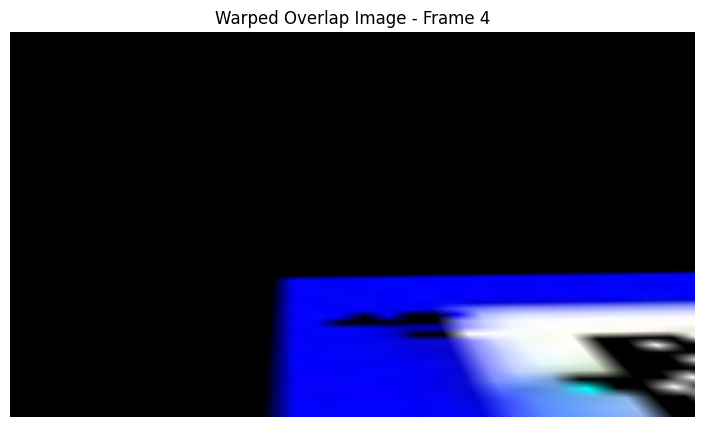

Iteration:  72%|███████▏  | 323/450 [00:58<00:22,  5.60it/s]

Normalized Homography matrix for frame 194:
[[ 8.8475741e-02  1.3582094e-02  1.2813976e+02]
 [ 4.7260676e-02  4.4022977e-01 -3.7875555e+02]
 [-2.6997994e-05  8.3180340e-03  1.0000000e+00]]


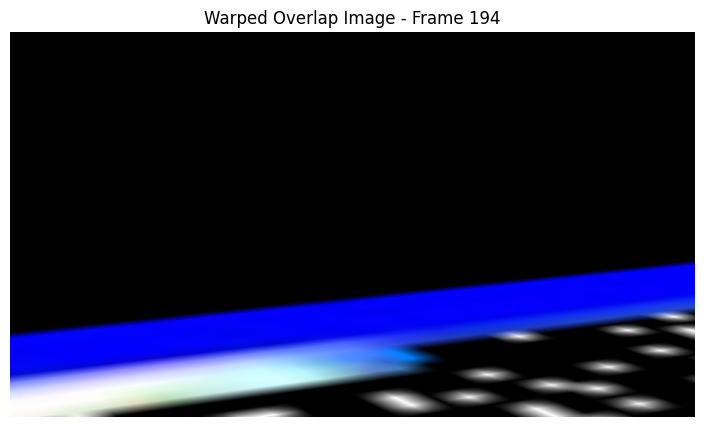

Iteration:  72%|███████▏  | 324/450 [00:58<00:22,  5.63it/s]

Normalized Homography matrix for frame 450:
[[ 4.2131219e-02  3.4366576e-03  8.0640083e+01]
 [ 2.7288750e-02  2.2709584e-01 -1.4889584e+02]
 [-2.9292703e-05  4.1426155e-03  1.0000000e+00]]


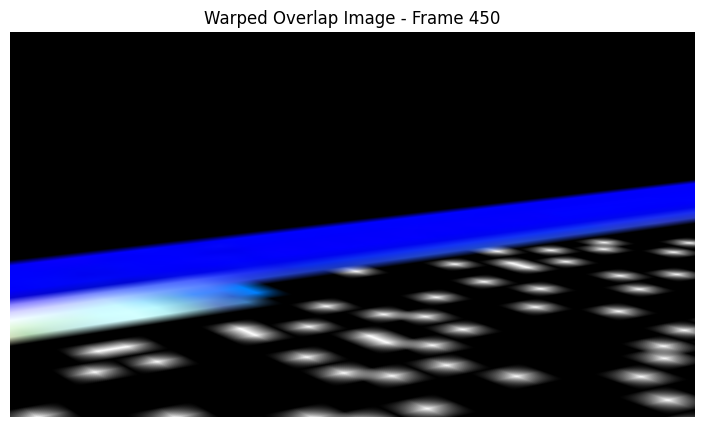

Iteration:  72%|███████▏  | 325/450 [00:58<00:22,  5.58it/s]

Normalized Homography matrix for frame 276:
[[ 3.8028494e-02  2.2617863e-03  1.1179139e+02]
 [ 2.9350234e-02  2.1871786e-01 -1.5642975e+02]
 [-3.5983801e-05  4.0629203e-03  1.0000000e+00]]


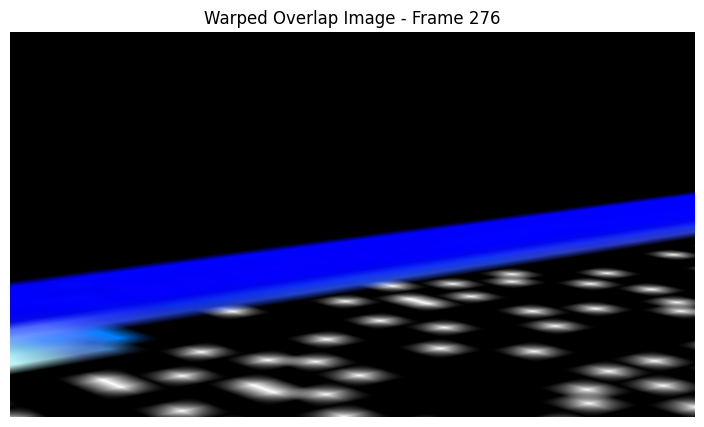

Iteration:  72%|███████▏  | 326/450 [00:59<00:22,  5.54it/s]

Normalized Homography matrix for frame 27:
[[ 3.2440001e-01 -3.3542132e-03 -1.6784206e+02]
 [ 4.0148627e-02  1.4225193e+00 -1.0398752e+03]
 [-9.0699359e-05  2.8345959e-02  1.0000000e+00]]


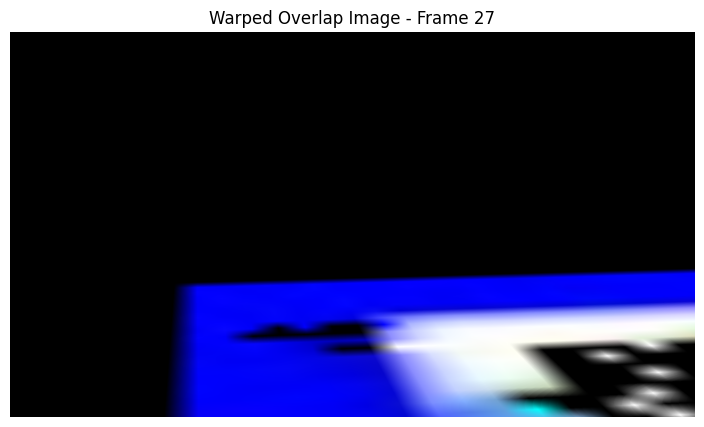

Iteration:  73%|███████▎  | 327/450 [00:59<00:22,  5.57it/s]

Normalized Homography matrix for frame 313:
[[ 4.6899080e-02  4.9700320e-04  8.8200127e+01]
 [ 3.0045209e-02  2.5171381e-01 -1.7190300e+02]
 [-3.4401728e-05  4.5893244e-03  1.0000000e+00]]


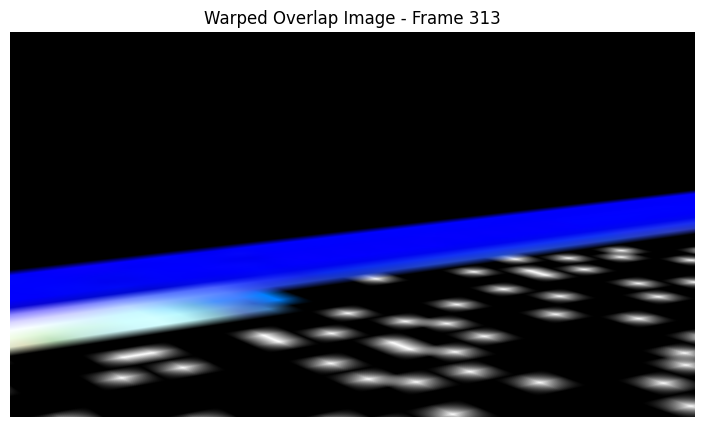

Iteration:  73%|███████▎  | 328/450 [00:59<00:21,  5.58it/s]

Normalized Homography matrix for frame 63:
[[ 1.3742429e-01 -4.7875643e-03 -2.2347603e+00]
 [ 3.1314362e-02  5.9542394e-01 -4.6691370e+02]
 [-1.3006070e-04  1.2382077e-02  1.0000000e+00]]


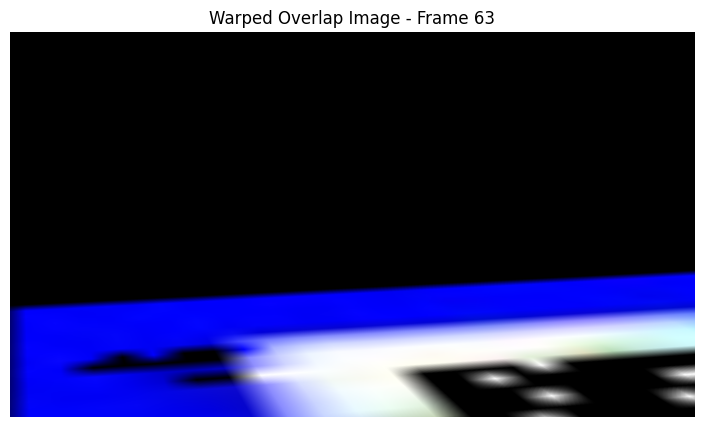

Iteration:  73%|███████▎  | 329/450 [00:59<00:21,  5.60it/s]

Normalized Homography matrix for frame 268:
[[ 4.5212787e-02  9.7623859e-03  1.2403716e+02]
 [ 3.3471536e-02  2.6317671e-01 -1.9086435e+02]
 [-4.2443484e-05  4.8947767e-03  1.0000000e+00]]


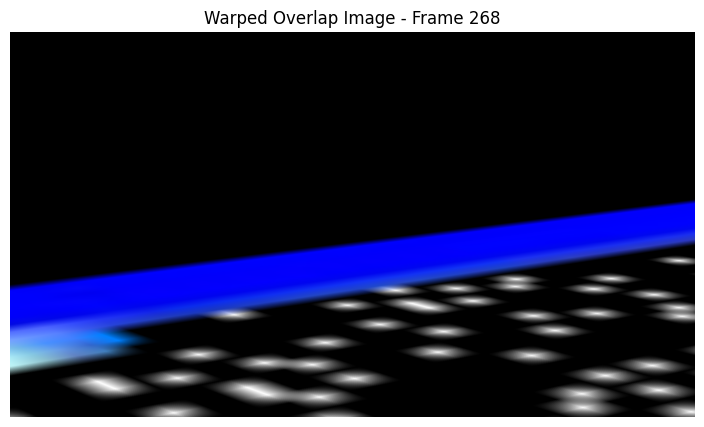

Iteration:  73%|███████▎  | 330/450 [00:59<00:21,  5.58it/s]

Normalized Homography matrix for frame 149:
[[ 6.3515373e-02 -1.3720073e-02  1.8249405e+01]
 [ 1.8660022e-02  2.3009415e-01 -2.1036742e+02]
 [-3.2258526e-05  3.5603705e-03  1.0000000e+00]]


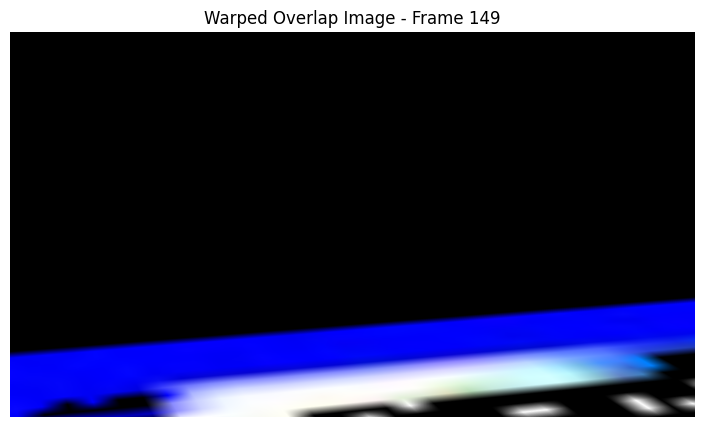

Iteration:  74%|███████▎  | 331/450 [00:59<00:21,  5.61it/s]

Normalized Homography matrix for frame 242:
[[ 6.4816333e-02  8.2354434e-03  1.4753458e+02]
 [ 4.4324737e-02  3.5827464e-01 -2.7679916e+02]
 [-6.1334635e-05  6.6405283e-03  1.0000000e+00]]


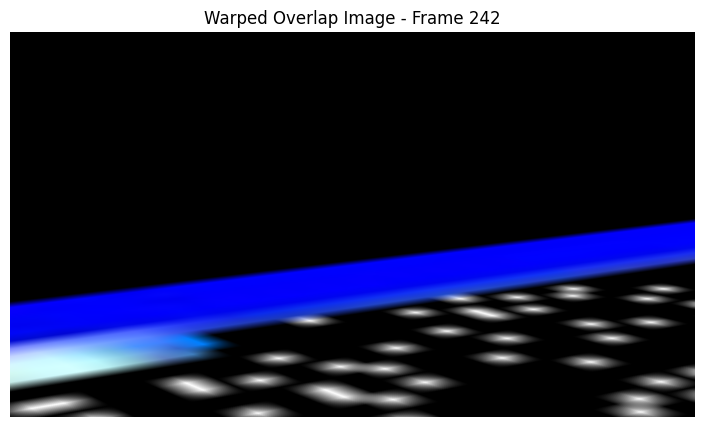

Iteration:  74%|███████▍  | 332/450 [01:00<00:21,  5.59it/s]

Normalized Homography matrix for frame 349:
[[ 4.8208669e-02  2.6641225e-03  8.7777031e+01]
 [ 3.0966736e-02  2.5878024e-01 -1.7457678e+02]
 [-3.2434167e-05  4.7799875e-03  1.0000000e+00]]


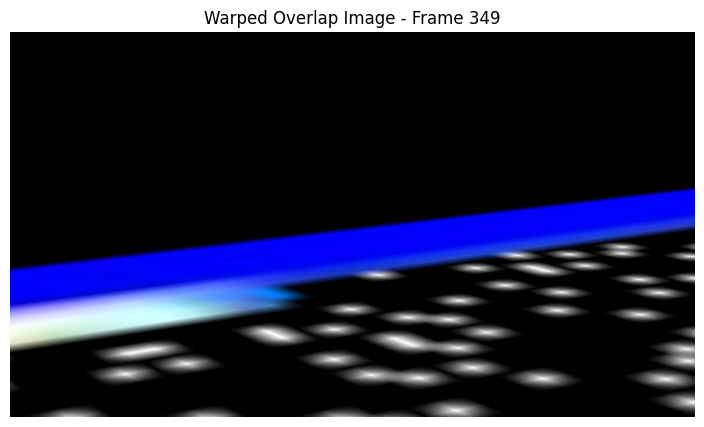

Iteration:  74%|███████▍  | 333/450 [01:00<00:23,  4.98it/s]

Normalized Homography matrix for frame 300:
[[ 3.9909024e-02  2.0058646e-03  9.1720207e+01]
 [ 2.7404239e-02  2.1556784e-01 -1.4999576e+02]
 [-4.0474963e-05  3.9988603e-03  1.0000000e+00]]


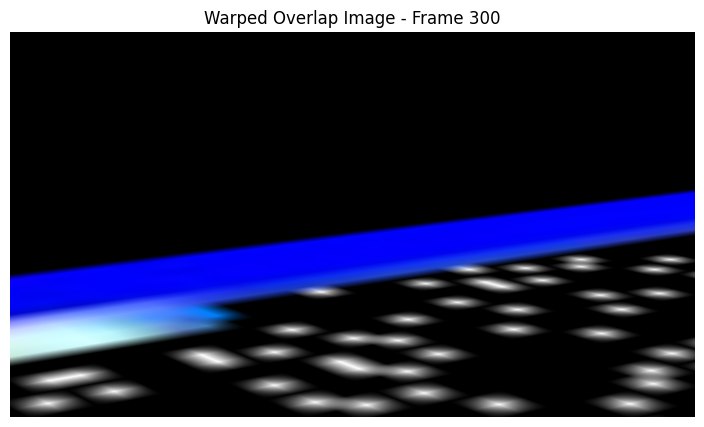

Iteration:  74%|███████▍  | 334/450 [01:00<00:22,  5.15it/s]

Normalized Homography matrix for frame 289:
[[ 3.4454305e-02  6.6957176e-03  9.3373032e+01]
 [ 2.5081426e-02  1.9313307e-01 -1.3252171e+02]
 [-3.3927416e-05  3.5923419e-03  1.0000000e+00]]


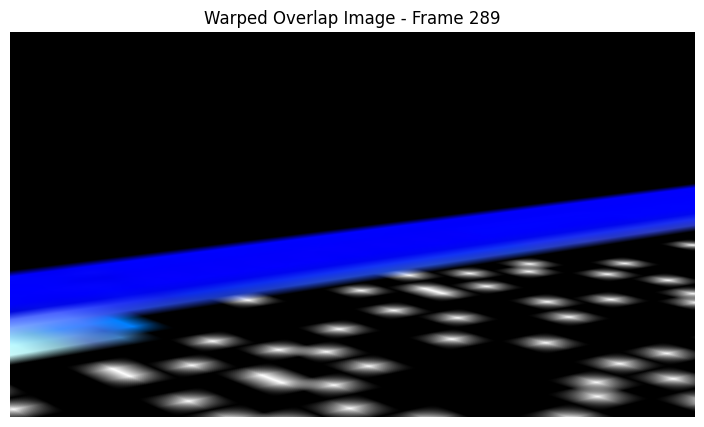

Iteration:  74%|███████▍  | 335/450 [01:00<00:21,  5.26it/s]

Normalized Homography matrix for frame 204:
[[ 8.6836569e-02  8.5002724e-03  1.4644479e+02]
 [ 4.9925752e-02  4.5421714e-01 -3.7731702e+02]
 [-4.0516639e-05  8.3119730e-03  1.0000000e+00]]


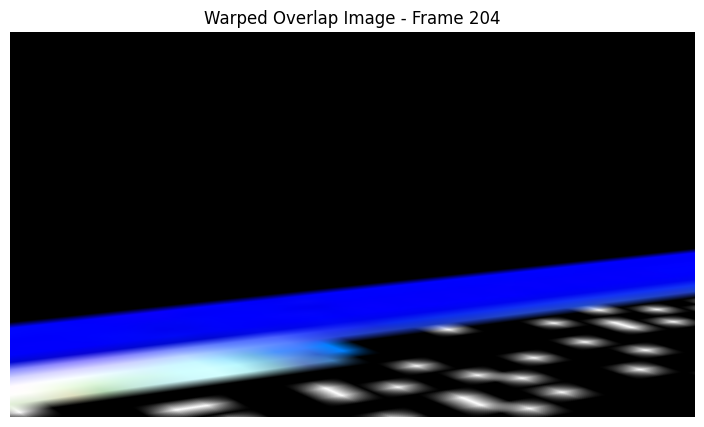

Iteration:  75%|███████▍  | 336/450 [01:00<00:21,  5.41it/s]

Normalized Homography matrix for frame 37:
[[ 1.4986266e-01  1.0971364e-03 -6.5529495e+01]
 [ 2.3520242e-02  6.5044773e-01 -4.8287015e+02]
 [ 1.3371639e-05  1.2463796e-02  1.0000000e+00]]


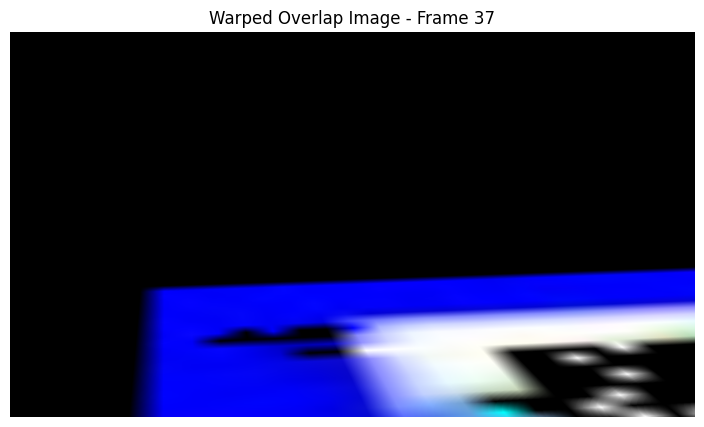

Iteration:  75%|███████▍  | 337/450 [01:01<00:20,  5.47it/s]

Normalized Homography matrix for frame 29:
[[ 2.65900135e-01 -9.59174428e-03 -1.25950066e+02]
 [ 3.65295485e-02  1.14870572e+00 -8.40216614e+02]
 [-8.04379670e-05  2.24893056e-02  1.00000000e+00]]


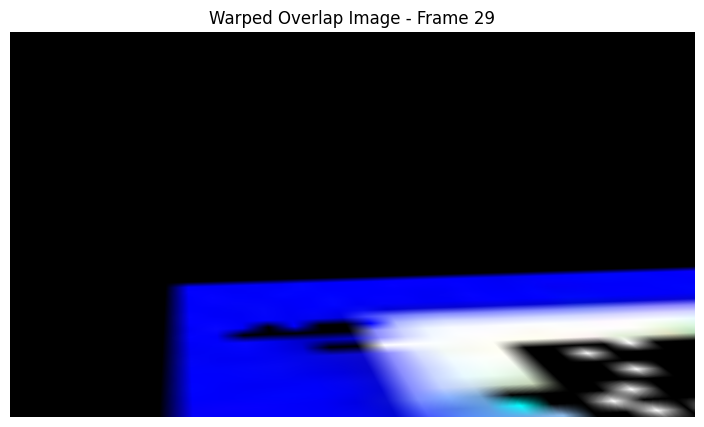

Iteration:  75%|███████▌  | 338/450 [01:01<00:20,  5.51it/s]

Normalized Homography matrix for frame 298:
[[ 3.7945524e-02  1.6648626e-03  9.1740509e+01]
 [ 2.6511434e-02  2.0771837e-01 -1.4424353e+02]
 [-3.5675184e-05  3.8365091e-03  1.0000000e+00]]


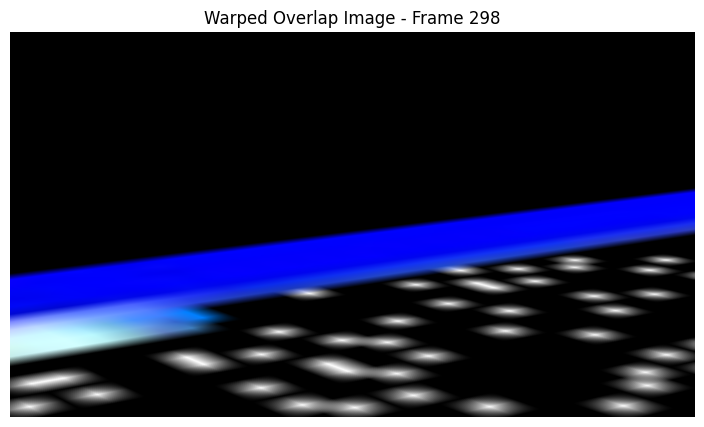

Iteration:  75%|███████▌  | 339/450 [01:01<00:19,  5.56it/s]

Normalized Homography matrix for frame 345:
[[ 4.8597716e-02  3.2496157e-03  8.6596855e+01]
 [ 3.0578328e-02  2.5985047e-01 -1.7511269e+02]
 [-3.9011080e-05  4.8002219e-03  1.0000000e+00]]


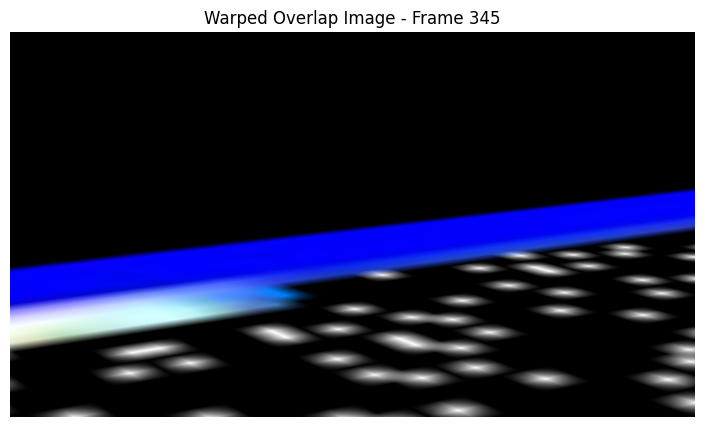

Iteration:  76%|███████▌  | 340/450 [01:01<00:20,  5.50it/s]

Normalized Homography matrix for frame 437:
[[ 4.4713095e-02  7.1853139e-03  8.3017838e+01]
 [ 2.8931117e-02  2.4101269e-01 -1.5851222e+02]
 [-2.8481179e-05  4.4694194e-03  1.0000000e+00]]


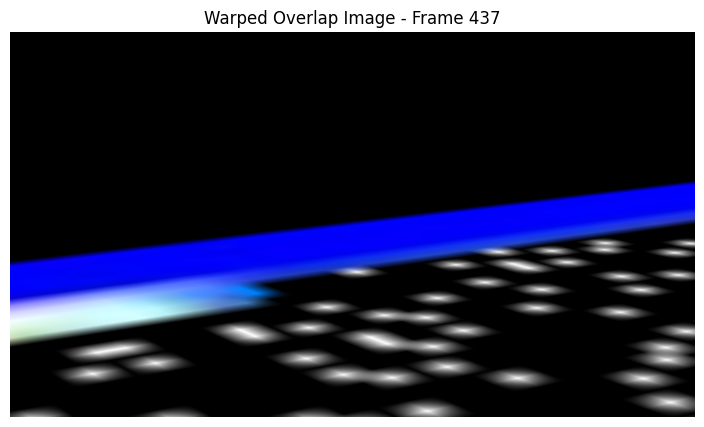

Iteration:  76%|███████▌  | 341/450 [01:01<00:19,  5.46it/s]

Normalized Homography matrix for frame 8:
[[ 3.5655417e+00  5.0934117e-02 -2.7007744e+03]
 [ 2.8575870e-01  1.5570278e+01 -1.1061260e+04]
 [ 9.8063052e-04  2.9626656e-01  1.0000000e+00]]


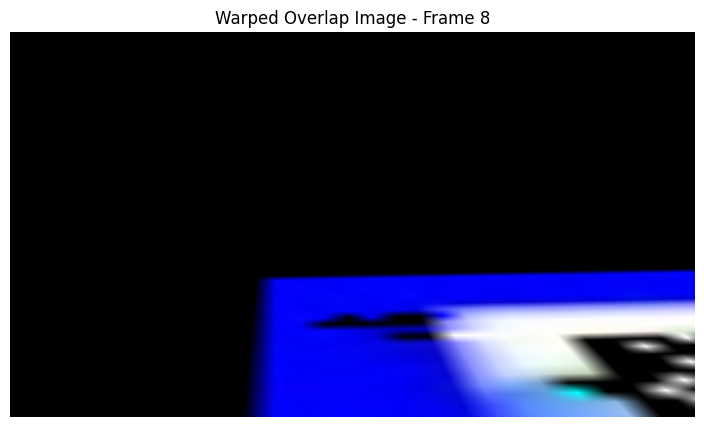

Iteration:  76%|███████▌  | 342/450 [01:01<00:19,  5.53it/s]

Normalized Homography matrix for frame 449:
[[ 4.1920312e-02  2.3136307e-03  8.2200676e+01]
 [ 2.7128763e-02  2.2802404e-01 -1.4913588e+02]
 [-3.9522914e-05  4.2005554e-03  1.0000000e+00]]


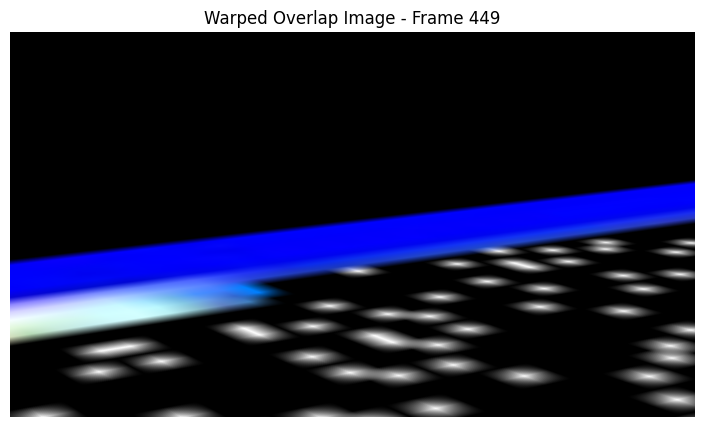

Iteration:  76%|███████▌  | 343/450 [01:02<00:19,  5.51it/s]

Normalized Homography matrix for frame 372:
[[ 4.5552976e-02  4.4470490e-03  8.6276451e+01]
 [ 3.0030655e-02  2.4417584e-01 -1.6333723e+02]
 [-3.0306077e-05  4.5715543e-03  1.0000000e+00]]


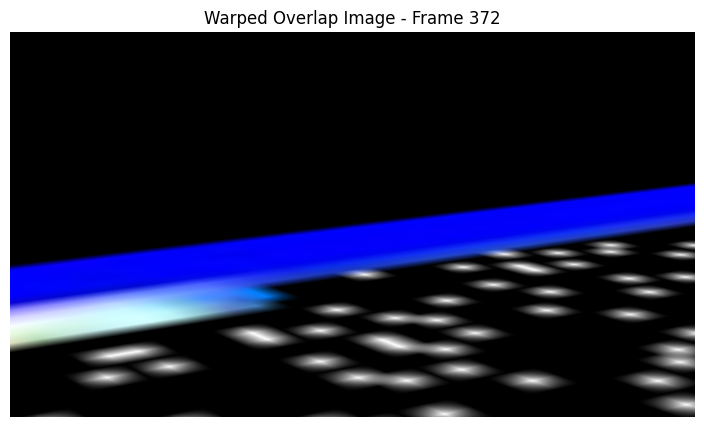

Iteration:  76%|███████▋  | 344/450 [01:02<00:19,  5.48it/s]

Normalized Homography matrix for frame 13:
[[ 3.26068550e-01 -1.39196133e-02 -2.09354706e+02]
 [ 2.71513686e-02  1.42522979e+00 -1.01906940e+03]
 [-1.05336105e-04  2.64122561e-02  1.00000000e+00]]


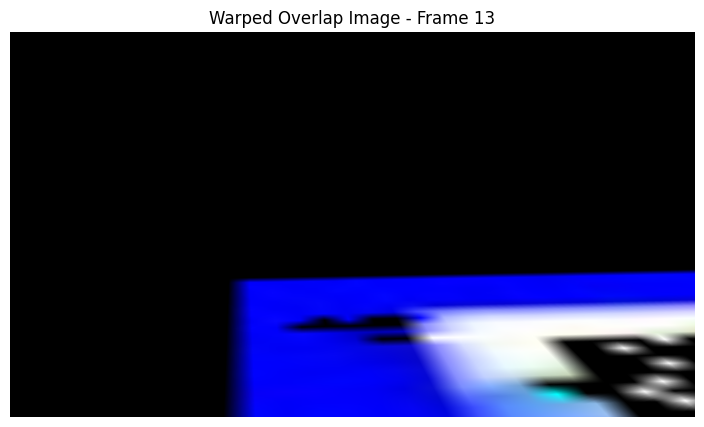

Iteration:  77%|███████▋  | 345/450 [01:02<00:18,  5.55it/s]

Normalized Homography matrix for frame 429:
[[ 4.3484669e-02  4.4489158e-03  8.3209297e+01]
 [ 2.8680487e-02  2.3323916e-01 -1.5438470e+02]
 [-2.8666776e-05  4.3515051e-03  1.0000000e+00]]


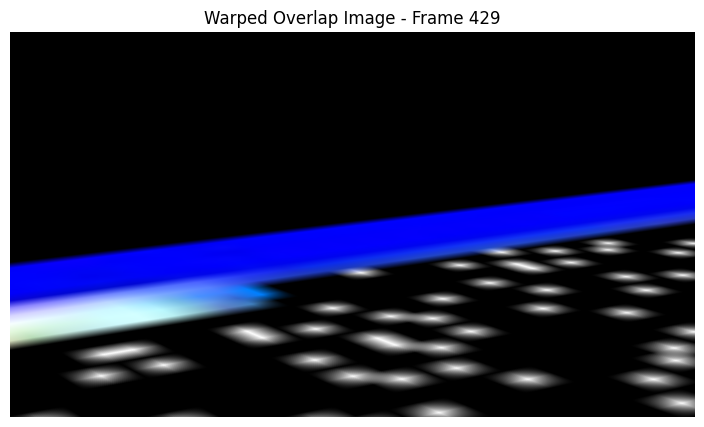

Iteration:  77%|███████▋  | 346/450 [01:02<00:18,  5.52it/s]

Normalized Homography matrix for frame 179:
[[ 8.2636781e-02  1.8700929e-02  9.6553444e+01]
 [ 3.8516592e-02  3.9636576e-01 -3.5748489e+02]
 [-3.7597755e-07  7.6990365e-03  1.0000000e+00]]


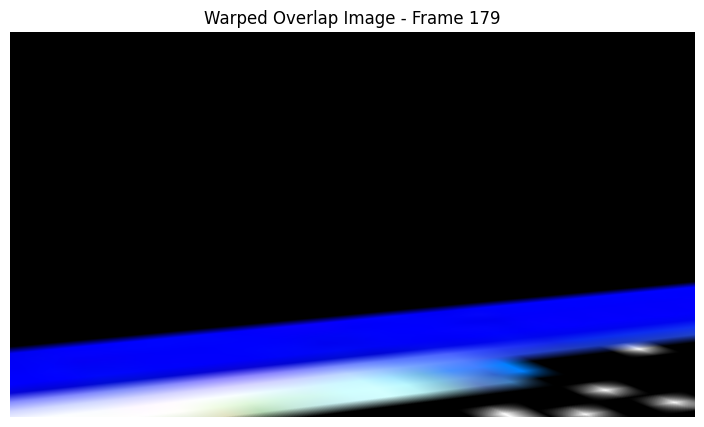

Iteration:  77%|███████▋  | 347/450 [01:02<00:18,  5.58it/s]

Normalized Homography matrix for frame 213:
[[ 8.6471394e-02  3.9541838e-03  1.5931554e+02]
 [ 5.4650001e-02  4.5175511e-01 -3.7101465e+02]
 [-3.4385408e-05  8.3734542e-03  1.0000000e+00]]


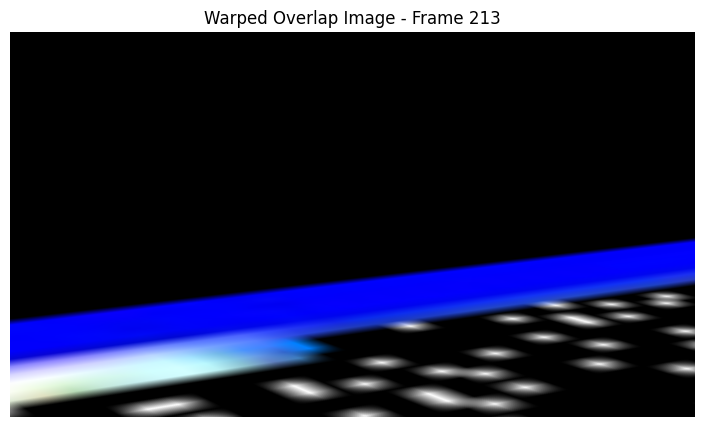

Iteration:  77%|███████▋  | 348/450 [01:03<00:18,  5.57it/s]

Normalized Homography matrix for frame 56:
[[ 1.3595659e-01 -8.8323643e-03 -1.4080267e+01]
 [ 3.1651385e-02  6.1252207e-01 -4.7150571e+02]
 [-1.7786093e-05  1.2318791e-02  1.0000000e+00]]


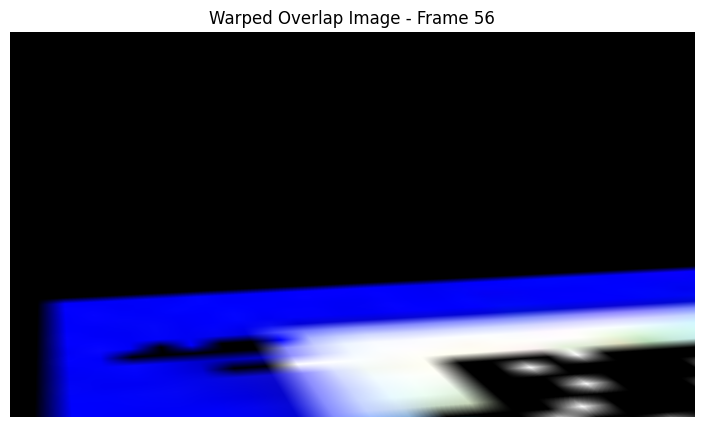

Iteration:  78%|███████▊  | 349/450 [01:03<00:18,  5.57it/s]

Normalized Homography matrix for frame 308:
[[ 4.5586020e-02  2.4000276e-03  9.0635490e+01]
 [ 2.9633921e-02  2.4609794e-01 -1.6880190e+02]
 [-4.1106807e-05  4.5475429e-03  1.0000000e+00]]


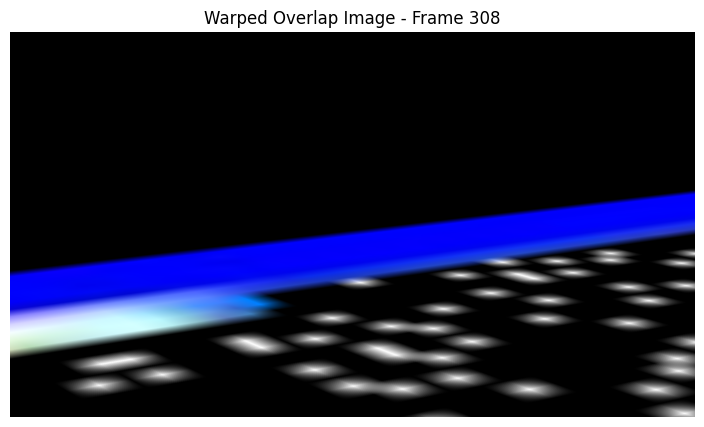

Iteration:  78%|███████▊  | 350/450 [01:03<00:18,  5.54it/s]

Normalized Homography matrix for frame 235:
[[ 7.2922580e-02  4.6964260e-03  1.5836270e+02]
 [ 4.9163017e-02  3.9503297e-01 -3.1025482e+02]
 [-8.0702193e-05  7.4336641e-03  1.0000000e+00]]


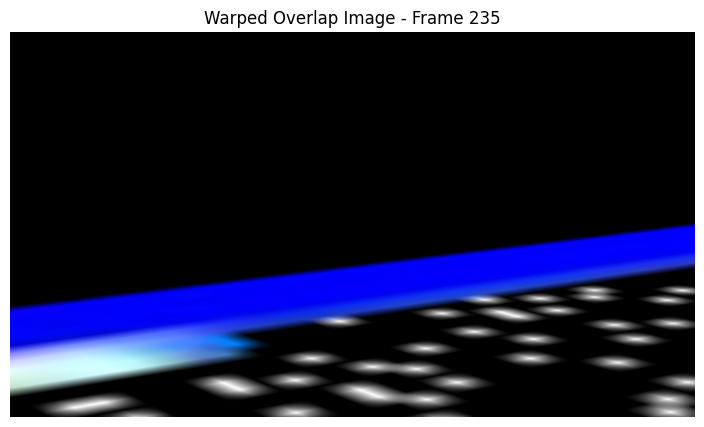

Iteration:  78%|███████▊  | 351/450 [01:03<00:17,  5.54it/s]

Normalized Homography matrix for frame 389:
[[ 4.4523750e-02  2.3129680e-03  8.5838753e+01]
 [ 2.9298490e-02  2.3924504e-01 -1.5990114e+02]
 [-3.3723230e-05  4.4419840e-03  1.0000000e+00]]


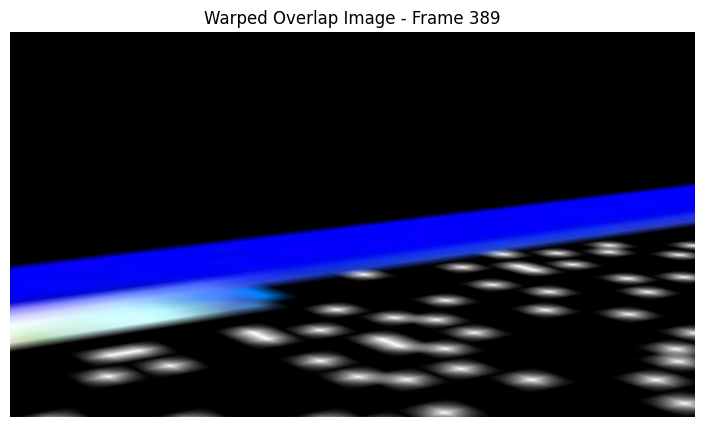

Iteration:  78%|███████▊  | 352/450 [01:03<00:18,  5.41it/s]

Normalized Homography matrix for frame 361:
[[ 4.7348265e-02  7.5393524e-03  8.6705803e+01]
 [ 3.0035427e-02  2.5559947e-01 -1.6978075e+02]
 [-4.3944492e-05  4.7928528e-03  1.0000000e+00]]


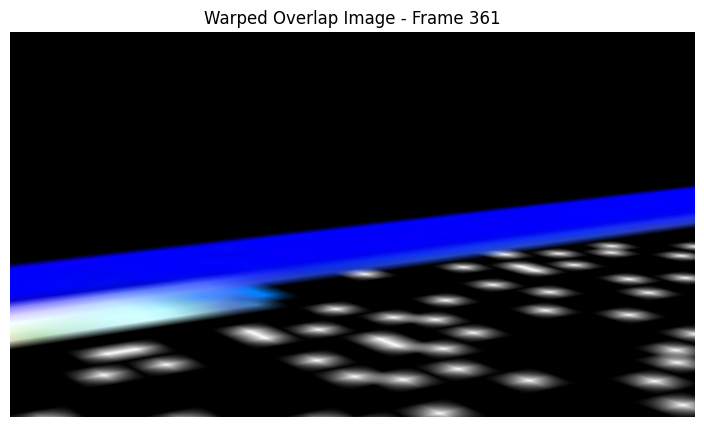

Iteration:  78%|███████▊  | 353/450 [01:03<00:17,  5.42it/s]

Normalized Homography matrix for frame 228:
[[ 8.8764690e-02  2.1737466e-02  1.6999721e+02]
 [ 5.7086807e-02  4.7839597e-01 -3.7845377e+02]
 [-6.0649458e-05  8.9993626e-03  1.0000000e+00]]


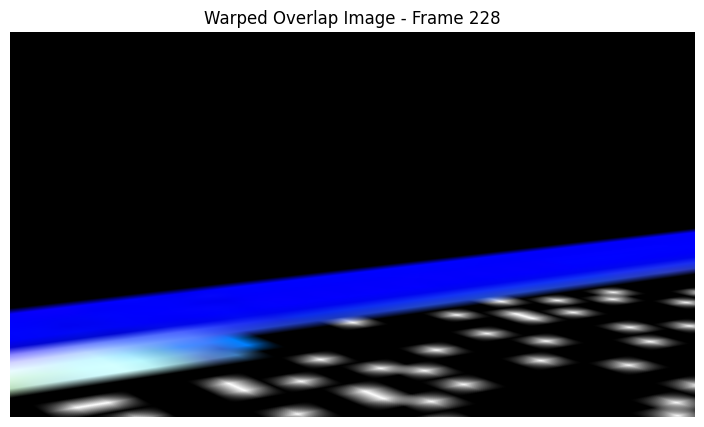

Iteration:  79%|███████▊  | 354/450 [01:04<00:17,  5.49it/s]

Normalized Homography matrix for frame 310:
[[ 4.6683419e-02 -2.1410013e-04  9.1926620e+01]
 [ 3.1114744e-02  2.4928182e-01 -1.7244827e+02]
 [-3.3855871e-05  4.6494366e-03  1.0000000e+00]]


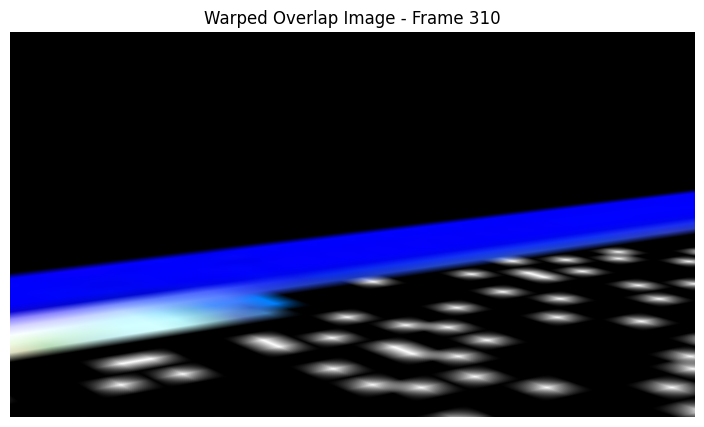

Iteration:  79%|███████▉  | 355/450 [01:04<00:17,  5.54it/s]

Normalized Homography matrix for frame 244:
[[ 6.2385358e-02  5.7584196e-03  1.4624033e+02]
 [ 4.2977840e-02  3.4625262e-01 -2.6649359e+02]
 [-6.8570924e-05  6.4207893e-03  1.0000000e+00]]


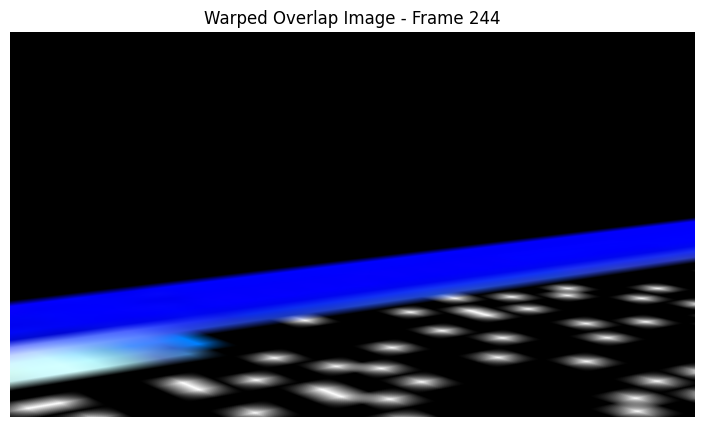

Iteration:  79%|███████▉  | 356/450 [01:04<00:16,  5.55it/s]

Normalized Homography matrix for frame 279:
[[ 3.62333283e-02  3.66623513e-03  1.03598656e+02]
 [ 2.73120161e-02  2.06185699e-01 -1.45386383e+02]
 [-3.09677962e-05  3.76503752e-03  1.00000000e+00]]


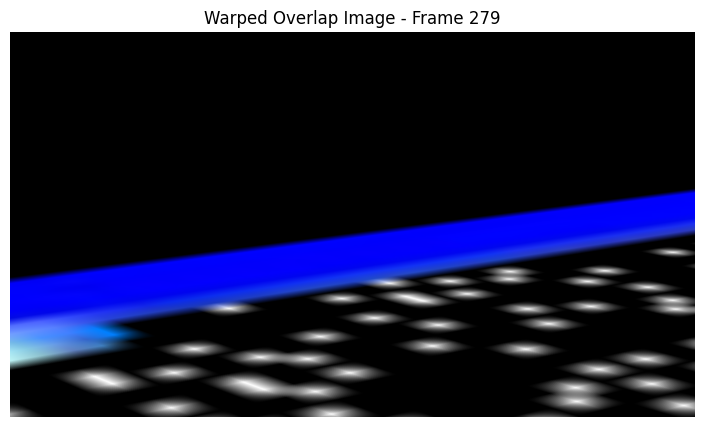

Iteration:  79%|███████▉  | 357/450 [01:04<00:16,  5.52it/s]

Normalized Homography matrix for frame 229:
[[ 8.1469104e-02  9.0363380e-03  1.6743272e+02]
 [ 5.3631738e-02  4.4064093e-01 -3.4878171e+02]
 [-7.8120793e-05  8.3049387e-03  1.0000000e+00]]


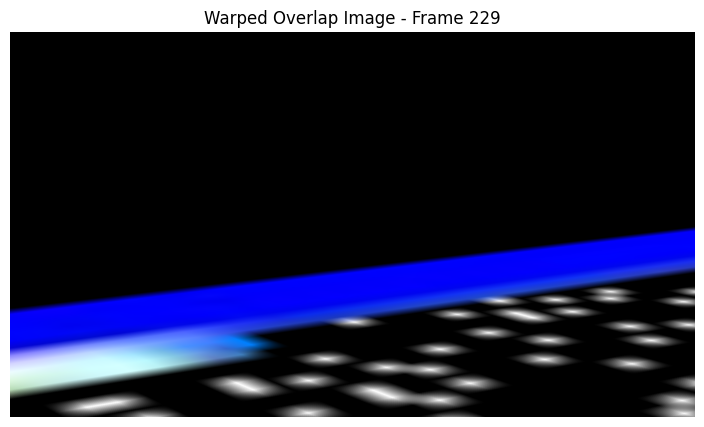

Iteration:  80%|███████▉  | 358/450 [01:04<00:16,  5.52it/s]

Normalized Homography matrix for frame 120:
[[ 1.2184814e-01  3.0454228e-02  5.3123932e+01]
 [ 3.9524078e-02  5.3823793e-01 -5.0298300e+02]
 [-5.7944735e-06  1.1234503e-02  1.0000000e+00]]


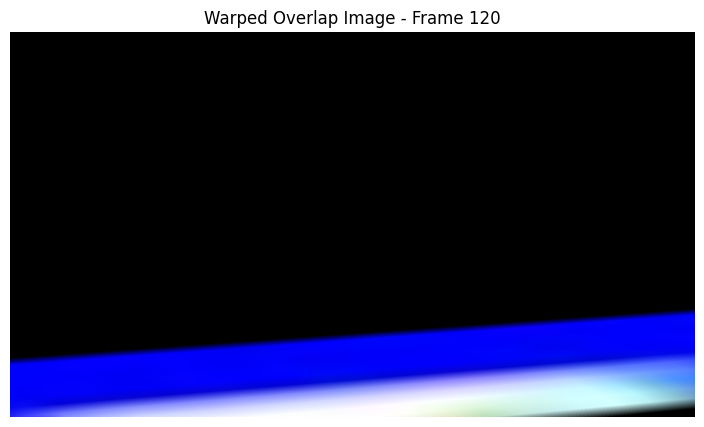

Iteration:  80%|███████▉  | 359/450 [01:05<00:16,  5.54it/s]

Normalized Homography matrix for frame 391:
[[ 4.3340214e-02  2.3552170e-04  8.5142708e+01]
 [ 2.8708275e-02  2.3309621e-01 -1.5595227e+02]
 [-3.1583444e-05  4.2949086e-03  1.0000000e+00]]


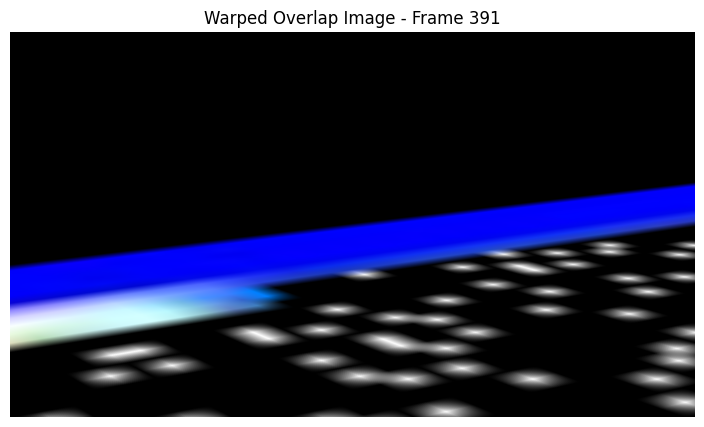

Iteration:  80%|████████  | 360/450 [01:05<00:16,  5.50it/s]

Normalized Homography matrix for frame 397:
[[ 4.3341208e-02  1.8347963e-03  8.5099495e+01]
 [ 2.8061287e-02  2.3572738e-01 -1.5641199e+02]
 [-4.0639410e-05  4.3460461e-03  1.0000000e+00]]


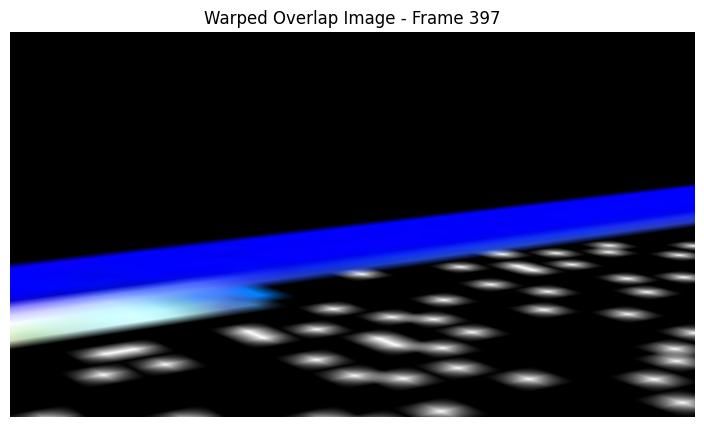

Iteration:  80%|████████  | 361/450 [01:05<00:16,  5.51it/s]

Normalized Homography matrix for frame 137:
[[ 2.5199109e-01  1.3549025e-01  6.5035751e+01]
 [ 8.0360599e-02  1.0411732e+00 -9.8031757e+02]
 [ 2.4252392e-06  2.4303814e-02  1.0000000e+00]]


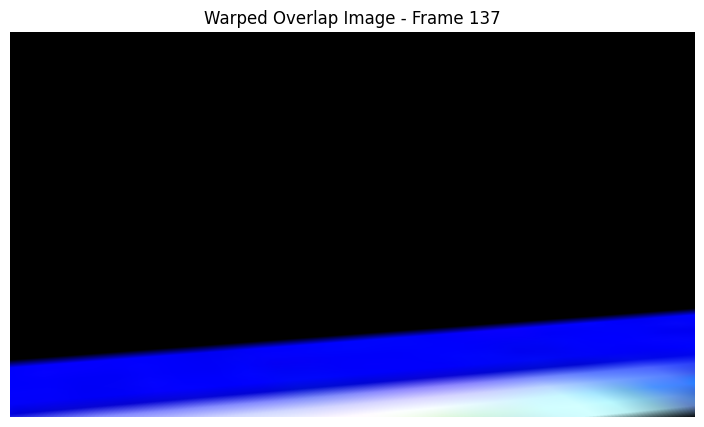

Iteration:  80%|████████  | 362/450 [01:05<00:15,  5.55it/s]

Normalized Homography matrix for frame 9:
[[ 2.7751544e+00  3.3959665e-03 -2.0148828e+03]
 [ 2.1107550e-01  1.2406867e+01 -8.7838613e+03]
 [ 4.8397291e-05  2.3545936e-01  1.0000000e+00]]


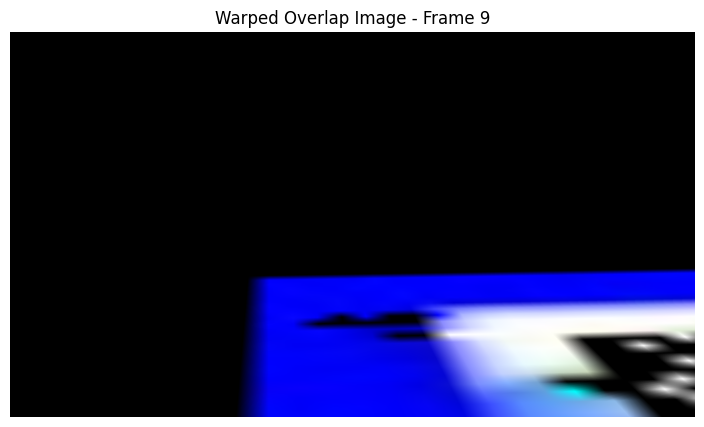

Iteration:  81%|████████  | 363/450 [01:05<00:15,  5.61it/s]

Normalized Homography matrix for frame 94:
[[ 7.6297514e-02  3.0873854e-02 -6.3335896e+00]
 [ 1.9669825e-02  2.9797766e-01 -2.6321158e+02]
 [ 8.6398119e-05  5.2565578e-03  1.0000000e+00]]


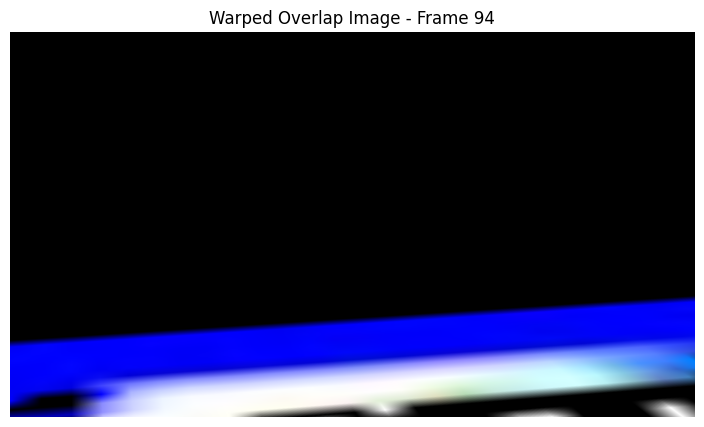

Iteration:  81%|████████  | 364/450 [01:05<00:15,  5.66it/s]

Normalized Homography matrix for frame 46:
[[ 1.6068685e-01 -1.9682371e-03 -4.8092262e+01]
 [ 3.0720709e-02  7.0612764e-01 -5.2842853e+02]
 [-8.5657421e-06  1.4077088e-02  1.0000000e+00]]


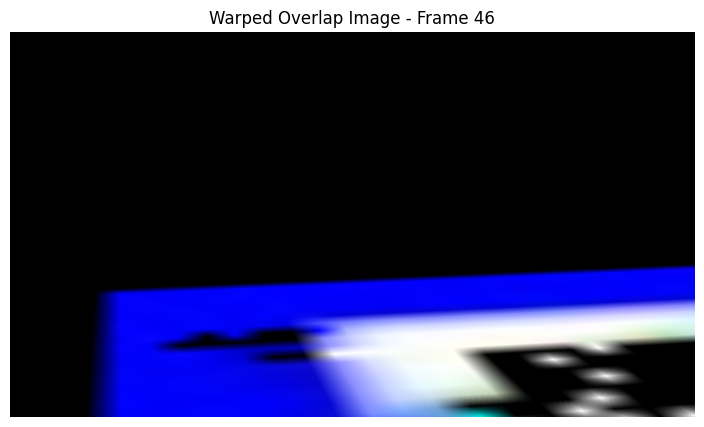

Iteration:  81%|████████  | 365/450 [01:06<00:15,  5.64it/s]

Normalized Homography matrix for frame 246:
[[ 6.2793985e-02  1.0123517e-02  1.4525458e+02]
 [ 4.3168262e-02  3.4759527e-01 -2.6708774e+02]
 [-6.4059597e-05  6.4527495e-03  1.0000000e+00]]


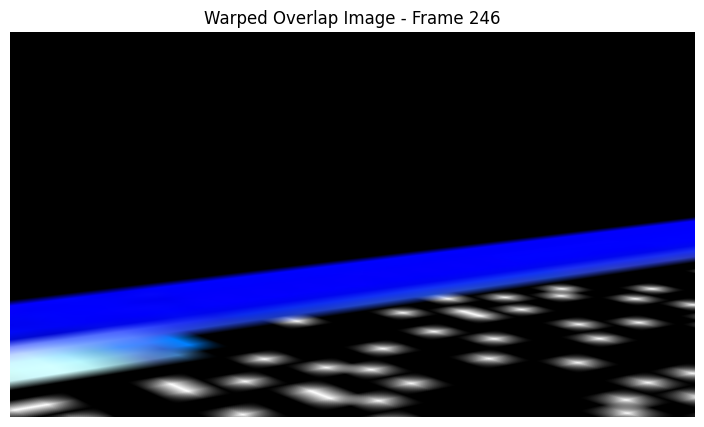

Iteration:  81%|████████▏ | 366/450 [01:06<00:15,  5.59it/s]

Normalized Homography matrix for frame 412:
[[ 4.4095993e-02  2.4999764e-03  8.5492317e+01]
 [ 2.9068436e-02  2.3633702e-01 -1.5777866e+02]
 [-3.6029720e-05  4.4026994e-03  1.0000000e+00]]


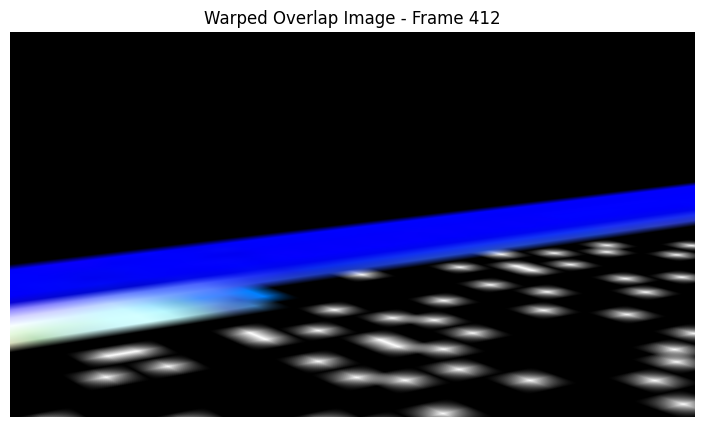

Iteration:  82%|████████▏ | 367/450 [01:06<00:15,  5.50it/s]

Normalized Homography matrix for frame 262:
[[ 4.7975115e-02  5.7325675e-03  1.2815358e+02]
 [ 3.5686042e-02  2.7190828e-01 -2.0208548e+02]
 [-4.4408513e-05  5.0799744e-03  1.0000000e+00]]


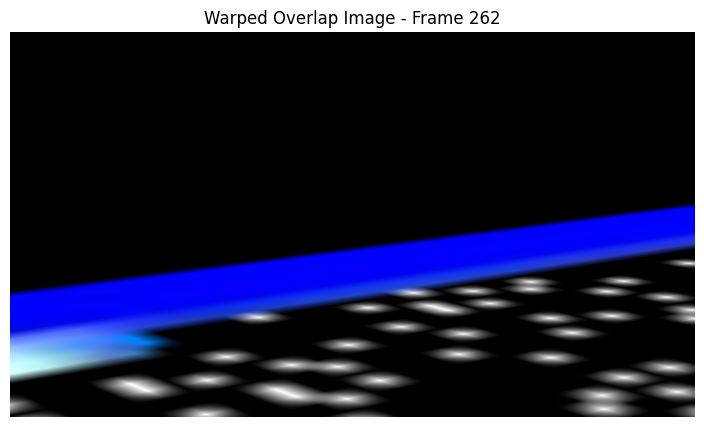

Iteration:  82%|████████▏ | 368/450 [01:06<00:14,  5.54it/s]

Normalized Homography matrix for frame 184:
[[ 8.05038363e-02  1.35957589e-02  1.02706085e+02]
 [ 3.90311107e-02  3.91604781e-01 -3.49476868e+02]
 [-7.35794629e-06  7.46364100e-03  1.00000000e+00]]


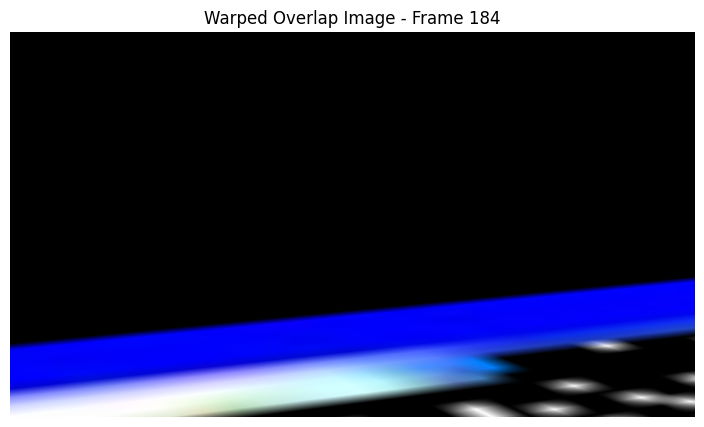

Iteration:  82%|████████▏ | 369/450 [01:06<00:14,  5.58it/s]

Normalized Homography matrix for frame 132:
[[ 2.00145587e-01 -5.37245907e-02  5.54013290e+01]
 [ 1.16182655e-01  5.49807847e-01 -6.68712830e+02]
 [ 8.43020331e-04  1.21251671e-02  1.00000000e+00]]


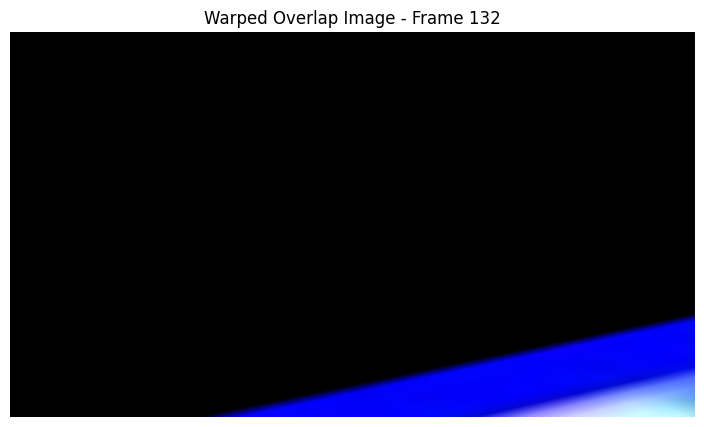

Iteration:  82%|████████▏ | 370/450 [01:07<00:14,  5.61it/s]

Normalized Homography matrix for frame 150:
[[ 8.8359460e-02 -1.1889103e-03 -1.8744905e+01]
 [ 1.9507697e-02  2.8346094e-01 -2.4677779e+02]
 [-4.3657337e-06  4.1300524e-03  1.0000000e+00]]


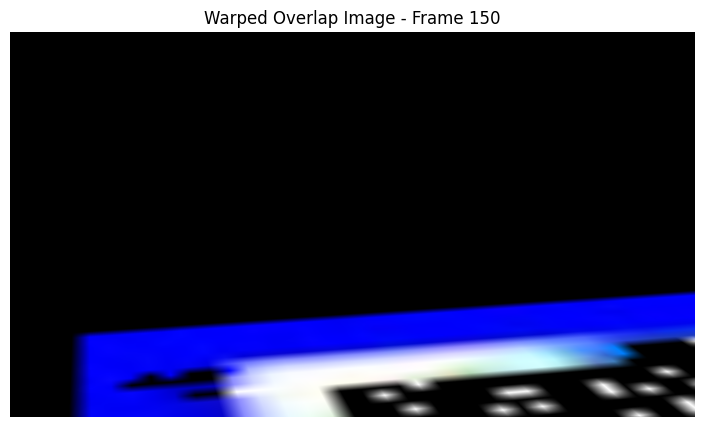

Iteration:  82%|████████▏ | 371/450 [01:07<00:14,  5.43it/s]

Normalized Homography matrix for frame 303:
[[ 4.2014211e-02  1.5793816e-03  9.1956261e+01]
 [ 2.8324958e-02  2.2837171e-01 -1.5813771e+02]
 [-3.8561891e-05  4.2274427e-03  1.0000000e+00]]


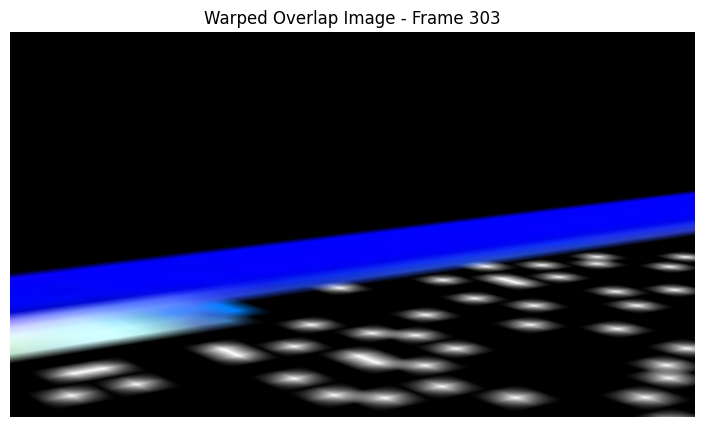

Iteration:  83%|████████▎ | 372/450 [01:07<00:14,  5.47it/s]

Normalized Homography matrix for frame 106:
[[ 7.8808770e-02  1.9365031e-02  2.0382895e+01]
 [ 2.4475619e-02  3.4133607e-01 -3.1042511e+02]
 [ 6.3847452e-05  6.1704237e-03  1.0000000e+00]]


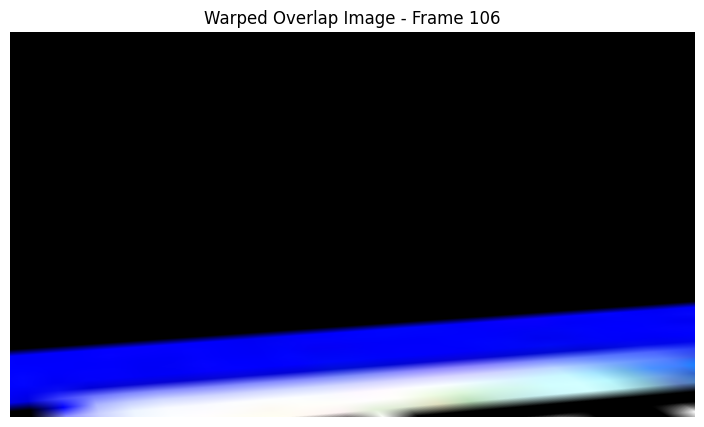

Iteration:  83%|████████▎ | 373/450 [01:07<00:15,  4.92it/s]

Normalized Homography matrix for frame 143:
[[ 1.7107895e-01  6.1728947e-02 -3.5849918e+01]
 [ 3.4949709e-02  6.6949707e-01 -5.6611877e+02]
 [-1.5389140e-05  1.1672704e-02  1.0000000e+00]]


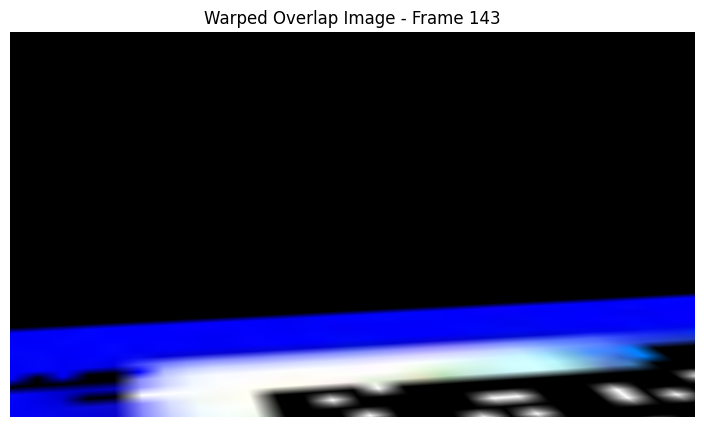

Iteration:  83%|████████▎ | 374/450 [01:07<00:14,  5.07it/s]

Normalized Homography matrix for frame 79:
[[ 9.5954195e-02  4.0055186e-02 -2.4688339e+01]
 [ 2.2627361e-02  3.7696159e-01 -3.2013327e+02]
 [ 1.2446872e-04  6.8321954e-03  1.0000000e+00]]


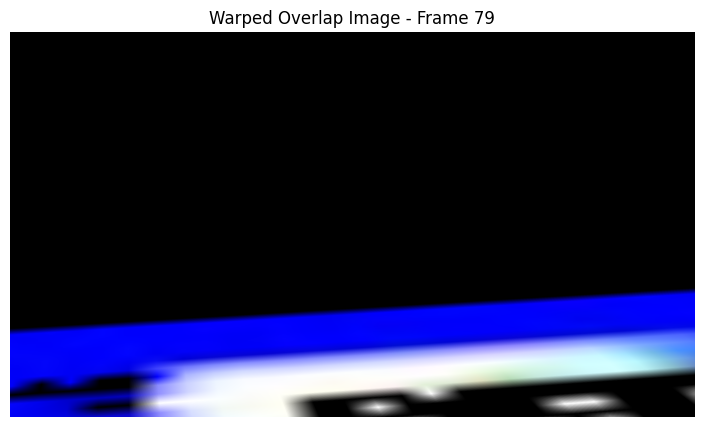

Iteration:  83%|████████▎ | 375/450 [01:08<00:14,  5.23it/s]

Normalized Homography matrix for frame 82:
[[ 2.2655660e-01  1.4270511e-01 -8.4663422e+01]
 [ 5.1986951e-02  8.5822618e-01 -7.3774969e+02]
 [ 3.4370527e-04  1.8069018e-02  1.0000000e+00]]


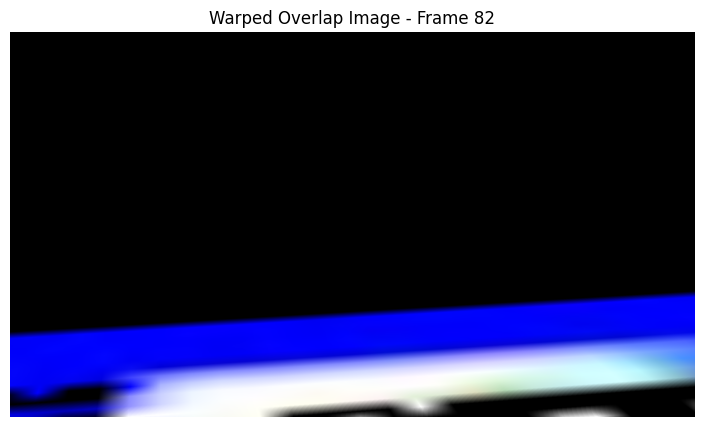

Iteration:  84%|████████▎ | 376/450 [01:08<00:13,  5.38it/s]

Normalized Homography matrix for frame 439:
[[ 4.1722022e-02  3.6548471e-04  8.2066055e+01]
 [ 2.7664663e-02  2.2473456e-01 -1.4845337e+02]
 [-2.7152479e-05  4.1110739e-03  1.0000000e+00]]


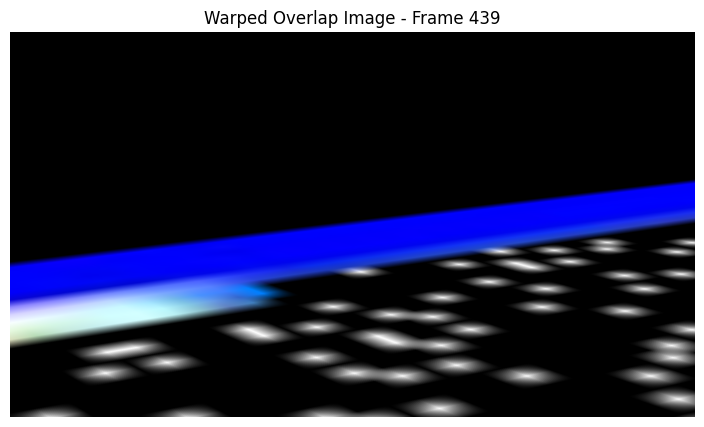

Iteration:  84%|████████▍ | 377/450 [01:08<00:13,  5.40it/s]

Normalized Homography matrix for frame 443:
[[ 4.0171538e-02 -5.6340738e-04  8.0279831e+01]
 [ 2.5983550e-02  2.1815456e-01 -1.4305788e+02]
 [-3.5158504e-05  3.9341724e-03  1.0000000e+00]]


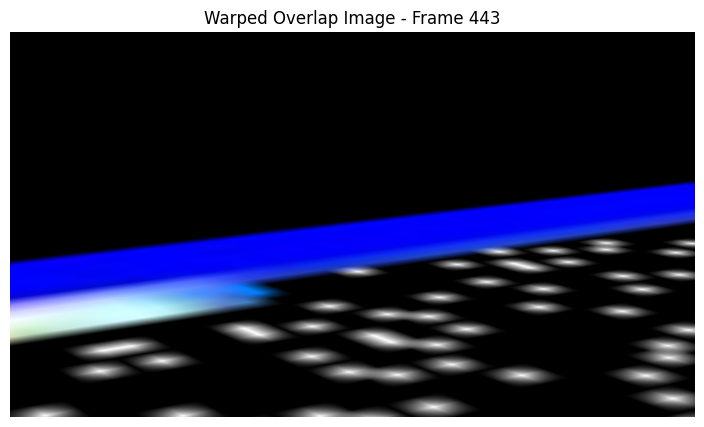

Iteration:  84%|████████▍ | 378/450 [01:08<00:13,  5.41it/s]

Normalized Homography matrix for frame 226:
[[ 8.39614347e-02  1.00988485e-02  1.70004807e+02]
 [ 5.42051569e-02  4.55948889e-01 -3.61525787e+02]
 [-8.52247031e-05  8.58020410e-03  1.00000000e+00]]


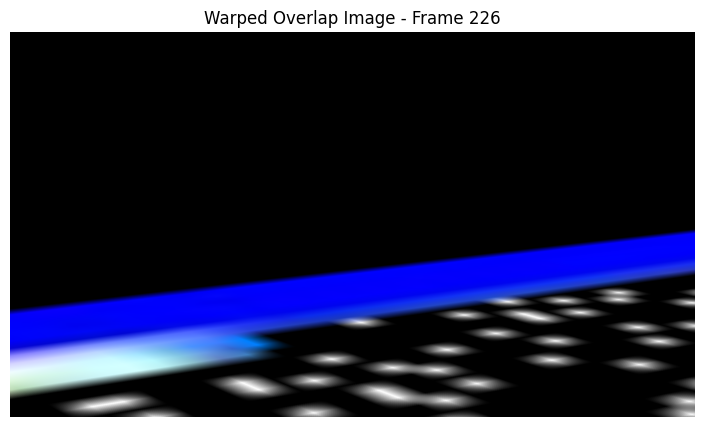

Iteration:  84%|████████▍ | 379/450 [01:08<00:12,  5.51it/s]

Normalized Homography matrix for frame 325:
[[ 4.9314003e-02  2.7511821e-03  8.5465874e+01]
 [ 3.0731553e-02  2.6244977e-01 -1.7827747e+02]
 [-3.1537922e-05  4.8192292e-03  1.0000000e+00]]


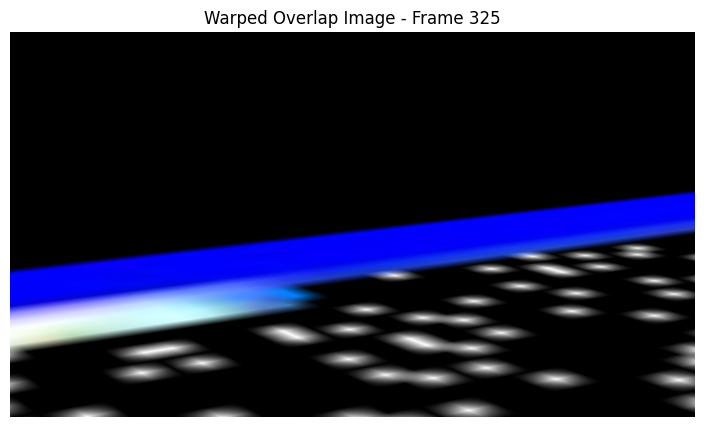

Iteration:  84%|████████▍ | 380/450 [01:08<00:12,  5.50it/s]

Normalized Homography matrix for frame 239:
[[ 7.0011429e-02  6.0600168e-03  1.5751993e+02]
 [ 4.9396150e-02  3.8118634e-01 -2.9889890e+02]
 [-5.0679155e-05  7.1929023e-03  1.0000000e+00]]


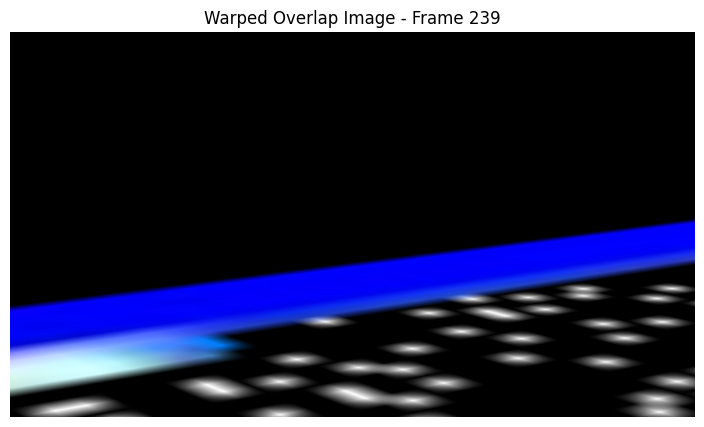

Iteration:  85%|████████▍ | 381/450 [01:09<00:12,  5.52it/s]

Normalized Homography matrix for frame 156:
[[ 8.4281705e-02 -4.2928536e-03  7.2003710e-01]
 [ 2.2389989e-02  2.8288126e-01 -2.5107266e+02]
 [-2.2347813e-05  4.3535936e-03  1.0000000e+00]]


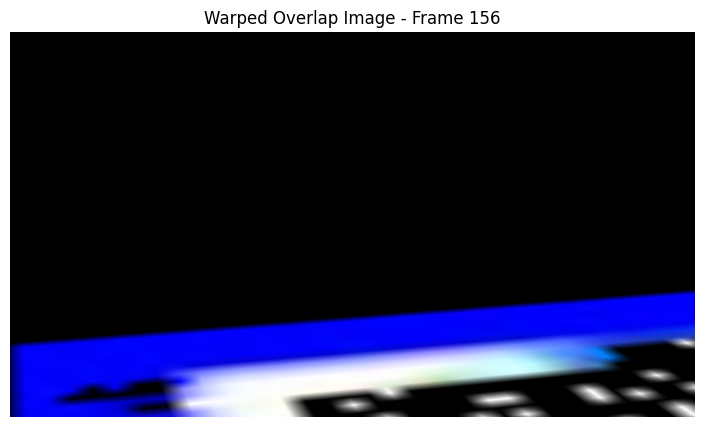

Iteration:  85%|████████▍ | 382/450 [01:09<00:12,  5.48it/s]

Normalized Homography matrix for frame 272:
[[ 4.2402487e-02  6.4460048e-03  1.1888702e+02]
 [ 3.2383040e-02  2.4213688e-01 -1.7538921e+02]
 [-3.8120586e-05  4.5360662e-03  1.0000000e+00]]


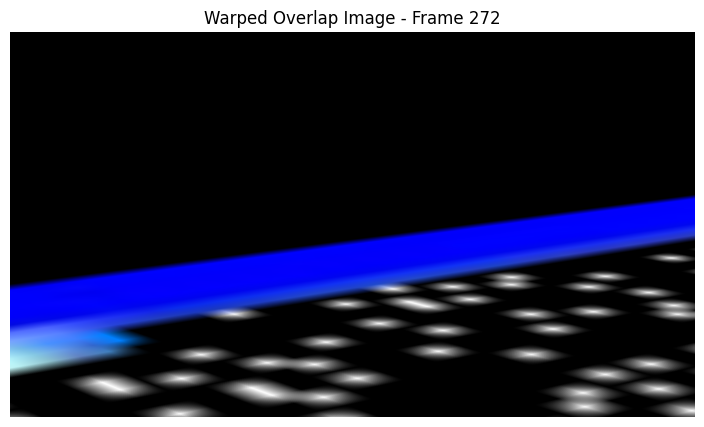

Iteration:  85%|████████▌ | 383/450 [01:09<00:12,  5.49it/s]

Normalized Homography matrix for frame 99:
[[ 9.32960063e-02  3.74375582e-02  1.21634752e-01]
 [ 2.68717501e-02  3.76140893e-01 -3.36523102e+02]
 [ 1.15403716e-04  7.01844087e-03  1.00000000e+00]]


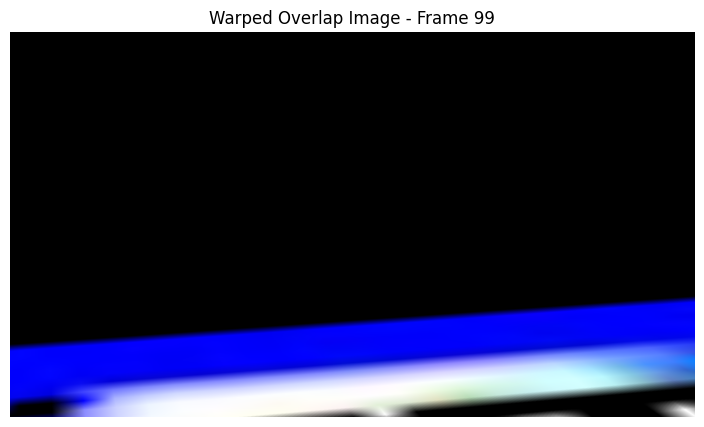

Iteration:  85%|████████▌ | 384/450 [01:09<00:11,  5.56it/s]

Normalized Homography matrix for frame 269:
[[ 4.4886127e-02  8.1831943e-03  1.2345880e+02]
 [ 3.4313615e-02  2.5426155e-01 -1.8640059e+02]
 [-3.9601749e-05  4.8194751e-03  1.0000000e+00]]


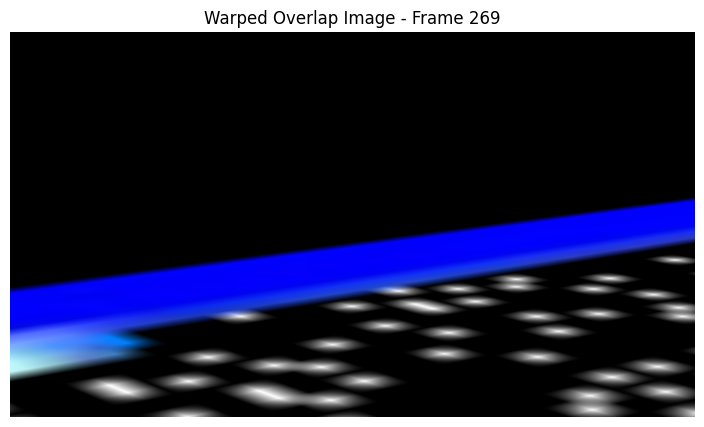

Iteration:  86%|████████▌ | 385/450 [01:09<00:11,  5.54it/s]

Normalized Homography matrix for frame 309:
[[ 4.7605179e-02  4.8460076e-03  9.1500618e+01]
 [ 3.1192623e-02  2.5594851e-01 -1.7594968e+02]
 [-2.9899764e-05  4.7550662e-03  1.0000000e+00]]


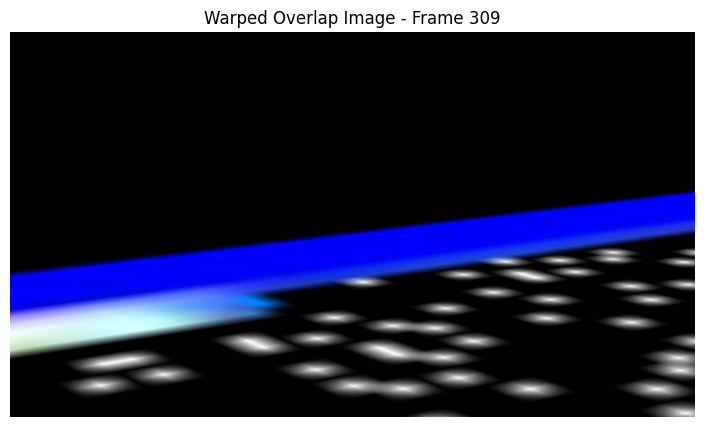

Iteration:  86%|████████▌ | 386/450 [01:09<00:11,  5.55it/s]

Normalized Homography matrix for frame 335:
[[ 5.0750311e-02  6.1040842e-03  8.7293594e+01]
 [ 3.2117855e-02  2.6825789e-01 -1.8188876e+02]
 [-3.4657765e-05  5.0635417e-03  1.0000000e+00]]


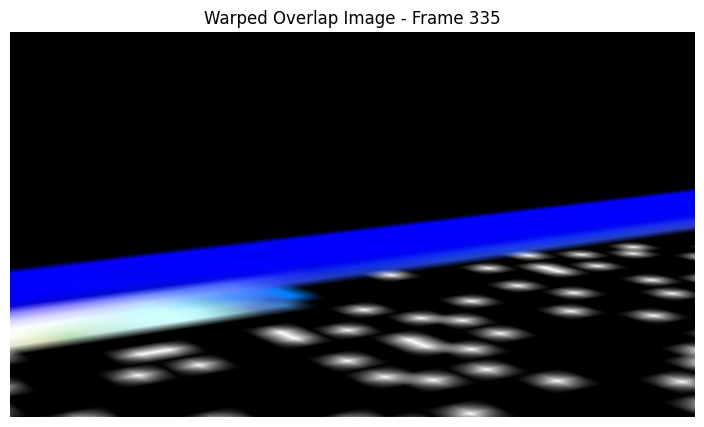

Iteration:  86%|████████▌ | 387/450 [01:10<00:11,  5.53it/s]

Normalized Homography matrix for frame 189:
[[ 8.3101682e-02  1.5205549e-02  1.1395364e+02]
 [ 4.1201863e-02  4.1768765e-01 -3.6316583e+02]
 [-2.4443454e-05  7.8317309e-03  1.0000000e+00]]


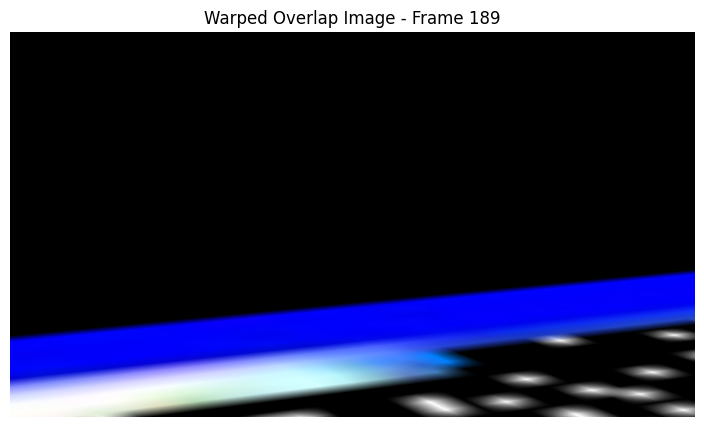

Iteration:  86%|████████▌ | 388/450 [01:10<00:11,  5.59it/s]

Normalized Homography matrix for frame 353:
[[ 4.6846583e-02  1.9345613e-03  8.6638565e+01]
 [ 2.9557826e-02  2.5331873e-01 -1.6951079e+02]
 [-4.3444103e-05  4.6514473e-03  1.0000000e+00]]


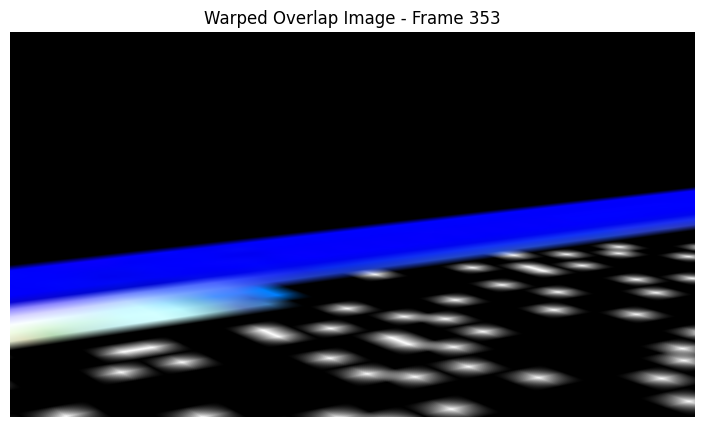

Iteration:  86%|████████▋ | 389/450 [01:10<00:10,  5.56it/s]

Normalized Homography matrix for frame 138:
[[ 9.6926175e-02 -1.9940145e-02  2.2319082e+01]
 [ 4.1897412e-02  2.0047238e-01 -2.6272739e+02]
 [-1.3624933e-04  6.3005327e-03  1.0000000e+00]]


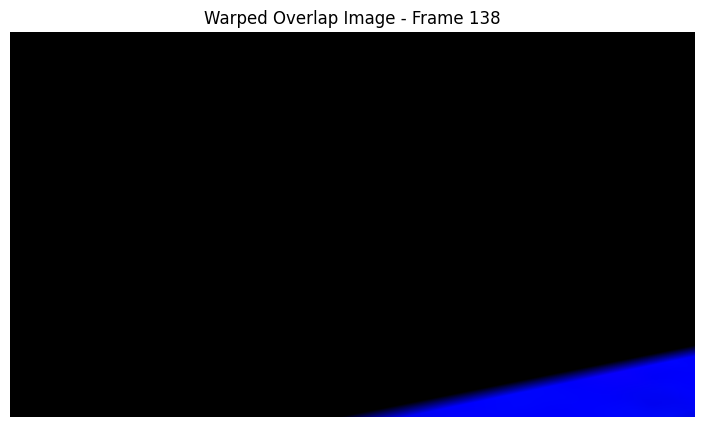

Iteration:  87%|████████▋ | 390/450 [01:10<00:10,  5.61it/s]

Normalized Homography matrix for frame 334:
[[ 4.9343914e-02  3.4678176e-03  8.4591583e+01]
 [ 3.0526448e-02  2.6158470e-01 -1.7647763e+02]
 [-3.7665166e-05  4.8111724e-03  1.0000000e+00]]


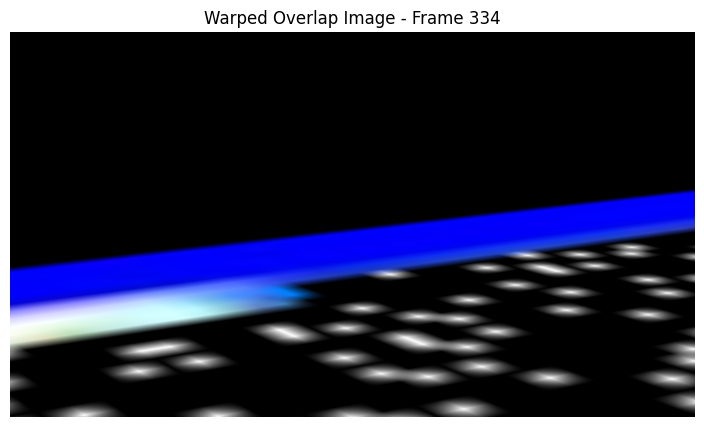

Iteration:  87%|████████▋ | 391/450 [01:10<00:10,  5.59it/s]

Normalized Homography matrix for frame 426:
[[ 4.2964604e-02  3.3936056e-03  8.3796219e+01]
 [ 2.8016325e-02  2.3440710e-01 -1.5424155e+02]
 [-3.2118798e-05  4.3115905e-03  1.0000000e+00]]


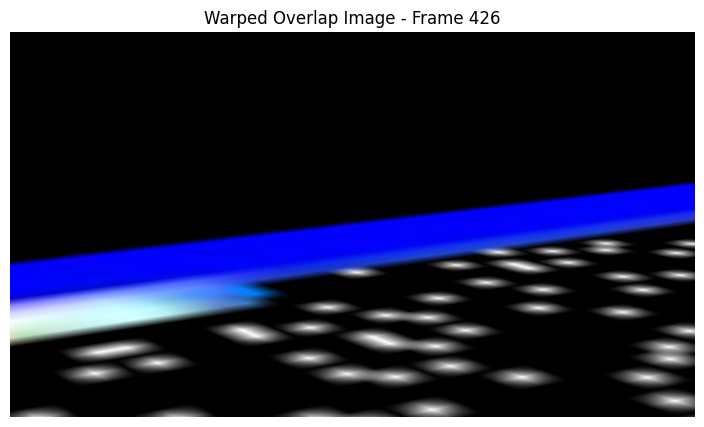

Iteration:  87%|████████▋ | 392/450 [01:11<00:10,  5.54it/s]

Normalized Homography matrix for frame 12:
[[ 4.6118692e-01  6.4889831e-03 -3.2629163e+02]
 [ 3.7639108e-02  2.0229447e+00 -1.4509175e+03]
 [ 2.2266751e-05  3.8392548e-02  1.0000000e+00]]


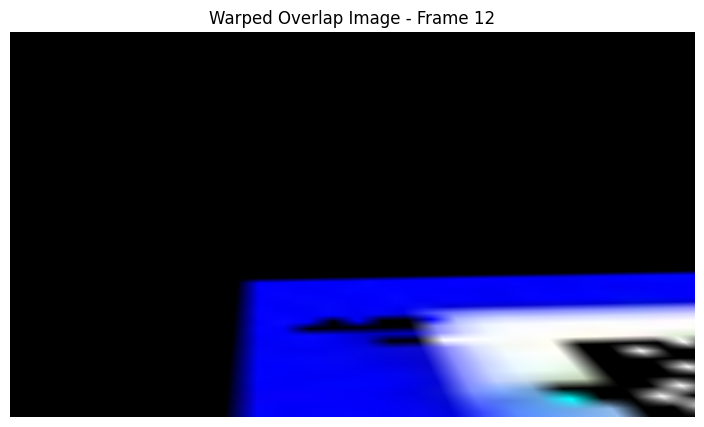

Iteration:  87%|████████▋ | 393/450 [01:11<00:10,  5.60it/s]

Normalized Homography matrix for frame 258:
[[ 5.0022565e-02  5.7741692e-03  1.2813777e+02]
 [ 3.6340747e-02  2.7876166e-01 -2.0975938e+02]
 [-4.6183959e-05  5.1655299e-03  1.0000000e+00]]


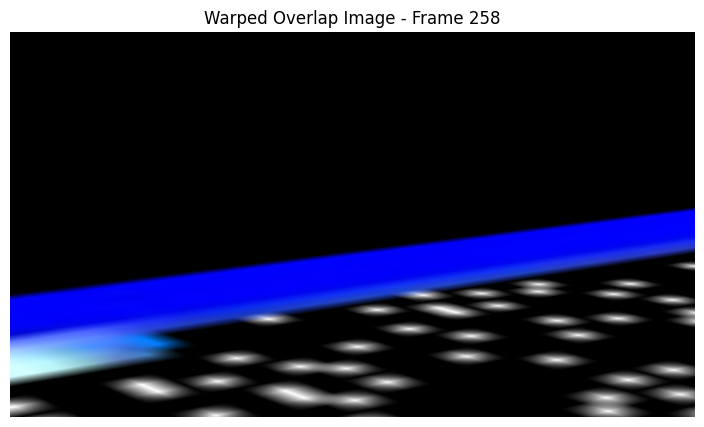

Iteration:  88%|████████▊ | 394/450 [01:11<00:10,  5.58it/s]

Normalized Homography matrix for frame 423:
[[ 4.2206023e-02  1.7228569e-03  8.4118355e+01]
 [ 2.7457019e-02  2.3268735e-01 -1.5298698e+02]
 [-3.2693650e-05  4.2351643e-03  1.0000000e+00]]


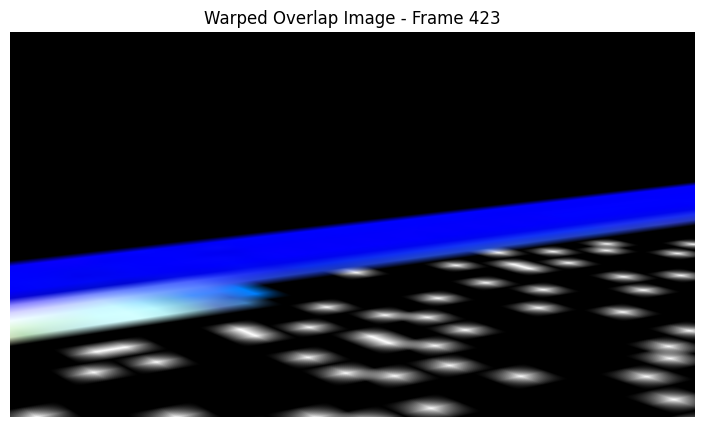

Iteration:  88%|████████▊ | 395/450 [01:11<00:09,  5.54it/s]

Normalized Homography matrix for frame 139:
[[ 2.0443808e-01 -6.8768062e-02  7.4132385e+01]
 [ 1.0857873e-01  5.6931865e-01 -6.6415033e+02]
 [ 4.2264949e-04  1.3749198e-02  1.0000000e+00]]


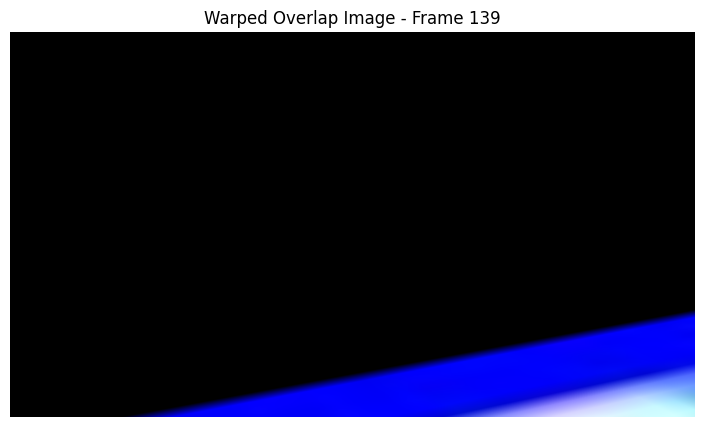

Iteration:  88%|████████▊ | 396/450 [01:11<00:09,  5.60it/s]

Normalized Homography matrix for frame 47:
[[ 1.4365976e-01 -3.4479694e-03 -3.9878727e+01]
 [ 2.6778573e-02  6.3201338e-01 -4.7472446e+02]
 [-3.2332671e-05  1.2468935e-02  1.0000000e+00]]


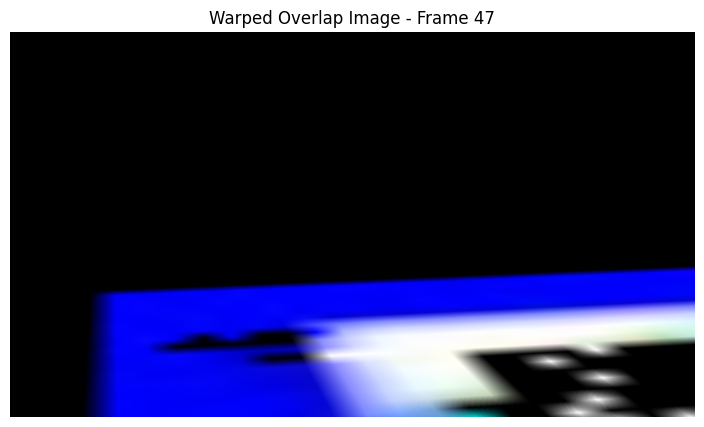

Iteration:  88%|████████▊ | 397/450 [01:11<00:09,  5.59it/s]

Normalized Homography matrix for frame 163:
[[ 5.6515388e-02 -1.3021581e-02  5.1885250e+01]
 [ 2.2870930e-02  2.4973954e-01 -2.2915030e+02]
 [-9.8428643e-07  3.9973506e-03  1.0000000e+00]]


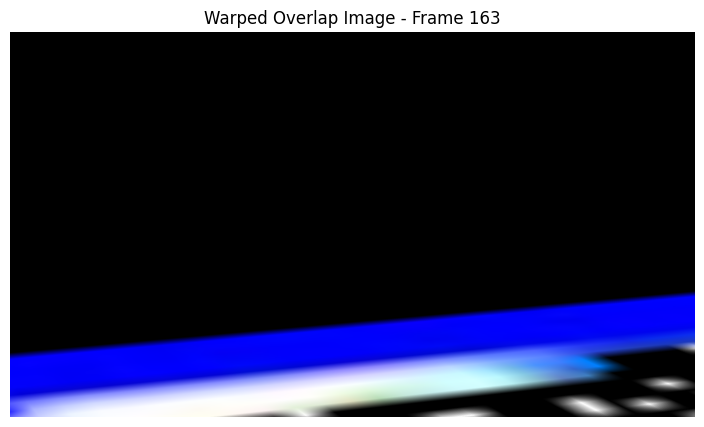

Iteration:  88%|████████▊ | 398/450 [01:12<00:09,  5.61it/s]

Normalized Homography matrix for frame 136:
[[ 2.01300547e-01  7.56537616e-02 -6.38970108e+01]
 [ 2.93101668e-02  8.62970591e-01 -6.69575623e+02]
 [-1.01268284e-04  1.30312731e-02  1.00000000e+00]]


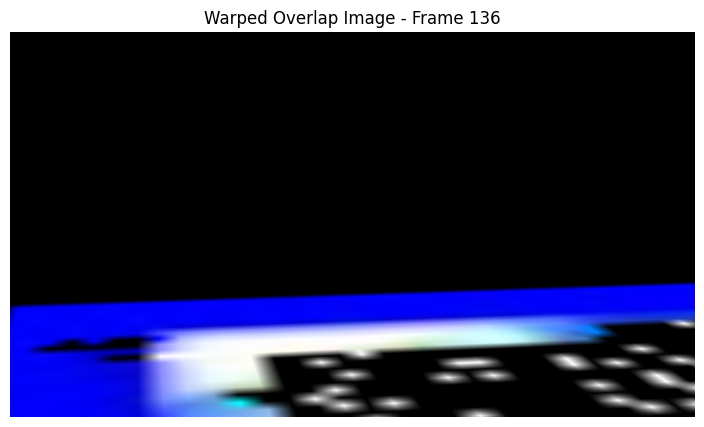

Iteration:  89%|████████▊ | 399/450 [01:12<00:09,  5.57it/s]

Normalized Homography matrix for frame 371:
[[ 4.6002265e-02  5.5738068e-03  8.6612343e+01]
 [ 3.0305259e-02  2.4806841e-01 -1.6586040e+02]
 [-2.4872206e-05  4.6379678e-03  1.0000000e+00]]


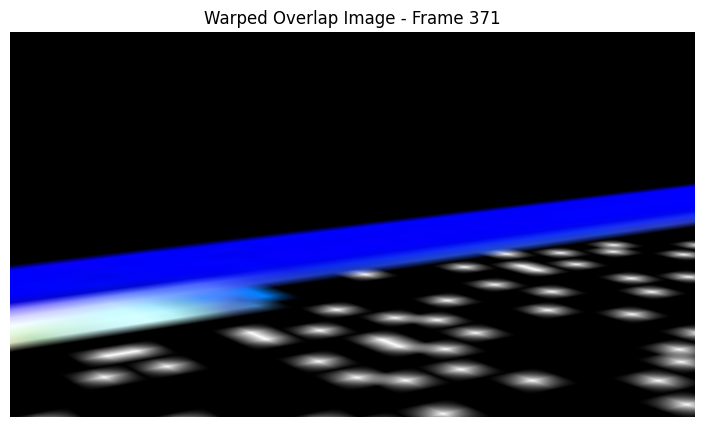

Iteration:  89%|████████▉ | 400/450 [01:12<00:09,  5.54it/s]

Normalized Homography matrix for frame 85:
[[ 1.5073420e-01  8.8749520e-02 -5.0034512e+01]
 [ 3.7053913e-02  5.7164872e-01 -4.9391071e+02]
 [ 2.6679528e-04  1.1183104e-02  1.0000000e+00]]


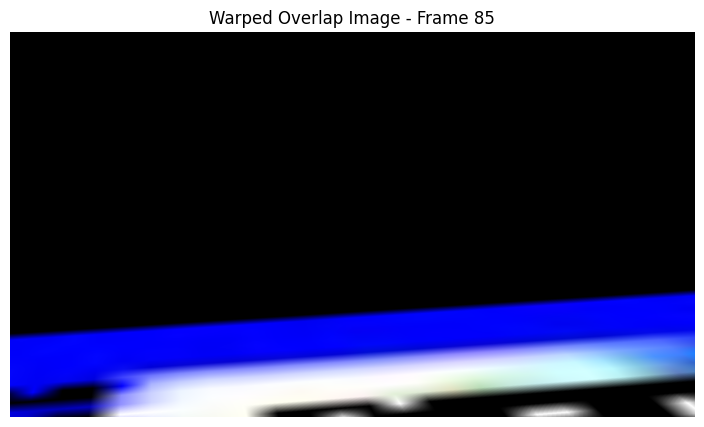

Iteration:  89%|████████▉ | 401/450 [01:12<00:08,  5.59it/s]

Normalized Homography matrix for frame 363:
[[ 4.5340668e-02  3.6863664e-03  8.5586624e+01]
 [ 2.9284248e-02  2.4423558e-01 -1.6313966e+02]
 [-3.5928344e-05  4.5313947e-03  1.0000000e+00]]


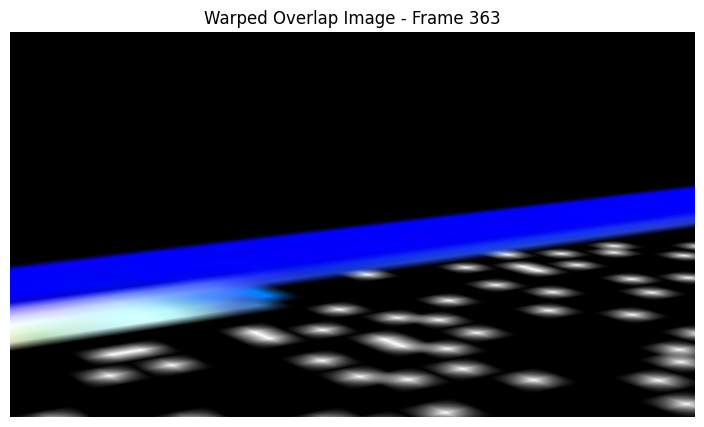

Iteration:  89%|████████▉ | 402/450 [01:12<00:08,  5.54it/s]

Normalized Homography matrix for frame 398:
[[ 4.4108890e-02  8.9838135e-04  8.6094582e+01]
 [ 2.9469065e-02  2.3541842e-01 -1.5836818e+02]
 [-3.1465217e-05  4.3895496e-03  1.0000000e+00]]


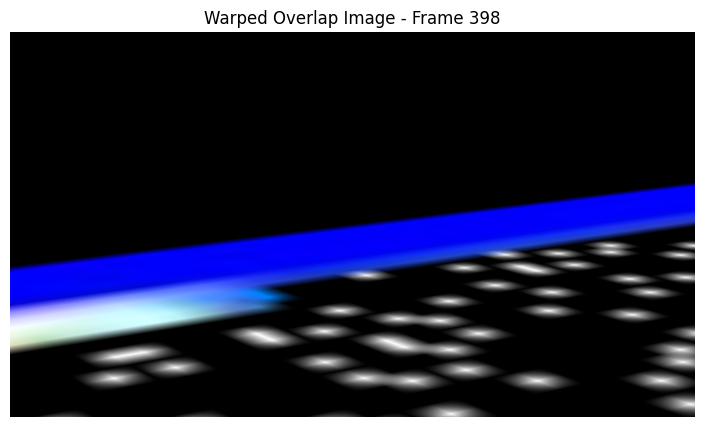

Iteration:  90%|████████▉ | 403/450 [01:13<00:08,  5.51it/s]

Normalized Homography matrix for frame 376:
[[ 4.4240355e-02  2.3990721e-03  8.6035866e+01]
 [ 2.8813822e-02  2.4055263e-01 -1.6023741e+02]
 [-3.5956906e-05  4.4513112e-03  1.0000000e+00]]


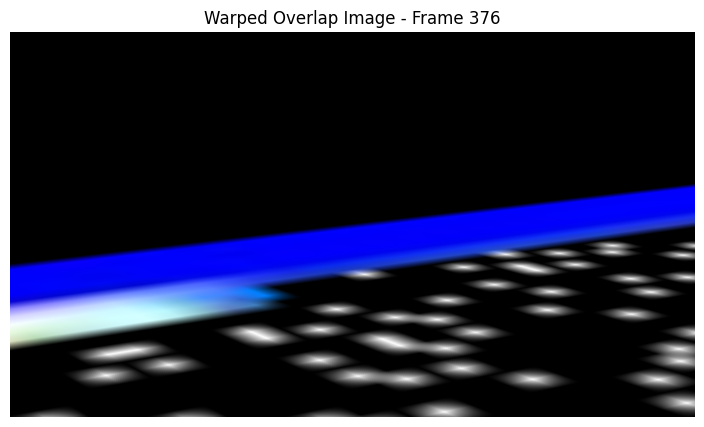

Iteration:  90%|████████▉ | 404/450 [01:13<00:08,  5.50it/s]

Normalized Homography matrix for frame 251:
[[ 6.0683526e-02  1.0920124e-02  1.4681328e+02]
 [ 4.4001136e-02  3.3816710e-01 -2.5905441e+02]
 [-4.2798474e-05  6.3735405e-03  1.0000000e+00]]


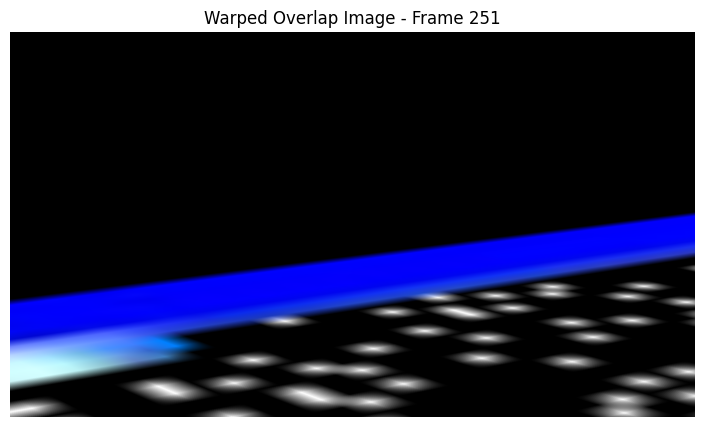

Iteration:  90%|█████████ | 405/450 [01:13<00:08,  5.54it/s]

Normalized Homography matrix for frame 259:
[[ 5.3337660e-02  1.3363607e-02  1.3167517e+02]
 [ 3.8362108e-02  2.9809964e-01 -2.2322801e+02]
 [-4.4804958e-05  5.5866158e-03  1.0000000e+00]]


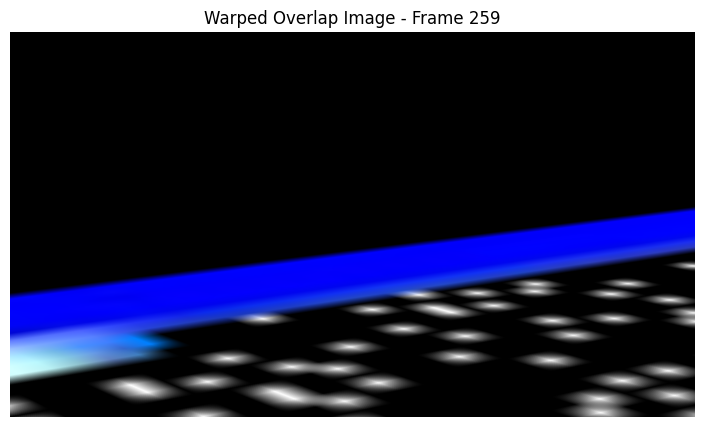

Iteration:  90%|█████████ | 406/450 [01:13<00:07,  5.53it/s]

Normalized Homography matrix for frame 119:
[[ 3.50587964e-01  1.53026596e-01  9.30809250e+01]
 [ 1.08098604e-01  1.50047493e+00 -1.39423657e+03]
 [-1.03994389e-04  3.47626172e-02  1.00000000e+00]]


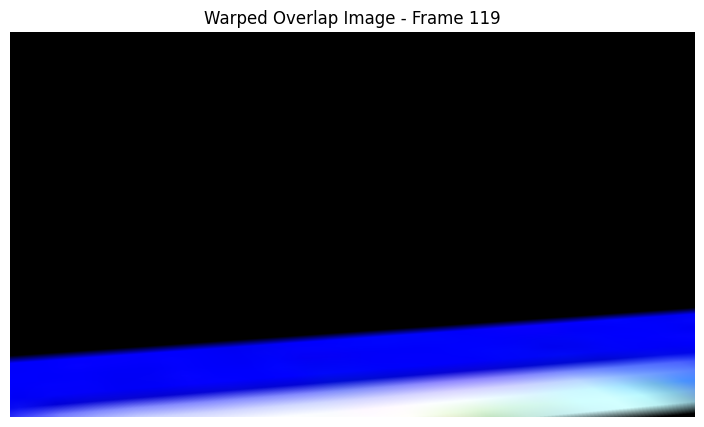

Iteration:  90%|█████████ | 407/450 [01:13<00:07,  5.57it/s]

Normalized Homography matrix for frame 158:
[[ 7.4733220e-02 -2.9745090e-03  1.2906945e+01]
 [ 2.2164902e-02  2.6541805e-01 -2.3819046e+02]
 [-9.6381273e-06  4.1375109e-03  1.0000000e+00]]


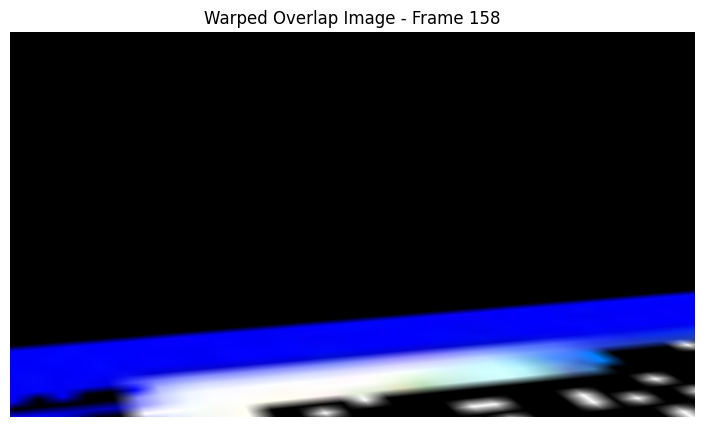

Iteration:  91%|█████████ | 408/450 [01:13<00:07,  5.61it/s]

Normalized Homography matrix for frame 113:
[[ 5.3374660e-01  1.8542287e-01 -1.7515691e+02]
 [ 7.6702543e-02  2.5384581e+00 -1.9225681e+03]
 [-2.7746172e-04  3.8980931e-02  1.0000000e+00]]


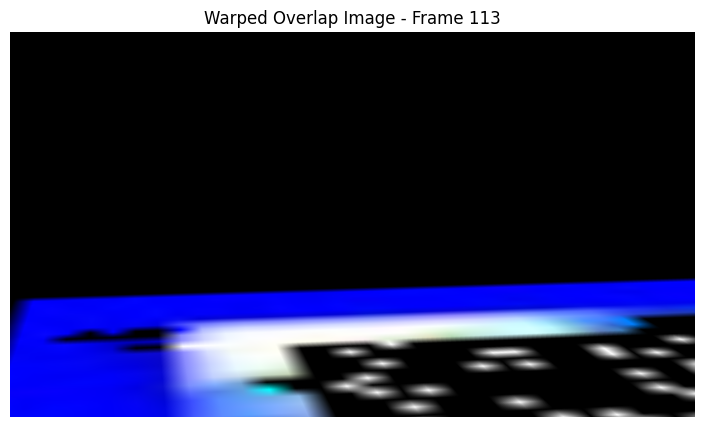

Iteration:  91%|█████████ | 409/450 [01:14<00:07,  5.60it/s]

Normalized Homography matrix for frame 396:
[[ 4.6681043e-02  9.6404841e-03  8.4711082e+01]
 [ 3.0172011e-02  2.4892433e-01 -1.6560106e+02]
 [-2.8651079e-05  4.6690842e-03  1.0000000e+00]]


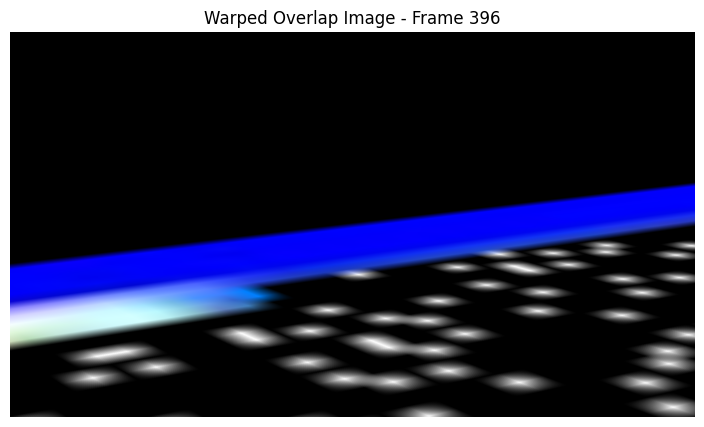

Iteration:  91%|█████████ | 410/450 [01:14<00:07,  5.59it/s]

Normalized Homography matrix for frame 380:
[[ 4.2858638e-02  2.3251385e-03  8.3580956e+01]
 [ 2.7659293e-02  2.3243645e-01 -1.5440523e+02]
 [-3.5484365e-05  4.2620879e-03  1.0000000e+00]]


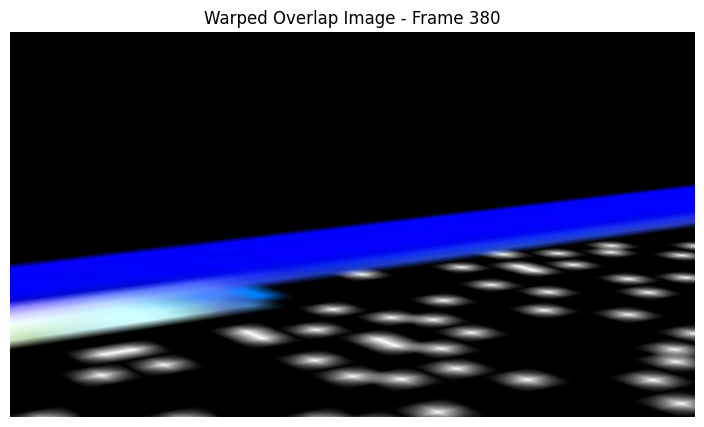

Iteration:  91%|█████████▏| 411/450 [01:14<00:07,  5.56it/s]

Normalized Homography matrix for frame 256:
[[ 5.5771817e-02  1.3935233e-02  1.3545398e+02]
 [ 3.9642323e-02  3.1022343e-01 -2.3407205e+02]
 [-5.4233846e-05  5.8514280e-03  1.0000000e+00]]


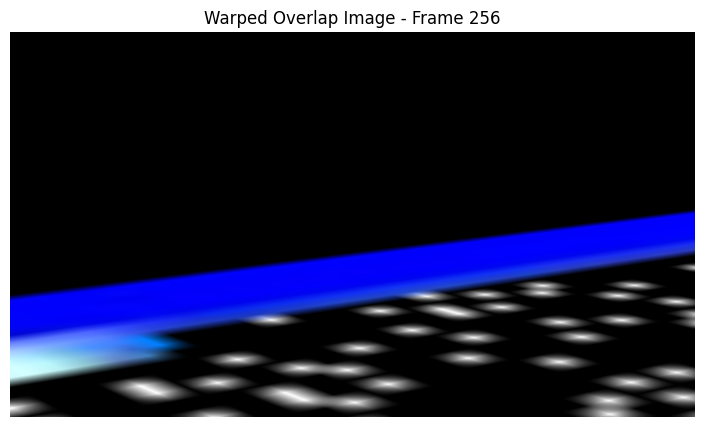

Iteration:  92%|█████████▏| 412/450 [01:14<00:06,  5.58it/s]

Normalized Homography matrix for frame 290:
[[ 3.4497719e-02  2.6424562e-03  9.7102577e+01]
 [ 2.5662325e-02  1.9707361e-01 -1.3541925e+02]
 [-3.7195201e-05  3.6883578e-03  1.0000000e+00]]


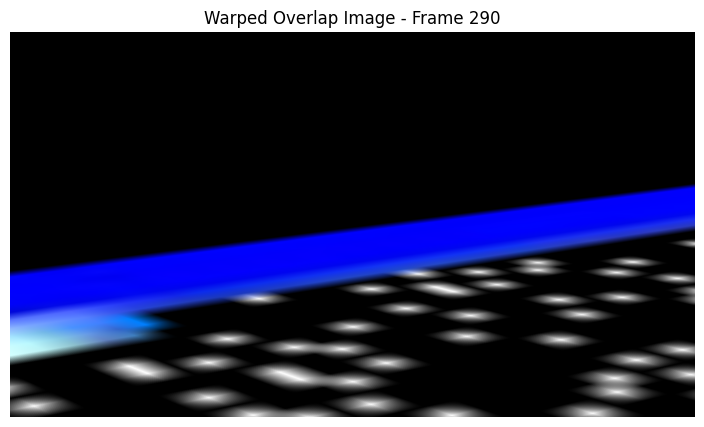

Iteration:  92%|█████████▏| 413/450 [01:14<00:07,  4.93it/s]

Normalized Homography matrix for frame 433:
[[ 4.1995212e-02  2.8121811e-03  8.2666580e+01]
 [ 2.7718248e-02  2.2765391e-01 -1.4988071e+02]
 [-2.9405306e-05  4.2077936e-03  1.0000000e+00]]


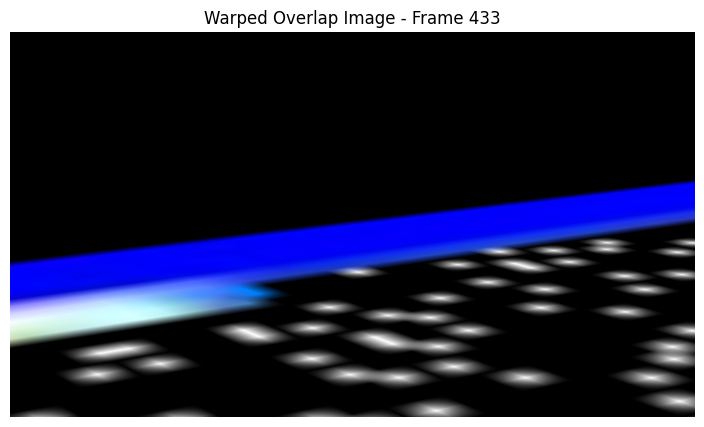

Iteration:  92%|█████████▏| 414/450 [01:15<00:07,  5.08it/s]

Normalized Homography matrix for frame 125:
[[ 2.3771109e-01  1.1180778e-01  6.0628754e+01]
 [ 7.3836274e-02  1.0038482e+00 -9.3630408e+02]
 [-1.0451441e-05  2.2802368e-02  1.0000000e+00]]


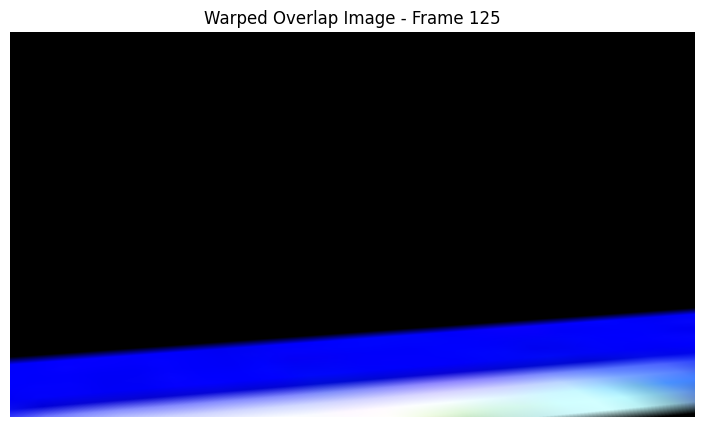

Iteration:  92%|█████████▏| 415/450 [01:15<00:06,  5.24it/s]

Normalized Homography matrix for frame 286:
[[ 3.5718028e-02  6.2805107e-03  1.0054396e+02]
 [ 2.7049894e-02  2.0301996e-01 -1.4026253e+02]
 [-3.5768622e-05  3.8450549e-03  1.0000000e+00]]


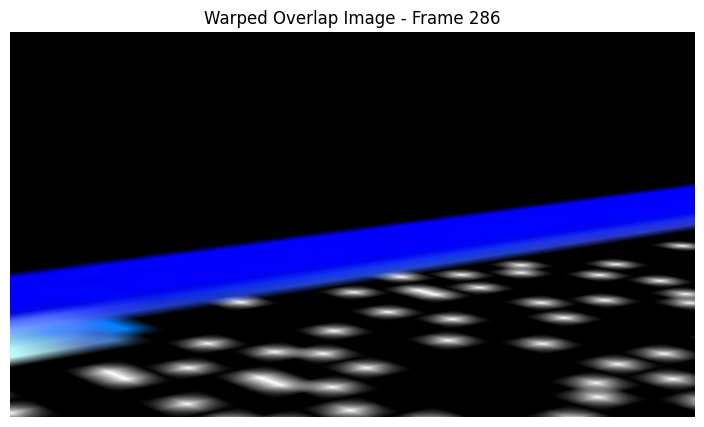

Iteration:  92%|█████████▏| 416/450 [01:15<00:06,  5.34it/s]

Normalized Homography matrix for frame 359:
[[ 4.6514992e-02  2.2901820e-03  8.7593262e+01]
 [ 3.0312169e-02  2.4957858e-01 -1.6756062e+02]
 [-3.7688671e-05  4.6467083e-03  1.0000000e+00]]


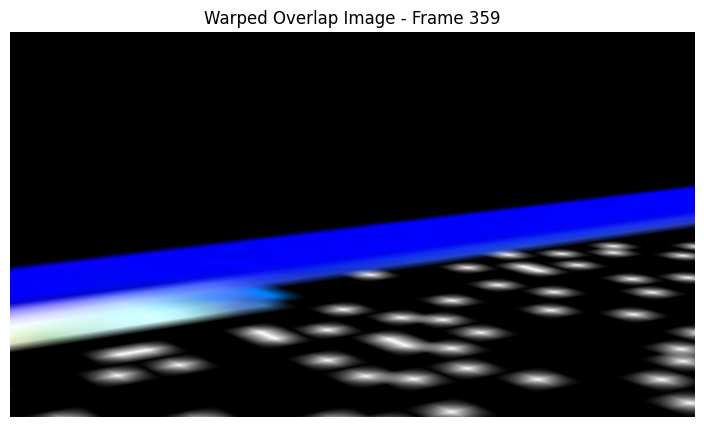

Iteration:  93%|█████████▎| 417/450 [01:15<00:06,  5.40it/s]

Normalized Homography matrix for frame 343:
[[ 5.1726729e-02  9.4705792e-03  8.9851349e+01]
 [ 3.2107785e-02  2.8073856e-01 -1.8768892e+02]
 [-4.5277207e-05  5.2958718e-03  1.0000000e+00]]


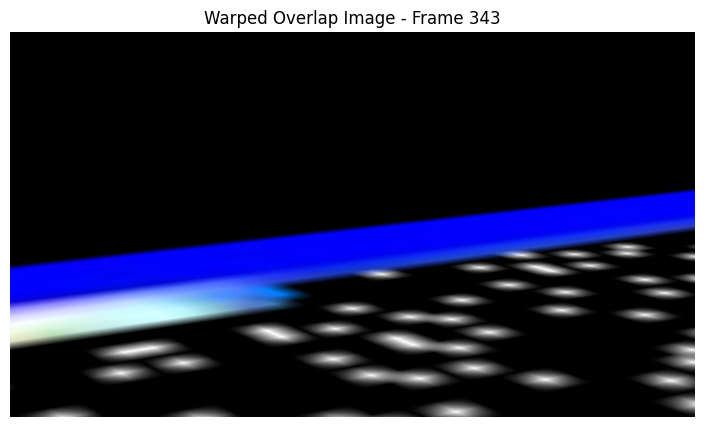

Iteration:  93%|█████████▎| 418/450 [01:15<00:05,  5.39it/s]

Normalized Homography matrix for frame 155:
[[ 7.1073122e-02 -7.2499234e-03  1.4949813e+01]
 [ 2.0930080e-02  2.5249255e-01 -2.2839856e+02]
 [-2.2705362e-05  3.9515304e-03  1.0000000e+00]]


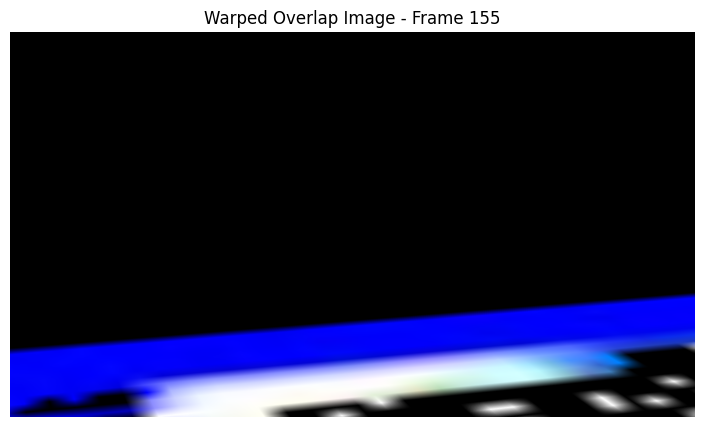

Iteration:  93%|█████████▎| 419/450 [01:16<00:05,  5.45it/s]

Normalized Homography matrix for frame 306:
[[ 4.4405784e-02  3.0502114e-03  9.1728134e+01]
 [ 2.9543450e-02  2.4055678e-01 -1.6601276e+02]
 [-3.4955290e-05  4.4752602e-03  1.0000000e+00]]


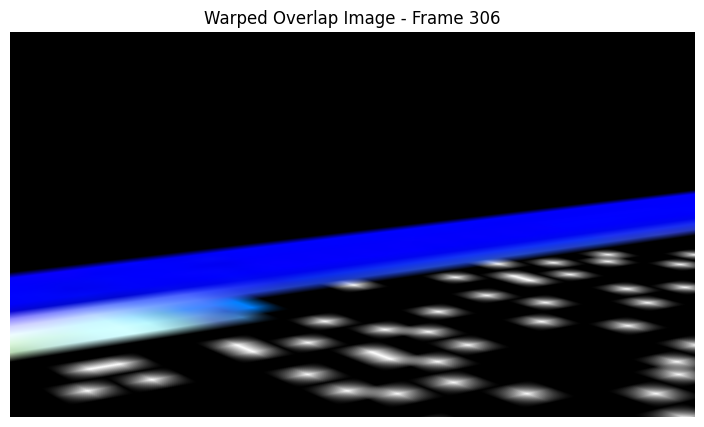

Iteration:  93%|█████████▎| 420/450 [01:16<00:05,  5.49it/s]

Normalized Homography matrix for frame 199:
[[ 7.3080011e-02  6.6241284e-04  1.2214396e+02]
 [ 3.9975546e-02  3.7613860e-01 -3.1698254e+02]
 [-4.3945038e-05  6.7611155e-03  1.0000000e+00]]


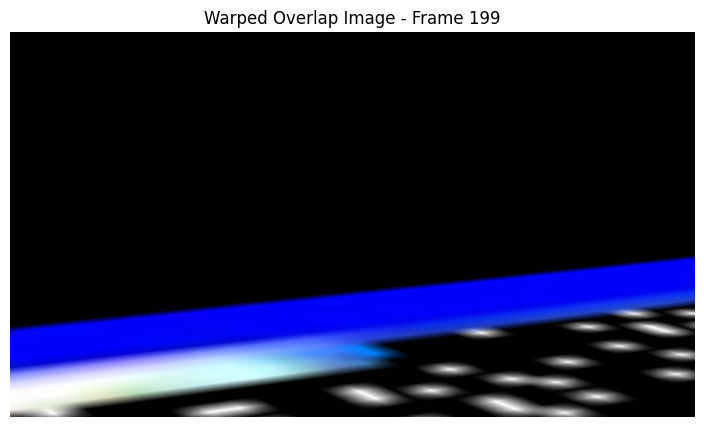

Iteration:  94%|█████████▎| 421/450 [01:16<00:05,  5.54it/s]

Normalized Homography matrix for frame 416:
[[ 4.3453395e-02  2.6514647e-03  8.3499252e+01]
 [ 2.7592488e-02  2.3507664e-01 -1.5519740e+02]
 [-4.5477183e-05  4.3054791e-03  1.0000000e+00]]


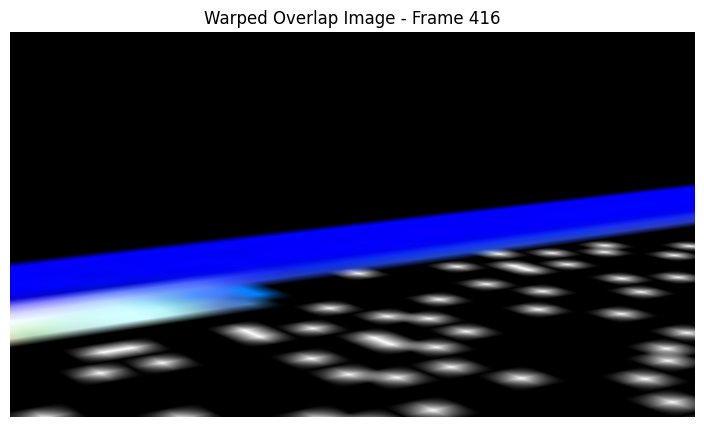

Iteration:  94%|█████████▍| 422/450 [01:16<00:05,  5.51it/s]

Normalized Homography matrix for frame 274:
[[ 3.8964145e-02  4.1917851e-03  1.1166407e+02]
 [ 2.9434152e-02  2.2451115e-01 -1.6080066e+02]
 [-3.2239433e-05  4.1020722e-03  1.0000000e+00]]


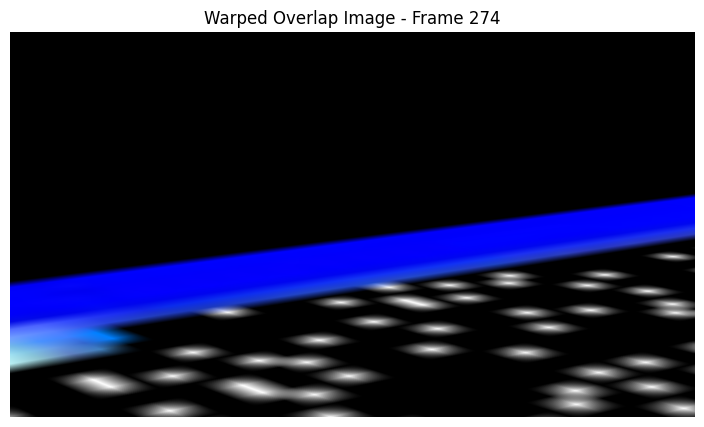

Iteration:  94%|█████████▍| 423/450 [01:16<00:04,  5.53it/s]

Normalized Homography matrix for frame 176:
[[ 6.6487387e-02  1.3480136e-03  8.2536385e+01]
 [ 3.0416660e-02  3.2038984e-01 -2.9039877e+02]
 [-7.0841638e-06  5.8523938e-03  1.0000000e+00]]


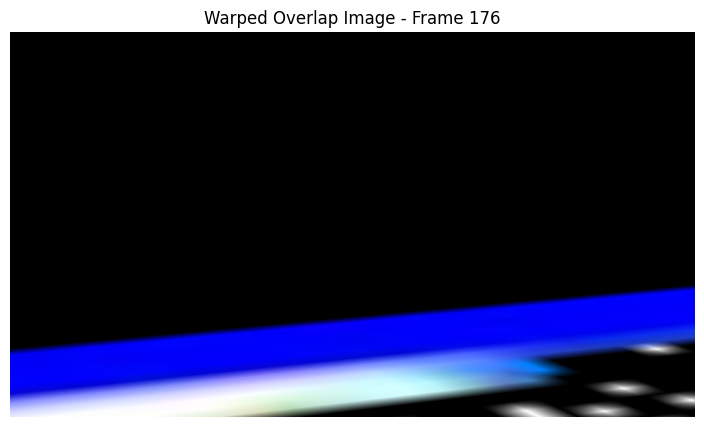

Iteration:  94%|█████████▍| 424/450 [01:16<00:04,  5.59it/s]

Normalized Homography matrix for frame 447:
[[ 4.1567612e-02  6.1972102e-04  8.1186691e+01]
 [ 2.7455145e-02  2.2311470e-01 -1.4717120e+02]
 [-2.6900630e-05  4.0678689e-03  1.0000000e+00]]


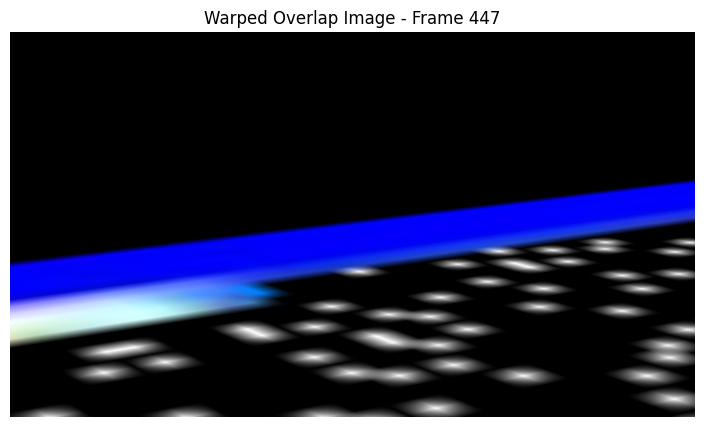

Iteration:  94%|█████████▍| 425/450 [01:17<00:04,  5.54it/s]

Normalized Homography matrix for frame 217:
[[ 7.9128586e-02  1.3329387e-03  1.5563283e+02]
 [ 5.0465241e-02  4.1876826e-01 -3.4035754e+02]
 [-5.8429232e-05  7.8058140e-03  1.0000000e+00]]


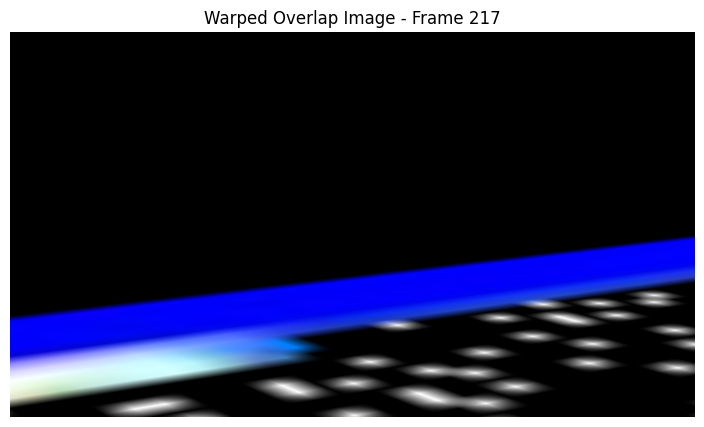

Iteration:  95%|█████████▍| 426/450 [01:17<00:04,  5.57it/s]

Normalized Homography matrix for frame 254:
[[ 5.7424847e-02  1.2108750e-02  1.3861360e+02]
 [ 4.0695727e-02  3.1973231e-01 -2.4243558e+02]
 [-5.3476670e-05  5.9766062e-03  1.0000000e+00]]


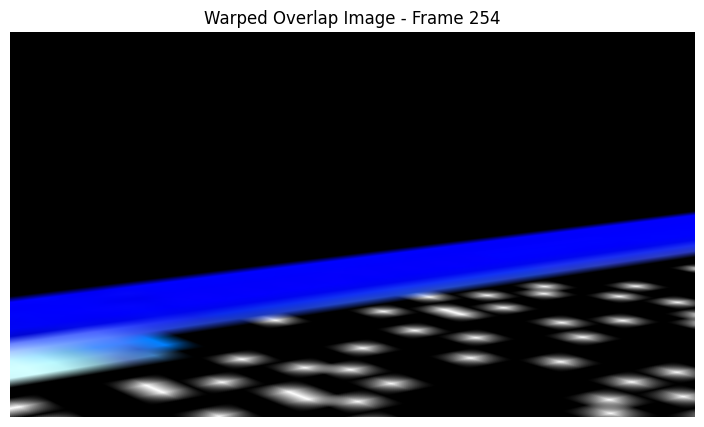

Iteration:  95%|█████████▍| 427/450 [01:17<00:04,  5.55it/s]

Normalized Homography matrix for frame 147:
[[ 1.7675029e-01  9.6926838e-02  5.7628765e+01]
 [ 6.3637093e-02  7.1968055e-01 -6.8298792e+02]
 [ 1.3950633e-04  1.6258197e-02  1.0000000e+00]]


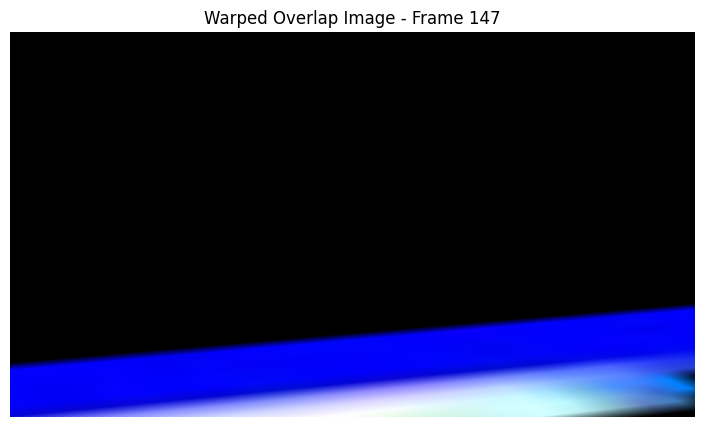

Iteration:  95%|█████████▌| 428/450 [01:17<00:03,  5.60it/s]

Normalized Homography matrix for frame 96:
[[ 8.9627594e-02  4.3569550e-02 -1.3509950e+01]
 [ 2.4338065e-02  3.4516749e-01 -3.0681958e+02]
 [ 1.4786745e-04  6.1007757e-03  1.0000000e+00]]


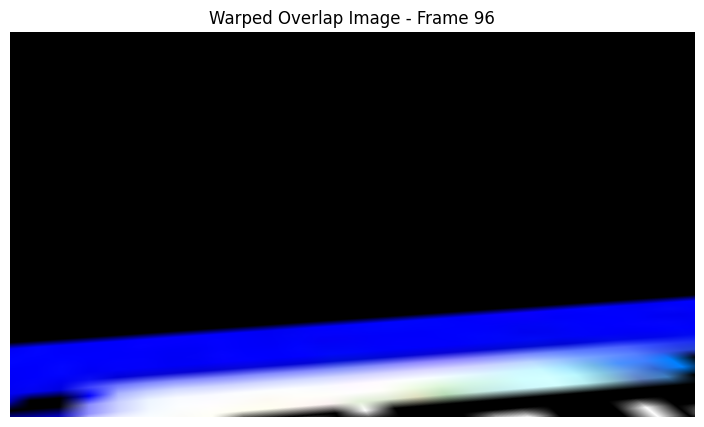

Iteration:  95%|█████████▌| 429/450 [01:17<00:03,  5.63it/s]

Normalized Homography matrix for frame 448:
[[ 4.2129219e-02  5.3883396e-04  8.3547470e+01]
 [ 2.8126303e-02  2.2841206e-01 -1.5086185e+02]
 [-2.6631207e-05  4.1967472e-03  1.0000000e+00]]


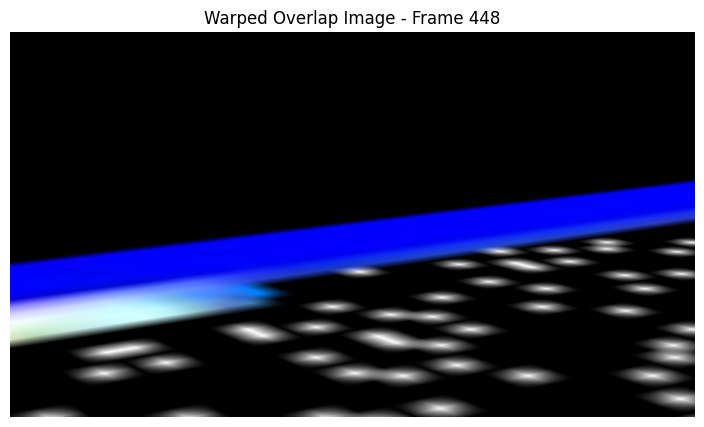

Iteration:  96%|█████████▌| 430/450 [01:17<00:03,  5.34it/s]

Normalized Homography matrix for frame 202:
[[ 9.7731948e-02  1.9925289e-02  1.5652382e+02]
 [ 5.5919010e-02  5.0278705e-01 -4.2152637e+02]
 [-4.4160926e-05  9.6174162e-03  1.0000000e+00]]


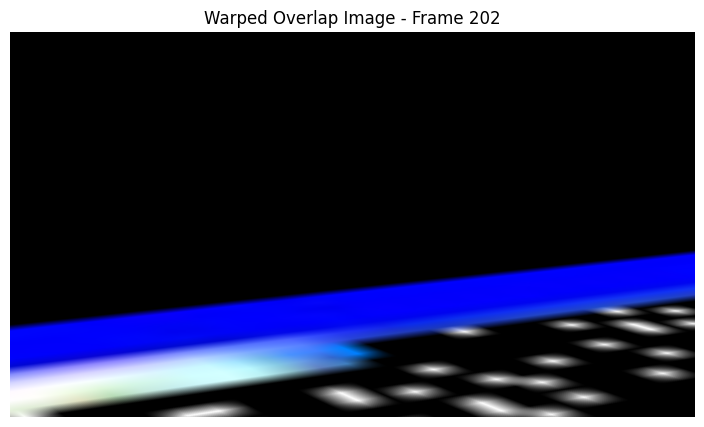

Iteration:  96%|█████████▌| 431/450 [01:18<00:03,  5.34it/s]

Normalized Homography matrix for frame 161:
[[ 6.9593161e-02 -3.2771148e-03  4.2800629e+01]
 [ 2.6570957e-02  2.8626943e-01 -2.6324051e+02]
 [ 1.4384025e-05  4.8097260e-03  1.0000000e+00]]


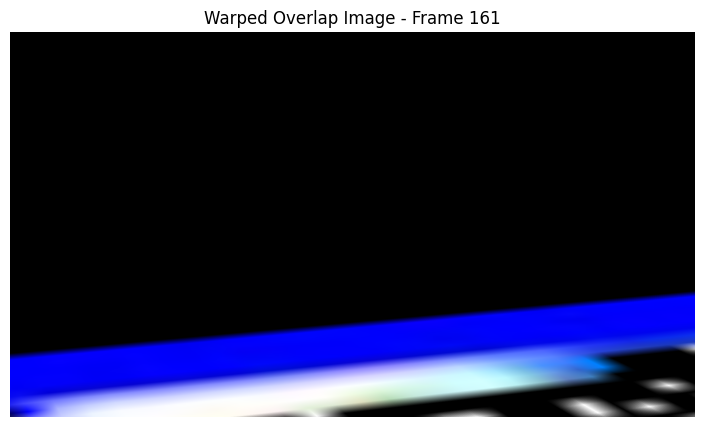

Iteration:  96%|█████████▌| 432/450 [01:18<00:03,  5.45it/s]

Normalized Homography matrix for frame 58:
[[ 1.2416429e-01 -6.8285870e-03 -9.1667089e+00]
 [ 2.8892029e-02  5.7231820e-01 -4.4321756e+02]
 [-1.3412382e-05  1.1417337e-02  1.0000000e+00]]


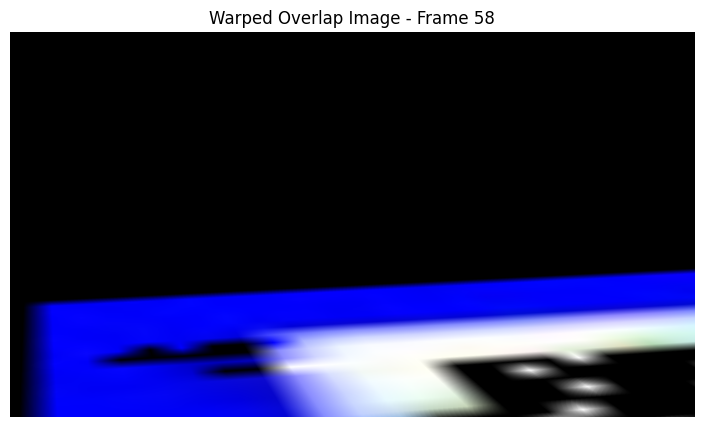

Iteration:  96%|█████████▌| 433/450 [01:18<00:03,  5.54it/s]

Normalized Homography matrix for frame 366:
[[ 4.6606928e-02  8.6615728e-03  8.4011185e+01]
 [ 2.9627811e-02  2.4918160e-01 -1.6589136e+02]
 [-3.1285163e-05  4.6267803e-03  1.0000000e+00]]


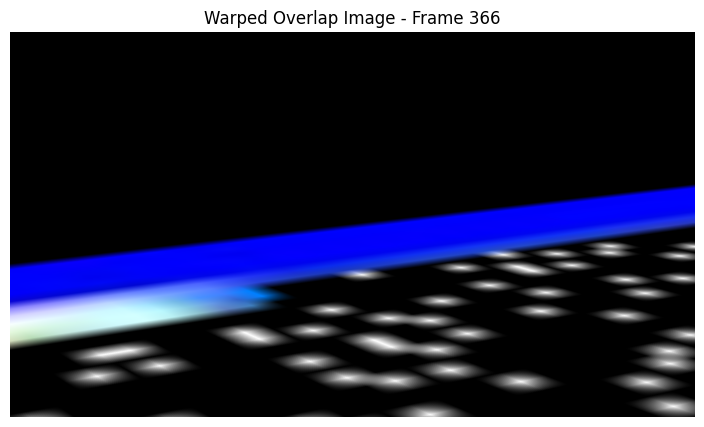

Iteration:  96%|█████████▋| 434/450 [01:18<00:02,  5.51it/s]

Normalized Homography matrix for frame 130:
[[ 8.77774954e-02  1.32190008e-02  5.03041954e+01]
 [ 2.99935285e-02  4.00994092e-01 -3.72262787e+02]
 [ 1.05692425e-05  7.76190264e-03  1.00000000e+00]]


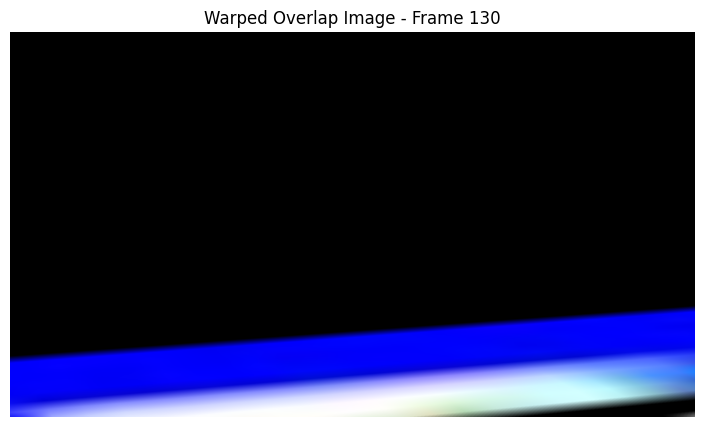

Iteration:  97%|█████████▋| 435/450 [01:18<00:02,  5.57it/s]

Normalized Homography matrix for frame 252:
[[ 5.4805715e-02  4.7613704e-03  1.3624850e+02]
 [ 3.8700409e-02  3.0597100e-01 -2.3355809e+02]
 [-5.6024386e-05  5.6230468e-03  1.0000000e+00]]


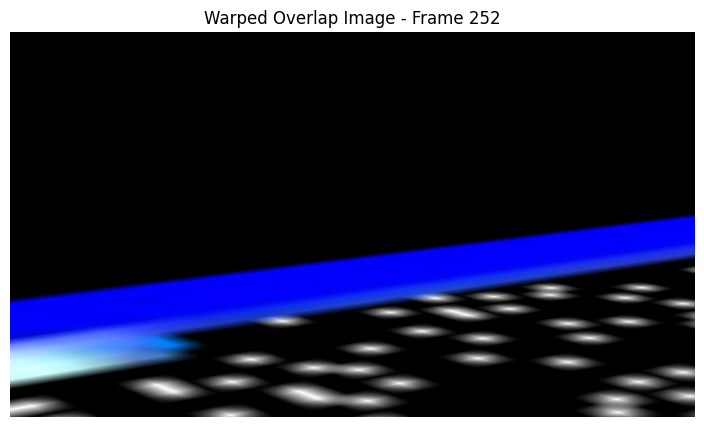

Iteration:  97%|█████████▋| 436/450 [01:19<00:02,  5.57it/s]

Normalized Homography matrix for frame 83:
[[ 1.0425228e-01  5.9291329e-02 -3.7529240e+01]
 [ 2.3730353e-02  3.9022031e-01 -3.3530402e+02]
 [ 1.7956186e-04  7.1221264e-03  1.0000000e+00]]


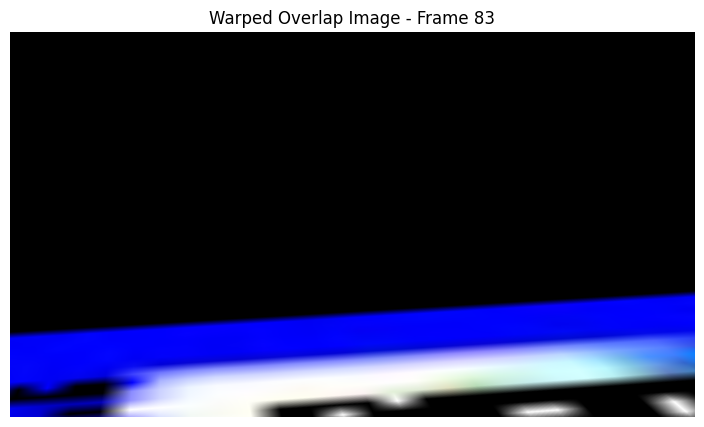

Iteration:  97%|█████████▋| 437/450 [01:19<00:02,  5.60it/s]

Normalized Homography matrix for frame 15:
[[ 3.5362044e-01 -7.2374437e-03 -2.2351311e+02]
 [ 3.4984864e-02  1.5535493e+00 -1.1222656e+03]
 [-2.0723657e-05  2.9455537e-02  1.0000000e+00]]


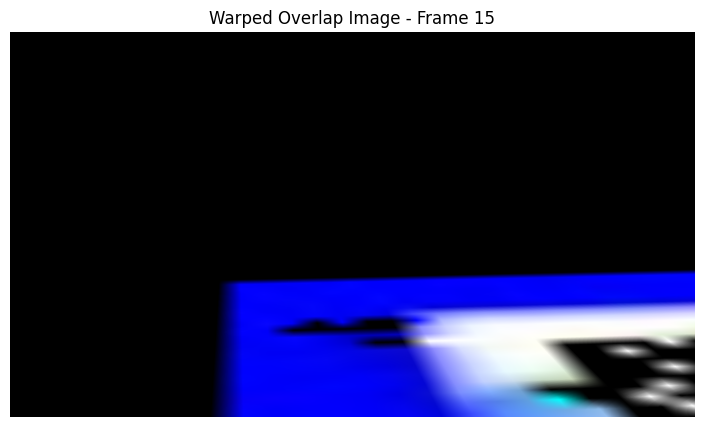

Iteration:  97%|█████████▋| 438/450 [01:19<00:02,  5.62it/s]

Normalized Homography matrix for frame 89:
[[ 9.3070649e-02  4.7110036e-02 -2.0866674e+01]
 [ 2.3547044e-02  3.5788292e-01 -3.1149542e+02]
 [ 1.4905049e-04  6.4830803e-03  1.0000000e+00]]


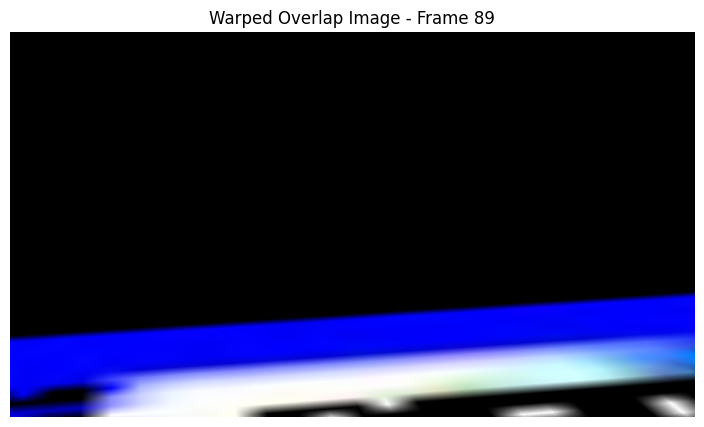

Iteration:  98%|█████████▊| 439/450 [01:19<00:01,  5.64it/s]

Normalized Homography matrix for frame 264:
[[ 4.8318781e-02  6.5598413e-03  1.3024968e+02]
 [ 3.6621634e-02  2.7546108e-01 -2.0410870e+02]
 [-3.7229453e-05  5.1738149e-03  1.0000000e+00]]


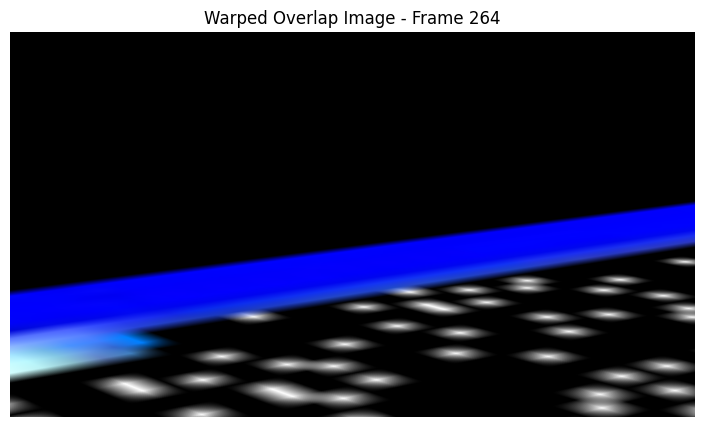

Iteration:  98%|█████████▊| 440/450 [01:19<00:01,  5.63it/s]

Normalized Homography matrix for frame 145:
[[ 1.12904802e-01  4.57565077e-02  5.28552818e+01]
 [ 3.94629911e-02  4.84532833e-01 -4.56229767e+02]
 [ 3.66810818e-05  1.02797365e-02  1.00000000e+00]]


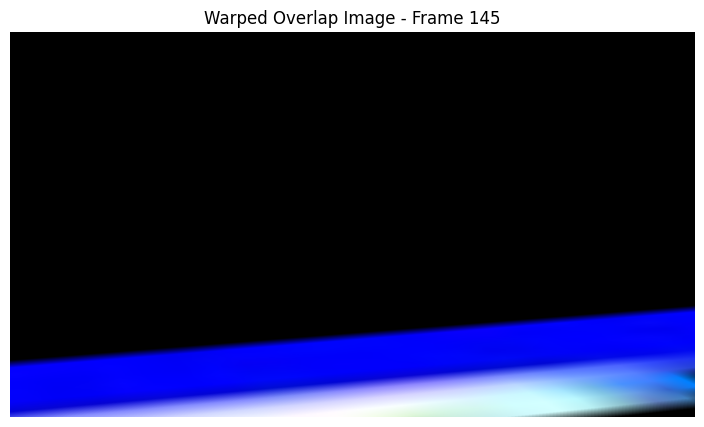

Iteration:  98%|█████████▊| 441/450 [01:19<00:01,  5.64it/s]

Normalized Homography matrix for frame 375:
[[ 4.4135552e-02  1.7293679e-03  8.5047272e+01]
 [ 2.9209603e-02  2.3601189e-01 -1.5851981e+02]
 [-2.7940096e-05  4.3711481e-03  1.0000000e+00]]


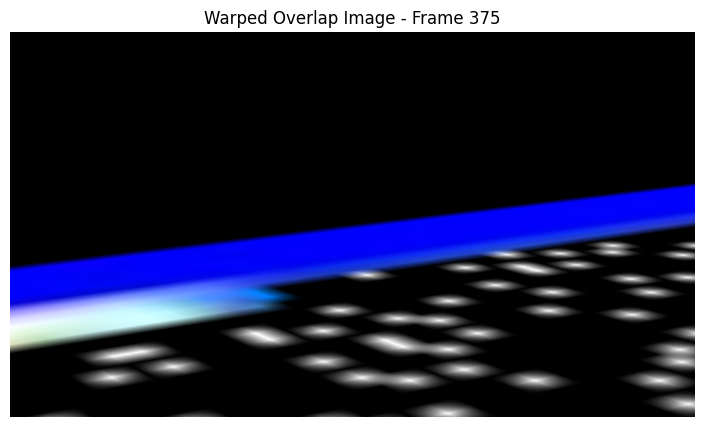

Iteration:  98%|█████████▊| 442/450 [01:20<00:01,  5.57it/s]

Normalized Homography matrix for frame 326:
[[ 4.9561810e-02  4.3869526e-03  8.4489159e+01]
 [ 3.0574715e-02  2.6326880e-01 -1.7816599e+02]
 [-3.2774740e-05  4.8316969e-03  1.0000000e+00]]


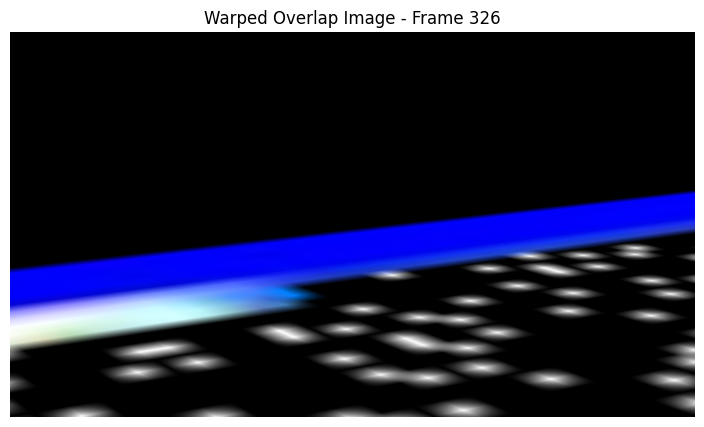

Iteration:  98%|█████████▊| 443/450 [01:20<00:01,  5.53it/s]

Normalized Homography matrix for frame 93:
[[ 1.0511649e-01  5.9366137e-02 -2.3782740e+01]
 [ 2.5656160e-02  3.9680830e-01 -3.4960529e+02]
 [ 1.4494643e-04  7.5356658e-03  1.0000000e+00]]


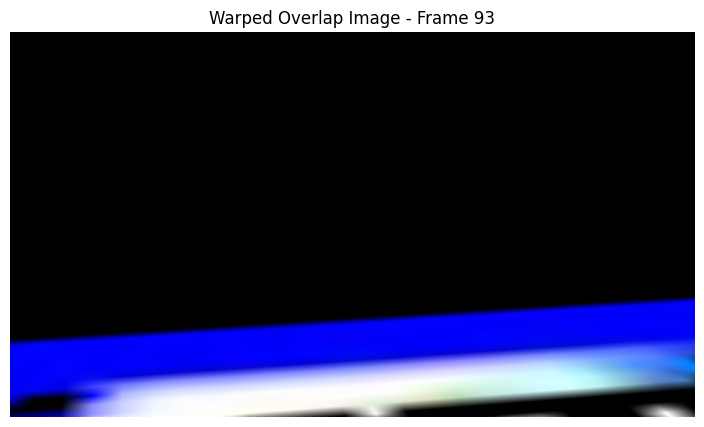

Iteration:  99%|█████████▊| 444/450 [01:20<00:01,  5.57it/s]

Normalized Homography matrix for frame 305:
[[ 4.2772733e-02 -8.3543704e-04  9.2023270e+01]
 [ 2.9225923e-02  2.3011319e-01 -1.6003522e+02]
 [-3.4236691e-05  4.2773350e-03  1.0000000e+00]]


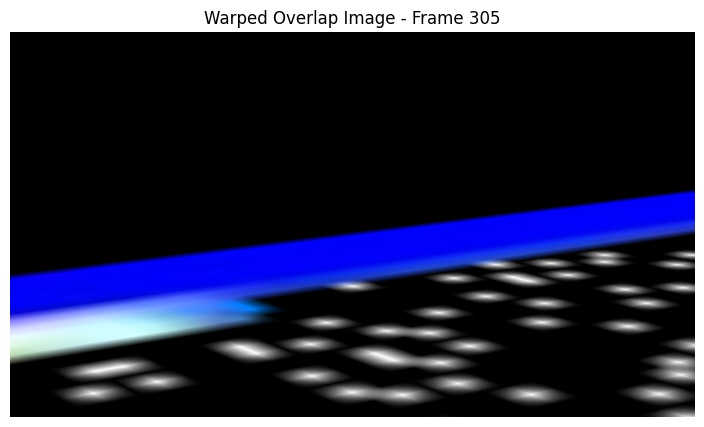

Iteration:  99%|█████████▉| 445/450 [01:20<00:00,  5.59it/s]

Normalized Homography matrix for frame 409:
[[ 4.4157367e-02  5.3857965e-03  8.2555069e+01]
 [ 2.8650457e-02  2.3531675e-01 -1.5670692e+02]
 [-2.6073450e-05  4.3231221e-03  1.0000000e+00]]


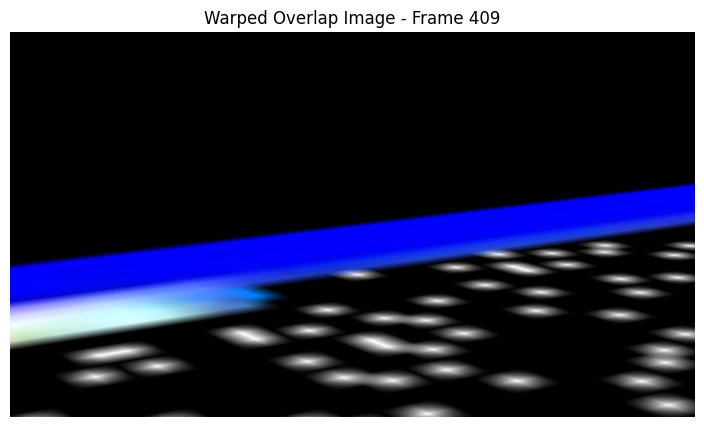

Iteration:  99%|█████████▉| 446/450 [01:20<00:00,  5.57it/s]

Normalized Homography matrix for frame 340:
[[ 4.9147092e-02  5.6671482e-03  8.5044037e+01]
 [ 3.0652342e-02  2.6213166e-01 -1.7648323e+02]
 [-3.1259584e-05  4.8208954e-03  1.0000000e+00]]


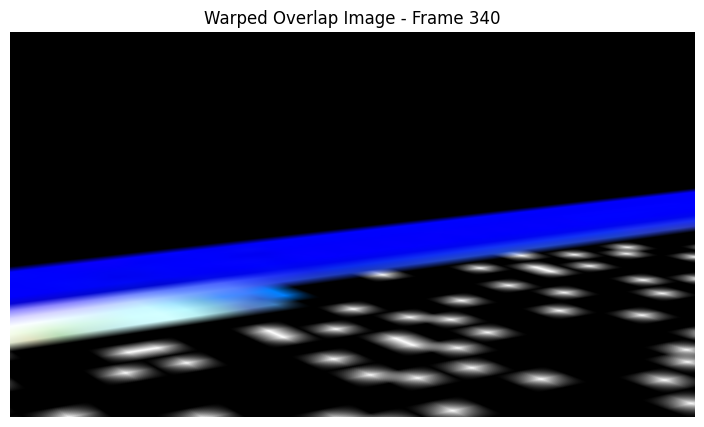

Iteration:  99%|█████████▉| 447/450 [01:21<00:00,  5.55it/s]

Normalized Homography matrix for frame 320:
[[ 5.2487664e-02  5.9459489e-03  8.8134613e+01]
 [ 3.3613168e-02  2.7390426e-01 -1.8762152e+02]
 [-2.2691082e-05  5.1332260e-03  1.0000000e+00]]


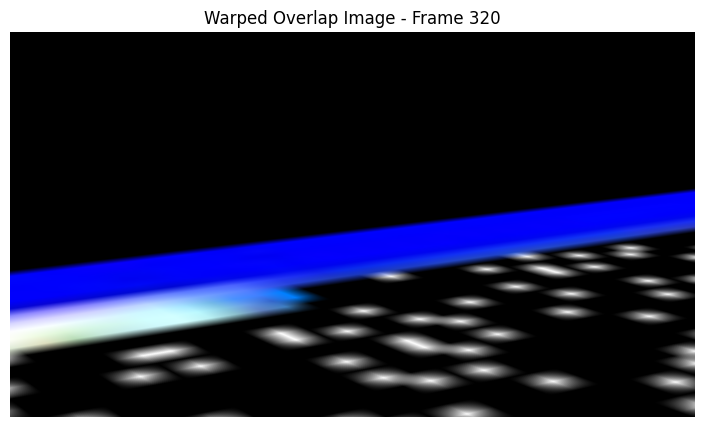

Iteration: 100%|█████████▉| 448/450 [01:21<00:00,  5.53it/s]

Normalized Homography matrix for frame 170:
[[ 7.2049022e-02  2.3520903e-03  6.0886341e+01]
 [ 2.9204259e-02  3.1482896e-01 -2.8541354e+02]
 [-1.1720500e-05  5.5882852e-03  1.0000000e+00]]


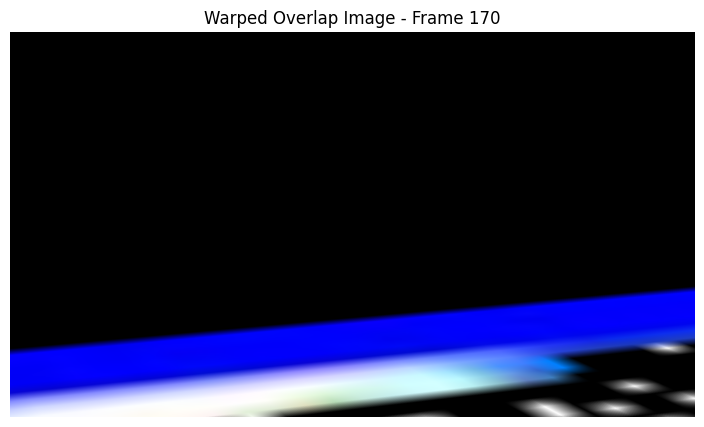

Iteration: 100%|█████████▉| 449/450 [01:21<00:00,  5.56it/s]

Normalized Homography matrix for frame 331:
[[ 4.8658311e-02  5.4902043e-03  8.2419891e+01]
 [ 2.9797401e-02  2.5803432e-01 -1.7430499e+02]
 [-2.9507817e-05  4.7121253e-03  1.0000000e+00]]


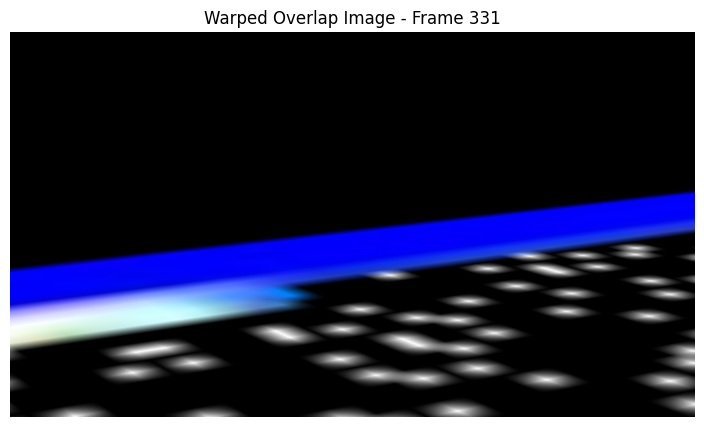

Iteration: 100%|██████████| 450/450 [01:21<00:00,  5.52it/s]


In [6]:
from tqdm import tqdm

overlap_img = cv2.imread('field.png')
if overlap_img is None:
    raise ValueError("Error: overlap_img is None. Check the image path.")
overlap_img = cv2.cvtColor(overlap_img, cv2.COLOR_BGR2RGB)

for index, sample in tqdm(df.iterrows(), total=df.shape[0], desc="Iteration"):
    image_id = Path(sample.image_id).stem
    if "checkpoint" in sample.image_id:
        continue

    # Cargar el frame del video
    image = Image.open(args.images_path / sample.image_id).convert("RGB")
    image = T.functional.to_tensor(image).permute(1, 2, 0).numpy() * 255
    image = image.astype(np.uint8)
    
    # Obtener puntos de las lineas
    cam = get_camera_from_per_sample_output(sample, args.lens_dist)
    points_line, points_circle = sample["points_line"], sample["points_circle"]

    if args.lens_dist:
        # Visualizar puntos anotados e imagen después de la corrección de distorsión
        image = cam.undistort_images(image.unsqueeze(0).unsqueeze(0)).squeeze()
        points_line = SNProjectiveCamera.static_undistort_points(points_line.unsqueeze(0).unsqueeze(0), cam).squeeze()
        points_circle = SNProjectiveCamera.static_undistort_points(points_circle.unsqueeze(0).unsqueeze(0), cam).squeeze()
    else:
        psi = None
        
    # Obtener y normalizar la matriz de homografía
    H = np.array(sample['homography'], dtype=np.float32)
    if H[-1, -1] != 0:
        H = H / H[-1, -1]
    print(f"Normalized Homography matrix for frame {image_id}:\n{H}")
    hinv = np.linalg.inv(H)
    
    
    h, w, _ = image.shape
    warped_overlap_img = cv2.warpPerspective(overlap_img, hinv, (w, h))

    # Verificar si warped_overlap_img es válida
    if warped_overlap_img is None or np.sum(warped_overlap_img) == 0:
        raise ValueError(f"Failed to warp overlap image for frame {image_id}")
        
    plt.figure(figsize=(10, 5))
    plt.imshow(warped_overlap_img)
    plt.title(f"Warped Overlap Image - Frame {image_id}")
    plt.axis('off')
    plt.show()

    combined_img = cv2.addWeighted(image, 0.7, warped_overlap_img, 0.3, 0)
    
    # Guardar la imagen resultante
    output_path = args.output_dir / f"output/frames/{image_id}.png"
    cv2.imwrite(str(output_path), cv2.cvtColor(combined_img, cv2.COLOR_RGB2BGR))

## La siguiente celda traza una línea diagonal, a partir de las coordenadas en metros de la cancha

In [ ]:
from tqdm import tqdm
from matplotlib.lines import Line2D


for index, sample in tqdm(df.iterrows(), total=df.shape[0], desc="Iteration"):
    image_id = Path(sample.image_id).stem
    if "checkpoint" in sample.image_id:
        continue
    image = Image.open(args.images_path / sample.image_id).convert("RGB")
    image = T.functional.to_tensor(image)

    cam = get_camera_from_per_sample_output(sample, args.lens_dist)
    points_line, points_circle = sample["points_line"], sample["points_circle"]

    if args.lens_dist:
        # we visualize annotated points and image after undistortion
        image = cam.undistort_images(image.unsqueeze(0).unsqueeze(0)).squeeze()
        # print(points_line.shape) # expected: (1, 1, 3, S, N)
        points_line = SNProjectiveCamera.static_undistort_points(points_line.unsqueeze(0).unsqueeze(0), cam).squeeze()
        points_circle = SNProjectiveCamera.static_undistort_points(points_circle.unsqueeze(0).unsqueeze(0), cam).squeeze()
    else:
        psi = None

    fig, ax = viz.init_figure(args.image_width, args.image_height)
    ax = viz.draw_image(ax, image)
    ax.set_xlim(0, image.shape[2])
    ax.set_ylim(image.shape[1], 0)
    ax.axis('off')
    ax = viz.draw_reprojection(ax, object3dcpu, cam)

    points_diagonal = [[[-52.5, 34, 0], [52.5, -34, 0]]]
    diagonal_line = torch.Tensor(points_diagonal)
    with torch.no_grad():
        points_px = cam.project_point2pixel(diagonal_line, lens_distortion=False).cpu()[0, 0]
        line2d = Line2D(
            points_px[:, 0],
            points_px[:, 1],
            color="red",
            alpha=0.5,
            linewidth=5,
        )
        ax.add_line(line2d)

    ax = viz.draw_selected_points(
        ax,
        object3dcpu,
        points_line,
        points_circle,
        kwargs_outer={
            "zorder": 1000,
            "rasterized": False,
            "s": 500,
            "alpha": 0.3,
            "facecolor": "none",
            "linewidths": 3,
        },
        kwargs_inner={
            "zorder": 1000,
            "rasterized": False,
            "s": 50,
            "marker": ".",
            "color": "k",
            "linewidths": 4.0,
        },
    )
    plt.savefig(args.output_dir / f"output/frames/{image_id}.png", dpi=100, bbox_inches='tight', pad_inches=0)
    plt.close(fig)

## La siguiente celda funciona bien pero no superpone nada.

In [ ]:
from tqdm import tqdm

for index, sample in tqdm(df.iterrows(), total=df.shape[0], desc="Iteration"):
    image_id = Path(sample.image_id).stem
    if "checkpoint" in sample.image_id:
        continue
    image = Image.open(args.images_path / sample.image_id).convert("RGB")
    image = T.functional.to_tensor(image)

    cam = get_camera_from_per_sample_output(sample, args.lens_dist)
    points_line, points_circle = sample["points_line"], sample["points_circle"]

    if args.lens_dist:
        # we visualize annotated points and image after undistortion
        image = cam.undistort_images(image.unsqueeze(0).unsqueeze(0)).squeeze()
        # print(points_line.shape) # expected: (1, 1, 3, S, N)
        points_line = SNProjectiveCamera.static_undistort_points(points_line.unsqueeze(0).unsqueeze(0), cam).squeeze()
        points_circle = SNProjectiveCamera.static_undistort_points(points_circle.unsqueeze(0).unsqueeze(0), cam).squeeze()
    else:
        psi = None
        
    fig, ax = viz.init_figure(args.image_width, args.image_height)
    ax = viz.draw_image(ax, image)
    ax.set_xlim(0, image.shape[2])
    ax.set_ylim(image.shape[1], 0)
    ax.axis('off')
    ax = viz.draw_reprojection(ax, object3dcpu, cam)
    ax = viz.draw_selected_points(
        ax,
        object3dcpu,
        points_line,
        points_circle,
        kwargs_outer={
            "zorder": 1000,
            "rasterized": False,
            "s": 500,
            "alpha": 0.3,
            "facecolor": "none",
            "linewidths": 3,
        },
        kwargs_inner={
            "zorder": 1000,
            "rasterized": False,
            "s": 50,
            "marker": ".",
            "color": "k",
            "linewidths": 4.0,
        },
    )
    plt.savefig(args.output_dir / f"output/frames/{image_id}.png", dpi=100, bbox_inches='tight', pad_inches=0)
    plt.close(fig)

In [ ]:
!ffmpeg -r 25 -i tmp/output/frames/%d.png -vcodec mpeg4 -y -vb 40M -loglevel quiet tmp/output/masks_video.mp4